# 💼 **Job Market Analysis and Recommendation System**

### *Upwork Job Postings — Trends, Pay, Emerging Categories, Forecasts and a Job Recommender*

---

**Author**  : Yousuf S. R. Sakkaf

**Status**  : Completed

**Dataset** : all_upwork_jobs.csv

**File**    : job_market_analysis.ipynb

**Project** : NHIS_Project8

**Date**    : 23rd November 2026

---

## 📌 Introduction

<div style="margin-left: 20px; max-width: 90%">

Freelance marketplaces publish thousands of job postings every day, but a posting only becomes useful when it can be compared — by pay, by country, by type of work and over time. This project analyses Upwork job postings to understand what clients are asking for and offering, and turns the same data into a job recommendation prototype.

</div>

## ❓ Problem Statement

<div style="margin-left: 20px; max-width: 90%">

Job seekers cannot easily see which roles are in demand, how pay varies by keyword and client country, or which categories are growing. Posting titles are free text, pay is stated in two different ways (hourly rate or salary), and a posting may state no rate at all — so raw averages and simple counts are misleading without careful cleaning.

</div>

## 🎯 Objectives

<div style="margin-left: 20px; max-width: 90%">

- Load and clean the raw postings, handling blanks, missing countries, outliers and duplicate postings explicitly.
- Explore the market through univariate, bivariate and multivariate analysis.
- Measure how title keywords relate to offered pay, and identify emerging job categories from posting frequency.
- Forecast high-demand roles and remote-work trends, with prediction intervals and future scenarios.
- Compare average hourly rates across client countries on an interactive map.
- Build a content-based job recommendation engine with a country filter, and a Streamlit dashboard for market tracking.

</div>

## ⚠️ Scope Notes

<div style="margin-left: 20px; max-width: 90%">

- All pay figures are assumed to be in "Units" (the data has no currency field) and are never converted.
- `country` is the client's country, not the freelancer's location.
- Posting counts are a proxy for demand: the data has no applicant or hiring information.
- Hourly rates and salaries are analysed separately, never pooled.
- For Permanent postings the budget column holds the salary; the data does not state a pay period.

</div>

---

### 📌 Environment Setup

<div style="margin-left: 20px; max-width: 90%">

Installing the few packages Colab does not ship, fetching the shared `prerequisites.py` from the repository, then importing libraries and initialising logging and visualization defaults.

</div>

In [1]:
!pip install -q -U lightgbm

In [2]:
import importlib.metadata as md

_required = {"pycountry": "24.6.1"}

def _already_installed():
    for pkg, ver in _required.items():
        try:
            if md.version(pkg) != ver:
                return False
        except md.PackageNotFoundError:
            return False
    return True

if _already_installed():
    print("✅ Already installed — skipping.")
else:
    !pip install -q pycountry==24.6.1 2>/dev/null

In [3]:
import os
import urllib.request

PREREQUISITES_GITHUB_URL = "https://raw.githubusercontent.com/S-Yousuf-S/NHIS_Project8/main/prerequisites.py"

# Set True to re-download after prerequisites.py changes on GitHub (a stale session copy is otherwise reused)
REFRESH_PREREQUISITES = False

if REFRESH_PREREQUISITES or not os.path.exists("prerequisites.py"):
    print("🌐 Downloading prerequisites.py from GitHub...")
    urllib.request.urlretrieve(PREREQUISITES_GITHUB_URL, "prerequisites.py")
    print("💾 prerequisites.py downloaded and saved for this session.")
else:
    print("✅ prerequisites.py found locally.")

🌐 Downloading prerequisites.py from GitHub...
💾 prerequisites.py downloaded and saved for this session.


In [4]:
# === Shared utilities (logging, HTML boxes, loader, artifacts, diagnostics) ===
from prerequisites import *

# === Logging ===
logger = setup_logging(log_dir="logs")

# === Visualization defaults ===
set_global_visualization_settings()

# === Text cleaning ===
import re
import html
import warnings

# === Statistics (Task 1: keywords vs pay, significance tests) ===
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint
from statsmodels.tsa.holtwinters import ExponentialSmoothing                  # Tasks 3, 7: Holt-Winters seasonal forecasting
from statsmodels.tsa.statespace.sarimax import SARIMAX                        # Tasks 3, 7: seasonal ARIMA forecasting

# === Machine learning ===
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS      # Tasks 1, 2, 5: title words, TF-IDF, filler-word removal
from sklearn.decomposition import TruncatedSVD                                                        # Task 2: compress TF-IDF before K-Means
from sklearn.cluster import KMeans                                                                    # Task 2: emerging category themes
from sklearn.linear_model import LinearRegression, LogisticRegression                                 # Task 7 forecasting candidate; Task 2 job category model
from sklearn.ensemble import RandomForestRegressor                                                    # Tasks 1, 7: pay and demand regressors
from sklearn.metrics import silhouette_score, r2_score, adjusted_rand_score                           # Task 2 cluster quality; Tasks 3, 7 forecast accuracy
from sklearn.model_selection import train_test_split, cross_val_score                                 # Task 1: hold-out and cross-validation
from sklearn.inspection import permutation_importance                                                 # Tasks 1, 3, 7: feature importance
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, Normalizer
from lightgbm import LGBMRegressor

# === Interactive charts (Tasks 4, 6, 8) ===
import plotly.express as px
import pycountry                                                                # Task 4: country names to map codes
from itertools import combinations

# === Neural Network ===
from tensorflow import keras                                                    # Tasks 3, 7: small GRU network for the forecasting comparison

logger.info("Environment initialized — libraries imported, logging and visualization defaults set")
success_box("Environment ready — libraries imported, logging active, visualization defaults applied.")

2026-11-23 16:46:04,483 - job_market_analysis - INFO - Logging initialized -> logs/YS_job_market_analysis_2026-11-23.log
2026-11-23 16:46:21,391 - job_market_analysis - INFO - Environment initialized — libraries imported, logging and visualization defaults set


### 📌 Cascade Setup — Local / Drive / GitHub

<div style="margin-left: 20px; max-width: 90%">

Creating the local `Assets` folder, mounting Google Drive and verifying the exact Drive path before any data loading. The raw CSV is loaded through the Local → Drive → GitHub cascade, and the small processed tables and model artifacts created later follow the same route.

</div>

In [5]:
# === Persistent Storage Configuration ===

os.makedirs(LOCAL_ASSETS_DIR, exist_ok=True)

DRIVE_ROOT = "/content/drive/MyDrive"
DRIVE_PATH = None

try:
    from google.colab import drive
    drive.mount("/content/drive")

    if os.path.isdir(DRIVE_ROOT):
        if os.path.isdir(DRIVE_ASSETS_DIR):
            DRIVE_PATH = DRIVE_ASSETS_DIR
            success_box(f"Google Drive mounted successfully. Project Assets path verified: {DRIVE_PATH}")
            logger.info(f"Google Drive mounted and project path verified: {DRIVE_PATH}")
        else:
            warning_box("Google Drive mounted successfully, but the expected Project 8 Assets folder was not found.<br>Drive fallback will remain disabled until the path is verified.")
            logger.warning(f"Drive mounted, but project path was not found: {DRIVE_ASSETS_DIR}")
    else:
        warning_box("Google Drive mount was reported, but the mounted filesystem could not be verified.<br>Drive fallback is disabled.")
        logger.warning("Drive mount reported success, but /content/drive/MyDrive could not be verified.")

except ImportError:
    info_box("Not running in Google Colab. Google Drive fallback is disabled.")
    logger.info("Google Colab unavailable — Drive fallback disabled.")

except Exception as e:
    warning_box(f"Google Drive mount failed ({e}). Drive fallback is disabled for this session.")
    logger.warning(f"Google Drive mount failed: {e}")

if DRIVE_PATH:
    success_box(f"Persistent storage ready — Local: {LOCAL_ASSETS_DIR}/ | Drive: {DRIVE_PATH} | GitHub: {GITHUB_RAW_BASE}")
else:
    warning_box(f"Persistent storage partially ready — Local: {LOCAL_ASSETS_DIR}/ | GitHub: {GITHUB_RAW_BASE} (Drive unavailable)")
logger.info(f"Cascade configured — Drive available: {DRIVE_PATH is not None}")

2026-11-23 16:46:34,369 - job_market_analysis - WARNING - Google Drive mount failed: Error: credential propagation was unsuccessful


2026-11-23 16:46:34,391 - job_market_analysis - INFO - Cascade configured — Drive available: False


## 01. Importing & Inspecting the Data

<div style="margin-left: 20px; max-width: 90%">

Loading the raw Upwork file through the Local → Drive → GitHub cascade with a line-based parser (the file contains stray quotes that break a standard CSV reader), then a first structural look — load report, shape, data types, missing pay fields by contract type and date coverage — before any cleaning begins.

</div>

### 📌 Robust Load & Load Report

<div style="margin-left: 20px; max-width: 90%">

The raw file is read line by line: each posting is anchored on the link that follows its title (or on an empty link field), so titles with stray quotes or line breaks stay intact. The report below shows how many lines were read, how many records were parsed, and whether anything could not be parsed or converted.

</div>

In [6]:
section_header("Importing and Inspecting the Data")

df_raw, load_report = load_upwork_jobs(
    local_dir=LOCAL_ASSETS_DIR,
    drive_path=DRIVE_PATH,
    dataset_name="upwork_jobs",
)

subsection_header("Load Report — Robust Line-Based Parser")
show_load_report(load_report)
logger.info(f"Raw data loaded — source={load_report['source']}, records={load_report['records_parsed']}, row check={load_report['row_check']}")

2026-11-23 16:46:34,420 - job_market_analysis - INFO - [upwork_jobs] Falling back to GitHub: https://raw.githubusercontent.com/S-Yousuf-S/NHIS_Project8/main/Assets/all_upwork_jobs.csv
2026-11-23 16:46:35,922 - job_market_analysis - DEBUG - [upwork_jobs] Cached local copy: Assets/all_upwork_jobs.csv
2026-11-23 16:46:39,725 - job_market_analysis - INFO - [upwork_jobs] Independent record count: 244828
2026-11-23 16:46:39,750 - job_market_analysis - DEBUG - [upwork_jobs] Line 936: title continues (no link anchor)
2026-11-23 16:46:39,768 - job_market_analysis - DEBUG - [upwork_jobs] Line 1506: title continues (no link anchor)
2026-11-23 16:46:39,777 - job_market_analysis - DEBUG - [upwork_jobs] Line 1594: title continues (no link anchor)
2026-11-23 16:46:39,793 - job_market_analysis - DEBUG - [upwork_jobs] Line 3285: title continues (no link anchor)
2026-11-23 16:46:39,801 - job_market_analysis - DEBUG - [upwork_jobs] Line 4132: title continues (no link anchor)
2026-11-23 16:46:39,802 - job

check,result
Data lines read,"245,161"
Records parsed,"244,828"
Titles joined across lines,283
Bad lines,0
Leftover fragments,0
Titles with replacement character,32
Unmapped is_hourly values,0
Numeric coercion failures,"hourly_low: 0, hourly_high: 0, budget: 0"
Record count check,"match (parsed 244,828 vs 244,828 records counted in the file)"


2026-11-23 16:46:44,390 - job_market_analysis - INFO - Raw data loaded — source=github, records=244828, row check=match


### 📌 Raw Dataset — Structural Overview

<div style="margin-left: 20px; max-width: 90%">

First look at the parsed data: its shape and the first ten sample rows

</div>

In [7]:
subsection_header("Raw Dataset — Structural Overview")
info_box(f"Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
preview = df_raw.head(10).copy()
preview["link"] = preview["link"].str.slice(0, 38) + "…"
centered_table(preview)
logger.debug(f"Preview built for first {len(preview)} rows")

title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
Experienced Media Buyer For Solar Pannel and Roofing installation companies.,https://www.upwork.com/jobs/Experience…,2024-02-17 09:09:54+00:00,False,NaN,NaN,500.0000,
Full Stack Developer,https://www.upwork.com/jobs/Full-Stack…,2024-02-17 09:09:17+00:00,False,NaN,NaN,1100.0000,United States
SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubbl…,2024-02-17 09:08:46+00:00,True,10.0000,30.0000,NaN,United States
Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hun…,2024-02-17 09:08:08+00:00,True,NaN,NaN,NaN,United States
Data Engineer,https://www.upwork.com/jobs/Data-Engin…,2024-02-17 09:07:42+00:00,False,NaN,NaN,650.0000,India
SEO for Portuguese Psychologist site,https://www.upwork.com/jobs/SEO-for-Po…,2024-02-17 09:07:41+00:00,True,NaN,NaN,NaN,Portugal
Want to fix the WordPress Plugin,https://www.upwork.com/jobs/Want-fix-t…,2024-02-17 09:07:27+00:00,False,NaN,NaN,5.0000,India
need Portuguese writers who can understand and write Portuguese..,https://www.upwork.com/jobs/need-Portu…,2024-02-17 09:07:05+00:00,True,7.0000,22.0000,NaN,India
"Looker Studio Dashboard for Leadgen and E-Commerce with Tool ""Reporting Ninja""",https://www.upwork.com/jobs/Looker-Stu…,2024-02-17 09:06:24+00:00,True,NaN,NaN,NaN,Germany
PHP/HTML/CSS WordPress Developer Needed for Website Transformation,https://www.upwork.com/jobs/PHP-HTML-C…,2024-02-17 09:06:21+00:00,False,NaN,NaN,500.0000,Canada


2026-11-23 16:46:44,441 - job_market_analysis - DEBUG - Preview built for first 10 rows


### 📌 Data Types & Missing Overview

<div style="margin-left: 20px; max-width: 90%">

The data type of every column, with how many values are missing and what share of the rows that is.

</div>

In [8]:
subsection_header("Data Types & Missing Overview")

structure_summary = pd.DataFrame({
    "Data Type": df_raw.dtypes.astype(str),
    "Missing Count": df_raw.isnull().sum(),
    "Missing %": (df_raw.isnull().mean() * 100).round(2)}).rename_axis("Column").reset_index()
centered_table(structure_summary, float_format="{:.2f}")
logger.debug(f"Missing counts computed: {structure_summary.set_index('Column')['Missing Count'].to_dict()}")

Column,Data Type,Missing Count,Missing %
title,object,0,0.00
link,object,0,0.00
published_date,object,0,0.00
is_hourly,bool,0,0.00
hourly_low,float64,142406,58.17
hourly_high,float64,146053,59.66
budget,float64,140937,57.57
country,object,5077,2.07


2026-11-23 16:46:44,749 - job_market_analysis - DEBUG - Missing counts computed: {'title': 0, 'link': 0, 'published_date': 0, 'is_hourly': 0, 'hourly_low': 142406, 'hourly_high': 146053, 'budget': 140937, 'country': 5077}


### 📌 Missing Pay Fields by Contract Type

<div style="margin-left: 20px; max-width: 90%">

For each contract type, the share of postings missing each pay field. Hourly postings are expected to carry no fixed salary, and salaried postings no hourly rate; this table shows whether the blanks follow that pattern or hide genuinely missing values.

</div>

In [9]:
subsection_header("Missing Pay Fields by Contract Type")

contract_label = df_raw["is_hourly"].map({True: "Hourly", False: "Salaried"})
missing_pay = (
    df_raw[["hourly_low", "hourly_high", "budget"]].isnull()
    .groupby(contract_label).mean().mul(100).round(2)
    .rename(columns={"hourly_low": "Hourly Low Missing %", "hourly_high": "Hourly High Missing %", "budget": "Salary Missing %"})
    .join(contract_label.value_counts().rename("Postings"))
    .rename_axis("Contract Type").reset_index()
    [["Contract Type", "Postings", "Hourly Low Missing %", "Hourly High Missing %", "Salary Missing %"]])
centered_table(missing_pay, float_format="{:.2f}")
logger.info("Missing pay fields by contract type computed")

Contract Type,Postings,Hourly Low Missing %,Hourly High Missing %,Salary Missing %
Hourly,140937,27.33,29.92,100.00
Salaried,103891,100.00,100.00,0.00


2026-11-23 16:46:44,926 - job_market_analysis - INFO - Missing pay fields by contract type computed


### 📌 Date Coverage Preview

<div style="margin-left: 20px; max-width: 90%">

Before cleaning, a quick look at when the postings were published. Timestamps are parsed on a temporary series (the data itself is untouched), counted per week, and the first week that carries real volume is identified from the counts rather than assumed.

</div>

In [10]:
subsection_header("Date Coverage Preview")

published_utc = pd.to_datetime(df_raw["published_date"], utc=True, errors="coerce")
parse_failures = int(published_utc.isna().sum())
info_box(
    f"Parsed {published_utc.notna().sum():,} timestamps ({parse_failures:,} failures). "
    f"Earliest: {published_utc.min():%d %b %Y %H:%M} UTC | Latest: {published_utc.max():%d %b %Y %H:%M} UTC")

week_start = published_utc.dt.tz_localize(None).dt.to_period("W").dt.start_time
weekly_counts = week_start.value_counts().sort_index().rename_axis("week_start").reset_index(name="postings")
weekly_counts["share_pct"] = (weekly_counts["postings"] / weekly_counts["postings"].sum() * 100).round(2)
weekly_counts["cumulative_pct"] = (weekly_counts["postings"].cumsum() / weekly_counts["postings"].sum() * 100).round(2)

# A week is 'core' if it holds at least this share of the busiest week's postings
CORE_WEEK_THRESHOLD = 0.10
core_weeks = weekly_counts.loc[weekly_counts["postings"] >= CORE_WEEK_THRESHOLD * weekly_counts["postings"].max(), "week_start"]
core_start = core_weeks.min()
share_core = (published_utc.dt.tz_localize(None) >= core_start).mean() * 100

weekly_display = weekly_counts.copy()
weekly_display["week_start"] = weekly_display["week_start"].dt.strftime("%Y-%m-%d")
weekly_display = weekly_display.rename(columns={"week_start": "Week Starting", "postings": "Postings", "share_pct": "Share of Total (%)", "cumulative_pct": "Cumulative Share (%)"})
centered_table(weekly_display, float_format="{:.2f}")

info_box(
    f"{share_core:.2f}% of postings fall on or after {core_start:%d %b %Y} ({len(core_weeks)} weeks with real volume). "
    f"Earlier rows are flagged as backdated in feature engineering.")
logger.info(f"Date coverage previewed — core window starts {core_start:%Y-%m-%d}, {share_core:.2f}% of rows inside it")

Week Starting,Postings,Share of Total (%),Cumulative Share (%)
2023-10-30,1,0.00,0.00
2023-11-27,1,0.00,0.00
2023-12-04,1,0.00,0.00
2023-12-11,3,0.00,0.00
2023-12-18,2,0.00,0.00
2023-12-25,3,0.00,0.00
2024-01-01,7,0.00,0.01
2024-01-08,8,0.00,0.01
2024-01-15,18,0.01,0.02
2024-01-22,31,0.01,0.03


2026-11-23 16:46:45,679 - job_market_analysis - INFO - Date coverage previewed — core window starts 2024-02-12, 99.90% of rows inside it


<div style="margin-left: 40px; max-width: 90%">

### **📊 Executive Summary — Importing & Inspecting the Data:**

- **Load quality:** The parser read 245,161 data lines and rebuilt 244,828 postings. 283 titles had been split across several lines and were joined back together. There were no bad lines, no leftover fragments, no unmapped `is_hourly` values and no numeric conversion failures, and the parsed count equals the independent count of records in the file (244,828). 32 titles contain the Unicode replacement character, meaning some characters could not be decoded. They are kept and repaired in the title repair step.
- **Structure:** `title`, `link`, `published_date` and `is_hourly` show no missing values. Blank titles or links are stored as empty text rather than as missing, so cleaning tests for them separately. `published_date` is still text and is converted to timestamps in cleaning.
- **Country:** 5,077 postings (2.07%) have no country. They are kept and labelled Others, so no postings are lost.
- **Pay blanks are structural:** All 103,891 salaried postings have no hourly rate (100% missing for both `hourly_low` and `hourly_high`) and always carry a fixed salary (0% missing). All 140,937 hourly postings have no fixed salary (100% missing). The large missing shares in the three pay columns (57.57% to 59.66%) therefore mostly reflect which contract type a posting uses, not data errors. These blanks are filled with 0 in cleaning, and the zeros are excluded from every average.
- **Genuinely missing rates:** Among hourly postings, 27.33% state no lower rate and 29.92% no upper rate. The upper bound is blank more often, so some hourly postings give a starting rate but no ceiling. These hourly rates are filled in cleaning with the median rate of the posting’s country, and the flags `rate_not_disclosed` and `open_ended_rate` keep a record of which values were filled.
- **Time window:** All 244,828 timestamps parsed, from 02 Nov 2023 to 24 Mar 2024 (UTC), but posting volume is concentrated. Every week up to the week starting 05 Feb 2024 holds at most 109 postings (0.10% together). Then 28,367 postings appear in the week starting 12 Feb, and between 40,294 and 45,544 in each of the five weeks after it. So 99.90% of postings fall in the six weeks from 12 Feb 2024, and the earlier ones are flagged as backdated in feature engineering. The first high-volume week is lower than the five that follow, so it may be only partly covered. Daily counts will confirm this.
- **Consequence:** With six weeks of history, trends are read at a daily and weekly grain, and forecast horizons stay short.

</div>

<hr style="width:45%; margin:auto;">

In [11]:
display(HTML(f"""
<div style="text-align:center;margin-top:40px;margin-bottom:30px;">
    <h3 style="color:{SUCCESS_TEXT};"><b>✅ Checkpoint: Importing & Inspecting Complete</b></h3>
    <p style="font-style:italic;font-size:1.05em;opacity:0.85;">
        The raw file is loaded and inspected — <b>{df_raw.shape[0]:,} postings</b> across <b>{df_raw.shape[1]} columns</b>,
        with the date window and the structure of the pay blanks identified.<br>
        Data Cleaning ahead: dates, worker type, missing values, validity checks, country and title repair.
    </p>
    <hr style="width:45%;">
</div>"""))

## 02. Data Cleaning

<div style="margin-left: 20px; max-width: 90%">

Turning the raw frame into a trustworthy working table: dates parsed and ordered, worker type added, missing values audited and treated, invalid postings and postings without a country removed, and titles cleaned. The raw frame `df_raw` is never modified. All work happens on a copy, `df_refined`, and changes to existing columns are built in new columns next to the originals and applied at the end of this section.

</div>

### 📌 Date Parsing & Chronological Order

<div style="margin-left: 20px; max-width: 90%">

Timestamps are converted from text to proper UTC datetimes and the table is sorted chronologically.

</div>

In [12]:
section_header("Data Cleaning")
subsection_header("Date Parsing & Chronological Order")

df_refined = df_raw.copy()
cleaning_log = []          # one entry for every step that removes rows

df_refined["published_at"] = pd.to_datetime(df_refined["published_date"], utc=True, errors="coerce")
df_refined = df_refined.sort_values("published_at")        # original row labels are kept so rows can be traced back to df_raw

unparsed_dates = int(df_refined["published_at"].isna().sum())
first_ts, last_ts = df_refined["published_at"].min(), df_refined["published_at"].max()

info_box(
    f"Parsed {df_refined['published_at'].notna().sum():,} of {len(df_refined):,} timestamps ({unparsed_dates:,} failures). "
    f"Sorted chronologically from {first_ts:%d %b %Y} to {last_ts:%d %b %Y}.")
logger.info(f"Dates parsed — failures={unparsed_dates}, range={first_ts:%Y-%m-%d} to {last_ts:%Y-%m-%d}")

2026-11-23 16:46:46,621 - job_market_analysis - INFO - Dates parsed — failures=0, range=2023-11-02 to 2024-03-24


### 📌 Worker Type

<div style="margin-left: 20px; max-width: 90%">

The contract flag is translated into a worker type: hourly postings are Freelancer and salaried postings are Permanent.

</div>

In [13]:
subsection_header("Worker Type")

WORKER_LABELS = {True: "Freelancer", False: "Permanent"}   # hourly postings / fixed-price postings; rename here only

df_refined["worker_type"] = df_refined["is_hourly"].map(WORKER_LABELS)
unmapped_workers = int(df_refined["worker_type"].isna().sum())

worker_summary = df_refined["worker_type"].value_counts().rename_axis("Worker Type").reset_index(name="Postings")
worker_summary["Share (%)"] = (worker_summary["Postings"] / len(df_refined) * 100).round(2)
centered_table(worker_summary, float_format="{:.2f}")

if unmapped_workers:
    warning_box(f"{unmapped_workers:,} postings have an unrecognised contract type and no worker_type.")
else:
    success_box(f"worker_type added: hourly postings are {WORKER_LABELS[True]}, salaried postings are {WORKER_LABELS[False]}.")
logger.info(f"worker_type created — unmapped={unmapped_workers}")

Worker Type,Postings,Share (%)
Freelancer,140937,57.57
Permanent,103891,42.43


2026-11-23 16:46:46,712 - job_market_analysis - INFO - worker_type created — unmapped=0


### 📌 Missing Value Audit & Strategy

<div style="margin-left: 20px; max-width: 90%">

Every column with missing values is listed with how many of those gaps are structural (the contract type does not use that field) and how many are undisclosed (the client left it blank). Blank countries are labelled Others, and hourly rates the client did not state are filled with the median rate of their country.

</div>

In [14]:
subsection_header("Missing Value Audit & Strategy")

PAY_COLUMNS = {"hourly_low": True, "hourly_high": True, "budget": False}   # pay column -> is_hourly value of the contract type that uses it

audit = missing_value_audit(df_refined, dataset_name="df_refined")
audit = audit.rename(columns={"column": "Column", "missing_count": "Missing Count", "missing_pct": "Missing %"})

def _missing_split(col):
    """Split a column's missing values into structural (contract type does not use it) and undisclosed."""
    missing = df_refined[col].isna()
    if col in PAY_COLUMNS:
        structural = int((missing & (df_refined["is_hourly"] != PAY_COLUMNS[col])).sum())
        return structural, int(missing.sum()) - structural
    return 0, int(missing.sum())

splits = [_missing_split(col) for col in audit["Column"]]
audit["Structural Blanks"] = [structural for structural, _ in splits]
audit["Undisclosed Values"] = [undisclosed for _, undisclosed in splits]

country_missing_pct = float(audit.loc[audit["Column"] == "country", "Missing %"].sum())

centered_table(audit, float_format="{:.2f}")

info_box(f"Country is missing in {country_missing_pct:.2f}% of postings; those postings are kept and labelled Others.")
logger.info(f"Missing value audit built — {len(audit)} columns with missing values, country missing {country_missing_pct:.2f}%")

2026-11-23 16:46:46,992 - job_market_analysis - INFO - [df_refined] Missing-value audit: 4 columns affected


Column,Missing Count,Missing %,Structural Blanks,Undisclosed Values
hourly_high,146053,59.66,103891,42162
hourly_low,142406,58.17,103891,38515
budget,140937,57.57,140937,0
country,5077,2.07,0,5077


2026-11-23 16:46:47,055 - job_market_analysis - INFO - Missing value audit built — 4 columns with missing values, country missing 2.07%


### 📌 Duplicates & Invalid Records

<div style="margin-left: 20px; max-width: 90%">

Postings that cannot be used as records are removed: blank title, blank link, unparsed timestamp and repeated links. Pay values that cannot be right (zero or below, hourly low above hourly high) are counted here and handled in the next step.

</div>

In [15]:
subsection_header("Duplicates & Invalid Records")

title_blank = df_refined["title"].fillna("").str.strip().eq("")
link_blank = df_refined["link"].fillna("").str.strip().eq("")
date_invalid = df_refined["published_at"].isna()
blank_title_count, blank_link_count, invalid_date_count = int(title_blank.sum()), int(link_blank.sum()), int(date_invalid.sum())

rows_before = len(df_refined)
df_refined = df_refined.loc[~(title_blank | link_blank | date_invalid)].copy()
link_duplicates = int(duplicate_check(df_refined, subset=["link"], dataset_name="df_refined"))
df_refined = df_refined.drop_duplicates(subset="link", keep="first")
rows_removed = rows_before - len(df_refined)
cleaning_log.append({"Step": "Validity checks", "Rows Removed": rows_removed, "Rows Remaining": len(df_refined)})

non_positive_pay = int(sum(int((df_refined[col] <= 0).sum()) for col in PAY_COLUMNS))
inverted_range = int((df_refined["hourly_low"] > df_refined["hourly_high"]).sum())

validity_table = pd.DataFrame([
    ("Blank title", blank_title_count, "Row removed"),
    ("Blank link", blank_link_count, "Row removed"),
    ("Unparsed timestamp", invalid_date_count, "Row removed"),
    ("Duplicate link (after the checks above)", link_duplicates, "Later copies removed"),
    ("Stated pay of zero or below", non_positive_pay, "Treated as not stated"),
    ("Hourly low above hourly high", inverted_range, "Low and high swapped"),
], columns=["Check", "Postings Affected", "Handling"])
centered_table(validity_table)

if rows_removed:
    warning_box(f"{rows_removed:,} postings removed as invalid; {len(df_refined):,} remain.")
else:
    success_box(f"No invalid postings found; all {len(df_refined):,} rows remain.")
logger.info(f"Validity checks — removed={rows_removed}, non_positive_pay={non_positive_pay}, inverted_range={inverted_range}")

2026-11-23 16:46:49,045 - job_market_analysis - INFO - [df_refined] Duplicate rows found: 0


Check,Postings Affected,Handling
Blank title,1,Row removed
Blank link,1,Row removed
Unparsed timestamp,0,Row removed
Duplicate link (after the checks above),0,Later copies removed
Stated pay of zero or below,0,Treated as not stated
Hourly low above hourly high,0,Low and high swapped


2026-11-23 16:46:49,279 - job_market_analysis - INFO - Validity checks — removed=1, non_positive_pay=0, inverted_range=0


### 📌 Country — Blank Values Set to Others

<div style="margin-left: 20px; max-width: 90%">

Postings with no country are kept and labelled Others, so no rows are lost and every posting belongs to a country group.

</div>

In [16]:
subsection_header("Country — Blank Values Set to Others")

blank_country = df_refined["country"].isna()
df_refined["country"] = df_refined["country"].fillna("Others")

success_box(f"{int(blank_country.sum()):,} postings had no country and are now labelled Others ({blank_country.mean() * 100:.2f}% of postings); no rows were removed.")
logger.info(f"Country blanks set to Others — rows={int(blank_country.sum())}")

2026-11-23 16:46:49,455 - job_market_analysis - INFO - Country blanks set to Others — rows=5076


### 📌 Missing Value Treatment — Structural Blanks, Flags and Undisclosed Rates

<div style="margin-left: 20px; max-width: 90%">

Structural blanks become 0, so a posting never carries a blank in a pay field its contract type does not use. Hourly rates the client did not state are filled with the median of their country's stated rates, and the flags `rate_not_disclosed` and `open_ended_rate` keep a record of which postings were filled. The cleaned values are built in new `_clean` columns next to the originals.

</div>

In [17]:
subsection_header("Missing Value Treatment — Structural Blanks, Flags and Undisclosed Rates")

is_hourly = df_refined["is_hourly"]
treatment_rows = []
for col, uses_hourly in PAY_COLUMNS.items():
    stated = df_refined[col].where(df_refined[col] > 0)               # zero or negative stated pay counts as not stated
    structural = stated.isna() & (is_hourly != uses_hourly)
    df_refined[f"{col}_clean"] = stated.mask(structural, 0.0)
    treatment_rows.append({
        "Column": col,
        "Missing Before": int(df_refined[col].isna().sum()),
        "Zero or Negative Treated": int((df_refined[col] <= 0).sum()),
        "Structural Zeros Set": int(structural.sum()),
    })

low, high = df_refined["hourly_low_clean"], df_refined["hourly_high_clean"]
swap = (low > 0) & (high > 0) & (low > high)
df_refined["hourly_low_clean"] = low.mask(swap, high)
df_refined["hourly_high_clean"] = high.mask(swap, low)

stated_hourly_rate = (df_refined["hourly_low_clean"] > 0) | (df_refined["hourly_high_clean"] > 0)
df_refined["rate_not_disclosed"] = np.where(is_hourly, ~stated_hourly_rate, ~(df_refined["budget_clean"] > 0)).astype(bool)
df_refined["open_ended_rate"] = (is_hourly & (df_refined["hourly_low_clean"] > 0) & ~(df_refined["hourly_high_clean"] > 0)).astype(bool)

hourly_filled = {}
for col in ("hourly_low", "hourly_high"):
    clean = df_refined[f"{col}_clean"]
    stated_hourly = clean.where(is_hourly & (clean > 0))
    country_median = stated_hourly.groupby(df_refined["country"]).transform("median").fillna(stated_hourly.median())   # a country with no stated rate uses the overall median
    to_fill = is_hourly & ~(clean > 0)
    hourly_filled[col] = int(to_fill.sum())
    df_refined[f"{col}_clean"] = clean.mask(to_fill, country_median)

low, high = df_refined["hourly_low_clean"], df_refined["hourly_high_clean"]
inverted_after_fill = is_hourly & (low > high)
df_refined["hourly_high_clean"] = high.mask(inverted_after_fill, low)      # a filled upper rate is never below the stated lower rate

for row in treatment_rows:
    row["Filled with Country Median"] = hourly_filled.get(row["Column"], 0)
    row["Still Missing"] = int(df_refined[f"{row['Column']}_clean"].isna().sum())
centered_table(pd.DataFrame(treatment_rows))

flag_counts = {"rate_not_disclosed": int(df_refined["rate_not_disclosed"].sum()), "open_ended_rate": int(df_refined["open_ended_rate"].sum())}
info_box(
    f"Flags added — rate_not_disclosed: {flag_counts['rate_not_disclosed']:,} postings, open_ended_rate: {flag_counts['open_ended_rate']:,} postings. "
    f"Inverted hourly ranges swapped: {int(swap.sum()):,}. "
    f"Hourly rates not stated were filled with the median of their country ({hourly_filled['hourly_low']:,} low, {hourly_filled['hourly_high']:,} high); "
    f"{int(inverted_after_fill.sum()):,} filled ranges had their upper rate set to the stated lower rate.")
logger.info(f"Missing value treatment applied — flags={flag_counts}, swapped={int(swap.sum())}, filled={hourly_filled}, raised={int(inverted_after_fill.sum())}")

Column,Missing Before,Zero or Negative Treated,Structural Zeros Set,Filled with Country Median,Still Missing
hourly_low,142405,0,103891,38514,0
hourly_high,146052,0,103891,42161,0
budget,140936,0,140936,0,0


2026-11-23 16:46:49,956 - job_market_analysis - INFO - Missing value treatment applied — flags={'rate_not_disclosed': 38514, 'open_ended_rate': 3647}, swapped=0, filled={'hourly_low': 38514, 'hourly_high': 42161}, raised=295


### 📌 Title Repair

<div style="margin-left: 20px; max-width: 90%">

Titles are repaired: HTML entities are decoded, undecodable characters removed and extra whitespace collapsed. The repaired title is built in `title_display` beside the original and swapped in at the end of this section.

</div>

In [18]:
subsection_header("Title Repair")

def repair_title(text):
    """Readable title: HTML entities decoded, undecodable characters removed, whitespace collapsed."""
    return " ".join(html.unescape(str(text)).replace("\ufffd", "").split())

entity_titles = int(df_refined["title"].str.contains(r"&(?:amp|lt|gt|quot|#\d+);", regex=True).sum())
replacement_titles = int(df_refined["title"].str.contains("\ufffd", regex=False).sum())

df_refined["title_display"] = df_refined["title"].map(repair_title)       # built beside the original; swapped in by the apply cell
changed_titles = int((df_refined["title_display"] != df_refined["title"]).sum())

info_box(
    f"{entity_titles:,} titles contained HTML entities (such as &amp;amp;) and {replacement_titles:,} contained undecodable characters. "
    f"{changed_titles:,} titles changed in total, including extra whitespace removed.")
logger.info(f"Title repair — entities={entity_titles}, replacement={replacement_titles}, changed={changed_titles}")

2026-11-23 16:46:51,086 - job_market_analysis - INFO - Title repair — entities=10130, replacement=32, changed=10160


### 📌 Applying the Cleaned Columns

<div style="margin-left: 20px; max-width: 90%">

The cleaned columns replace the originals, helper columns are dropped and the row labels are reset. This leaves one final `df_refined`, together with a summary of every step that removed rows.

</div>

In [19]:
subsection_header("Applying the Cleaned Columns")

for col in PAY_COLUMNS:
    df_refined[col] = df_refined.pop(f"{col}_clean")
df_refined["published_date"] = df_refined.pop("published_at")
df_refined["title"] = df_refined.pop("title_display")

final_columns = ["title", "link", "published_date", "is_hourly", "worker_type",
                 "hourly_low", "hourly_high", "budget", "country", "rate_not_disclosed", "open_ended_rate"]
extra_columns = [col for col in df_refined.columns if col not in final_columns]       # e.g. country_imputed when imputation was used
df_refined = df_refined[final_columns + extra_columns].reset_index(drop=True)

cleaning_summary = pd.DataFrame([{"Step": "Raw data loaded", "Rows Removed": 0, "Rows Remaining": len(df_raw)}] + cleaning_log)
centered_table(cleaning_summary)
success_box(
    f"df_refined ready: {len(df_refined):,} rows × {df_refined.shape[1]} columns "
    f"({len(df_refined) / len(df_raw):.2%} of the raw rows kept).")
logger.info(f"Cleaned columns applied — df_refined shape={df_refined.shape}")

Step,Rows Removed,Rows Remaining
Raw data loaded,0,244828
Validity checks,1,244827


2026-11-23 16:46:51,362 - job_market_analysis - INFO - Cleaned columns applied — df_refined shape=(244827, 11)


### 📌 Final Data Types and Remaining Missing Values

<div style="margin-left: 20px; max-width: 90%">

The final column types and what is still missing.

</div>

In [20]:
subsection_header("Final Data Types and Remaining Missing Values")

dtype_table = pd.DataFrame({
    "Column": df_refined.columns,
    "Original Type": [str(df_raw[col].dtype) if col in df_raw.columns else "new column" for col in df_refined.columns],
    "Final Type": df_refined.dtypes.astype(str).values,
    "Missing": df_refined.isna().sum().values,
})
dtype_table["Missing %"] = dtype_table["Missing"] / len(df_refined) * 100
centered_table(dtype_table, float_format="{:.2f}")

pay_cells_missing = int(df_refined[list(PAY_COLUMNS)].isna().sum().sum())
info_box(
    f"{pay_cells_missing:,} pay values remain missing. Hourly rates the client did not state were filled with their country's median and stay identified by "
    f"rate_not_disclosed ({int(df_refined['rate_not_disclosed'].sum()):,} postings) and open_ended_rate ({int(df_refined['open_ended_rate'].sum()):,} postings).")


Column,Original Type,Final Type,Missing,Missing %
title,object,object,0,0.00
link,object,object,0,0.00
published_date,object,"datetime64[ns, UTC]",0,0.00
is_hourly,bool,bool,0,0.00
worker_type,new column,object,0,0.00
hourly_low,float64,float64,0,0.00
hourly_high,float64,float64,0,0.00
budget,float64,float64,0,0.00
country,object,object,0,0.00
rate_not_disclosed,new column,bool,0,0.00


### 📌 Final Preview

<div style="margin-left: 20px; max-width: 90%">

A first look at the first rows of `df_refined`.

</div>

In [21]:
subsection_header("Final Preview")
preview = df_refined.drop(columns="link").head()
preview["title"] = preview["title"].str.slice(0, 40)
centered_table(preview, float_format="{:.2f}")
logger.info(f"Final preview shown — shape={df_refined.shape}, pay values still missing={pay_cells_missing}")

title,published_date,is_hourly,worker_type,hourly_low,hourly_high,budget,country,rate_not_disclosed,open_ended_rate
Senior .NET Architect (Team Lead),2023-11-02 09:22:02+00:00,True,Freelancer,25.00,50.00,0.00,United States,False,False
Video editor for eCommerce ads needed.,2023-12-02 19:07:53+00:00,True,Freelancer,25.00,50.00,0.00,Morocco,False,False
URGENTLY HIRING!! Inside Sales Agents fo,2023-12-05 13:01:33+00:00,True,Freelancer,4.00,12.00,0.00,United States,False,False
Swedish Content writer needed,2023-12-11 12:07:13+00:00,True,Freelancer,15.00,35.00,0.00,Denmark,True,False
Recruiter (Full Time/Permanent/Long Term,2023-12-13 18:42:59+00:00,True,Freelancer,5.00,20.00,0.00,United States,False,False


2026-11-23 16:46:51,503 - job_market_analysis - INFO - Final preview shown — shape=(244827, 11), pay values still missing=0


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Data Cleaning:**

- **Dates and worker type:** all 244,828 timestamps parsed and the table is in chronological order, from 02 Nov 2023 to 24 Mar 2024. Hourly postings (140,937, 57.57%) are labelled Freelancer and salaried postings (103,891, 42.43%) Permanent.
- **Invalid records:** one posting with both a blank title and a blank link was removed, leaving 244,827 postings. No duplicate links, unparsed dates, zero or negative pay or inverted hourly ranges were found.
- **Structural blanks:** hourly postings never carry a salary and Permanent postings never carry an hourly rate, so 103,891 blanks in each hourly rate column and 140,936 in the salary column were set to 0. A 0 in a pay column means the contract type does not use that field.
- **Unstated hourly rates:** 38,514 hourly postings state no rate and a further 3,647 state only a lower rate. They were filled with the median of their country: 38,514 lower rates and 42,161 upper rates. In 295 of these postings the filled upper rate would have been below the stated lower rate, so it was set equal to the lower rate. The flags `rate_not_disclosed` and `open_ended_rate` keep a record of every filled posting.
- **Country:** 5,076 postings (2.07%) had no country. They are kept and labelled Others, so no postings are lost to this step.
- **Titles:** 10,130 titles contained HTML entities and 32 contained undecodable characters, so 10,160 titles were repaired, which keeps fragments such as "amp" out of later keyword work.
- **Result:** no pay value is missing in the final table.

<hr style="width:60%; margin:auto;">

</div>

In [22]:
display(HTML(f"""
<div style="text-align:center;margin-top:40px;margin-bottom:30px;">
    <h3 style="color:{SUCCESS_TEXT};"><b>✅ Checkpoint: Data Cleaning Complete</b></h3>
    <p style="font-style:italic;font-size:1.05em;opacity:0.85;">
        <b>df_refined</b> holds <b>{len(df_refined):,} postings</b> across <b>{df_refined.shape[1]} columns</b> — dates parsed,
        worker type added, structural blanks resolved, invalid postings removed, blank countries labelled Others, titles repaired.<br>
        Feature Engineering ahead: building the analytical features on top of the cleaned table.
    </p>
    <hr style="width:45%;">
</div>"""))

## 03. Feature Engineering

<div style="margin-left: 20px; max-width: 90%">

New columns derived from the cleaned table, built so that the exploration and the tasks that follow have the signals they need. Existing values are never changed here; every feature is added as a new column.

</div>

### 📌 Remote-Work Keyword Discovery

<div style="margin-left: 20px; max-width: 90%">

The data has no remote-work field, so the signal has to come from the titles. The most frequent phrases show which wordings actually occur.

</div>

In [23]:
section_header("Feature Engineering")
subsection_header("Remote-Work Keyword Discovery")

columns_before_fe = list(df_refined.columns)      # kept to show which columns this section adds

REMOTE_SEEDS = ["remote", "wfh", "work from home", "work-from-home", "work from anywhere", "home based", "home-based", "telecommut"]
seed_pattern = "|".join(re.escape(seed) for seed in REMOTE_SEEDS)

titles_lower = df_refined["title"].str.lower()
seed_mask = titles_lower.str.contains(seed_pattern, regex=True)
seed_postings = int(seed_mask.sum())

vectorizer = CountVectorizer(ngram_range=(1, 3), binary=True, token_pattern=r"[a-z][a-z-]+")     # binary: each title counts once per phrase
phrase_matrix = vectorizer.fit_transform(titles_lower[seed_mask])
phrase_counts = pd.Series(np.asarray(phrase_matrix.sum(axis=0)).ravel(), index=vectorizer.get_feature_names_out())
seed_phrases = phrase_counts[phrase_counts.index.str.contains(seed_pattern)].sort_values(ascending=False).head(15)

phrase_table = seed_phrases.rename_axis("Phrase").reset_index(name="Postings")
phrase_table["Share of All Postings (%)"] = phrase_table["Postings"] / len(df_refined) * 100
centered_table(phrase_table, float_format="{:.3f}")

info_box(
    f"{seed_postings:,} postings ({seed_postings / len(df_refined):.2%}) contain at least one seed keyword. "
    f"The phrases above show which wordings actually occur: remote, remotely, work from home and wfh.")
logger.info(f"Remote keyword discovery — seed postings={seed_postings}, distinct seed phrases={len(phrase_counts[phrase_counts.index.str.contains(seed_pattern)])}")

Phrase,Postings,Share of All Postings (%)
remote,1227,0.501
work from home,110,0.045
for remote,88,0.036
remote sales,65,0.027
remote work,52,0.021
remote job,42,0.017
remote positions,30,0.012
remote social media,28,0.011
remote social,28,0.011
full-time remote,28,0.011


2026-11-23 16:46:51,944 - job_market_analysis - INFO - Remote keyword discovery — seed postings=1398, distinct seed phrases=2034


### 📌 Remote Posting Flag

<div style="margin-left: 20px; max-width: 90%">

A posting is flagged as remote when its title states remote work with one of the wordings found above. Titles where "remote" only describes a tool, such as remote sensing or a remote desktop, are not counted.

</div>

In [24]:
subsection_header("Remote Posting Flag")

REMOTE_PATTERN = "|".join(["remote", r"\bwfh\b", r"work[- ]from[- ](?:home|anywhere)", r"home[- ]based", "telecommut"])
NOT_REMOTE_WORK = ["remote sensing", "remote control", "remote desktop", "remote access", "remote monitoring"]    # phrases where "remote" describes a tool, not the working arrangement

title_lower = df_refined["title"].str.lower()
matched_any = title_lower.str.contains(REMOTE_PATTERN, regex=True)
title_without_phrases = title_lower.str.replace("|".join(NOT_REMOTE_WORK), " ", regex=True)
df_refined["remote_posting"] = title_without_phrases.str.contains(REMOTE_PATTERN, regex=True)

remote_total, matched_total = int(df_refined["remote_posting"].sum()), int(matched_any.sum())
remote_summary = pd.DataFrame({
    "Step": ["Titles with a remote-work keyword", "Removed: keyword only inside a non-remote-work phrase", "Flagged as remote_posting"],
    "Postings": [matched_total, matched_total - remote_total, remote_total],
})
remote_summary["Share of All Postings (%)"] = remote_summary["Postings"] / len(df_refined) * 100
centered_table(remote_summary, float_format="{:.3f}")

remote_per_day = df_refined.loc[df_refined["remote_posting"], "published_date"].dt.date.value_counts()
info_box(
    f"remote_posting added: {remote_total:,} postings ({remote_total / len(df_refined):.2%}). "
    f"On the days that have at least one remote posting, the median is {remote_per_day.median():,.0f} postings a day, "
    f"which is the size of the counts any remote-work trend will rest on.")
logger.info(f"remote_posting created — flagged={remote_total}, keyword matches={matched_total}")

Step,Postings,Share of All Postings (%)
Titles with a remote-work keyword,1398,0.571
Removed: keyword only inside a non-remote-work phrase,33,0.013
Flagged as remote_posting,1365,0.558


2026-11-23 16:46:53,324 - job_market_analysis - INFO - remote_posting created — flagged=1365, keyword matches=1398


### 📌 Pay Status

<div style="margin-left: 20px; max-width: 90%">

Pay is stated in different ways, so one complete column records how clearly each posting stated it: Stated, Open-ended (a lower hourly rate but no upper one) or Not stated. Once missing hourly rates are filled, this column is how stated and filled rates are told apart.

</div>

In [25]:
subsection_header("Pay Status")

PAY_STATUS_ORDER = ["Stated", "Open-ended", "Not stated"]

df_refined["pay_status"] = np.select(
    [df_refined["rate_not_disclosed"], df_refined["open_ended_rate"]],
    ["Not stated", "Open-ended"], default="Stated")

pay_status_table = (pd.crosstab(df_refined["worker_type"], df_refined["pay_status"])
                    .reindex(columns=PAY_STATUS_ORDER, fill_value=0).rename_axis("Worker Type").reset_index())
pay_status_table.columns.name = None
pay_status_table["Not Stated (%)"] = pay_status_table["Not stated"] / pay_status_table[PAY_STATUS_ORDER].sum(axis=1) * 100
centered_table(pay_status_table, float_format="{:.2f}")

info_box(
    "pay_status added with no blanks: Stated (hourly postings with a lower and an upper rate, or salaried postings with a salary), "
    "Open-ended (a lower hourly rate but no upper one, upper rate filled) and Not stated (no hourly rate, both rates filled). "
    "Filled values stay identifiable, so any result can be re-checked on Stated postings alone.")
logger.info(f"pay_status created — {df_refined['pay_status'].value_counts().to_dict()}")

Worker Type,Stated,Open-ended,Not stated,Not Stated (%)
Freelancer,98775,3647,38514,27.33
Permanent,103891,0,0,0.00


2026-11-23 16:46:53,461 - job_market_analysis - INFO - pay_status created — {'Stated': 202666, 'Not stated': 38514, 'Open-ended': 3647}


### 📌 Hourly Rate Midpoint

<div style="margin-left: 20px; max-width: 90%">

Hourly postings give a lower and an upper rate. Their midpoint is one number per posting that country comparisons and keyword-versus-pay tests can use. It is built for every hourly posting, using the filled rates where the client stated none, and is 0 for Permanent postings, whose salary is analysed separately. The table compares stated postings with all hourly postings to show what the filling changes.

</div>

In [26]:
subsection_header("Hourly Rate Midpoint")

is_hourly = df_refined["is_hourly"]
df_refined["hourly_rate_mid"] = np.where(is_hourly, (df_refined["hourly_low"] + df_refined["hourly_high"]) / 2, 0.0)

def _rate_profile(mask, label):
    rates = df_refined.loc[mask, "hourly_rate_mid"]
    return {"Hourly Postings": label, "Postings": len(rates), "Mean": rates.mean(), "Median": rates.median(),
            "Minimum": rates.min(), "Maximum": rates.max()}

rate_summary = pd.DataFrame([
    _rate_profile(is_hourly & (df_refined["pay_status"] == "Stated"), "Stated rates only"),
    _rate_profile(is_hourly, "All, with filled rates"),
])
centered_table(rate_summary, float_format="{:,.2f}")

unexpected = int((is_hourly & (df_refined["hourly_rate_mid"] <= 0)).sum())
info_box(
    f"hourly_rate_mid added for all {int(is_hourly.sum()):,} hourly postings: the average of the lower and upper rate, using filled rates where none were stated. "
    f"It is 0 for Permanent postings. Hourly postings without a usable midpoint: {unexpected:,}.")
logger.info(f"hourly_rate_mid created — hourly postings={int(is_hourly.sum())}, unexpected={unexpected}")

Hourly Postings,Postings,Mean,Median,Minimum,Maximum
Stated rates only,98775,29.71,22.50,3.00,998.50
"All, with filled rates",140936,27.66,22.50,3.00,998.50


2026-11-23 16:46:53,516 - job_market_analysis - INFO - hourly_rate_mid created — hourly postings=140936, unexpected=0


### 📌 Date Features

<div style="margin-left: 20px; max-width: 90%">

Calendar columns built from the publication timestamp: the posting day, the day of the week, the month, and a flag for postings published before the high-volume window. They support daily counts, the weekly pattern and monthly comparisons later on.

</div>

In [27]:
subsection_header("Date Features")

DAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

df_refined["posted_date"] = df_refined["published_date"].dt.tz_localize(None).dt.normalize()     # calendar day at midnight, ready for daily counts
df_refined["day_of_week"] = df_refined["posted_date"].dt.day_name()
df_refined["posted_month"] = df_refined["posted_date"].dt.strftime("%Y-%m")
df_refined["backdated_posting"] = df_refined["posted_date"] < core_start

weekday_table = (df_refined["day_of_week"].value_counts().reindex(DAY_ORDER, fill_value=0)
                 .rename_axis("Day of Week").reset_index(name="Postings"))
weekday_table["Share (%)"] = weekday_table["Postings"] / len(df_refined) * 100
centered_table(weekday_table, float_format="{:.2f}")

backdated_count = int(df_refined["backdated_posting"].sum())
info_box(
    f"posted_date, day_of_week and posted_month added. {backdated_count:,} postings ({backdated_count / len(df_refined):.2%}) "
    f"were published before {core_start:%d %b %Y} and are flagged as backdated_posting; they stay in the data.")
logger.info(f"Date features created — backdated={backdated_count}, months={df_refined['posted_month'].nunique()}")

Day of Week,Postings,Share (%)
Monday,34241,13.99
Tuesday,40235,16.43
Wednesday,41366,16.90
Thursday,36730,15.00
Friday,39295,16.05
Saturday,28450,11.62
Sunday,24510,10.01


2026-11-23 16:46:54,932 - job_market_analysis - INFO - Date features created — backdated=252, months=5


### 📌 Title Features & Repost Candidates

<div style="margin-left: 20px; max-width: 90%">

A lower-case matching version of each title (`title_clean`) and its word count are added for keyword work and the recommender. Postings that repeat an earlier posting's title, country, worker type and pay exactly are flagged as repost candidates, not removed.

</div>

In [28]:
subsection_header("Title Features & Repost Candidates")

def normalise_title(text):
    """Matching title: lower case, punctuation removed (keeping + # . / & - used in skill names), whitespace collapsed."""
    return " ".join(re.sub(r"[^\w\s+#./&-]", " ", str(text).lower()).split())

df_refined["title_clean"] = df_refined["title"].map(normalise_title)
df_refined["title_word_count"] = df_refined["title_clean"].str.split().str.len()

repost_key = ["title_clean", "country", "worker_type", "hourly_low", "hourly_high", "budget"]
df_refined["is_repost_candidate"] = df_refined.duplicated(subset=repost_key, keep="first")    # sorted by time, so the earliest copy stays unflagged
repost_count = int(df_refined["is_repost_candidate"].sum())

top_repeats = (df_refined.loc[df_refined["is_repost_candidate"], "title_clean"].value_counts().head(5)
               .rename_axis("Normalised Title").reset_index(name="Repeat Postings"))
centered_table(top_repeats)

info_box(
    f"title_clean and title_word_count added (median {df_refined['title_word_count'].median():.0f} words per title). "
    f"{repost_count:,} postings ({repost_count / len(df_refined):.2%}) repeat an earlier posting's title, country, worker type and pay exactly. "
    f"They are flagged as is_repost_candidate, not removed: two clients can post the same generic title at the same rate, and each is real demand.")
logger.info(f"Title features created — repost_candidates={repost_count}")

Normalised Title,Repeat Postings
logo design,265
social media manager,228
virtual assistant,196
video editor,141
graphic designer,125


2026-11-23 16:46:56,363 - job_market_analysis - INFO - Title features created — repost_candidates=17244


### 📌 Task 2 — Job Category for Every Title

<div style="margin-left: 20px; max-width: 90%">

Every posting is given one job category. Keyword rules label the titles that name a recognisable kind of work. A model trained on those labels then handles the titles the rules miss, where it is confident. Titles that name no work at all are labelled General / Unspecified, not forced into a category. This column is the base for the emerging-category analysis later.

</div>

In [29]:
subsection_header("Task 2 — Job Category for Every Title")

JOB_CATEGORIES = {    # listed in priority order: when a title matches two categories equally often, the earlier one wins
    "Video & Audio": ["video", "youtube", "tiktok", "reels?", "podcast", "audio", "voice", "music", "sound", "motion graphic", "after effects", "premiere", "animat", "film", "footage", "shorts", r"\bclips?\b", "mixing", "mastering", "song", "cinemat", "videograph", "vfx", "capcut", "record(?:ing|ist)", "native speaker", "narrator", r"\bedit(?:ing)?\b", "dubbing"],
    "Web & Software Development": ["developer", r"(?:web|app|software|game|mobile|website|plugin|api|full[- ]?stack|shopify|wordpress) development", r"\bweb(?:site)?\b", "wordpress", "shopify", "wix", "webflow", r"\bapps?\b", "software", "react", "javascript", r"\bjava\b", r"\bphp\b", "laravel", "django", r"node\.?js", "full[- ]?stack", "front[- ]?end", "back[- ]?end", r"\bapi\b", "flutter", "android", r"\bios\b", "programm", "coding", r"\bcode\b", r"\bsaas\b", "bubble", "plugin", "magento", "woocommerce", r"\bhtml", r"\bcss\b", r"\.net\b", "angular", r"\bvue", r"\bdev\b", "blockchain", "smart contract", r"\bweb3\b", r"\bnft", "unity", "odoo", "devops", r"\baws\b", "cloud", r"\bcms\b", "crm", "bug fix", "mvp", "chrome extension", "landing page", "application", "server", "integration", r"\bgame", "tester", r"\btesting\b", r"\bqa\b", "platform", "hubspot", r"\bmobile", r"\bsite\b", "template"],
    "Data, AI & Analytics": ["data (?:analy|scien|engineer|visuali|scrap|pipeline|mining|labell?ing)", "analytics", "analyst", r"\bai\b", "machine learning", r"\bml\b", "chatgpt", r"\bgpt", r"\bllm", "power ?bi", "tableau", r"\bsql\b", "automation", "zapier", r"make\.com", "n8n", "scrap(?:er|ing)", "dashboard", r"\bbot\b", "python", "nlp", "statistic", r"\bdata\b(?! entry)", "database", "analysis", "mongodb"],
    "Design & Creative": ["design", "logo", "graphic", r"\bui\b", r"\bux\b", "figma", "branding", "brand identity", "illustrat", "photoshop", "canva", "packaging", r"\bart(?:ist|work)?\b", r"\b3d\b", "infographic", "mock-?up", "photo", "flyer", "poster", "book cover", "thumbnail", "presentation", "powerpoint", "pitch deck", "tattoo", "icon", "cartoon", "character", "retouch", r"(?:edit|design|retouch|enhanc|generat)\w* (?:of )?images?", "brochure", "booklet", "visual", "color grad"],
    "Writing & Translation": ["writ(?:er|ing|e)", "copy", "blog", "article", "ghostwrit", "proofread", "translat", "transcri", "e-?book", "script", "newsletter", "journalist", "resume", r"\bcv\b", "bilingual", "subtitl", "storytell", "poet", "lyric", "essay", "content (?:creat|writ|strateg|edit)", "novel", "narrat", "press release", "report", r"\bbook", r"\bcontent\b", "spanish", "english", "espa", "portugu", "french", "german", "arabic"],
    "Marketing & Sales": ["market", r"\bseo\b", "social media", r"\bads?\b", "advert", r"\bppc\b", "facebook", "instagram", "lead gen", "sales", "funnel", "e-?mail (?:market|campaign|outreach)", "growth", "campaign", "affiliate", "linkedin", "influencer", "media buy", "outreach", "cold (?:email|call)", "appointment set", r"\bsetter", r"\bcloser", "clickfunnels", "gohighlevel", "kartra", r"\bghl\b", "community manag", r"\bsmm", "twitter", "pinterest", "promot", r"\bpr\b", "publicist", "brand ambassador", "google ads", "mailchimp", "klaviyo", r"\be-?mail", r"\bleads?\b", "onlyfans", "chatter", "account manager", "brand", "google (?:my business|business)", "ugc", "real estate", "sales rep"],
    "Admin & Virtual Assistance": ["virtual assistant", r"\bva\b", "assistant", "admin", "data entry", "secretar", "scheduling", "calendar", "inbox", "personal assistant", "typing", "spreadsheet", r"\bexcel\b", "google sheets", "project manag", "coordinator", "operations", "organi[sz]", "research", "lister", "listing", "copy paste", "pdf", "form fill", "bookings?", "travel", "microsoft", "word document", "document", r"\bform\b", r"\bfile", r"\blist\b"],
    "Customer Support": ["customer", "support", "customer service", "call cent", "help ?desk", "receptionist", "telemarket", "cold call", "live chat", "chat agent", "moderator", "tech support", "dispatcher", "concierge", "service rep"],
    "HR & Recruiting": ["recruit", r"\bhr\b", "human resource", "talent", "headhunt", "talent sourcing", "candidate sourcing", "sourcer", "interview", "staffing", "onboarding", "hiring manager"],
    "Finance & Accounting": ["account(?:ant|ing)", "bookkeep", "financ", r"\btax", "quickbooks", "xero", "payroll", "invoice", "audit", r"\bcpa\b", "forex", "trading", "invest", r"\bcfo\b", "stock", "crypto", "trader", "loan", "mortgage", "insurance", "billing", "fundrais", "grant"],
    "Legal & Consulting": ["legal", "lawyer", "attorney", "paralegal", "contract", "compliance", "patent", "trademark", "consult", "advisor", "policy", r"\blaw\b", "litigation", "immigration", "gdpr", "notary"],
    "Engineering & Architecture": ["(?<!reverse )engineer(?!ing manager)", r"\bcad\b", "autocad", "architect", "solidworks", "revit", "mechanical", "electrical", "civil", "interior", "floor plan", "blueprint", r"\bpcb\b", "structural", "product design", "manufactur", r"\bbim\b", "drafting", "circuit", "hardware", "embedded", r"\bcnc\b", "landscap", "construction", "sketchup", "rendering"],
    "Education & Coaching": ["tutor", "teach", "course", "coach", "training", "trainer", "instructor", "lesson", "education", "mentor", "curriculum", r"\besl\b", "language", "lecturer"],
    "E-commerce & Amazon": ["amazon", "ebay", "etsy", "dropship", r"\bfba\b", "walmart", "e-?commerce", "product listing", "aliexpress", "print on demand", r"\bpod\b", "tiktok shop", "online store", "marketplace"],
}
UNASSIGNED = "General / Unspecified"
CONFIDENCE_THRESHOLD = 0.40       # a model label is accepted only at or above this predicted probability

# Step 1 — keyword rules: the category whose keywords appear most often in the title
CATEGORY_PATTERNS = {name: re.compile(r"(?<![a-z0-9])(?:" + "|".join(words) + ")") for name, words in JOB_CATEGORIES.items()}
keyword_hits = pd.DataFrame({name: df_refined["title_clean"].str.count(pattern) for name, pattern in CATEGORY_PATTERNS.items()})
by_rule = keyword_hits.sum(axis=1) > 0
df_refined["job_category"] = np.where(by_rule, keyword_hits.idxmax(axis=1), UNASSIGNED)
df_refined["category_source"] = np.where(by_rule, "Keyword rule", UNASSIGNED)

# Step 2 — a model trained on the rule-labelled titles labels the rest where it is confident
title_vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True, token_pattern=r"[a-z][a-z0-9+#]+")
title_vectors = title_vectorizer.fit_transform(df_refined["title_clean"])
train_x, test_x, train_y, test_y = train_test_split(
    title_vectors[by_rule.values], df_refined.loc[by_rule, "job_category"], test_size=0.2, random_state=42, stratify=df_refined.loc[by_rule, "job_category"])
category_model = LogisticRegression(max_iter=300, C=5).fit(train_x, train_y)
rule_agreement = float((category_model.predict(test_x) == test_y).mean())

left_over = ~by_rule.values
probabilities = category_model.predict_proba(title_vectors[left_over])
confident = probabilities.max(axis=1) >= CONFIDENCE_THRESHOLD
left_index = df_refined.index[left_over]
df_refined.loc[left_index[confident], "job_category"] = category_model.classes_[probabilities.argmax(axis=1)][confident]
df_refined.loc[left_index[confident], "category_source"] = "Model"

category_table = (df_refined.groupby("job_category")["category_source"].value_counts().unstack(fill_value=0)
                  .reindex(columns=["Keyword rule", "Model", UNASSIGNED], fill_value=0))
category_table["Postings"] = category_table.sum(axis=1)
category_table["Share (%)"] = category_table["Postings"] / len(df_refined) * 100
category_table.columns.name = None
category_table = (category_table[["Postings", "Share (%)", "Keyword rule", "Model"]].sort_values("Postings", ascending=False)
                  .rename(columns={"Keyword rule": "By Keyword Rule", "Model": "By Model"}).rename_axis("Job Category").reset_index())
for col in ["Postings", "By Keyword Rule", "By Model"]:
    category_table[col] = category_table[col].map("{:,}".format)
centered_table(category_table, float_format="{:,.2f}")

source_share = df_refined["category_source"].value_counts(normalize=True).mul(100)
info_box(
    f"job_category added for all {len(df_refined):,} postings: {source_share.get('Keyword rule', 0):.2f}% by keyword rule, {source_share.get('Model', 0):.2f}% by the model "
    f"(predicted probability of at least {CONFIDENCE_THRESHOLD:.2f}) and {source_share.get(UNASSIGNED, 0):.2f}% labelled {UNASSIGNED} because the title names no recognisable work. "
    f"On a held-out 20% of rule-labelled titles the model reproduces the rule label for {rule_agreement:.1%}.")
logger.info(f"job_category created — sources={source_share.round(2).to_dict()}, model agreement={rule_agreement:.3f}")

Job Category,Postings,Share (%),By Keyword Rule,By Model
Web & Software Development,"65,847",26.90,"63,793","2,054"
Marketing & Sales,"35,411",14.46,"34,989",422
Design & Creative,"31,373",12.81,"30,231","1,142"
Video & Audio,"26,849",10.97,"26,640",209
Writing & Translation,"22,444",9.17,"22,138",306
General / Unspecified,"20,804",8.50,0,0
Admin & Virtual Assistance,"13,256",5.41,"13,186",70
"Data, AI & Analytics","11,250",4.60,"11,223",27
Finance & Accounting,"4,819",1.97,"4,817",2
Engineering & Architecture,"3,242",1.32,"3,196",46


2026-11-23 16:48:21,858 - job_market_analysis - INFO - job_category created — sources={'Keyword rule': 89.74, 'General / Unspecified': 8.5, 'Model': 1.76}, model agreement=0.981


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Job Category for Every Title:**

- **Web leads clearly:** Web postings number 65,847 (26.90%), about twice the next category, Marketing (35,411, 14.46%).
- **Top five:** Web, Marketing, Design, Video and Writing together cover about 74% of postings, so the market is concentrated in a few creative and digital areas.
- **Small categories:** Finance, Engineering, Legal, Customer Support, E-commerce, Education and HR each hold under 2%, so any trend in them will rest on small counts.
- **Coverage:** 89.74% of titles were labelled by keyword rule and 1.76% by the model. The remaining 8.50% (20,804) stay as General / Unspecified, because those titles carry no recognisable category word.
- **Model agreement:** the model reproduces the rule label for 98.1% of rule-labelled titles. This only checks that it learned the rules, not that the labels are correct.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 2 — Job Category Spot Check

<div style="margin-left: 20px; max-width: 90%">

Two random titles from every category, to check by eye that the labels read sensibly.

</div>

In [30]:
subsection_header("Task 2 — Job Category Spot Check")

spot_check = (df_refined.sample(frac=1, random_state=7).groupby("job_category").head(2)
              .sort_values("job_category")[["title", "job_category", "category_source"]]
              .rename(columns={"title": "Title", "job_category": "Job Category", "category_source": "Assigned By"}))
spot_check["Title"] = spot_check["Title"].str.slice(0, 70)
centered_table(spot_check.reset_index(drop=True))

info_box("Two random titles per category, for a manual check that the labels read sensibly. Titles with no recognisable topic are labelled General / Unspecified rather than forced into a category.")
logger.info("Job category spot check shown")

Title,Job Category,Assigned By
Employee Accountability Form,Admin & Virtual Assistance,Keyword rule
List Cleaner and Pre-Dialer,Admin & Virtual Assistance,Keyword rule
Vultr VPS Setup and Multilogin Setup/ Tech Support,Customer Support,Keyword rule
Remote Call Center Agent - Computer Support Specialist,Customer Support,Keyword rule
Looking for MongoDB Atlas expert,"Data, AI & Analytics",Keyword rule
"Need someone for full stack development project (python, flask , mongo","Data, AI & Analytics",Keyword rule
Seamly2D pattern drafter - Lingerie,Design & Creative,Model
Flyer Design for a startup,Design & Creative,Keyword rule
Etsy print on demand store,E-commerce & Amazon,Keyword rule
Virtual Assistant for Amazon FBA Business - Sourcing OA - Wholesale,E-commerce & Amazon,Keyword rule


2026-11-23 16:48:22,134 - job_market_analysis - INFO - Job category spot check shown


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Category Spot Check:**

- **Most labels read sensibly:** the sampled titles mostly land in a category a reader would choose, which is the purpose of the check.
- **Model-labelled titles:** titles with no keyword match are labelled by the model, and the sampled examples read as reasonable choices.
- **Remaining miss:** the full-stack title (python, flask, mongo) is still labelled Data because two Data keywords outnumber one Web keyword. A keyword-count rule will always have a few such cases.
- **Reading the check:** this is a small hand review, not an accuracy measure. It shows the labelling is usable for category-level analysis, not that every title is correct.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Feature Engineering Preview

<div style="margin-left: 20px; max-width: 90%">

The first five rows are shown with every column added in this section, and long text shortened for display, to confirm that the new columns are in place and the row count is unchanged.

</div>

In [31]:
subsection_header("Feature Engineering Preview")

new_columns = [col for col in df_refined.columns if col not in columns_before_fe]

preview = df_refined.head(5).copy()
# Truncate long strings for cleaner display
for col in ["link", "title", "title_clean"]:
    preview[col] = preview[col].str.slice(0, 30)

preview = preview.astype(str)

# Display the horizontal dataframe
centered_table(preview)

info_box(
    f"Columns: {len(columns_before_fe)} → {df_refined.shape[1]} ({len(new_columns)} added); rows unchanged at {len(df_refined):,}. "
    f"New columns: {', '.join(new_columns)}.")
logger.info(f"Feature engineering preview shown — shape={df_refined.shape}, added={new_columns}")

title,link,published_date,is_hourly,worker_type,hourly_low,hourly_high,budget,country,rate_not_disclosed,open_ended_rate,remote_posting,pay_status,hourly_rate_mid,posted_date,day_of_week,posted_month,backdated_posting,title_clean,title_word_count,is_repost_candidate,job_category,category_source
Senior .NET Architect (Team Le,https://www.upwork.com/jobs/Se,2023-11-02 09:22:02+00:00,True,Freelancer,25.0,50.0,0.0,United States,False,False,False,Stated,37.5,2023-11-02,Thursday,2023-11,True,senior .net architect team lea,5,False,Web & Software Development,Keyword rule
Video editor for eCommerce ads,https://www.upwork.com/jobs/Vi,2023-12-02 19:07:53+00:00,True,Freelancer,25.0,50.0,0.0,Morocco,False,False,False,Stated,37.5,2023-12-02,Saturday,2023-12,True,video editor for ecommerce ads,6,False,Video & Audio,Keyword rule
URGENTLY HIRING!! Inside Sales,https://www.upwork.com/jobs/UR,2023-12-05 13:01:33+00:00,True,Freelancer,4.0,12.0,0.0,United States,False,False,False,Stated,8.0,2023-12-05,Tuesday,2023-12,True,urgently hiring inside sales a,13,False,Marketing & Sales,Keyword rule
Swedish Content writer needed,https://www.upwork.com/jobs/Sw,2023-12-11 12:07:13+00:00,True,Freelancer,15.0,35.0,0.0,Denmark,True,False,False,Not stated,25.0,2023-12-11,Monday,2023-12,True,swedish content writer needed,4,False,Writing & Translation,Keyword rule
Recruiter (Full Time/Permanent,https://www.upwork.com/jobs/Re,2023-12-13 18:42:59+00:00,True,Freelancer,5.0,20.0,0.0,United States,False,False,False,Stated,12.5,2023-12-13,Wednesday,2023-12,True,recruiter full time/permanent/,4,False,HR & Recruiting,Keyword rule


2026-11-23 16:48:22,179 - job_market_analysis - INFO - Feature engineering preview shown — shape=(244827, 23), added=['remote_posting', 'pay_status', 'hourly_rate_mid', 'posted_date', 'day_of_week', 'posted_month', 'backdated_posting', 'title_clean', 'title_word_count', 'is_repost_candidate', 'job_category', 'category_source']


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Feature Engineering:**

- **Remote work is rare but measurable:** 1,398 postings matched a remote keyword and 33 were dropped because "remote" described a tool (for example remote sensing), leaving 1,365 remote postings (0.56%). On days that have any, the median is 33 a day, so a remote trend will rest on small counts and its forecasts will be wide.
- **Pay clarity depends on the contract type:** all 103,891 Permanent postings state a salary. Of the 140,936 Freelancer postings, 98,775 (70.09%) state both hourly rates, 3,647 (2.59%) state only a lower rate and 38,514 (27.33%) state none.
- **Hourly rate midpoint:** on stated rates the median is 22.50 and the mean 29.71, with a maximum of 998.50, so the distribution is right-skewed with extreme values to handle in the outlier step. After the filled rates are added, the median stays at 22.50 but the mean drops to 27.66, because filled values sit at country medians. Statistics that matter can be re-checked on Stated postings alone.
- **Weekly rhythm:** Tuesday to Friday each carry 15.00% to 16.90% of postings (Wednesday highest at 16.90%), Monday 13.99%, Saturday 11.62% and Sunday 10.01%. Weekends together hold 21.63%, so forecasts need a day-of-week effect.
- **Backdated postings:** 252 postings (0.10%) were published before 12 Feb 2024. They are flagged and kept, and trend analysis uses the high-volume window.
- **Titles and reposts:** the median title has 6 words. 17,244 postings (7.04%) repeat an earlier posting's title, country, worker type and pay exactly; the most repeated are generic titles such as "logo design" (265 repeats), "social media manager" (228) and "virtual assistant" (196). They are flagged, not removed, so results can be re-checked without them.
- **Job category for every title:** `job_category` is added to all 244,827 postings (23 columns now). 89.74% are labelled by keyword rule and 1.76% by the model when it is at least 40% confident. The remaining 8.50% stay as General / Unspecified because their titles carry no recognisable category word.

<hr style="width:60%; margin:auto;">

</div>

In [32]:
display(HTML(f"""
<div style="text-align:center;margin-top:40px;margin-bottom:30px;">
    <h3 style="color:{SUCCESS_TEXT};"><b>✅ Checkpoint: Feature Engineering Complete</b></h3>
    <p style="font-style:italic;font-size:1.05em;opacity:0.85;">
        <b>df_refined</b> now holds <b>{len(df_refined):,} postings</b> across <b>{df_refined.shape[1]} columns</b> — remote and pay-status flags,
        the hourly rate midpoint, calendar columns, a job category for every title, matching titles and repost flags.<br>
        Exploratory Data Analysis ahead: univariate, bivariate and multivariate views of the enriched table, including outlier treatment.
    </p>
    <hr style="width:45%;">
</div>"""))

## 04. Exploratory Data Analysis

<div style="margin-left: 20px; max-width: 90%">

A close look at the cleaned and enriched table, one variable at a time, then in pairs and in combination. Pay outliers are detected and treated within this section, before any comparison that depends on pay.

</div>

### 📌 Univariate — Contract Type and Pay Status

<div style="margin-left: 20px; max-width: 90%">

How postings split between hourly (Freelancer) and salaried (Permanent) contracts, and how clearly they state their pay.

</div>

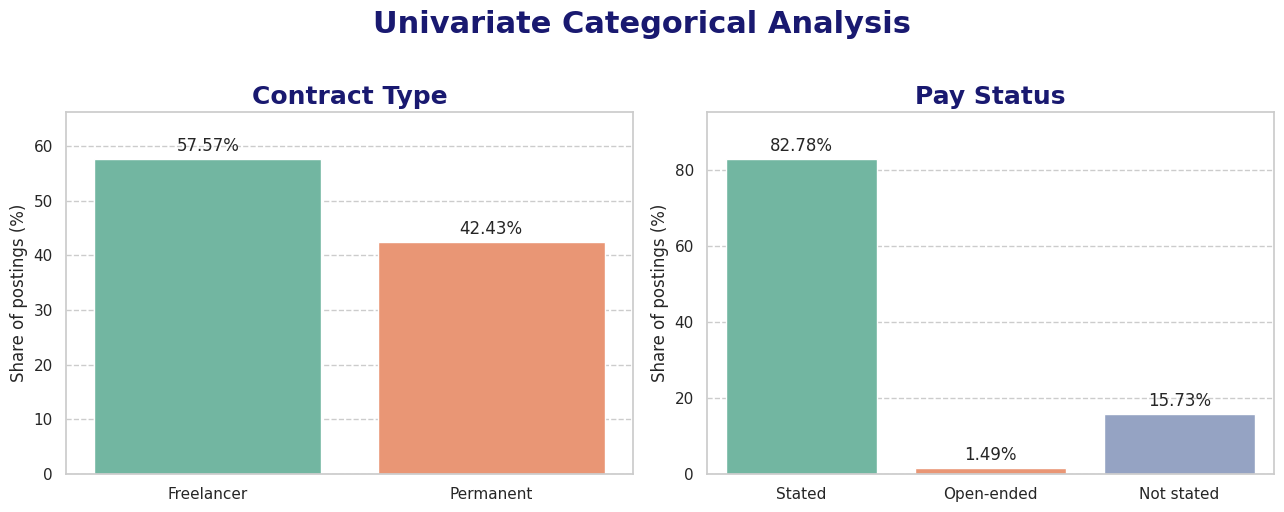

2026-11-23 16:48:23,282 - job_market_analysis - INFO - Contract type and pay status plotted — {'Freelancer': 57.57, 'Permanent': 42.43} | {'Stated': 82.78, 'Open-ended': 1.49, 'Not stated': 15.73}


In [33]:
section_header("Exploratory Data Analysis")
subsection_header("Univariate — Contract Type and Pay Status")

contract_share = df_refined["worker_type"].value_counts(normalize=True).mul(100)
pay_share = df_refined["pay_status"].value_counts(normalize=True).mul(100).reindex(PAY_STATUS_ORDER)
info_box("<b>2 categorical features</b> displayed as bar charts with each category's share of postings.")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Univariate Categorical Analysis", fontsize=22, color=PLOT_COLOR, fontweight="bold", y=1.02)
for ax, share, title, xlabel in [(axes[0], contract_share, "Contract Type", "Contract type"),
                                 (axes[1], pay_share, "Pay Status", "Pay status")]:
    sns.barplot(x=share.index, y=share.values, hue=share.index, palette="Set2", legend=False, ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f%%", padding=3)
    ax.set_title(title, fontweight="bold", fontsize=18)
    ax.set_xlabel("")
    ax.set_ylabel("Share of postings (%)")
    ax.set_ylim(0, share.max() * 1.15)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("Assets/eda_univariate_contract_and_pay_status.png", dpi=150, bbox_inches="tight")
plt.show()

info_box(
    "Contract type — " + "; ".join(f"{group}: {share:.2f}%" for group, share in contract_share.items()) + ". "
    "Pay status — " + "; ".join(f"{status}: {share:.2f}%" for status, share in pay_share.items()) + ".")
logger.info(f"Contract type and pay status plotted — {contract_share.round(2).to_dict()} | {pay_share.round(2).to_dict()}")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Contract Type and Pay Status:**

- **Both contract types are well represented:** Freelancer (hourly) postings make up 57.57% of the data and Permanent (salaried) postings 42.43%, so each has enough postings for its own statistics. Hourly rates and salaries are never pooled.
- **Most postings state their pay:** 82.78% do, while 15.73% give no rate and 1.49% give only a lower hourly rate. All of the latter 17.22% are hourly postings, about 3 in 10 of them.
- **Consequence:** those hourly postings carry their country's median rate and stay flagged, so every pay figure can be re-checked on Stated postings alone.

<hr style="width:60%; margin:auto;">

</div>

### 📌 Univariate — Client Country

<div style="margin-left: 20px; max-width: 90%">

Where clients are located and how concentrated postings are in a few countries. Country is the client's location, not the freelancer's.

</div>

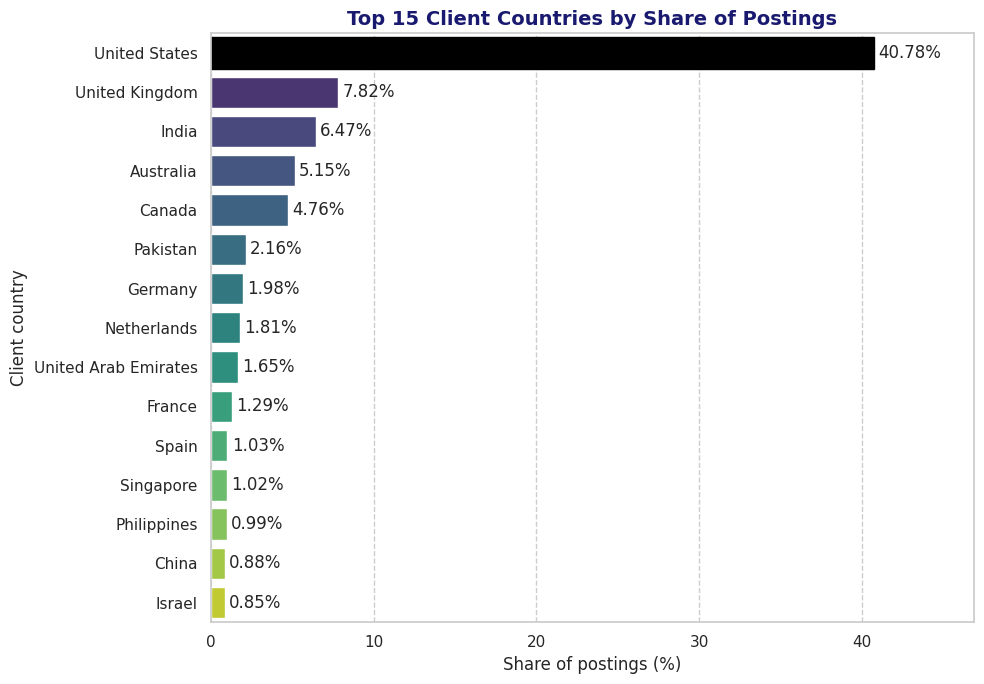

2026-11-23 16:48:24,395 - job_market_analysis - INFO - Country plotted — named countries=212, others=2.07%, top15 share=78.65%


In [34]:
subsection_header("Univariate — Client Country")

country_share = df_refined["country"].value_counts(normalize=True).mul(100)
others_share = country_share.get("Others", 0.0)
named_share = country_share.drop("Others", errors="ignore")
top_countries = named_share.head(15)

info_box("Top 15 named client countries displayed as a bar chart of their share of postings.")

fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(x=top_countries.values, y=top_countries.index, hue=top_countries.index, palette="viridis", legend=False, ax=ax)
ax.patches[0].set_color("black")                           # the leading country
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)
ax.set_title(f"Top {len(top_countries)} Client Countries by Share of Postings")
ax.set_xlabel("Share of postings (%)")
ax.set_ylabel("Client country")
ax.set_xlim(0, top_countries.max() * 1.15)
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("Assets/eda_univariate_client_country.png", dpi=150, bbox_inches="tight")
plt.show()

info_box(
    f"{len(named_share):,} named client countries appear, and {others_share:.2f}% of postings have no country (Others). The top {len(top_countries)} countries account for "
    f"{top_countries.sum():.1f}% of postings, led by {top_countries.index[0]} ({top_countries.iloc[0]:.1f}%).")
logger.info(f"Country plotted — named countries={len(named_share)}, others={others_share:.2f}%, top15 share={top_countries.sum():.2f}%")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Client Country:**

- **One market dominates:** the United States accounts for 40.78% of postings, more than five times the United Kingdom (7.82%), the next largest.
- **Five countries make up about two-thirds:** the United States, United Kingdom, India, Australia and Canada together hold 64.98%.
- **A long tail follows:** 212 named countries appear, and from Spain (1.03%) down each country shown holds about 1% or less. A further 2.07% of postings have no country and are labelled Others.
- **Consequence:** pay averages for small countries rest on few postings, so the country map needs a minimum posting count, and the recommender's country filter will return short lists outside the leading countries. Others is excluded from the map because it is not a country.

<hr style="width:60%; margin:auto;">

</div>

### 📌 Task 2: Univariate — Job Category Share

<div style="margin-left: 20px; max-width: 90%">

Every posting now carries a job category. This view shows how the market splits across categories, with the smallest ones grouped so the chart stays readable.

</div>

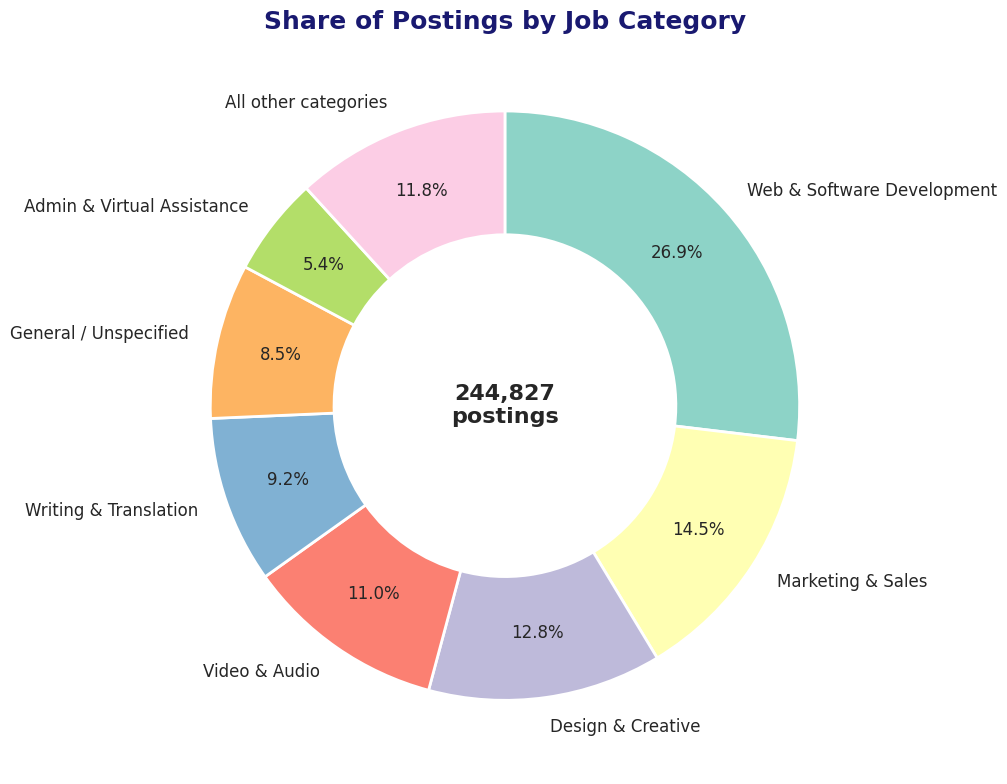

2026-11-23 16:48:25,071 - job_market_analysis - INFO - Job category share plotted — categories=15, top=Web & Software Development


In [35]:
subsection_header("Task 2: Univariate — Job Category Share")

TOP_CATEGORIES = 7
category_counts = df_refined["job_category"].value_counts()
donut_counts = pd.concat([category_counts.head(TOP_CATEGORIES), pd.Series({"All other categories": category_counts.iloc[TOP_CATEGORIES:].sum()})])
info_box(f"<b>1 categorical feature</b> across {len(category_counts)} job categories; the top {TOP_CATEGORIES} are shown separately and the rest are grouped.")

fig, ax = plt.subplots(figsize=(11, 8))
wedges, labels, percents = ax.pie(donut_counts.values, labels=donut_counts.index, autopct="%1.1f%%", pctdistance=0.78, startangle=90, counterclock=False,
                                  colors=sns.color_palette("Set3", len(donut_counts)), wedgeprops={"width": 0.42, "edgecolor": "white", "linewidth": 2},
                                  textprops={"fontsize": 12})
ax.text(0, 0, f"{len(df_refined):,}\npostings", ha="center", va="center", fontsize=16, fontweight="bold")
ax.set_title("Share of Postings by Job Category", fontsize=18, fontweight="bold", color=PLOT_COLOR)
plt.tight_layout()
plt.savefig("Assets/eda_univariate_job_category_share.png", dpi=150, bbox_inches="tight")
plt.show()

info_box(f"Largest category: {category_counts.index[0]} ({category_counts.iloc[0] / len(df_refined):.2%}). "
         f"The top {TOP_CATEGORIES} categories hold {category_counts.head(TOP_CATEGORIES).sum() / len(df_refined):.2%} of postings.")
logger.info(f"Job category share plotted — categories={len(category_counts)}, top={category_counts.index[0]}")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Job Category Share:**

- **Web dominates:** Web & Software Development holds 26.9% of postings, nearly twice Marketing & Sales (14.5%).
- **Concentration:** the seven named slices together hold about 88% of postings, and the other categories share the remaining 11.8%.
- **General / Unspecified:** 8.5% of titles carry no recognisable category word and stay in their own slice, so the other categories are not inflated by guesses.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Univariate — Title Keywords

<div style="margin-left: 20px; max-width: 90%">

The most frequent words in posting titles, after removing common English words and request wording such as "needed" or "looking". These words are the starting point for the keyword and category tasks later.

</div>

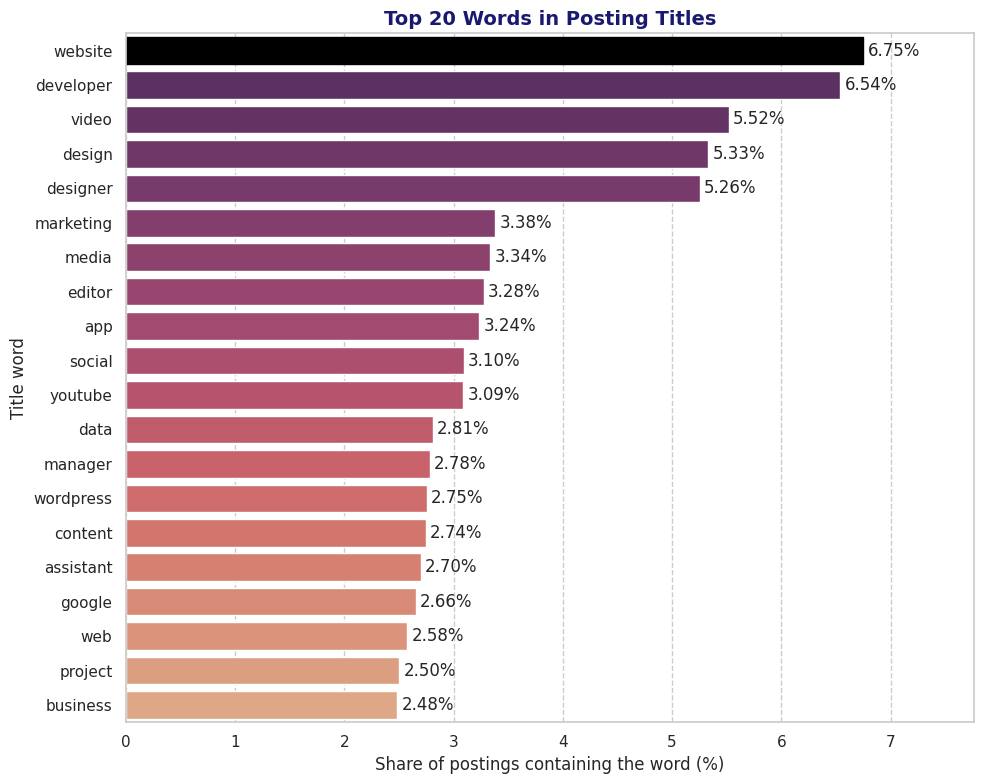

2026-11-23 16:48:27,703 - job_market_analysis - INFO - Title keywords plotted — distinct words=36227, top word=website


In [36]:
subsection_header("Univariate — Title Keywords")

info_box("<b>Top 20 title words</b> displayed as a bar chart of the share of postings whose title contains each word (common English words removed).")

FILLER_WORDS = {"needed", "need", "looking", "wanted", "required", "seeking", "hire", "hiring", "expert", "specialist", "create", "help", "urgent", "experienced"}
word_counter = CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS.union(FILLER_WORDS)), binary=True, token_pattern=r"[a-z][a-z0-9+#]+")
title_matrix = word_counter.fit_transform(df_refined["title_clean"])
word_postings = pd.Series(np.asarray(title_matrix.sum(axis=0)).ravel(), index=word_counter.get_feature_names_out()).sort_values(ascending=False)
word_share = word_postings.head(20) / len(df_refined) * 100

fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(x=word_share.values, y=word_share.index, hue=word_share.index, palette="flare_r", legend=False, ax=ax)
ax.patches[0].set_color("black")                           # the most common word
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)
ax.set_title("Top 20 Words in Posting Titles")
ax.set_xlabel("Share of postings containing the word (%)")
ax.set_ylabel("Title word")
ax.set_xlim(0, word_share.max() * 1.15)
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("Assets/eda_univariate_title_keywords.png", dpi=150, bbox_inches="tight")
plt.show()

info_box(
    f"{len(word_postings):,} distinct words appear in titles. The most common, '{word_share.index[0]}', is in {word_share.iloc[0]:.2f}% of titles; "
    f"the 20th, '{word_share.index[-1]}', in {word_share.iloc[-1]:.2f}%.")
logger.info(f"Title keywords plotted — distinct words={len(word_postings)}, top word={word_share.index[0]}")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Title Keywords:**

- **Build work leads:** "website" (6.75%) and "developer" (6.54%) are the two most common words, with "app" (3.24%), "wordpress" (2.75%) and "web" (2.58%) also in the top 20.
- **Creative work is the second block:** "video" (5.52%), "design" (5.33%), "designer" (5.26%), "editor" (3.28%) and "youtube" (3.09%).
- **Marketing and content follow:** "marketing" (3.38%), "media" (3.34%), "social" (3.10%) and "content" (2.74%). "Social" and "media" are the single phrase "social media" split in two.
- **Demand is spread out:** among 36,227 distinct words, no word appears in more than 6.75% of titles and the 20th, "business", is in 2.48%.
- **Word forms split the counts:** "design" and "designer", and "web" and "website", are counted separately, so single words understate a theme.
- **Consequence:** Task 1 tests words against pay, and Task 2 groups titles by theme rather than by single words.

<hr style="width:60%; margin:auto;">

</div>

### 📌 Task 7: Univariate — Remote and Non-Remote Postings

<div style="margin-left: 20px; max-width: 90%">

How many postings state remote work in the title and how many remote postings appear each day. This is the descriptive half of the remote-work analysis; the trend and forecast follow later. Postings without the keyword are labelled not flagged remote, which does not mean they are on-site.

</div>

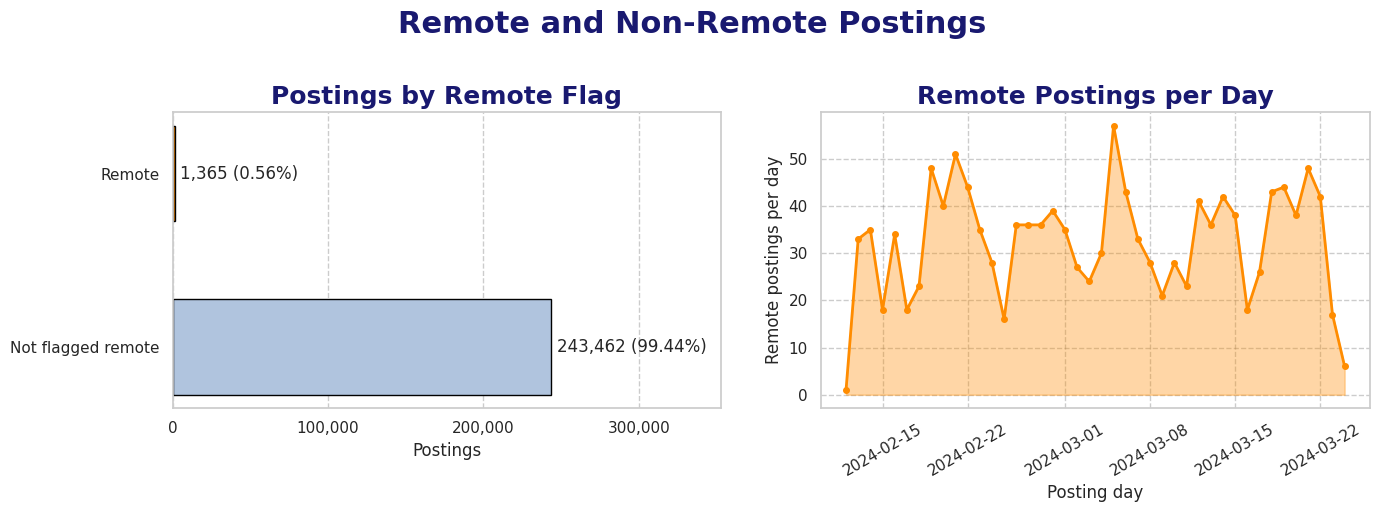

2026-11-23 16:48:28,473 - job_market_analysis - INFO - Remote postings plotted — remote=1365, share=0.0056


In [37]:
subsection_header("Task 7: Univariate — Remote and Non-Remote Postings")

remote_counts = df_refined["remote_posting"].map({True: "Remote", False: "Not flagged remote"}).value_counts().reindex(["Remote", "Not flagged remote"])
in_window = df_refined.loc[~df_refined["backdated_posting"]]
remote_daily = in_window.loc[in_window["remote_posting"]].groupby("posted_date").size()
remote_daily = remote_daily.reindex(pd.date_range(in_window["posted_date"].min(), in_window["posted_date"].max()), fill_value=0)

info_box("<b>Remote flag</b> displayed as a bar chart of postings and as daily remote postings in the high-volume window.")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Remote and Non-Remote Postings", fontsize=22, color=PLOT_COLOR, fontweight="bold", y=1.02)
fig.subplots_adjust(wspace=0.6)

bars = axes[0].barh(remote_counts.index, remote_counts.values, color=["darkorange", "lightsteelblue"], edgecolor="black", height=0.55)
axes[0].bar_label(bars, labels=[f"{count:,} ({count / remote_counts.sum():.2%})" for count in remote_counts.values], padding=4, fontsize=12)
axes[0].invert_yaxis()
axes[0].set_xlim(0, remote_counts.max() * 1.45)
axes[0].set_xlabel("Postings")
axes[0].xaxis.set_major_locator(plt.matplotlib.ticker.MaxNLocator(4))
axes[0].xaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
axes[0].grid(axis="x", linestyle="--", alpha=0.4)
axes[0].grid(axis="y", visible=False)
axes[0].set_title("Postings by Remote Flag", fontweight="bold", fontsize=18)

axes[1].fill_between(remote_daily.index, remote_daily.values, color="darkorange", alpha=0.35)
axes[1].plot(remote_daily.index, remote_daily.values, color="darkorange", linewidth=2, marker="o", markersize=4)
axes[1].set_title("Remote Postings per Day", fontweight="bold", fontsize=18)
axes[1].set_xlabel("Posting day")
axes[1].set_ylabel("Remote postings per day")
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("Assets/task7_univariate_remote_postings.png", dpi=150, bbox_inches="tight")
plt.show()

full_days = remote_daily.index.isin(in_window.groupby("posted_date").size().loc[lambda counts: counts >= 0.5 * counts.median()].index)
info_box(
    f"{int(remote_counts['Remote']):,} postings ({remote_counts['Remote'] / remote_counts.sum():.2%}) are flagged remote; the other {int(remote_counts['Not flagged remote']):,} do not say so in the title, "
    f"which does not mean they are on-site. On full days remote postings range from {int(remote_daily[full_days].min())} to {int(remote_daily[full_days].max())} a day (median {remote_daily[full_days].median():.0f}).")
logger.info(f"Remote postings plotted — remote={int(remote_counts['Remote'])}, share={remote_counts['Remote'] / remote_counts.sum():.4f}")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Remote and Non-Remote Postings:**

- **Remote is rare:** 1,365 postings (0.56%) are flagged remote, against 243,462 (99.44%) that are not.
- **Not flagged does not mean on-site:** the flag comes from the title only, so clients who ask for remote work in the description are not counted.
- **Daily counts are small but steady:** on full days remote postings range from 16 to 57 with a median of 35, with the highest day in early March.
- **Edge days are low:** the first day starts near zero and the last two days fall away, which matches the incomplete collection seen earlier.
- **Consequence:** the remote forecast rests on a few dozen postings a day, so its intervals will be wide and the trend will be reported with that limit in mind.

<hr style="width:60%; margin:auto;">

</div>

### 📌 Univariate — Posting Volume Over Time

<div style="margin-left: 20px; max-width: 90%">

Postings per day in the high-volume window, with weekends marked, to see the level, the weekly rhythm and whether the first and last days are complete.

</div>

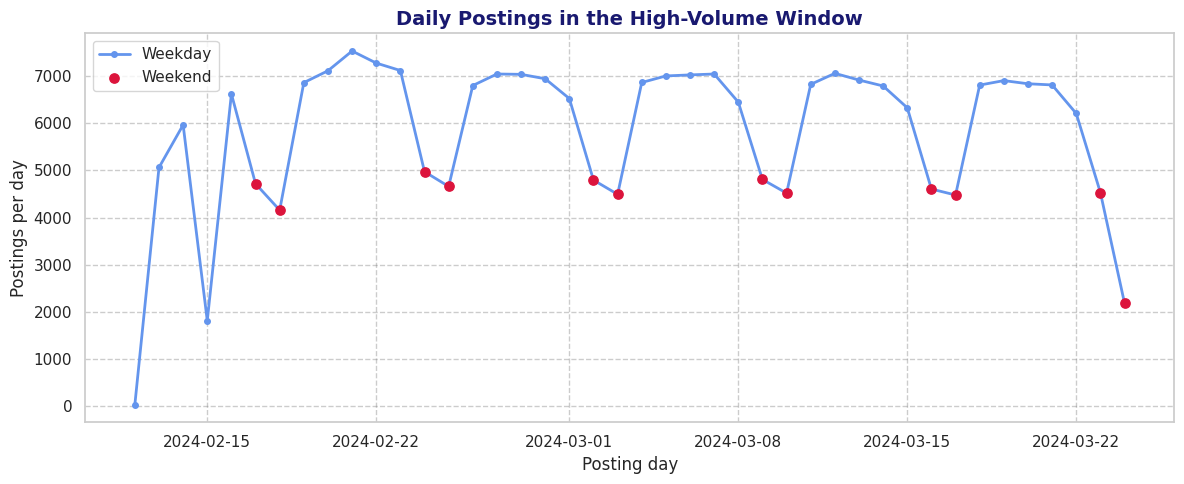

2026-11-23 16:48:29,100 - job_market_analysis - INFO - Daily volume plotted — days=42, first-week mean=4052, later mean=6177


In [38]:
subsection_header("Univariate — Posting Volume Over Time")

in_window = df_refined.loc[~df_refined["backdated_posting"]]
daily_postings = in_window.groupby("posted_date").size()
daily_postings = daily_postings.reindex(pd.date_range(daily_postings.index.min(), daily_postings.index.max()), fill_value=0)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(daily_postings.index, daily_postings.values, color='cornflowerblue', linewidth=2, marker="o", markersize=4, label="Weekday")
weekend = daily_postings[daily_postings.index.dayofweek >= 5]
ax.scatter(weekend.index, weekend.values, color="crimson", s=45, zorder=3, label="Weekend")
ax.set_title("Daily Postings in the High-Volume Window")
ax.set_xlabel("Posting day")
ax.set_ylabel("Postings per day")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("Assets/eda_univariate_posting_volume.png", dpi=150, bbox_inches="tight")
plt.show()

first_week, remaining = daily_postings.iloc[:7], daily_postings.iloc[7:]
info_box(
    f"{len(daily_postings)} days from {daily_postings.index.min():%d %b %Y} to {daily_postings.index.max():%d %b %Y} "
    f"({len(df_refined) - len(in_window):,} backdated postings excluded). Busiest day: {daily_postings.idxmax():%d %b} ({daily_postings.max():,} postings); "
    f"quietest: {daily_postings.idxmin():%d %b} ({daily_postings.min():,}). The first 7 days average {first_week.mean():,.0f} postings a day "
    f"against {remaining.mean():,.0f} afterwards.")
logger.info(f"Daily volume plotted — days={len(daily_postings)}, first-week mean={first_week.mean():.0f}, later mean={remaining.mean():.0f}")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Posting Volume Over Time:**

- **A clear weekly rhythm:** after the first week, weekdays bring roughly 6,300 to 7,100 postings a day and weekends roughly 4,150 to 4,950, about a third fewer. The busiest day is 21 Feb (7,534 postings).
- **The window opens unevenly:** 12 Feb has only 31 postings and 15 Feb, a Thursday, dips to about 1,800. The first seven days average 4,052 a day against 6,177 afterwards.
- **The window ends low:** the last day, Sunday 24 Mar, has about 2,200 postings against roughly 4,150 to 4,800 on earlier Sundays. These edge days look like incomplete collection rather than real demand.
- **Consequence:** the series is only 42 days long, so forecasts stay short-horizon and the complex models must beat a seasonal naive yardstick with a 7-day season. The edge days need a decision before modelling, and month comparisons must use per-day averages.

<hr style="width:60%; margin:auto;">

</div>

### 📌 Univariate — Numerical Distributions

<div style="margin-left: 20px; max-width: 90%">

How hourly rate midpoints, salaries and title lengths are distributed. Pay is shown on a log scale because a few very high values stretch the axis.

</div>

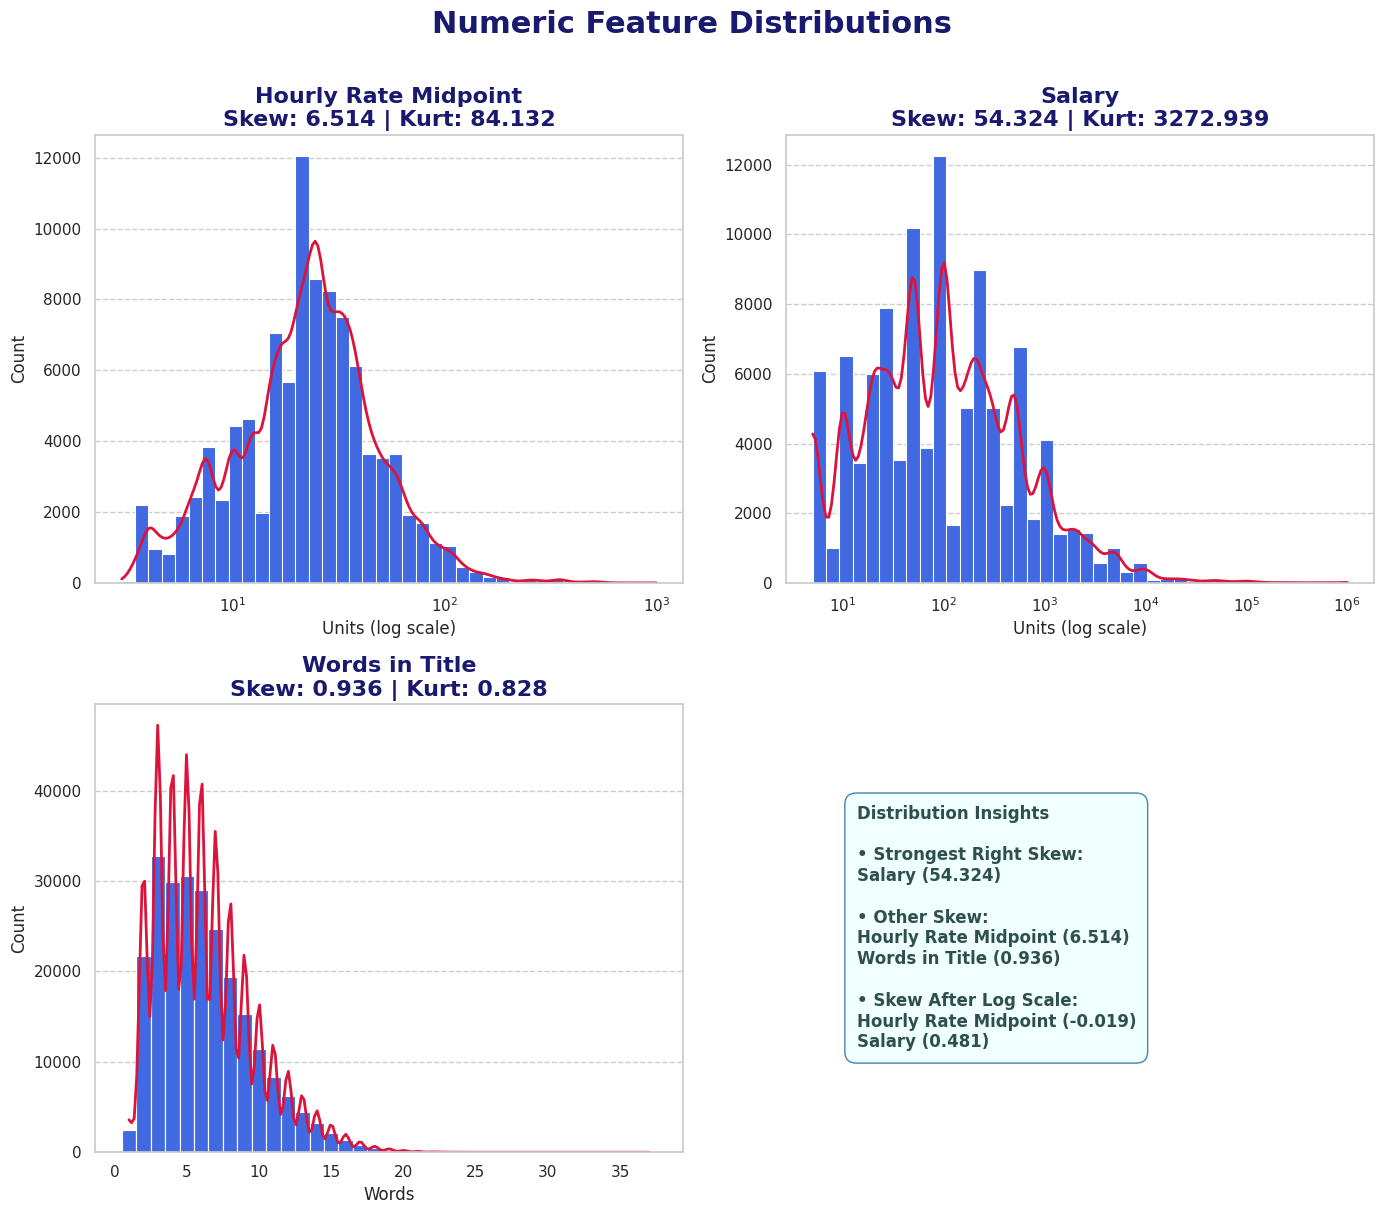

2026-11-23 16:48:33,516 - job_market_analysis - INFO - Numeric distributions rendered — skew/kurtosis for 3 features


In [39]:
subsection_header("Univariate — Numerical Distributions")

numeric_view = pd.DataFrame({
    "hourly_rate_mid": df_refined.loc[df_refined["is_hourly"] & (df_refined["pay_status"] == "Stated"), "hourly_rate_mid"],
    "budget": df_refined.loc[~df_refined["is_hourly"] & (df_refined["budget"] > 0), "budget"],
    "title_word_count": df_refined["title_word_count"],
})
numeric_labels = {"hourly_rate_mid": "Hourly Rate Midpoint", "budget": "Salary", "title_word_count": "Words in Title"}
log_columns = ["hourly_rate_mid", "budget"]

info_box(f"<b>{len(numeric_view.columns)} features</b> displayed as histograms with skew and kurtosis values. "
         f"Skew and kurtosis use the original values; pay is drawn on a log axis because it is heavily right-skewed.")

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle("Numeric Feature Distributions", fontsize=22, color=PLOT_COLOR, fontweight="bold", y=1.01)
fig.subplots_adjust(wspace=0.3, hspace=0.4)
axes = axes.flatten()

shape_stats = {}
for i, col in enumerate(numeric_view.columns):
    vals = numeric_view[col].dropna()
    sk_val, kt_val = skew(vals), kurtosis(vals)
    shape_stats[col] = (sk_val, kt_val)
    discrete = col == "title_word_count"
    sns.histplot(vals, kde=True, color="crimson", facecolor="royalblue", edgecolor="white", bins=None if discrete else 40,
                 discrete=discrete, log_scale=col in log_columns, ax=axes[i], line_kws={"linewidth": 2})
    axes[i].set_title(f"{numeric_labels[col]}\nSkew: {sk_val:.3f} | Kurt: {kt_val:.3f}", fontweight="bold", fontsize=16)
    axes[i].set_xlabel("Units (log scale)" if col in log_columns else "Words")
    axes[i].grid(True, linestyle="--", alpha=0.4)
    axes[i].grid(axis='x',visible=False)

by_skew = sorted(shape_stats.items(), key=lambda item: item[1][0], reverse=True)
log_skew = {col: skew(np.log(numeric_view[col].dropna())) for col in log_columns}
insight_lines = ["Distribution Insights", "", "• Strongest Right Skew:", f"{numeric_labels[by_skew[0][0]]} ({by_skew[0][1][0]:.3f})", "", "• Other Skew:"]
insight_lines += [f"{numeric_labels[col]} ({stats[0]:.3f})" for col, stats in by_skew[1:]]
insight_lines += ["", "• Skew After Log Scale:"] + [f"{numeric_labels[col]} ({value:.3f})" for col, value in log_skew.items()]

axes[3].axis("off")
axes[3].text(0.12, 0.5, "\n".join(insight_lines), transform=axes[3].transAxes, fontsize=12, va="center", ha="left",
             color="darkslategray", weight="bold", bbox=dict(boxstyle="round,pad=0.7", facecolor="azure", edgecolor="steelblue"))

plt.tight_layout()
plt.savefig("Assets/eda_univariate_numerical_histograms.png", dpi=150, bbox_inches="tight")
plt.show()

info_box("Mean / median / minimum / maximum — " + "; ".join(
    f"{numeric_labels[col]}: {numeric_view[col].mean():,.2f} / {numeric_view[col].median():,.2f} / {numeric_view[col].min():,.2f} / {numeric_view[col].max():,.2f}"
    for col in numeric_view.columns) + ".")
logger.info(f"Numeric distributions rendered — skew/kurtosis for {len(numeric_view.columns)} features")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Numerical Distributions:**

- **Hourly rates are strongly right-skewed:** skew is 6.514 and kurtosis 84.132, with a mean of 29.71 above a median of 22.50 and a maximum of 998.50. After the log transform the skew is -0.019, so the distribution is almost symmetric.
- **Salaries are extreme:** skew is 54.324 and kurtosis 3,272.939, with a mean of 911.47 against a median of 100 and a maximum of 1,000,000. After the log transform the skew is 0.481, a mild tail instead of an extreme one.
- **Round-number peaks:** the salary histogram has separate peaks rather than a smooth curve, which suggests clients choose round budgets. The hourly histogram peaks around 20 units, close to the median.
- **Title length is mild:** skew is 0.936 and kurtosis 0.828, with a median of 6 words, a mean of 6.24 and a maximum of 37. The ripples in the KDE come from titles having whole numbers of words, not from real structure.
- **Consequence:** pay needs a log scale, since it cuts the hourly skew from 6.514 to -0.019 and the salary skew from 54.324 to 0.481. Title length needs no transformation.

<hr style="width:60%; margin:auto;">

</div>

### 📌 Univariate — Spread and Boxplots

<div style="margin-left: 20px; max-width: 90%">

The same three features as boxplots, with the number and share of values outside the whiskers. Pay is drawn on a log scale, using the same rule as the outlier table that follows.

</div>

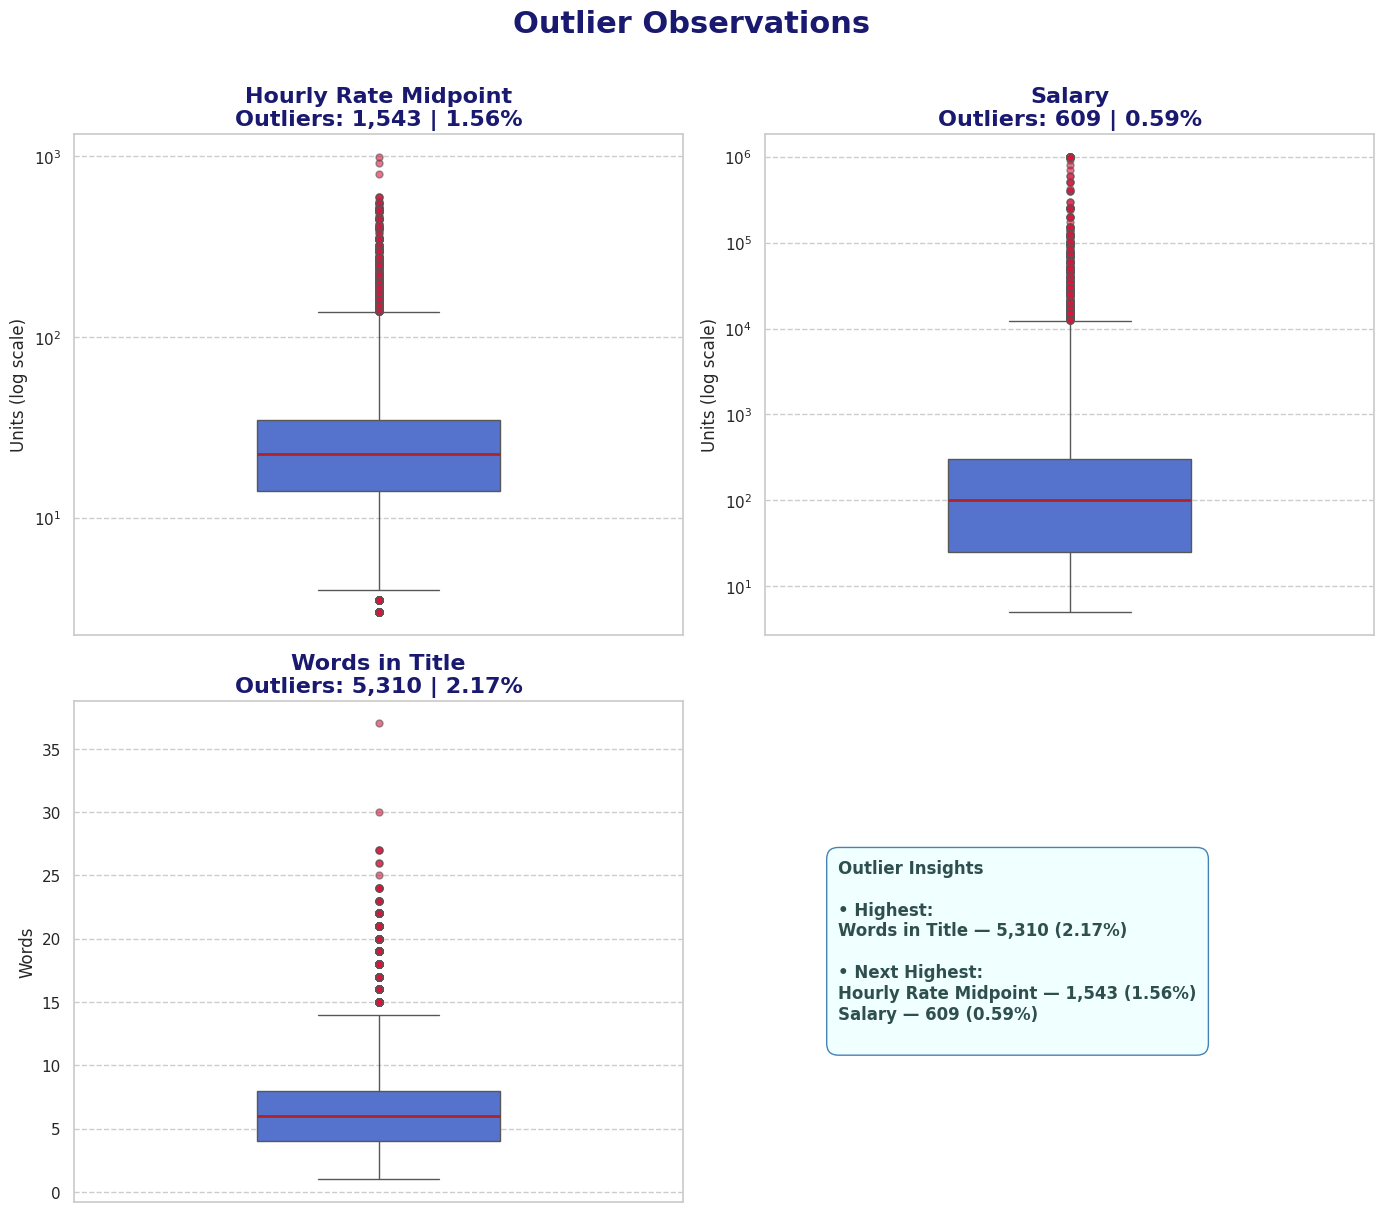

2026-11-23 16:48:36,071 - job_market_analysis - INFO - Numeric boxplots rendered — outlier severity assessed for all features


In [40]:
subsection_header("Univariate — Spread and Boxplots")

info_box(f"<b>{len(numeric_view.columns)} features</b> displayed as boxplots to assess outlier severity. "
         f"Pay bounds are computed on a log scale, the same rule as the outlier table that follows.")

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle("Outlier Observations", fontsize=22, color=PLOT_COLOR, fontweight="bold", y=1.01)
fig.subplots_adjust(wspace=0.3, hspace=0.4)
axes = axes.flatten()

outlier_rows = []
for i, col in enumerate(numeric_view.columns):
    vals = numeric_view[col].dropna()
    scaled = np.log(vals) if col in log_columns else vals
    outliers = detect_outliers_iqr(scaled)
    pct = len(outliers) / len(vals) * 100
    outlier_rows.append((numeric_labels[col], len(outliers), pct))

    sns.boxplot(y=vals, ax=axes[i], color="royalblue", width=0.4, log_scale=col in log_columns,
                medianprops=dict(color="firebrick", linewidth=2),
                flierprops=dict(marker="o", markerfacecolor="crimson", markersize=5, alpha=0.6))
    axes[i].set_title(f"{numeric_labels[col]}\nOutliers: {len(outliers):,} | {pct:.2f}%", fontweight="bold", fontsize=16)
    axes[i].set_ylabel("Units (log scale)" if col in log_columns else "Words")
    axes[i].grid(True, linestyle="--", alpha=0.4, axis="y")

ranked_outliers = pd.DataFrame(outlier_rows, columns=["feature", "outlier_count", "outlier_pct"]).sort_values("outlier_pct", ascending=False)
with_outliers = ranked_outliers[ranked_outliers["outlier_count"] > 0]
without_outliers = ranked_outliers.loc[ranked_outliers["outlier_count"] == 0, "feature"].tolist()

insight_lines = ["Outlier Insights", ""]
if len(with_outliers):
    top = with_outliers.iloc[0]
    insight_lines += ["• Highest:", f"{top['feature']} — {int(top['outlier_count']):,} ({top['outlier_pct']:.2f}%)", ""]
if len(with_outliers) > 1:
    insight_lines += ["• Next Highest:"] + [f"{row['feature']} — {int(row['outlier_count']):,} ({row['outlier_pct']:.2f}%)"
                                            for _, row in with_outliers.iloc[1:].iterrows()] + [""]
if without_outliers:
    insight_lines += ["• No IQR Outliers:"] + without_outliers

axes[3].axis("off")
axes[3].text(0.12, 0.5, "\n".join(insight_lines), transform=axes[3].transAxes, fontsize=12, va="center", ha="left",
             color="darkslategray", weight="bold", bbox=dict(boxstyle="round,pad=0.7", facecolor="azure", edgecolor="steelblue"))

plt.tight_layout()
plt.savefig("Assets/eda_univariate_numerical_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

logger.info("Numeric boxplots rendered — outlier severity assessed for all features")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Spread and Boxplots:**

- **Hourly rates:** 1,543 values (1.56%) fall outside the bounds, mostly high values stretching to 998.50, plus a few at the minimum of 3.00. The middle half of postings lies roughly between 14 and 35 units, around the median of 22.50.
- **Salaries:** 609 values (0.59%) fall outside the bounds, all above the upper whisker (about 12,500), and they reach 1,000,000. Nothing sits below the lower whisker, which ends at the minimum of 5.
- **Title length:** 5,310 titles (2.17%) are flagged, the largest share, but all of them lie above 14 words. These are long real titles, not errors, with a maximum of 37.
- **Consequence:** pay outliers are few but far out, up to about 44 and 10,000 times the median, so they distort averages. Title length does not need treatment.

<hr style="width:60%; margin:auto;">

</div>

### 📌 Univariate — Outlier Detection

<div style="margin-left: 20px; max-width: 90%">

Values outside the IQR bounds, plus a z-score count for comparison. Detection only: what to do with them is decided after seeing the counts.

</div>

In [41]:
subsection_header("Univariate — Outlier Detection")

pay_outliers = outlier_summary(numeric_view, ["hourly_rate_mid", "budget"], log_scale=True, dataset_name="df_refined")
word_outliers = outlier_summary(numeric_view, ["title_word_count"], dataset_name="df_refined")
outlier_table = pd.concat([pay_outliers, word_outliers], ignore_index=True)
outlier_table.insert(1, "Scale", ["Log", "Log", "Linear"])
outlier_table = outlier_table.rename(columns={
    "column": "Column", "n_values": "Values", "iqr_lower": "IQR Lower", "iqr_upper": "IQR Upper", "iqr_outliers": "IQR Outliers",
    "iqr_outlier_pct": "IQR Outliers (%)", "z_outliers": "Z-Score Outliers", "max_value": "Maximum"})

display_table = outlier_table.copy()
for col in ["Values", "IQR Outliers", "Z-Score Outliers"]:
    display_table[col] = display_table[col].map("{:,}".format)
centered_table(display_table, float_format="{:,.2f}")

info_box(
    "Pay columns are checked on a log scale because pay is strongly right-skewed. "
    + " ".join(f"{row['Column']}: {int(row['IQR Outliers']):,} values ({row['IQR Outliers (%)']:.2f}%) outside the IQR bounds, maximum {row['Maximum']:,.2f}."
               for _, row in outlier_table.iterrows()))
logger.info(f"Outlier detection — {outlier_table[['Column', 'IQR Outliers']].to_dict('records')}")

2026-11-23 16:48:36,130 - job_market_analysis - INFO - [df_refined] Outlier summary built for 2 columns (log_scale=True)
2026-11-23 16:48:36,153 - job_market_analysis - INFO - [df_refined] Outlier summary built for 1 columns (log_scale=False)


Column,Scale,Values,IQR Lower,IQR Upper,IQR Outliers,IQR Outliers (%),Z-Score Outliers,Maximum
hourly_rate_mid,Log,"98,775",3.54,138.35,"1,543",1.56,356,998.50
budget,Log,"103,891",0.60,"12,470.77",609,0.59,503,"1,000,000.00"
title_word_count,Linear,"244,827",-2.00,14.00,"5,310",2.17,"1,781",37.00


2026-11-23 16:48:36,169 - job_market_analysis - INFO - Outlier detection — [{'Column': 'hourly_rate_mid', 'IQR Outliers': 1543}, {'Column': 'budget', 'IQR Outliers': 609}, {'Column': 'title_word_count', 'IQR Outliers': 5310}]


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Outlier Detection:**

- **Bounds:** hourly rates are flagged below 3.54 and above 138.35 units, and salaries below 0.60 and above 12,470.77. Salaries have no low outliers, because the lower bound is under the minimum of 5.
- **The z-score is stricter than the IQR rule:** it flags 356 hourly rates against 1,543, 503 salaries against 609 and 1,781 titles against 5,310, because it only flags values more than three standard deviations from the mean.
- **Title length:** the lower bound of -2.00 is meaningless for a count of words, so only the upper bound of 14 words matters.
- **Extremes:** the maximum hourly midpoint is 998.50 and the maximum salary is 1,000,000, far beyond the upper bounds.

<hr style="width:60%; margin:auto;">

</div>

### 📌 Outlier Decision — What the Rule Would Change

<div style="margin-left: 20px; max-width: 90%">

Values are judged against the IQR bounds, computed on a log scale for pay so that its long right tail does not stretch them. Each column then gets one of two decisions:

- **Cap at bounds:** a pay amount where a few extreme values would distort averages. The posting is real demand, so it stays and only the pay value is limited to the nearest bound.
- **Retain:** legitimate values that feed no pay statistic.

</div>

In [42]:
subsection_header("Outlier Decision — What the Rule Would Change")

def decision_badge(text):
    color = "#2E8B57" if text == "Retain" else "#C0392B"  # green=Retain, red=Cap
    return (f'<span style="background:{color};color:white;padding:4px 14px;'
            f'border-radius:12px;font-weight:bold;font-size:12px;white-space:nowrap;">{text}</span>')

decision_rows = []
for col in log_columns:
    vals = numeric_view[col].dropna()
    lower, upper = np.exp(iqr_bounds(np.log(vals)))
    lower, upper = np.ceil(lower * 100) / 100, np.floor(upper * 100) / 100       # rounded inwards so capped values sit inside the bounds
    capped = vals.clip(lower, upper)
    decision_rows.append({
        "Column": col, "Lower Bound": lower, "Upper Bound": upper,
        "Values Below": int((vals < lower).sum()), "Values Above": int((vals > upper).sum()),
        "Median": vals.median(), "Mean Before": vals.mean(), "Mean After Capping": capped.mean(),
        "Decision": "Cap at bounds"})

words = numeric_view["title_word_count"]
word_lower, word_upper = iqr_bounds(words)
decision_rows.append({
    "Column": "title_word_count", "Lower Bound": word_lower, "Upper Bound": word_upper,
    "Values Below": int((words < word_lower).sum()), "Values Above": int((words > word_upper).sum()),
    "Median": words.median(), "Mean Before": words.mean(), "Mean After Capping": words.mean(),
    "Decision": "Retain"})

decision_table = pd.DataFrame(decision_rows)
display_table = decision_table.copy()

for col in ["Values Below", "Values Above"]:
    display_table[col] = display_table[col].map("{:,}".format)

# Apply the badge function to the display table
display_table["Decision"] = display_table["Decision"].apply(decision_badge)

centered_table(display_table, float_format="{:,.2f}")

pay_rows = decision_table[decision_table["Decision"] == "Cap at bounds"]
info_box(
    "Pay values beyond the bounds are capped, not removed, so every posting stays in the data. "
    + " ".join(f"{row['Column']}: mean {row['Mean Before']:,.2f} → {row['Mean After Capping']:,.2f} (median {row['Median']:,.2f} unchanged)."
               for _, row in pay_rows.iterrows())
    + " Title length is kept as is: long titles are real postings, not errors.")
logger.info(f"Outlier decision — capped columns={list(pay_rows['Column'])}, kept=title_word_count")

Column,Lower Bound,Upper Bound,Values Below,Values Above,Median,Mean Before,Mean After Capping,Decision
hourly_rate_mid,3.55,138.34,665,878,22.50,29.71,28.82,Cap at bounds
budget,0.61,"12,470.76",0,609,100.00,911.47,469.21,Cap at bounds
title_word_count,-2.00,14.00,0,"5,310",6.00,6.24,6.24,Retain


2026-11-23 16:48:36,257 - job_market_analysis - INFO - Outlier decision — capped columns=['hourly_rate_mid', 'budget'], kept=title_word_count


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Outlier Decision:**

- **Hourly rates:** the bounds are 3.55 and 138.34 units, with 665 stated rates below and 878 above. Capping moves the mean from 29.71 to 28.82 and leaves the median at 22.50, a small effect.
- **Salaries:** the bounds are 0.61 and 12,470.76, with 609 salaries above and none below. Capping cuts the mean from 911.47 to 469.21 while the median stays 100.00, so 0.59% of salaries carried about half of the mean.
- **Title length:** 5,310 titles exceed 14 words, but the mean (6.24) does not change and long titles are real postings, so this column is left as it is.
- **Consequence:** pay comparisons use the capped columns, and medians remain the headline statistic.

<hr style="width:60%; margin:auto;">

</div>

### 📌 Outlier Treatment — Capped Pay Columns

<div style="margin-left: 20px; max-width: 90%">

Two new columns hold the capped pay. The originals are kept, and a flag marks every posting whose pay was capped.

</div>

In [43]:
subsection_header("Outlier Treatment — Capped Pay Columns")

OUTLIER_BOUNDS = {row["Column"]: (row["Lower Bound"], row["Upper Bound"]) for _, row in pay_rows.iterrows()}
is_hourly = df_refined["is_hourly"]

low_h, high_h = OUTLIER_BOUNDS["hourly_rate_mid"]
low_s, high_s = OUTLIER_BOUNDS["budget"]
df_refined["hourly_rate_mid_capped"] = np.where(is_hourly, df_refined["hourly_rate_mid"].clip(low_h, high_h), 0.0)
df_refined["budget_capped"] = np.where(~is_hourly, df_refined["budget"].clip(low_s, high_s), 0.0)
df_refined["pay_capped"] = ((is_hourly & (df_refined["hourly_rate_mid_capped"] != df_refined["hourly_rate_mid"]))
                            | (~is_hourly & (df_refined["budget_capped"] != df_refined["budget"])))

treatment_summary = pd.DataFrame([
    {"Original Column": original, "Capped Column": capped, "Postings Capped": int((mask & (df_refined[original] != df_refined[capped])).sum()),
     "Maximum Before": df_refined.loc[mask, original].max(), "Maximum After": df_refined.loc[mask, capped].max(),
     "Mean Before": df_refined.loc[mask, original].mean(), "Mean After": df_refined.loc[mask, capped].mean()}
    for original, capped, mask in [("hourly_rate_mid", "hourly_rate_mid_capped", is_hourly), ("budget", "budget_capped", ~is_hourly)]])
display_summary = treatment_summary.copy()
display_summary["Postings Capped"] = display_summary["Postings Capped"].map("{:,}".format)
centered_table(display_summary, float_format="{:,.2f}")

info_box(
    f"hourly_rate_mid_capped and budget_capped added; the originals are kept. pay_capped marks the {int(df_refined['pay_capped'].sum()):,} postings "
    f"whose pay was capped. Pay comparisons from here on use the capped columns.")
logger.info(f"Outlier treatment applied — capped postings={int(df_refined['pay_capped'].sum())}")

Original Column,Capped Column,Postings Capped,Maximum Before,Maximum After,Mean Before,Mean After
hourly_rate_mid,hourly_rate_mid_capped,"1,562",998.50,138.34,27.66,27.02
budget,budget_capped,609,"1,000,000.00","12,470.76",911.47,469.21


2026-11-23 16:48:36,325 - job_market_analysis - INFO - Outlier treatment applied — capped postings=2171


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Outlier Treatment:**

- **Hourly rates:** 1,562 hourly postings were capped. That is 19 more than the 1,543 stated rates counted in the decision, because this step also covers hourly postings whose rates were filled. The maximum falls from 998.50 to 138.34 and the mean from 27.66 to 27.02.
- **Salaries:** 609 postings were capped, bringing the maximum down from 1,000,000 to 12,470.76 and the mean from 911.47 to 469.21.
- **Nothing is lost:** `pay_capped` marks the 2,171 postings (0.89%) whose pay changed, and the original columns are kept, so any result can be re-checked uncapped.

<hr style="width:60%; margin:auto;">

</div>

### 📌 Outlier Treatment — Capping Methods Compared

<div style="margin-left: 20px; max-width: 90%">

The chosen cap is compared with percentile caps and with the log of the capped values. The table shows what each option does to skew and kurtosis and how many postings it changes, so the choice of method is backed by evidence.

</div>

In [44]:
subsection_header("Outlier Treatment — Capping Methods Compared")

def tail_cap(values, tail):
    """Winsorise both tails at the given share (0.01 = 1st and 99th percentile)."""
    return values.clip(values.quantile(tail), values.quantile(1 - tail))

comparison_rows = []
for col in log_columns:
    vals = numeric_view[col].dropna()
    lower, upper = OUTLIER_BOUNDS[col]
    methods = {
        "No capping": vals,
        "IQR fence on log scale (chosen)": vals.clip(lower, upper),
        "1st / 99th percentile": tail_cap(vals, 0.01),
        "2.5th / 97.5th percentile": tail_cap(vals, 0.025),
        "5th / 95th percentile": tail_cap(vals, 0.05),
        "IQR fence, then log": np.log(vals.clip(lower, upper)),
    }
    for method, result in methods.items():
        is_log = method.endswith("log")                                     # the log row is a different scale, so its change share and maximum are not comparable
        changed = np.nan if is_log else (result != vals).mean() * 100
        comparison_rows.append({"Pay Column": numeric_labels[col], "Method": method, "Postings Changed (%)": changed,
                                "Skew": skew(result), "Kurtosis": kurtosis(result), "Maximum": np.nan if is_log else result.max()})

comparison_table = pd.DataFrame(comparison_rows)
display_table = comparison_table.copy()
display_table["Postings Changed (%)"] = display_table["Postings Changed (%)"].map(lambda value: "—" if pd.isna(value) else f"{value:.2f}")
display_table["Maximum"] = display_table["Maximum"].map(lambda value: "—" if pd.isna(value) else f"{value:,.2f}")
centered_table(display_table, float_format="{:,.3f}")

fence_rows = comparison_table[comparison_table["Method"] == "IQR fence on log scale (chosen)"].set_index("Pay Column")
log_rows = comparison_table[comparison_table["Method"] == "IQR fence, then log"].set_index("Pay Column")
info_box(
    "Capping limits extreme values but cannot make a naturally right-skewed variable symmetric. "
    + " ".join(f"{label}: skew {fence_rows.loc[label, 'Skew']:.3f} with the fence, {log_rows.loc[label, 'Skew']:.3f} after the log." for label in fence_rows.index))
logger.info("Capping methods compared — fence vs percentile caps vs log")

Pay Column,Method,Postings Changed (%),Skew,Kurtosis,Maximum
Hourly Rate Midpoint,No capping,0.00,6.514,84.132,998.50
Hourly Rate Midpoint,IQR fence on log scale (chosen),1.56,2.153,5.973,138.34
Hourly Rate Midpoint,1st / 99th percentile,1.62,2.110,5.663,135.00
Hourly Rate Midpoint,2.5th / 97.5th percentile,4.53,1.598,2.602,100.00
Hourly Rate Midpoint,5th / 95th percentile,9.79,1.118,0.604,75.00
Hourly Rate Midpoint,"IQR fence, then log",—,-0.145,-0.146,—
Salary,No capping,0.00,54.324,"3,272.939","1,000,000.00"
Salary,IQR fence on log scale (chosen),0.59,6.112,42.723,"12,470.76"
Salary,1st / 99th percentile,0.64,5.529,34.353,"10,000.00"
Salary,2.5th / 97.5th percentile,2.44,3.462,12.040,"4,000.00"


2026-11-23 16:48:36,489 - job_market_analysis - INFO - Capping methods compared — fence vs percentile caps vs log


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Capping Methods Compared:**

- **The chosen cap matches the 99th percentile:** for hourly rates the fence changes 1.56% of postings and gives skew 2.153, against 1.62% and 2.110 for the 1st/99th percentile cap. For salaries the two are 0.59% with skew 6.112 and 0.64% with skew 5.529. Switching to percentiles would not change the outcome.
- **Stricter caps cost far more than they gain:** the 5th/95th percentile cap changes 9.79% of hourly postings and 4.48% of salaries, and skew is still positive (1.118 and 2.415). It would also flatten every rate above 75 units and every salary above 2,000, which are the postings Task 1 and Task 4 need to tell apart.
- **Capping limits extremes but cannot remove skew:** the maximum falls from 998.50 to 138.34 units for hourly rates and from 1,000,000 to 12,470.76 for salaries, but pay stays right-skewed because that is its natural shape.
- **The log fixes the shape:** after the fence and a log transform, skew is −0.145 for hourly rates and 0.366 for salaries, and kurtosis is −0.146 and −0.235.
- **Consequence:** pay is capped at the fence for averages and displays, and tests, correlations, clustering and models use the log of the capped values.

<hr style="width:60%; margin:auto;">

</div>

### 📌 Univariate — Pay Distributions After Capping

<div style="margin-left: 20px; max-width: 90%">

The capped pay columns, plotted the same way as before, to confirm the extreme values are gone.

</div>

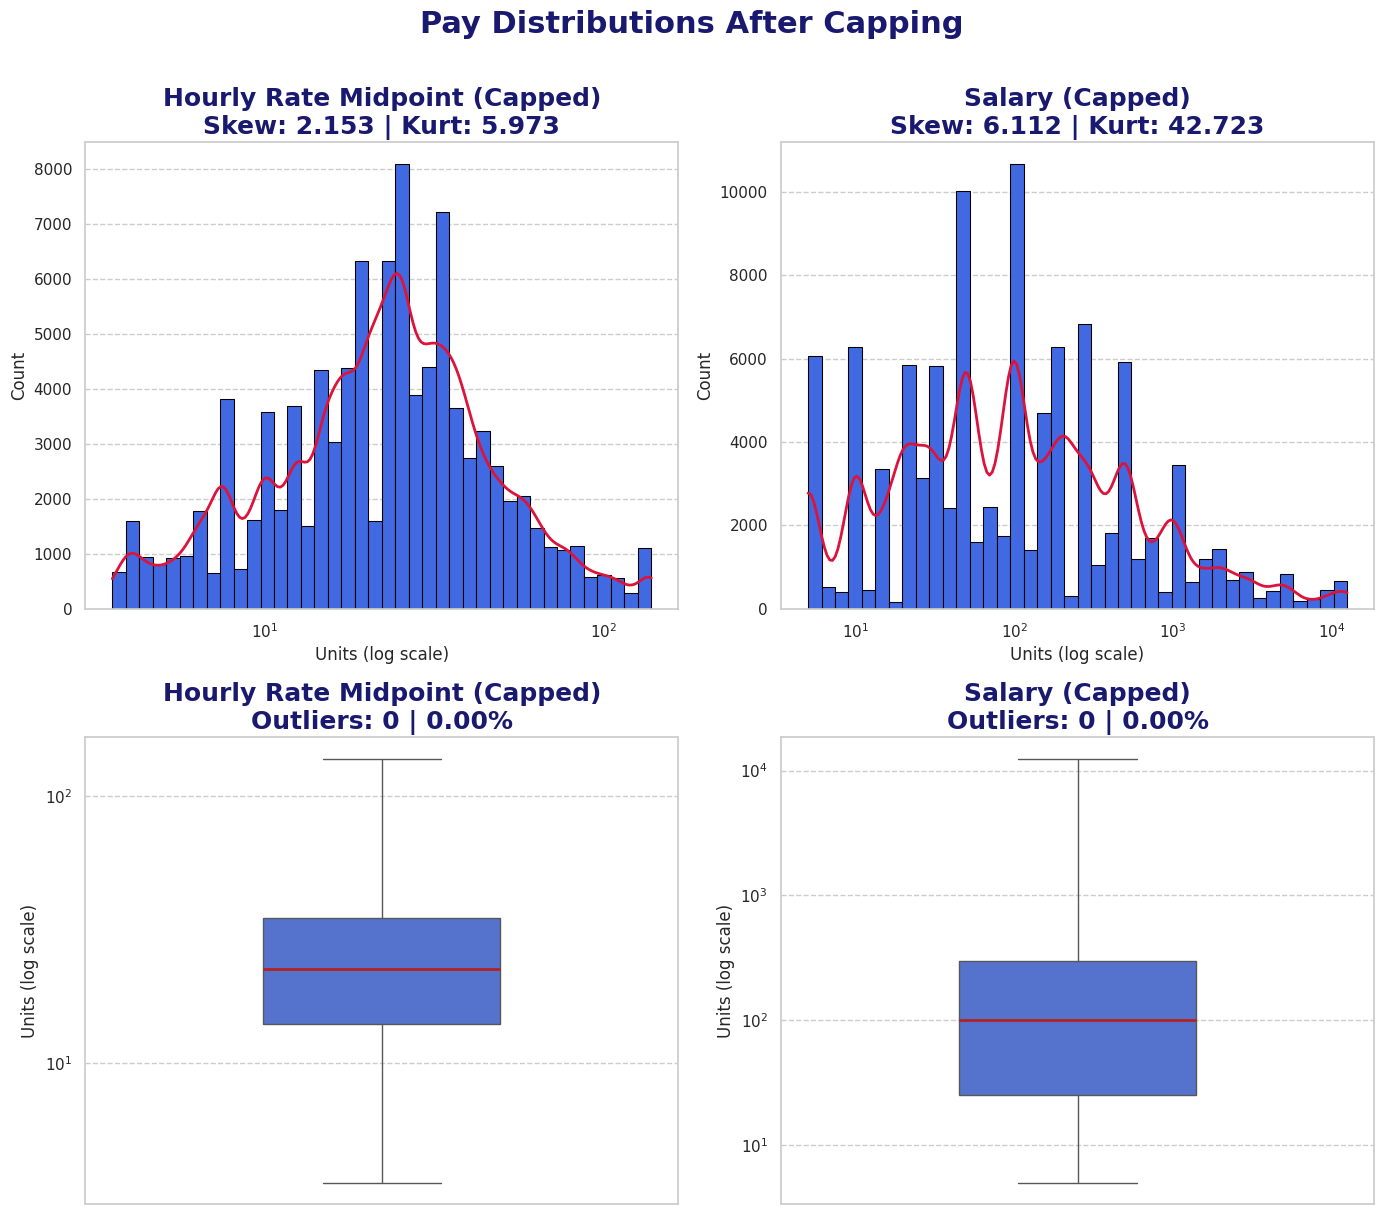

2026-11-23 16:48:40,582 - job_market_analysis - INFO - Capped pay distributions rendered — extreme values removed from both pay columns


In [45]:
subsection_header("Univariate — Pay Distributions After Capping")

capped_view = pd.DataFrame({
    "hourly_rate_mid_capped": df_refined.loc[is_hourly & (df_refined["pay_status"] == "Stated"), "hourly_rate_mid_capped"],
    "budget_capped": df_refined.loc[~is_hourly, "budget_capped"],
})
capped_labels = {"hourly_rate_mid_capped": "Hourly Rate Midpoint (Capped)", "budget_capped": "Salary (Capped)"}
capped_bounds = {"hourly_rate_mid_capped": OUTLIER_BOUNDS["hourly_rate_mid"], "budget_capped": OUTLIER_BOUNDS["budget"]}

info_box(f"<b>{len(capped_view.columns)} capped pay features</b> displayed as histograms and boxplots to confirm the extreme values are gone.")
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle("Pay Distributions After Capping", fontsize=22, color=PLOT_COLOR, fontweight="bold", y=1.01)
fig.subplots_adjust(wspace=0.3, hspace=0.4)

for i, col in enumerate(capped_view.columns):
    vals = capped_view[col].dropna()
    lower, upper = capped_bounds[col]
    outliers = vals[(vals > upper * (1 + 1e-9)) | (vals < lower * (1 - 1e-9))]
    sk_val, kt_val = skew(vals), kurtosis(vals)

    sns.histplot(vals, kde=True, color="crimson", facecolor="royalblue", edgecolor="black", bins=40, log_scale=True, ax=axes[0, i], line_kws={"linewidth": 2})
    axes[0, i].set_title(f"{capped_labels[col]}\nSkew: {sk_val:.3f} | Kurt: {kt_val:.3f}", fontweight="bold", fontsize=18)
    axes[0, i].set_xlabel("Units (log scale)")
    axes[0, i].grid(True, linestyle="--", alpha=0.4)
    axes[0, i].grid(axis="x", visible=False)
    sns.boxplot(y=vals, ax=axes[1, i], color="royalblue", width=0.4, log_scale=True,
                medianprops=dict(color="firebrick", linewidth=2),
                flierprops=dict(marker="o", markerfacecolor="crimson", markersize=5, alpha=0.6))
    axes[1, i].set_title(f"{capped_labels[col]}\nOutliers: {len(outliers):,} | {len(outliers) / len(vals) * 100:.2f}%", fontweight="bold", fontsize=18)
    axes[1, i].set_ylabel("Units (log scale)")
    axes[1, i].grid(True, linestyle="--", alpha=0.4, axis="y")

plt.tight_layout()
plt.savefig("Assets/eda_univariate_pay_after_capping.png", dpi=150, bbox_inches="tight")
plt.show()

logger.info("Capped pay distributions rendered — extreme values removed from both pay columns")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Pay Distributions After Capping:**

- **Extreme values are gone:** both boxplots show 0 outliers. Hourly midpoints now run from 3.55 to 138.34 units and salaries from 5 to 12,470.76.
- **Shape is much tamer:** hourly skew falls from 6.514 to 2.153 and kurtosis from 84.132 to 5.973. Salary skew falls from 54.324 to 6.112 and kurtosis from 3,272.939 to 42.723. Both remain right-skewed on the original scale, as pay typically is.
- **Piles at the bounds:** the last bar of each histogram, and the first bar of the hourly one, are capped values stacking at the fence. That is expected and marked by `pay_capped`.
- **Round amounts dominate salaries:** the peaks sit at figures such as 50, 100, 500 and 1,000, while hourly rates concentrate between roughly 20 and 40 units.
- **Consequence:** the capped columns are safe for country averages and keyword comparisons. Medians remain the main statistic.

<hr style="width:60%; margin:auto;">

</div>

### 📌 Bivariate — Daily Postings by Contract Type

<div style="margin-left: 20px; max-width: 90%">

Two variables, the posting day and the contract type. This shows whether Freelancer and Permanent postings follow the same weekly rhythm.

</div>

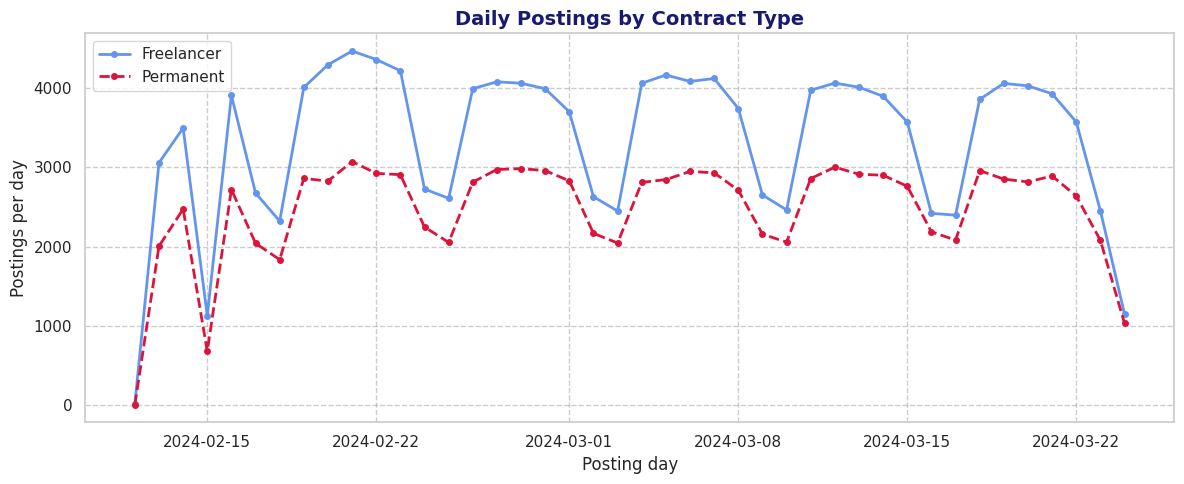

2026-11-23 16:48:41,182 - job_market_analysis - INFO - Daily volume by contract type plotted — full days=39, mean Freelancer share=57.3%


In [46]:
subsection_header("Bivariate — Daily Postings by Contract Type")

info_box("<b>Daily postings</b> of the two contract types compared over the high-volume window.")

in_window = df_refined.loc[~df_refined["backdated_posting"]]
daily_by_type = (in_window.groupby(["posted_date", "worker_type"]).size().unstack(fill_value=0)
                 .reindex(pd.date_range(in_window["posted_date"].min(), in_window["posted_date"].max()), fill_value=0))

fig, ax = plt.subplots(figsize=(12, 5))
for contract, color, style in [("Freelancer", "cornflowerblue", "-"), ("Permanent", "crimson", "--")]:
    ax.plot(daily_by_type.index, daily_by_type[contract], color=color, linestyle=style, linewidth=2, marker="o", markersize=4, label=contract)
ax.set_title("Daily Postings by Contract Type")
ax.set_xlabel("Posting day")
ax.set_ylabel("Postings per day")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()
plt.tight_layout()
plt.savefig("Assets/eda_bivariate_volume_by_contract.png", dpi=150, bbox_inches="tight")
plt.show()

daily_total = daily_by_type.sum(axis=1)
full_days = daily_total >= 0.5 * daily_total.median()                  # skip the part-collected edge days
freelancer_share = (daily_by_type["Freelancer"] / daily_total * 100)[full_days]
is_weekend = freelancer_share.index.dayofweek >= 5
info_box(
    f"On the {int(full_days.sum())} full days, Freelancer postings are on average {freelancer_share.mean():.1f}% of the day's total "
    f"(range {freelancer_share.min():.1f}% to {freelancer_share.max():.1f}%): {freelancer_share[~is_weekend].mean():.1f}% on weekdays and {freelancer_share[is_weekend].mean():.1f}% on weekends.")
logger.info(f"Daily volume by contract type plotted — full days={int(full_days.sum())}, mean Freelancer share={freelancer_share.mean():.1f}%")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Daily Postings by Contract Type:**

- **Same weekly rhythm:** both contract types rise on weekdays and fall at weekends in step. Freelancer postings run at about 3,900 to 4,500 a day on weekdays and about 2,400 to 2,700 at weekends. Permanent postings run at about 2,800 to 3,050 on weekdays and 2,050 to 2,250 at weekends.
- **Freelancer is the larger type every day:** on the 39 full days, Freelancer postings are 57.3% of the day's total on average, ranging from 52.5% to 60.4%.
- **Weekends tilt toward Permanent:** the Freelancer share is 58.3% on weekdays and 54.8% on weekends, so the weekend dip is steeper for Freelancer postings.
- **Edge days:** the first days (12 Feb nearly empty, 15 Feb a dip) and the last day (24 Mar, about 1,150 Freelancer and 1,050 Permanent) are low for both types, which supports reading them as incomplete collection.
- **Consequence:** forecasts need a weekday effect and the same edge-day decision for both contract types.

<hr style="width:60%; margin:auto;">

</div>

### 📌 Bivariate — Weekday by Contract Type

<div style="margin-left: 20px; max-width: 90%">

Two variables, the day of the week and the contract type. For each contract type, the heatmap shows what share of its postings falls on each weekday, so the weekly rhythm of Freelancer and Permanent postings can be compared directly.

</div>

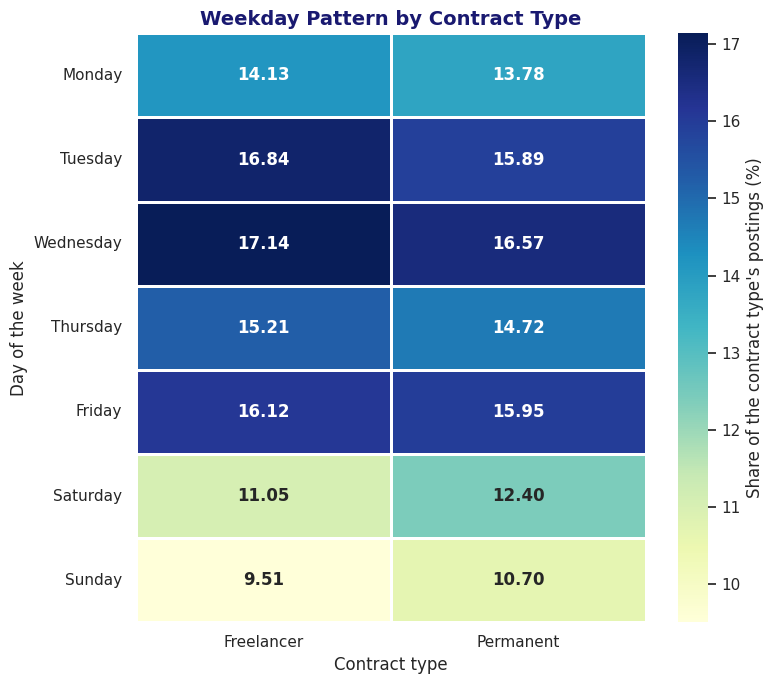

2026-11-23 16:48:41,816 - job_market_analysis - INFO - Weekday by contract type plotted — weekend share={'Freelancer': 20.56, 'Permanent': 23.1}


In [47]:
subsection_header("Bivariate — Weekday by Contract Type")

in_window = df_refined.loc[~df_refined["backdated_posting"]]
weekday_mix = (pd.crosstab(in_window["day_of_week"], in_window["worker_type"], normalize="columns").mul(100)
               .reindex(DAY_ORDER)[["Freelancer", "Permanent"]])

info_box("<b>2 variables</b> (day of the week and contract type) displayed as a heatmap of each contract type's postings by weekday, in the high-volume window.")

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(weekday_mix, annot=True, fmt=".2f", cmap="YlGnBu", linewidths=1, linecolor="white",
            cbar_kws={"label": "Share of the contract type's postings (%)"}, annot_kws={"fontsize": 12, "fontweight": "bold"}, ax=ax)
ax.set_title("Weekday Pattern by Contract Type")
ax.set_xlabel("Contract type")
ax.set_ylabel("Day of the week")
plt.tight_layout()
plt.savefig("Assets/eda_bivariate_weekday_by_contract.png", dpi=150, bbox_inches="tight")
plt.show()

weekend_gap = weekday_mix.loc[["Saturday", "Sunday"]].sum()
info_box(
    "Busiest day — " + "; ".join(f"{contract}: {weekday_mix[contract].idxmax()} ({weekday_mix[contract].max():.2f}%)" for contract in weekday_mix.columns) + ". "
    "Weekend share — " + "; ".join(f"{contract}: {share:.2f}%" for contract, share in weekend_gap.items()) + ".")
logger.info(f"Weekday by contract type plotted — weekend share={weekend_gap.round(2).to_dict()}")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Weekday by Contract Type:**

- **Same weekly shape:** both contract types peak on Wednesday (Freelancer 17.14%, Permanent 16.57%) and are lowest on Sunday (9.51% and 10.70%).
- **Monday is the weakest weekday:** 14.13% for Freelancer and 13.78% for Permanent, against 15.21% to 17.14% for Tuesday to Friday.
- **Permanent postings are flatter:** weekends hold 23.10% of Permanent postings against 20.56% of Freelancer postings, so Freelancer postings drop more at weekends.
- **Consequence:** forecasts need a day-of-week effect, and it should be allowed to differ by contract type.

<hr style="width:60%; margin:auto;">

</div>

### 📌 Task 4: Bivariate — Average Hourly Rate by Country

<div style="margin-left: 20px; max-width: 90%">

An interactive world map of the average hourly rate offered by clients in each country. Only stated hourly rates are used, with the capped midpoint, so filled values do not feed the averages. Others is left out because it is not a country, and a country needs a minimum number of stated postings so that small samples do not drive the colours. Hover over a country for its average, median and number of postings.

</div>

In [48]:
subsection_header("Task 4: Bivariate — Average Hourly Rate by Country")

MIN_POSTINGS = 30      # a country needs at least this many stated hourly postings to be shown
NAME_FIXES = {"Macedonia": "MKD", "Turkey": "TUR"}       # names in the data that pycountry does not recognise

def iso3_code(country_name):
    """ISO alpha-3 code for the world map, or None when the name cannot be matched."""
    if country_name in NAME_FIXES:
        return NAME_FIXES[country_name]
    try:
        return pycountry.countries.lookup(country_name).alpha_3
    except LookupError:
        return None

stated_hourly = df_refined.loc[df_refined["is_hourly"] & (df_refined["pay_status"] == "Stated") & (df_refined["country"] != "Others")]
country_rates = (stated_hourly.groupby("country")["hourly_rate_mid_capped"]
                 .agg(Postings="size", Average="mean", Median="median").reset_index())
country_rates["iso3"] = country_rates["country"].map(iso3_code)
shown = country_rates[(country_rates["Postings"] >= MIN_POSTINGS) & country_rates["iso3"].notna()].copy()
unmatched = country_rates.loc[(country_rates["Postings"] >= MIN_POSTINGS) & country_rates["iso3"].isna(), "country"].tolist()

info_box(f"<b>Average hourly rate by country</b> displayed as an interactive world map. Only stated rates are used, Others is excluded because it is not a country, "
         f"and a country needs at least {MIN_POSTINGS} stated hourly postings.")

rate_map = px.choropleth(shown, locations="iso3", color="Average", hover_name="country", hover_data={"iso3": False, "Average": ":.2f", "Median": ":.2f", "Postings": ":,"},
                         color_continuous_scale="YlOrRd", labels={"Average": "Average rate (units)"})
rate_map.update_layout(title=dict(text="Average Hourly Rate by Client Country (units per hour)", x=0.5, font=dict(size=22, color=PLOT_COLOR)),
                       geo=dict(showframe=False, showcoastlines=True, projection_type="natural earth"), margin=dict(l=0, r=0, t=70, b=0), height=560)
rate_map.write_html("Assets/task4_bivariate_hourly_rate_map.html")
rate_map.show()

info_box(
    f"{len(shown)} of {len(country_rates)} countries have at least {MIN_POSTINGS} stated hourly postings and are mapped"
    + (f"; {len(unmatched)} could not be matched to a map code ({', '.join(unmatched)})" if unmatched else "")
    + f". Highest average: {shown.loc[shown['Average'].idxmax(), 'country']} ({shown['Average'].max():.2f} units); lowest: {shown.loc[shown['Average'].idxmin(), 'country']} ({shown['Average'].min():.2f} units).")
logger.info(f"Country rate map built — countries shown={len(shown)}, unmatched={unmatched}")

2026-11-23 16:48:45,397 - job_market_analysis - INFO - Country rate map built — countries shown=91, unmatched=[]


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Average Hourly Rate by Country (Map):**

- **Coverage:** 91 of 191 countries have at least 30 stated hourly postings and are coloured. The rest are left blank, and "Others" is excluded because it is not a country.
- **Range:** averages run from 15.40 units (South Korea) to 42.77 units (Malaysia), about 2.8 times apart.
- **Reference point:** the United States, with by far the most postings, averages 31.55 units from 46,620 stated postings.
- **Consequence:** hovering shows the average, median and number of postings for each country, and the recommender will show the posting count beside any country average.

<hr style="width:60%; margin:auto;">

</div>

### 📌 Task 4: Bivariate — Highest and Lowest Paying Countries

<div style="margin-left: 20px; max-width: 90%">

The same averages as a ranking: the ten countries with the highest and the ten with the lowest average hourly rate. The number of stated postings behind each bar is shown beside it, so a high average resting on few postings is visible at once.

</div>

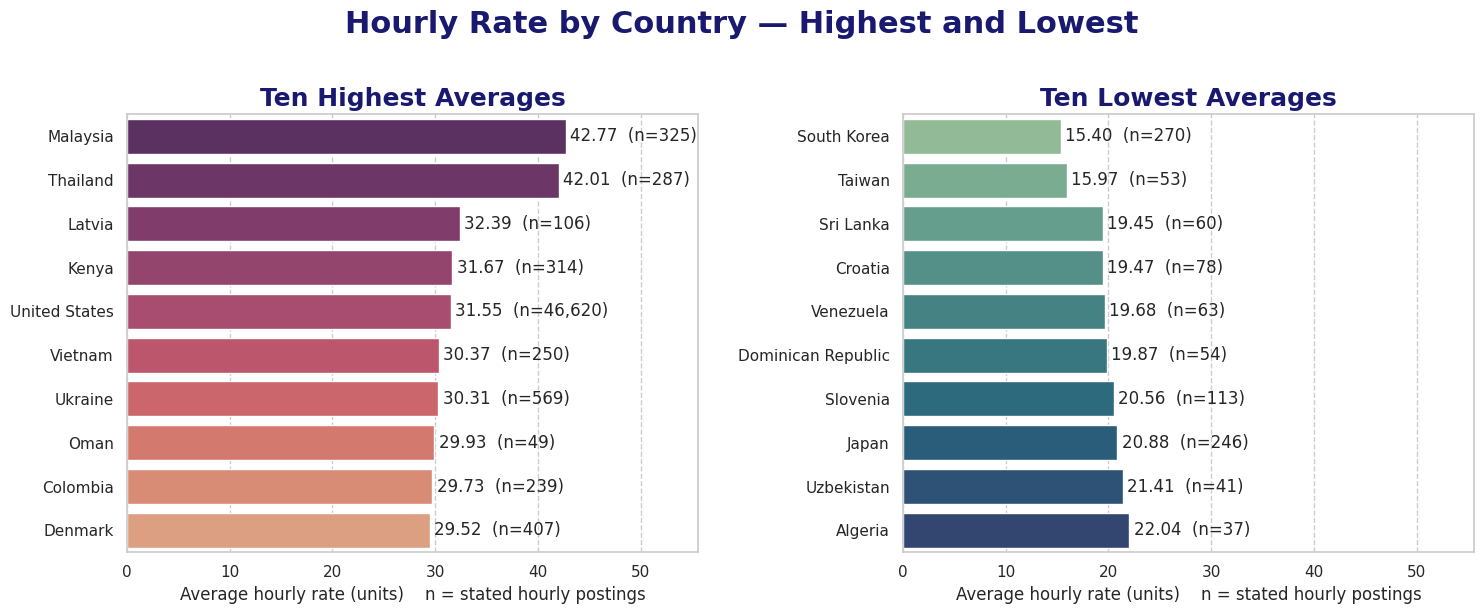

2026-11-23 16:48:46,479 - job_market_analysis - INFO - Country rate ranking plotted — top=Malaysia, bottom=South Korea


In [49]:
subsection_header("Task 4: Bivariate — Highest and Lowest Paying Countries")

ranked = shown.sort_values("Average", ascending=False)
top_ten, bottom_ten = ranked.head(10), ranked.tail(10).sort_values("Average")

info_box(f"<b>2 rankings</b> displayed as bar charts: the ten highest and the ten lowest average hourly rates among the {len(shown)} mapped countries.")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle("Hourly Rate by Country — Highest and Lowest", fontsize=22, color=PLOT_COLOR, fontweight="bold", y=1.02)
fig.subplots_adjust(wspace=0.45)
for ax, data, palette, title in [(axes[0], top_ten, "flare_r", "Ten Highest Averages"), (axes[1], bottom_ten, "crest", "Ten Lowest Averages")]:
    sns.barplot(x=data["Average"], y=data["country"], hue=data["country"], palette=palette, legend=False, ax=ax)
    for container, avg, n in zip(ax.containers, data["Average"], data["Postings"]):          # one container per country because of the hue
        ax.bar_label(container, labels=[f"{avg:.2f}  (n={n:,})"], padding=3)
    ax.set_title(title, fontweight="bold", fontsize=18)
    ax.set_xlabel("Average hourly rate (units)    n = stated hourly postings")
    ax.set_ylabel("")
    ax.set_xlim(0, ranked["Average"].max() * 1.3)
    ax.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("Assets/task4_bivariate_country_rate_ranking.png", dpi=150, bbox_inches="tight")
plt.show()

us_row = ranked[ranked["country"] == "United States"]
info_box(
    f"Spread between the highest and lowest mapped average: {ranked['Average'].max():.2f} vs {ranked['Average'].min():.2f} units (n shown beside each bar is the number of stated hourly postings)."
    + (f" United States: {us_row['Average'].iloc[0]:.2f} units from {int(us_row['Postings'].iloc[0]):,} postings." if len(us_row) else ""))
logger.info(f"Country rate ranking plotted — top={top_ten['country'].iloc[0]}, bottom={bottom_ten['country'].iloc[0]}")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Highest and Lowest Paying Countries:**

- **Two countries stand apart at the top:** Malaysia (42.77 units, 325 postings) and Thailand (42.01, 287) are about 10 units above third-placed Latvia (32.39).
- **The rest of the top ten is a tight band:** from Latvia down to Denmark (29.52) the averages differ by under 3 units, and the United States (31.55) sits inside it with by far the most postings (46,620).
- **The bottom is led by East Asia:** South Korea (15.40) and Taiwan (15.97) are the lowest, and Japan (20.88) is also in the bottom ten.
- **Posting counts vary a lot:** from 37 (Algeria) to 46,620 (United States). Averages built on under about 60 postings, such as Oman (49), Uzbekistan (41) and Algeria (37), are less reliable than those from hundreds.
- **What the average means:** it reflects what clients in that country offer, not where freelancers live.

<hr style="width:60%; margin:auto;">

</div>

### 📌 Task 4: Bivariate — Country Volume vs Average Hourly Rate

<div style="margin-left: 20px; max-width: 90%">

Does a country that posts more jobs also pay more or less? Each point is a country, with its number of stated hourly postings against its average hourly rate. The posting axis is on a log scale because country volumes run from the minimum shown up to tens of thousands, and on a plain axis most countries would be squeezed into the left edge.

</div>

In [50]:
def place_labels(fig, ax, xs, ys, names, radii_pt, fontsize=10, all_xs=None, all_ys=None, all_radii=None):
    """Put each label beside its point on the side where it overlaps no other label or point."""
    fig.canvas.draw()
    scale = fig.dpi / 72
    obstacle_xs, obstacle_ys, obstacle_radii = (xs, ys, radii_pt) if all_xs is None else (all_xs, all_ys, all_radii)     # points a label must not cover
    obstacle_px = ax.transData.transform(np.column_stack([obstacle_xs, obstacle_ys]))
    circles = [(x, y, r * scale) for (x, y), r in zip(obstacle_px, obstacle_radii)]
    placed = []
    def hits(box):
        if any(box.overlaps(other) for other in placed):
            return True
        return any(box.x0 < cx + cr and box.x1 > cx - cr and box.y0 < cy + cr and box.y1 > cy - cr for cx, cy, cr in circles)
    for index in np.argsort(radii_pt)[::-1]:
        r = radii_pt[index] + 4
        options = [(r, 0, "left", "center"), (-r, 0, "right", "center"), (0, r, "center", "bottom"), (0, -r, "center", "top"),
                   (r, r, "left", "bottom"), (-r, r, "right", "bottom"), (r, -r, "left", "top"), (-r, -r, "right", "top"),
                   (r, 2.2 * fontsize, "left", "bottom"), (r, -2.2 * fontsize, "left", "top"), (-r, 2.2 * fontsize, "right", "bottom"), (-r, -2.2 * fontsize, "right", "top"),
                   (0, r + 45, "center", "bottom"), (0, -r - 45, "center", "top"), (r + 30, r + 45, "left", "bottom"), (-r - 30, r + 45, "right", "bottom"),
                   (r + 30, -r - 45, "left", "top"), (-r - 30, -r - 45, "right", "top")]
        chosen = None
        for number, (dx, dy, ha, va) in enumerate(options):
            text = ax.annotate(names[index], (xs[index], ys[index]), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va, fontsize=fontsize)
            box = text.get_window_extent(fig.canvas.get_renderer())
            if not hits(box):
                chosen = box
                if number >= 8:                  # label had to move away from its point, so connect it with a thin line
                    ax.annotate("", (xs[index], ys[index]), xytext=(dx, dy), textcoords="offset points", arrowprops=dict(arrowstyle="-", color="grey", linewidth=0.8, shrinkA=0, shrinkB=0))
                break
            text.remove()
        if chosen is None:                      # no free spot: keep the first option rather than drop the label
            dx, dy, ha, va = options[0]
            text = ax.annotate(names[index], (xs[index], ys[index]), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va, fontsize=fontsize)
            chosen = text.get_window_extent(fig.canvas.get_renderer())
        placed.append(chosen)

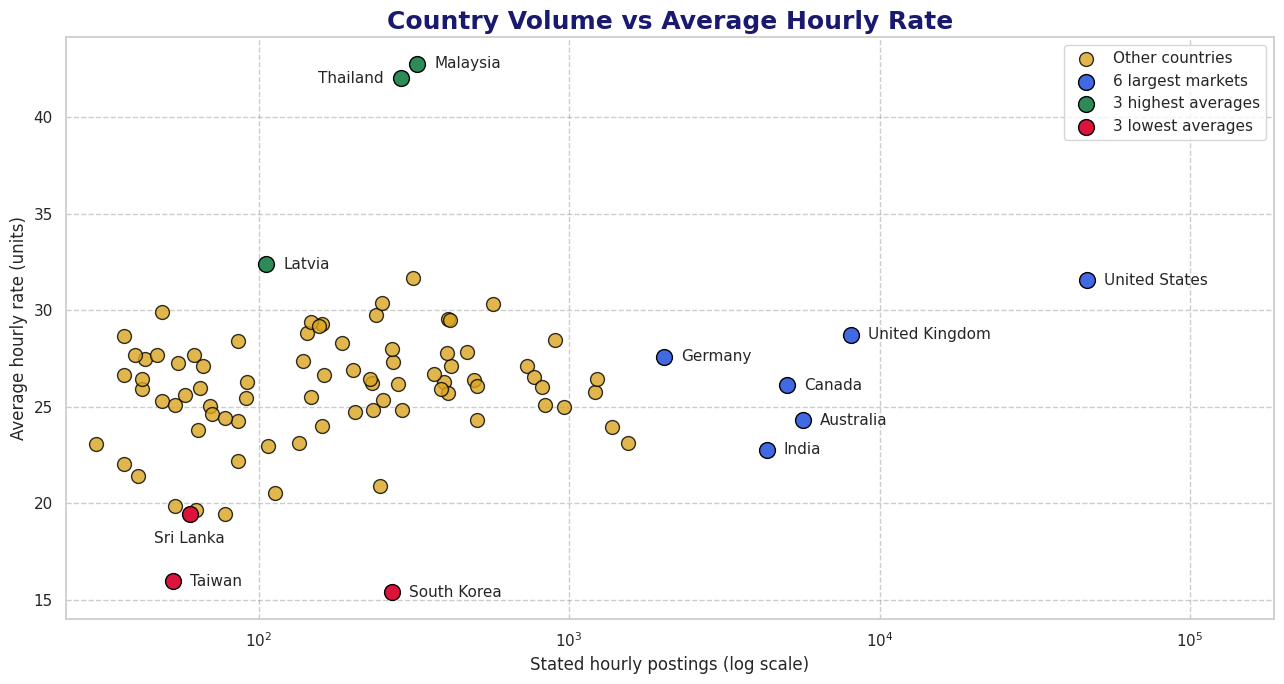

2026-11-23 16:48:47,631 - job_market_analysis - INFO - Country volume vs rate plotted — countries=91, rank correlation=0.19


In [51]:
subsection_header("Task 4: Bivariate — Country Volume vs Average Hourly Rate")

info_box(f"<b>2 numerical features</b> across {len(shown)} countries with at least {MIN_POSTINGS} stated hourly postings: postings (log scale) against average hourly rate.")

fig, ax = plt.subplots(figsize=(13, 7))
highlight_groups = {"6 largest markets": (shown.nlargest(6, "Postings"), "royalblue"),
                    "3 highest averages": (shown.nlargest(3, "Average"), "seagreen"),
                    "3 lowest averages": (shown.nsmallest(3, "Average"), "crimson")}
labelled = pd.concat([frame for frame, _ in highlight_groups.values()]).drop_duplicates("country")
ax.scatter(shown["Postings"], shown["Average"], color="goldenrod", s=100, edgecolor="black", alpha=0.8, label="Other countries")
for group_name, (frame, color) in highlight_groups.items():
    ax.scatter(frame["Postings"], frame["Average"], color=color, s=130, edgecolor="black", zorder=3, label=group_name)
ax.set_xscale("log")
ax.set_xlim(shown["Postings"].min() * 0.8, shown["Postings"].max() * 4)       # room on the right so the largest label is not cut off
ax.set_title("Country Volume vs Average Hourly Rate", fontsize=18, fontweight="bold", color=PLOT_COLOR)
ax.set_xlabel("Stated hourly postings (log scale)")
ax.set_ylabel("Average hourly rate (units)")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc="upper right", fontsize=11)
plt.tight_layout()
place_labels(fig, ax, labelled["Postings"].values, labelled["Average"].values, labelled["country"].tolist(), np.full(len(labelled), 8.0), 11,
             shown["Postings"].values, shown["Average"].values, np.full(len(shown), 8.0))
plt.savefig("Assets/task4_bivariate_country_volume_vs_rate.png", dpi=150, bbox_inches="tight")
plt.show()

relation = shown["Postings"].corr(shown["Average"], method="spearman")
info_box(f"Rank correlation between a country's posting volume and its average rate: {relation:.2f} across {len(shown)} countries.")
logger.info(f"Country volume vs rate plotted — countries={len(shown)}, rank correlation={relation:.2f}")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Country Volume vs Average Hourly Rate:**

- **How to read it:** each dot is a country with at least 30 stated hourly postings. `Blue` marks the six largest markets, `green` the three highest averages, `red` the three lowest and `yellow` all other countries.
- **Volume does not determine rate:** countries with thousands of postings have averages between about 22 and 32 units an hour, so a large market is not automatically a high-paying one.
- **The largest markets:** the United States is by far the biggest and pays about 31.5. The United Kingdom (about 28.7) and Germany (about 27.6) sit above Canada (about 26.1), Australia (about 24.3) and India (about 22.8).
- **Extremes come from small markets:** Malaysia and Thailand are above 42 units with only a few hundred postings each, while South Korea (about 15.4) and Taiwan (about 16.0) are at the bottom.
- **Spread narrows as volume grows:** countries with a few dozen to a few hundred postings range from about 15 to 43, while those with thousands fall within about 22 to 32. Averages from small samples swing more by chance, so extreme country averages should be read with their posting counts.
- **Weak link between volume and rate:** the rank correlation across 91 countries is 0.19, so bigger markets are only slightly more likely to pay more.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 1: Bivariate — Pay by Job Category

<div style="margin-left: 20px; max-width: 90%">

Which categories pay more, and how widely does pay vary inside each one? Each box covers the middle half of capped pay in a category, the red line is the median and the whiskers reach the 5th and 95th percentiles. Freelancer hourly rates and Permanent salaries are shown separately, never combined.

</div>

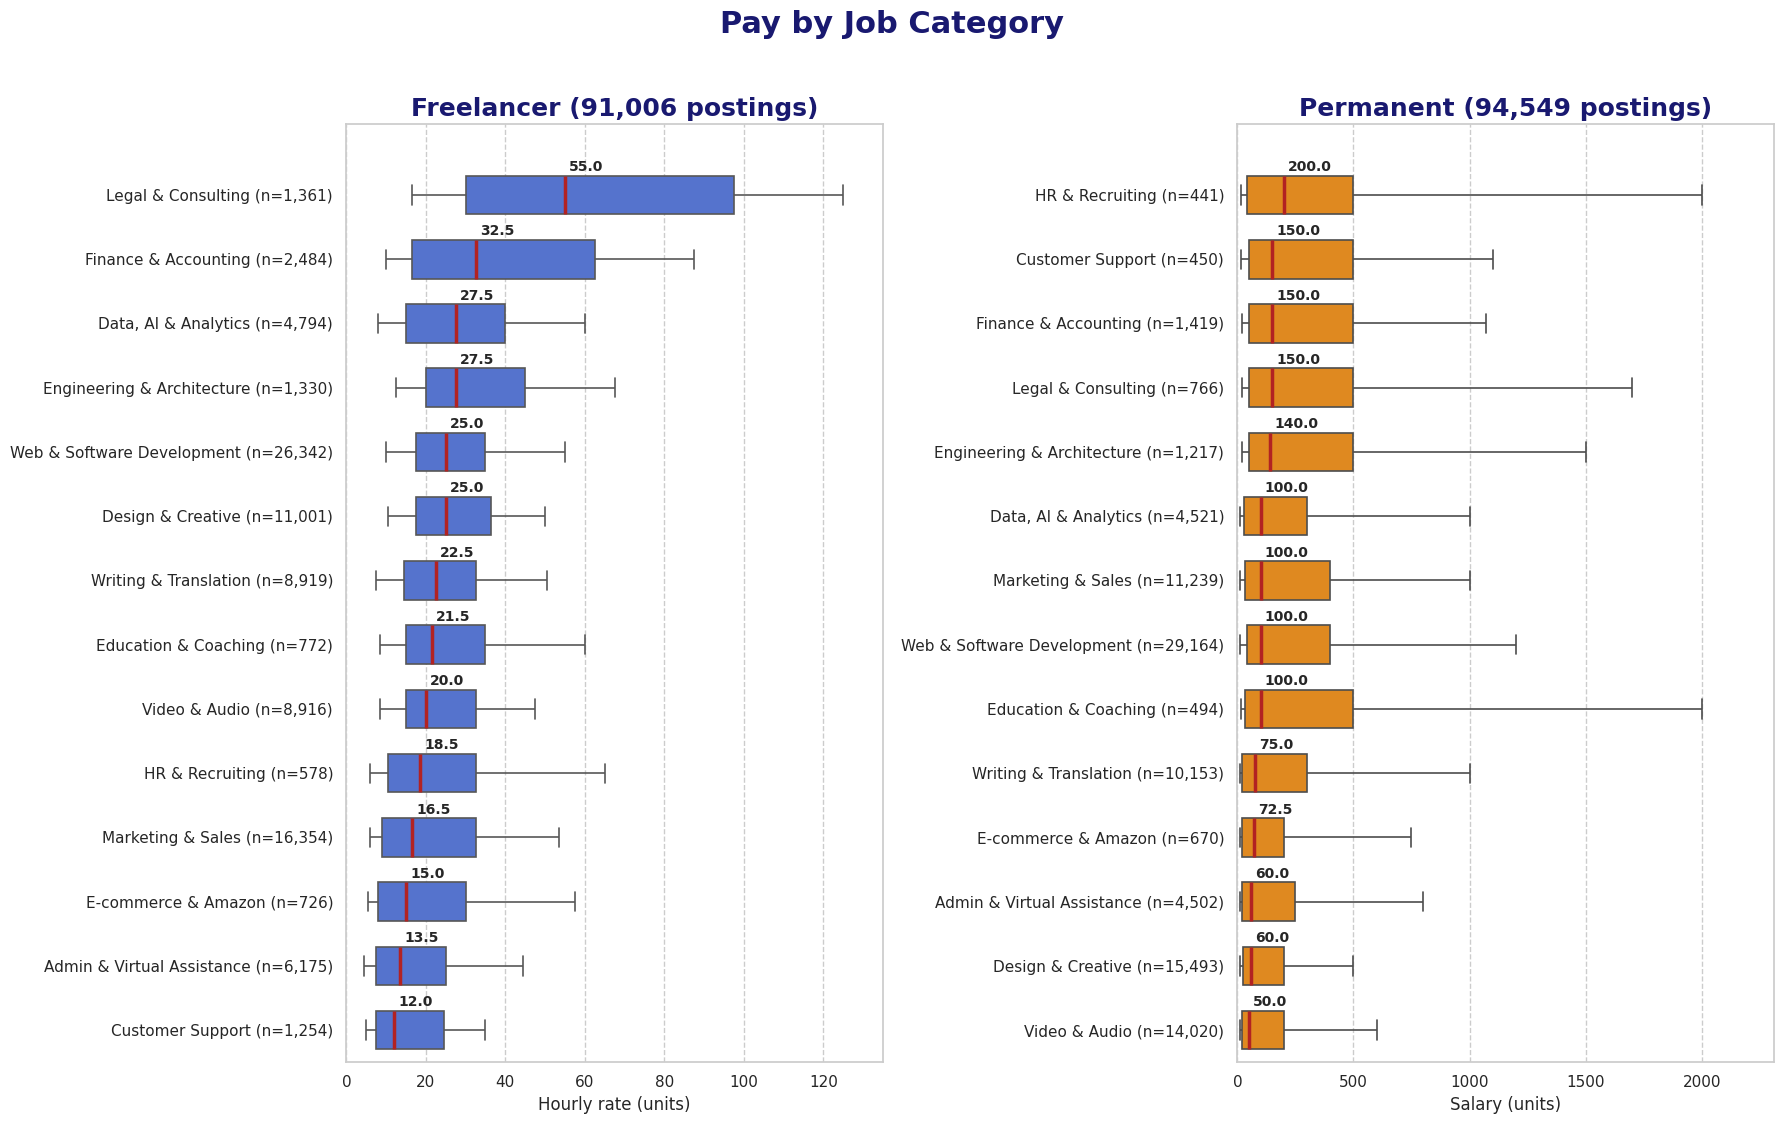

2026-11-23 16:48:50,410 - job_market_analysis - INFO - Pay by job category plotted — highest median: {'Freelancer': 'Legal & Consulting', 'Permanent': 'HR & Recruiting'}


In [52]:
subsection_header("Task 1: Bivariate — Pay by Job Category")

pay_views = {
    "Freelancer": (df_refined.loc[(df_refined["worker_type"] == "Freelancer") & (df_refined["pay_status"] == "Stated")].rename(columns={"hourly_rate_mid_capped": "pay"}), "royalblue", "Hourly rate (units)"),
    "Permanent": (df_refined.loc[(df_refined["worker_type"] == "Permanent") & (df_refined["budget_capped"] > 0)].rename(columns={"budget_capped": "pay"}), "darkorange", "Salary (units)"),
}
info_box("<b>1 categorical and 1 numerical feature</b> per contract type: capped pay across job categories, ordered by median. "
         "General / Unspecified is left out because it is not a job type, and the axis stops at the widest 90th percentile.")

fig, axes = plt.subplots(1, 2, figsize=(18, 11))
fig.suptitle("Pay by Job Category", fontsize=22, color=PLOT_COLOR, fontweight="bold", y=1.02)
fig.subplots_adjust(wspace=0.6)
medians = {}
for ax, (contract, (rows, color, label)) in zip(axes, pay_views.items()):
    rows = rows.loc[rows["job_category"] != "General / Unspecified"]
    order = rows.groupby("job_category")["pay"].median().sort_values(ascending=False)
    counts = rows["job_category"].value_counts()
    medians[contract] = order
    sns.boxplot(data=rows, x="pay", y="job_category", order=order.index, color=color, width=0.6, whis=(10, 90), showfliers=False, linewidth=1.2,
                medianprops={"color": "firebrick", "linewidth": 2.5}, ax=ax)
    ax.set_xlim(left=0, right=rows.groupby("job_category")["pay"].quantile(0.9).max() * 1.08)
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels([f"{category} (n={counts[category]:,})" for category in order.index])
    for position, value in enumerate(order.values):
       ax.annotate(f"{value:,.1f}", (value, position), xytext=(3, 15), textcoords="offset points", ha="left", va="bottom", fontsize=10, fontweight="bold")
    ax.set_ylim(len(order) - 0.5, -1.1)        # headroom above the first box for its median label
    ax.set_title(f"{contract} ({len(rows):,} postings)", fontweight="bold", fontsize=18)
    ax.set_xlabel(label)
    ax.set_ylabel("")
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig("Assets/task1_bivariate_pay_by_job_category.png", dpi=150, bbox_inches="tight")
plt.show()

info_box("Median pay — " + "; ".join(f"{contract}: highest {order.index[0]} ({order.iloc[0]:,.2f}), lowest {order.index[-1]} ({order.iloc[-1]:,.2f})" for contract, order in medians.items()) + ".")
logger.info(f"Pay by job category plotted — highest median: { {contract: order.index[0] for contract, order in medians.items()} }")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Pay by Job Category:**

- **Freelancer ranking:** Legal & Consulting is highest at a median of 55.0 units an hour (n=1,361), followed by Finance & Accounting (32.5), then Data, AI & Analytics and Engineering & Architecture (27.5 each). Customer Support is lowest at 12.0, with Admin & Virtual Assistance at 13.5 and E-commerce & Amazon at 15.0.
- **Spread differs a lot:** the Legal & Consulting box runs from about 30 to 98 units, far wider than the large categories. Web & Software Development, Design & Creative and Writing & Translation each span roughly 15 to 36, so pay in the big markets is tightly bunched around the 22 to 25 range.
- **Permanent ranking:** HR & Recruiting is highest at a median salary of 200.0, then Customer Support, Finance & Accounting and Legal & Consulting at 150.0 and Engineering & Architecture at 140.0. Video & Audio is lowest at 50.0, with Design & Creative and Admin & Virtual Assistance at 60.0.
- **Salary boxes are wide:** the top six Permanent categories all have a 75th percentile of exactly 500, and their whiskers reach 1,000 to 2,000. Within a category, salaries range from very small amounts to many times the median, so the median alone understates the spread.
- **The biggest markets pay in the middle or below:** Web & Software Development (29,164 Permanent postings) has a median of 100.0, while Design & Creative (15,493) and Video & Audio (14,020) sit at 60.0 and 50.0.
- **Rankings differ by contract type:** Customer Support is the lowest hourly category yet joint-second on salary, and HR & Recruiting is low hourly (18.5) but first on salary. This is why the two pay scales are never combined.
- **Small samples:** several top salary medians rest on few postings (HR & Recruiting 441, Customer Support 450, Education & Coaching 494), so those rankings are less stable than the big categories.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 1: Bivariate — Title Keywords vs Pay

<div style="margin-left: 20px; max-width: 90%">

For every title word that appears in enough postings, the median pay of postings containing the word is compared with the median of postings without it. Freelancer hourly rates and Permanent salaries are tested separately and never pooled. Significance uses the Mann-Whitney U test with Benjamini-Hochberg correction, because pay is skewed and hundreds of words are tested at once.

</div>

In [53]:
subsection_header("Task 1: Bivariate — Title Keywords vs Pay")

MIN_WORD_POSTINGS = 200        # a word needs this many postings with stated pay in a contract type to be tested
FILLER_WORDS = {"needed", "need", "looking", "wanted", "required", "seeking", "hire", "hiring", "expert", "specialist", "create", "help", "urgent", "experienced"}
pay_groups = {"Freelancer": df_refined.loc[(df_refined["worker_type"] == "Freelancer") & (df_refined["pay_status"] == "Stated"), ["title_clean", "hourly_rate_mid_capped"]].rename(columns={"hourly_rate_mid_capped": "pay"}),
              "Permanent": df_refined.loc[(df_refined["worker_type"] == "Permanent") & (df_refined["budget_capped"] > 0), ["title_clean", "budget_capped"]].rename(columns={"budget_capped": "pay"})}

keyword_rows = []
for contract, group in pay_groups.items():
    counter = CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS.union(FILLER_WORDS)), binary=True, min_df=MIN_WORD_POSTINGS, token_pattern=r"[a-z][a-z0-9+#]+")
    presence = counter.fit_transform(group["title_clean"]).tocsc()
    pay = group["pay"].to_numpy()
    for position, word in enumerate(counter.get_feature_names_out()):
        has_word = np.zeros(len(group), dtype=bool)
        has_word[presence[:, position].nonzero()[0]] = True
        with_word, without_word = pay[has_word], pay[~has_word]
        keyword_rows.append({"Contract": contract, "Word": word, "Postings": int(has_word.sum()), "Median With": np.median(with_word), "Median Without": np.median(without_word),
                             "Difference (%)": (np.median(with_word) / np.median(without_word) - 1) * 100,
                             "p_value": mannwhitneyu(with_word, without_word, alternative="two-sided").pvalue})

keyword_pay = pd.DataFrame(keyword_rows)
keyword_pay["q_value"] = keyword_pay.groupby("Contract")["p_value"].transform(lambda p: multipletests(p, method="fdr_bh")[1])     # Benjamini-Hochberg within each contract type
keyword_pay["Significant"] = keyword_pay["q_value"] < 0.05

shortlist = (keyword_pay.sort_values("Difference (%)", ascending=False).groupby("Contract", sort=False).apply(lambda g: pd.concat([g.head(5), g.tail(5)]), include_groups=False)
             .reset_index(level=0).sort_values(["Contract", "Difference (%)"], ascending=[True, False]))
display_table = shortlist[["Contract", "Word", "Postings", "Median With", "Median Without", "Difference (%)", "q_value"]].rename(columns={"q_value": "q-value"})
display_table["Postings"] = display_table["Postings"].map("{:,}".format)
display_table["q-value"] = display_table["q-value"].map("{:.2g}".format)
centered_table(display_table, float_format="{:,.2f}")

tested = keyword_pay.groupby("Contract").agg(Words=("Word", "size"), Significant=("Significant", "sum"))
info_box(
    "Each word's median pay in postings that contain it is compared with postings that do not (Mann-Whitney U test, Benjamini-Hochberg corrected). Shown: the five highest and five lowest differences per contract type. "
    + " ".join(f"{contract}: {int(row['Words'])} words tested, {int(row['Significant'])} significant at q < 0.05." for contract, row in tested.iterrows()))
logger.info(f"Keyword pay tests done — {tested.to_dict('index')}")

Contract,Word,Postings,Median With,Median Without,Difference (%),q-value
Freelancer,lawyer,211,92.00,22.50,308.89,4.9e-79
Freelancer,cryptocurrency,233,55.00,22.50,144.44,3.9e-55
Freelancer,tax,640,50.00,22.50,122.22,8.3e-92
Freelancer,consultation,325,47.50,22.50,111.11,6.5e-59
Freelancer,videographer,409,42.50,22.50,88.89,1.6e-102
Freelancer,leads,309,8.00,22.50,-64.44,3.4e-49
Freelancer,appointment,726,8.00,22.50,-64.44,8.7e-131
Freelancer,caller,353,7.50,22.50,-66.67,8.7e-87
Freelancer,virtual,"2,404",7.50,23.00,-67.39,0
Freelancer,va,675,6.50,22.50,-71.11,9.1e-245


2026-11-23 16:49:04,967 - job_market_analysis - INFO - Keyword pay tests done — {'Freelancer': {'Words': 379, 'Significant': 303}, 'Permanent': {'Words': 400, 'Significant': 306}}


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Title Keywords vs Pay:**

- **Scale of the test:** 379 Freelancer words and 400 Permanent words were tested, and 303 and 306 of them are significant after correction. With this many postings almost any difference is significant, so the size of the difference matters more than the q-value.
- **Freelancer premiums:** postings containing "lawyer" (211) have a median of 92.00 units against 22.50 without it, +308.89%. "Cryptocurrency" (+144.44%), "tax" (+122.22%), "consultation" (+111.11%) and "videographer" (+88.89%) follow, so specialist and professional services pay far above the baseline.
- **Freelancer discounts:** "va" (6.50, −71.11%), "caller" (7.50), "virtual" (7.50, −67.39%, the most frequent at 2,404 postings), "appointment" and "leads" (8.00 each). These are support and outreach roles.
- **Permanent premiums:** "ghostwriter" (294 postings) has a median of 750.00 units against 100.00, +650.00%. "Buyer", "expensify", "romance" and "videographer" are all at 500.00, +400.00%.
- **Permanent discounts:** "science" (226 postings) has a median of 5.00 and "speakers" (515) 10.00, with "recording" at 15.00, "translate" and "record" at 20.00. Medians this low point to small one-off budgets.
- **Reading the words:** these are single words in titles, so a word can reflect a recurring template or one repeated client. The model section later checks which of them hold up alongside category and country.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 1: Bivariate — Keyword Pay Premium and Discount

<div style="margin-left: 20px; max-width: 90%">

The words with the largest pay premium and the largest discount, shown as lollipop charts for each contract type. Only words with a statistically significant difference are included, and each bar compares the median pay of postings with the word against postings without it.

</div>

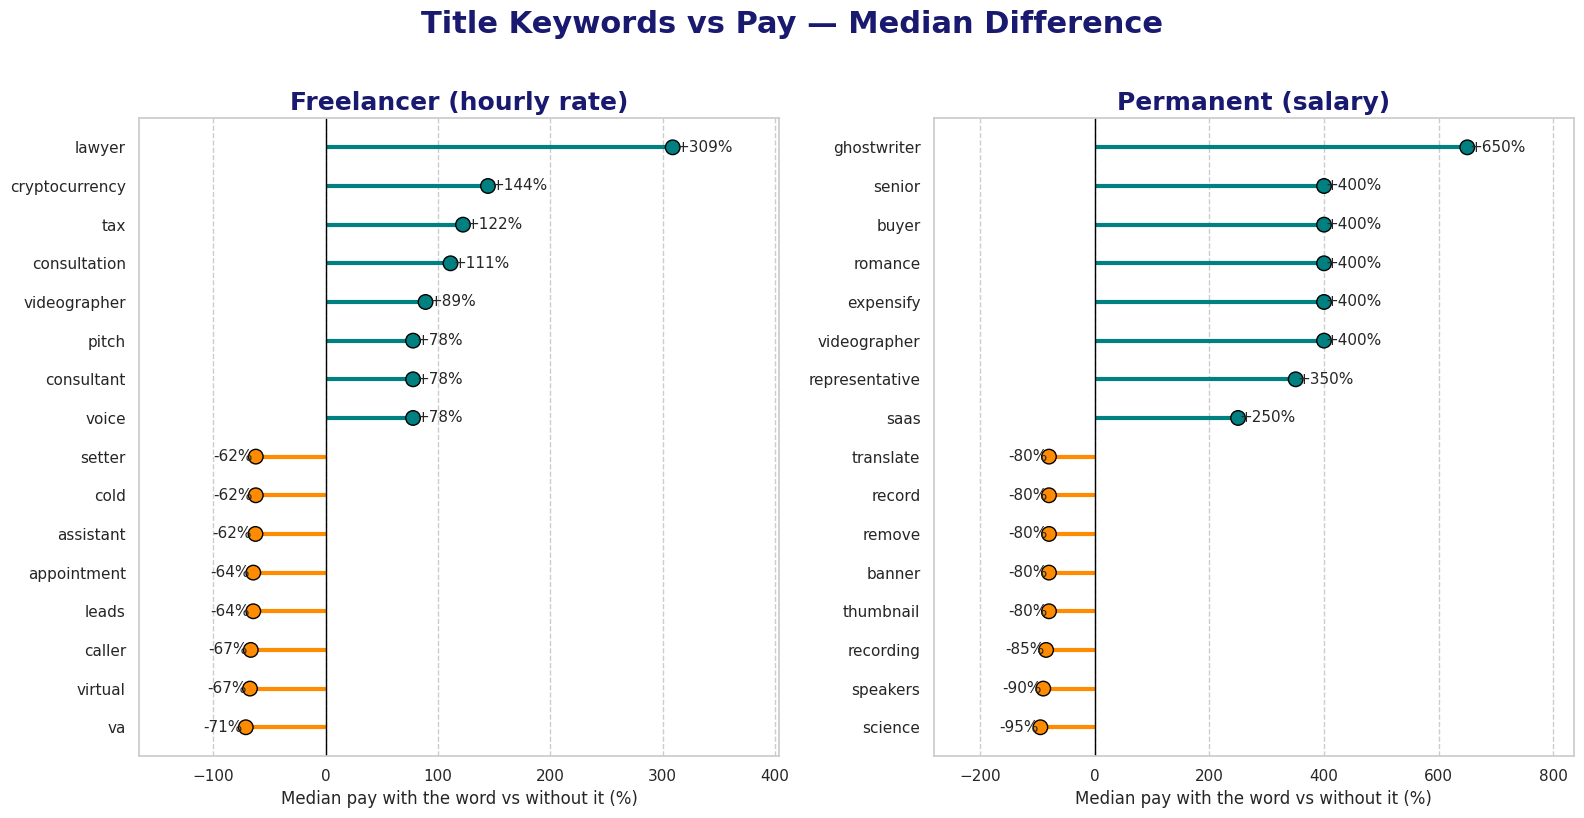

2026-11-23 16:49:06,039 - job_market_analysis - INFO - Keyword pay premium and discount plotted


In [54]:
subsection_header("Task 1: Bivariate — Keyword Pay Premium and Discount")

SHOWN_PER_SIDE = 8        # words shown above and below the baseline for each contract type

info_box(f"<b>2 variables</b> (title word and pay) displayed as lollipop charts: the {SHOWN_PER_SIDE} words with the largest pay premium and the {SHOWN_PER_SIDE} with the largest discount per contract type, "
         f"among words with a significant difference (q < 0.05).")

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
fig.suptitle("Title Keywords vs Pay — Median Difference", fontsize=22, color=PLOT_COLOR, fontweight="bold", y=1.02)
fig.subplots_adjust(wspace=0.5)
for ax, contract in zip(axes, ["Freelancer", "Permanent"]):
    significant = keyword_pay[(keyword_pay["Contract"] == contract) & keyword_pay["Significant"]].sort_values("Difference (%)")
    chosen = pd.concat([significant.head(SHOWN_PER_SIDE), significant.tail(SHOWN_PER_SIDE)])
    colors = np.where(chosen["Difference (%)"] >= 0, "teal", "darkorange")
    ax.hlines(y=chosen["Word"], xmin=0, xmax=chosen["Difference (%)"], color=colors, linewidth=3)
    ax.scatter(chosen["Difference (%)"], chosen["Word"], color=colors, s=110, zorder=3, edgecolor="black")
    for word, difference in zip(chosen["Word"], chosen["Difference (%)"]):
        ax.text(difference + (3 if difference >= 0 else -3), word, f"{difference:+,.0f}%", va="center", ha="left" if difference >= 0 else "right", fontsize=11)
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(f"{contract} ({'hourly rate' if contract == 'Freelancer' else 'salary'})", fontweight="bold", fontsize=18)
    ax.set_xlabel("Median pay with the word vs without it (%)")
    ax.set_ylabel("")
    ax.margins(x=0.25)
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.savefig("Assets/task1_bivariate_keyword_pay_difference.png", dpi=150, bbox_inches="tight")
plt.show()

baseline = {contract: group["pay"].median() for contract, group in pay_groups.items()}
info_box("Each percentage compares the median pay of postings containing the word with the median of postings without it. "
         + " ".join(f"{contract} baseline: {value:,.2f} units." for contract, value in baseline.items()))
logger.info("Keyword pay premium and discount plotted")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Keyword Pay Premium and Discount:**

- **How to read it:** each point is the percentage difference between the median pay of postings with the word and without it, against baselines of 22.50 units (Freelancer) and 100.00 units (Permanent).
- **Freelancer side:** premiums reach about +300% (lawyer), while discounts bottom out near −71% (va). Discounts are therefore bounded by the zero floor and premiums are not, which is why the premium side looks much longer.
- **Permanent side:** the same pattern is stronger, with ghostwriter at +650% against −95% for science.
- **Shared word, different contract:** "videographer" is a premium word in both contract types (+88.89% Freelancer, +400.00% Permanent), so it is a reliable signal of higher pay.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Multivariate — Daily Postings and Average Hourly Rate

<div style="margin-left: 20px; max-width: 90%">

Posting volume and pay can move together or apart. Bars show how many postings arrive each day and the line shows the average stated hourly rate of Freelancer postings on the same day, so three variables (day, volume and pay) are read in one view. Averages are used because daily medians barely move when rates are round numbers.

</div>

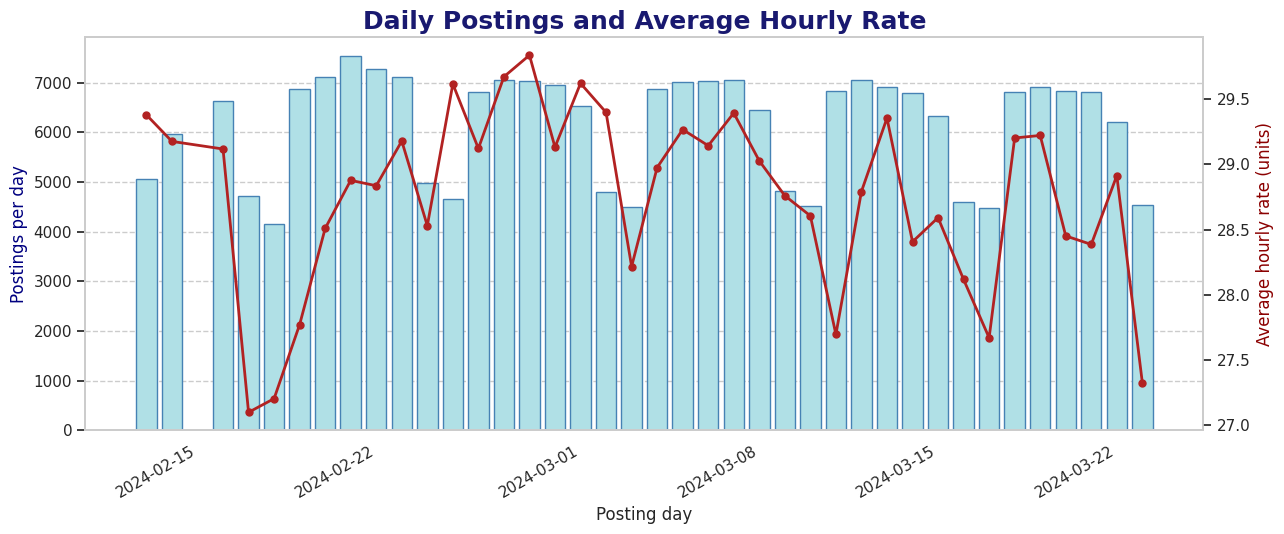

2026-11-23 16:49:06,972 - job_market_analysis - INFO - Volume and average rate plotted — days=39, rank correlation=0.39


In [55]:
subsection_header("Multivariate — Daily Postings and Average Hourly Rate")

in_window = df_refined.loc[~df_refined["backdated_posting"]]
daily_view = in_window.groupby("posted_date").size().rename("postings").to_frame()
daily_view["average_rate"] = in_window.loc[(in_window["worker_type"] == "Freelancer") & (in_window["pay_status"] == "Stated")].groupby("posted_date")["hourly_rate_mid_capped"].mean()
part_days = int((daily_view["postings"] < 0.5 * daily_view["postings"].median()).sum())
daily_view = daily_view[daily_view["postings"] >= 0.5 * daily_view["postings"].median()]        # skip the part-collected edge days
info_box(f"<b>3 features</b> compared over the high-volume window: posting day, postings per day and the average stated hourly rate. {part_days} part-collected days are left out.")

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.bar(daily_view.index, daily_view["postings"], color="powderblue", edgecolor="steelblue", width=0.8)
ax.set_ylabel("Postings per day",color="navy")
ax.set_xlabel("Posting day")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.grid(axis="x", visible=False)
rate_ax = ax.twinx()
rate_ax.plot(daily_view.index, daily_view["average_rate"], color='firebrick', linewidth=2, marker="o", markersize=5)
rate_ax.set_ylabel("Average hourly rate (units)",color='darkred')
rate_ax.grid(False)
ax.set_title("Daily Postings and Average Hourly Rate", fontsize=18, fontweight="bold", color=PLOT_COLOR)
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig("Assets/eda_multivariate_volume_and_rate.png", dpi=150, bbox_inches="tight")
plt.show()

relation = daily_view["postings"].corr(daily_view["average_rate"], method="spearman")
info_box(f"Across {len(daily_view)} full days, the average hourly rate ranges from {daily_view['average_rate'].min():.2f} to {daily_view['average_rate'].max():.2f} units. "
         f"Rank correlation between daily volume and daily average rate: {relation:.2f}.")
logger.info(f"Volume and average rate plotted — days={len(daily_view)}, rank correlation={relation:.2f}")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Daily Postings and Average Hourly Rate:**

- **Weekly rhythm in volume:** most days carry 6,500 to 7,500 postings, with the peak of about 7,550 on 22 Feb. Volume drops to roughly 4,100 to 5,000 on the weekend days that repeat through the window.
- **A narrow rate band:** the average hourly rate stays between about 27.1 and 29.8 units, so the market price barely moves over the window.
- **Rate follows volume loosely:** the highest averages (about 29.6 to 29.8) fall on busy days around 21 to 28 Feb. The lowest (about 27.1 to 27.7) fall on quieter days such as 18 Feb, 12 Mar and 20 Mar.
- **Last day:** the final day shows a drop to about 27.3, which should not be read as a trend because it is a single day.
- **Reading it:** volume and average rate move together only loosely over this short window, so daily rate swings of one to two units are noise and not a market shift.
- **Modest link:** the rank correlation between daily volume and daily average rate is 0.39 across 39 days, so busier days tend to have somewhat higher averages.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 2: Multivariate — Job Category by Contract Type

<div style="margin-left: 20px; max-width: 90%">

How is each job category split between Freelancer and Permanent postings? Each category shows its posting count for both contract types side by side, so category, contract type and volume are read together.

</div>

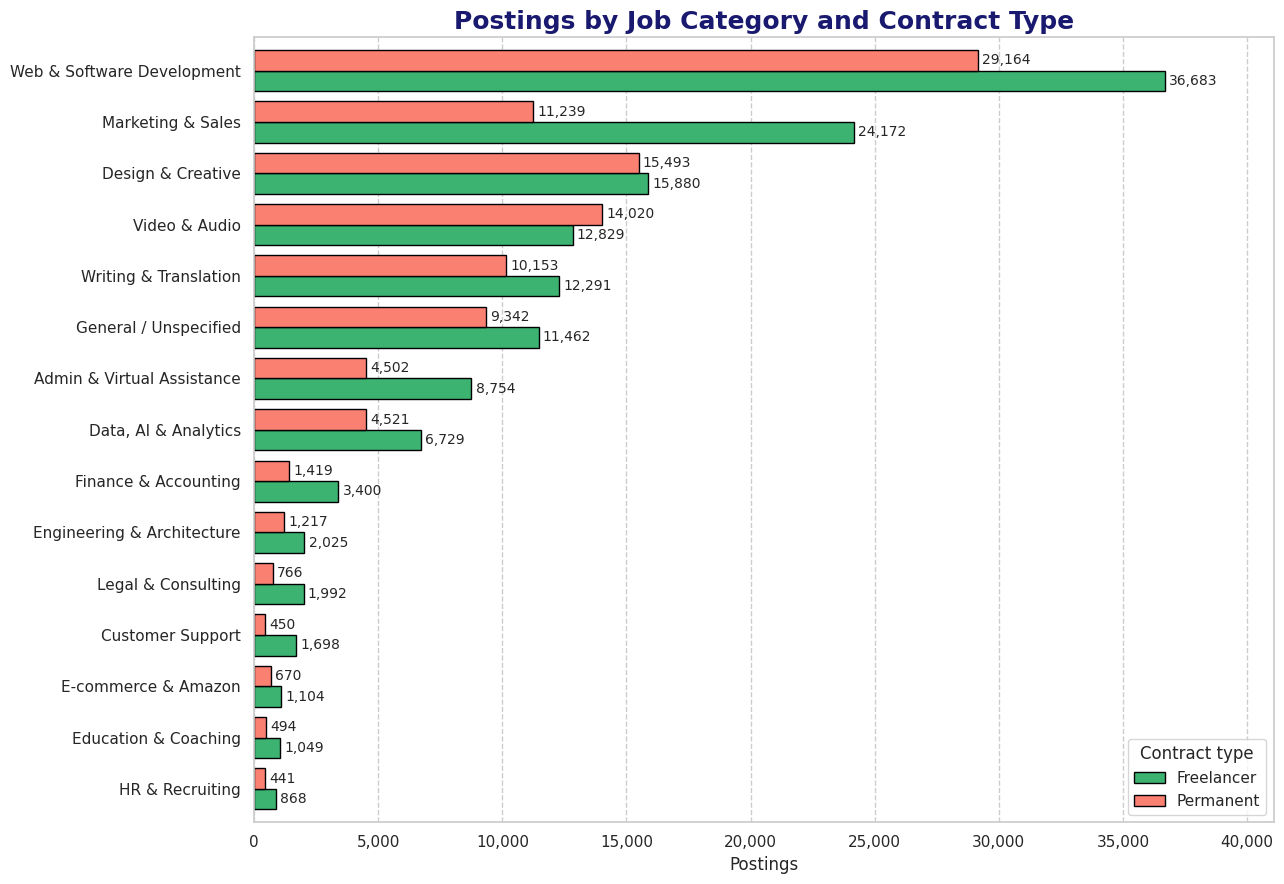

2026-11-23 16:49:07,992 - job_market_analysis - INFO - Category by contract type plotted — categories=15


In [56]:
subsection_header("Task 2: Multivariate — Job Category by Contract Type")

category_mix = pd.crosstab(df_refined["job_category"], df_refined["worker_type"])
category_mix = category_mix.loc[category_mix.sum(axis=1).sort_values().index]            # largest category ends up on top
info_box(f"<b>3 features</b> across {len(category_mix)} job categories: job category, contract type and number of postings.")

fig, ax = plt.subplots(figsize=(13, 9))
category_mix.plot(kind="barh", ax=ax, color={"Freelancer": "mediumseagreen", "Permanent": "salmon"}, width=0.8, edgecolor="black")
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3, fontsize=10)
ax.set_xlim(0, category_mix.values.max() * 1.12)
ax.xaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Postings by Job Category and Contract Type", fontsize=18, fontweight="bold", color=PLOT_COLOR)
ax.set_xlabel("Postings")
ax.set_ylabel("")
ax.legend(title="Contract type", loc="lower right")
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig("Assets/task2_multivariate_category_by_contract.png", dpi=150, bbox_inches="tight")
plt.show()

freelancer_share = category_mix["Freelancer"] / category_mix.sum(axis=1) * 100
info_box(f"Highest Freelancer share: {freelancer_share.idxmax()} ({freelancer_share.max():.1f}%); highest Permanent share: {freelancer_share.idxmin()} ({100 - freelancer_share.min():.1f}%).")
logger.info(f"Category by contract type plotted — categories={len(category_mix)}")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Job Category by Contract Type:**

- **Freelancer postings dominate most categories:** Marketing & Sales has 24,172 Freelancer postings against 11,239 Permanent, more than double. Customer Support is the most lopsided, with 1,698 Freelancer postings against 450 Permanent, roughly 79% Freelancer.
- **Balanced categories:** Design & Creative is almost even (15,880 against 15,493).
- **One exception:** Video & Audio is the only category where Permanent postings lead (14,020 against 12,829), about 52% Permanent.
- **Web & Software Development is the largest for both contract types:** 36,683 Freelancer and 29,164 Permanent postings.
- **Small categories:** Education & Coaching, HR & Recruiting and E-commerce & Amazon each have fewer than 1,200 postings of either type, so shares in them are less reliable.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 1: Multivariate — Pay vs Title and Posting Signals

<div style="margin-left: 20px; max-width: 90%">

Which simple signals move together with pay? The correlation here is Spearman, which is Pearson computed on ranks, so extreme pay values cannot dominate it. It is computed separately for Freelancer (stated hourly rate) and Permanent (salary), because the two pay scales are never mixed. This is the last exploratory view before modelling.

</div>

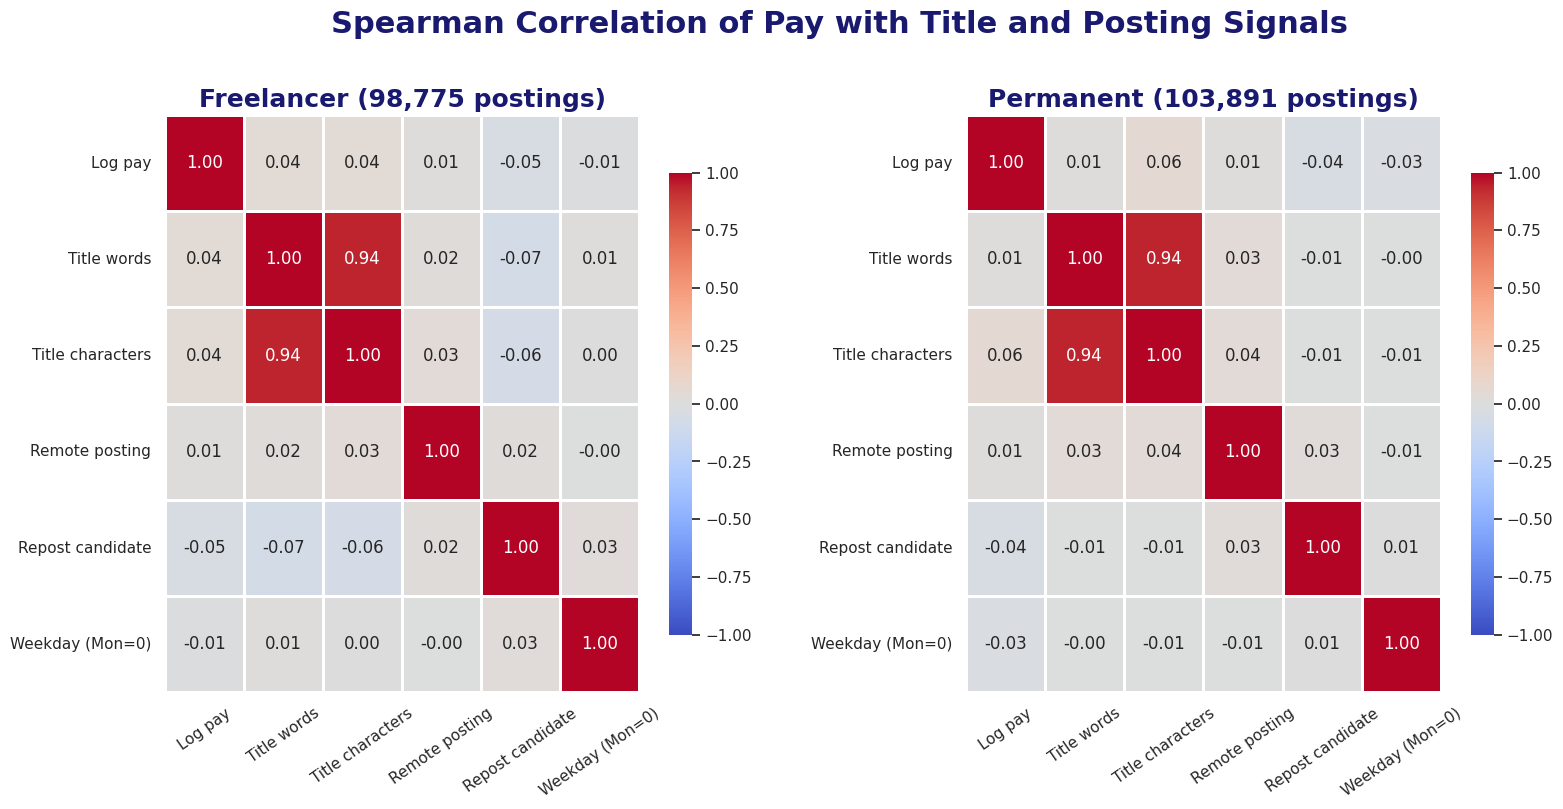

2026-11-23 16:49:09,726 - job_market_analysis - INFO - Spearman heatmap plotted — log pay vs title length, remote, repost and weekday for both contract types


In [57]:
subsection_header("Task 1: Multivariate — Pay vs Title and Posting Signals")

corr_frames = {
    "Freelancer": df_refined.loc[(df_refined["worker_type"] == "Freelancer") & (df_refined["pay_status"] == "Stated")].assign(pay=lambda d: np.log(d["hourly_rate_mid_capped"])),
    "Permanent": df_refined.loc[(df_refined["worker_type"] == "Permanent") & (df_refined["budget_capped"] > 0)].assign(pay=lambda d: np.log(d["budget_capped"])),
}
info_box("<b>6 features</b> per contract type: log pay, title length (words and characters), remote flag, repost flag and weekday, compared with Spearman correlation.")

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
fig.suptitle("Spearman Correlation of Pay with Title and Posting Signals", fontsize=22, color=PLOT_COLOR, fontweight="bold", y=1.02)
fig.subplots_adjust(wspace=0.35)
for ax, (contract, frame) in zip(axes, corr_frames.items()):
    signals = pd.DataFrame({
        "Log pay": frame["pay"],
        "Title words": frame["title_word_count"],
        "Title characters": frame["title_clean"].str.len(),
        "Remote posting": frame["remote_posting"].astype(int),
        "Repost candidate": frame["is_repost_candidate"].astype(int),
        "Weekday (Mon=0)": pd.to_datetime(frame["posted_date"]).dt.dayofweek,
    })
    sns.heatmap(signals.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0,
                linewidths=1, linecolor="white", cbar_kws={"shrink": 0.8}, ax=ax)
    ax.set_title(f"{contract} ({len(frame):,} postings)", fontweight="bold", fontsize=18)
    ax.tick_params(axis="x", rotation=35)
plt.savefig("Assets/task1_multivariate_spearman_pay_signals.png", dpi=150, bbox_inches="tight")
plt.show()

info_box("Pay is compared with the signals above on log scale; values near 0 mean the two move independently.")
logger.info("Spearman heatmap plotted — log pay vs title length, remote, repost and weekday for both contract types")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Pay vs Title and Posting Signals:**

- **Almost no relationship:** every coefficient with log pay is between −0.05 and 0.06, for both contract types. Title length, remote flag, repost flag and weekday barely move with pay.
- **Title length is redundant:** title words and title characters correlate at 0.94 in both panels, so they carry the same information and only one is needed in a model. The model section uses title word count.
- **Repost candidates:** the only consistent sign is a slight negative link with pay (−0.05 for Freelancer, −0.04 for Permanent), which is too small to matter on its own.
- **What this does and does not rule out:** these are simple numeric signals. Job category, country and specific title words are not captured here, and the earlier tests show they do separate pay, so the modelling section checks them together.

</div>

<hr style="width:60%; margin:auto;">

In [58]:
display(HTML(f"""
<div style="text-align:center;margin-top:40px;margin-bottom:30px;">
    <h3 style="color:{SUCCESS_TEXT};"><b>✅ Checkpoint: Exploratory Data Analysis Complete</b></h3>
    <p style="font-style:italic;font-size:1.05em;opacity:0.85;">
        <b>df_refined</b> holds <b>{len(df_refined):,} postings</b> across <b>{df_refined.shape[1]} columns</b>, with pay outliers treated through capped pay columns.
        Contract type, country, job category, remote work, posting volume, title keywords and pay have been explored one, two and several variables at a time.<br>
        Pay modelling ahead: which features drive pay, and how strongly each one matters.
    </p>
    <hr style="width:45%;">
</div>"""))

## 05. Feature Encoding & Pay Modelling

<div style="margin-left: 20px; max-width: 90%">

The exploration compared pay one signal at a time. This section turns the title, category and country into model-ready features and asks which of them explain pay when they are considered together, for Freelancer hourly rates and Permanent salaries separately.

</div>

### 📌 Task 1: Feature Encoding — Preparing the Pay Model Features

<div style="margin-left: 20px; max-width: 90%">

Models need numbers, so the text and categories are encoded first. Title words become yes/no columns for every word that appears in at least 1% of a contract type's postings, countries outside the 15 largest are grouped, and pay is put on a log scale so a few high values do not dominate. Job category and country group are one-hot encoded later inside the model pipeline.

</div>

In [59]:
section_header("Feature Encoding & Pay Modelling")
subsection_header("Task 1: Feature Encoding — Preparing the Pay Model Features")

TOP_COUNTRIES = 15          # countries outside the largest ones are grouped so the model stays small
WORD_MIN_SHARE = 0.01       # a title word becomes a feature only when it appears in at least 1% of that contract type's postings

top_countries = df_refined["country"].value_counts().head(TOP_COUNTRIES).index
country_group = df_refined["country"].where(df_refined["country"].isin(top_countries), "Other countries")

model_data, summary_rows = {}, []
for contract, group in pay_groups.items():
    rows = df_refined.loc[group.index]
    counter = CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS.union(FILLER_WORDS)), binary=True, min_df=WORD_MIN_SHARE, token_pattern=r"[a-z][a-z0-9+#]+")
    words = pd.DataFrame(counter.fit_transform(group["title_clean"]).toarray(), index=group.index, columns=[f"word: {word}" for word in counter.get_feature_names_out()])
    features = pd.concat([rows[["job_category"]], country_group.loc[group.index].rename("country_group"), rows[["remote_posting"]].astype(int), rows[["title_word_count"]], words], axis=1)
    model_data[contract] = (features, np.log(group["pay"]))
    summary_rows.append({"Contract": contract, "Postings": f"{len(group):,}", "Title Words Kept": words.shape[1], "Features Before Encoding": features.shape[1],
                         "Job Categories": features["job_category"].nunique(), "Country Groups": features["country_group"].nunique()})
centered_table(pd.DataFrame(summary_rows))

info_box(f"Title words are kept when they appear in at least {WORD_MIN_SHARE:.0%} of a contract type's postings; the {TOP_COUNTRIES} largest countries stay separate and the rest are grouped. "
         "Pay is modelled on a log scale, and Freelancer and Permanent are never mixed.")
logger.info(f"Pay model features prepared — {summary_rows}")

Contract,Postings,Title Words Kept,Features Before Encoding,Job Categories,Country Groups
Freelancer,"98,775",64,68,15,16
Permanent,"103,891",63,67,15,16


2026-11-23 16:49:11,575 - job_market_analysis - INFO - Pay model features prepared — [{'Contract': 'Freelancer', 'Postings': '98,775', 'Title Words Kept': 64, 'Features Before Encoding': 68, 'Job Categories': 15, 'Country Groups': 16}, {'Contract': 'Permanent', 'Postings': '103,891', 'Title Words Kept': 63, 'Features Before Encoding': 67, 'Job Categories': 15, 'Country Groups': 16}]


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Preparing the Pay Model Features:**

- **Same setup for both contract types:** 98,775 Freelancer and 103,891 Permanent postings each carry 15 job categories and 16 country groups (the 15 largest countries plus "Other countries").
- **Title words:** 64 words (Freelancer) and 63 words (Permanent) appear in at least 1% of postings, so each model starts with 68 and 67 features before encoding.
- **Why a 1% rule:** it keeps only words common enough to learn from and drops the long tail of rare words, which would add columns without adding signal.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 1: Modelling — Model Comparison

<div style="margin-left: 20px; max-width: 90%">

Which model predicts pay best? Linear Regression is the baseline model. Random Forest and LightGBM, a gradient-boosted tree model, are compared with it on exactly the same train and test postings, so the extra complexity has to earn its place.

</div>

In [60]:
subsection_header("Task 1: Modelling — Model Comparison")

import warnings; warnings.filterwarnings("ignore", message="X does not have valid feature names")

CV_COLUMN = "CV R² (5-fold)"
CANDIDATES = {"Linear Regression (baseline)": lambda: LinearRegression(),
              "Random Forest": lambda: RandomForestRegressor(n_estimators=120, max_depth=14, min_samples_leaf=20, n_jobs=-1, random_state=42),
              "LightGBM": lambda: LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=20, n_jobs=-1, random_state=42, verbose=-1)}

def build_pipeline(estimator):
    return Pipeline([("encode", ColumnTransformer([("categories", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["job_category", "country_group"]),
                                                   ("length", StandardScaler(), ["title_word_count"])], remainder="passthrough")),
                     ("model", estimator)])

def error_summary(actual_log, predicted_log):
    actual, predicted = np.exp(actual_log), np.exp(predicted_log)
    errors = np.abs(actual - predicted)
    return {"Test R² (log pay)": r2_score(actual_log, predicted_log), "MAE (units)": errors.mean(),
            "RMSE (units)": float(np.sqrt(((actual - predicted) ** 2).mean())), "Median Error (units)": float(np.median(errors))}

comparison_rows = []
for contract, (features, target) in model_data.items():
    train_x, test_x, train_y, test_y = train_test_split(features, target, test_size=0.2, random_state=42)
    cv_index = features.sample(min(30000, len(features)), random_state=42).index                 # cross-validation runs on a 30,000-posting sample to keep it fast
    for model_name, make_model in CANDIDATES.items():
        predictions = build_pipeline(make_model()).fit(train_x, train_y).predict(test_x)
        cv_score = cross_val_score(build_pipeline(make_model()), features.loc[cv_index], target.loc[cv_index], cv=5, scoring="r2").mean()
        comparison_rows.append({"Contract": contract, "Model": model_name, **error_summary(test_y, predictions), CV_COLUMN: cv_score})

comparison_table = pd.DataFrame(comparison_rows)
centered_table(comparison_table, float_format="{:,.4f}")

best_models = comparison_table.loc[comparison_table.groupby("Contract")[CV_COLUMN].idxmax()]
info_box("All models use the same training and test postings; R² is on log pay and the error columns are in units. Linear Regression is the baseline the tree models must beat. "
         "Best by cross-validated R² — " + "; ".join(f"{row['Contract']}: {row['Model']} ({row[CV_COLUMN]:.3f})" for _, row in best_models.iterrows()) + ".")
logger.info(f"Model comparison done — best={dict(zip(best_models['Contract'], best_models['Model']))}")

Contract,Model,Test R² (log pay),MAE (units),RMSE (units),Median Error (units),CV R² (5-fold)
Freelancer,Linear Regression (baseline),0.1629,14.1091,22.5500,9.0177,0.1597
Freelancer,Random Forest,0.1652,14.0716,22.5089,9.0366,0.1538
Freelancer,LightGBM,0.1915,13.8447,22.1778,8.7345,0.1781
Permanent,Linear Regression (baseline),0.0851,434.4206,"1,463.6368",74.7574,0.0835
Permanent,Random Forest,0.0948,433.6916,"1,462.5148",73.5628,0.0839
Permanent,LightGBM,0.1218,430.6908,"1,458.6345",72.5942,0.1109


2026-11-23 16:53:00,467 - job_market_analysis - INFO - Model comparison done — best={'Freelancer': 'LightGBM', 'Permanent': 'LightGBM'}


### 📌 Task 1: Modelling — Model Comparison Chart

<div style="margin-left: 20px; max-width: 90%">

The table is easier to judge as a picture. Bars show how well each model holds up across 5-fold cross-validation, and the line shows its median error in units. The best model by cross-validated R² is highlighted in a darker blue with a star.

</div>

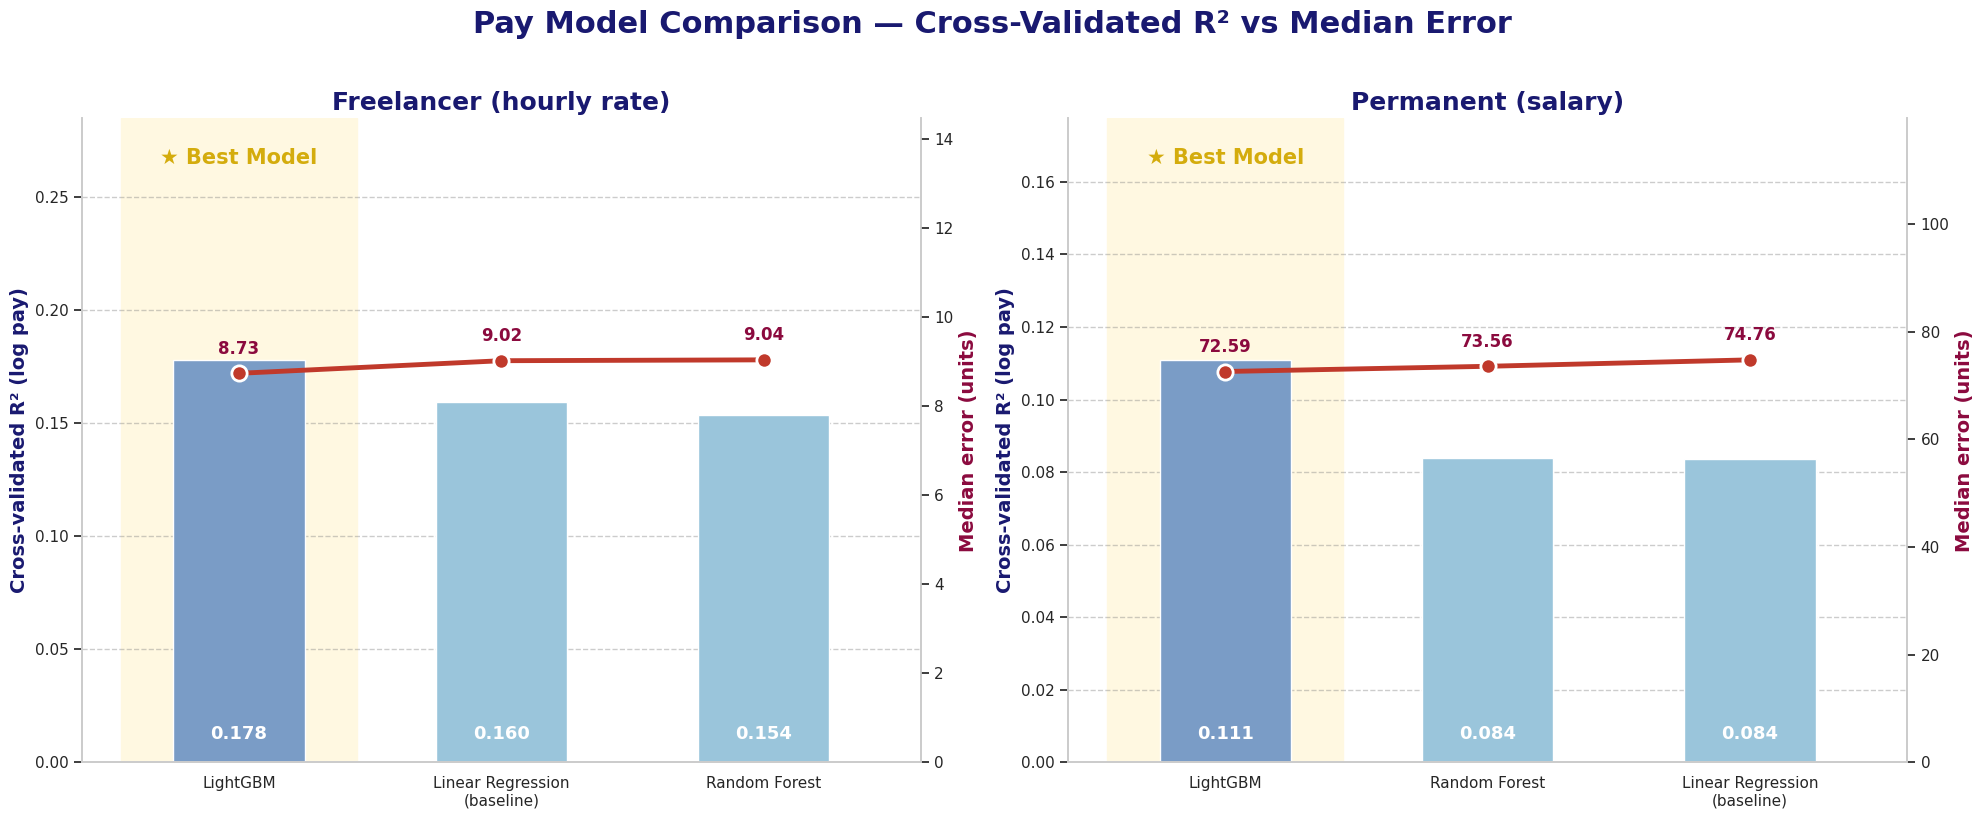

2026-11-23 16:53:01,630 - job_market_analysis - INFO - Model comparison chart saved — best models {'Freelancer': 'LightGBM', 'Permanent': 'LightGBM'}


In [61]:
subsection_header("Task 1: Modelling — Model Comparison Chart")

BAR_COLOR, BEST_BAR_COLOR, LINE_COLOR, LABEL_COLOR = "#9AC5DB", "#7A9CC6", "#C0392B", "#8B0A3E"

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
fig.suptitle("Pay Model Comparison — Cross-Validated R² vs Median Error", fontsize=22, color=PLOT_COLOR, fontweight="bold", y=1.02)
fig.subplots_adjust(wspace=0.45)
for ax, contract in zip(axes, ["Freelancer", "Permanent"]):
    part = comparison_table[comparison_table["Contract"] == contract].sort_values(CV_COLUMN, ascending=False).reset_index(drop=True)
    positions = np.arange(len(part))
    labels = [name.replace(" (", "\n(") for name in part["Model"]]

    ax.axvspan(-0.45, 0.45, color="#FFF8E1", zorder=0)                                              # the best model is always first after sorting
    bars = ax.bar(positions, part[CV_COLUMN], width=0.5, color=[BEST_BAR_COLOR] + [BAR_COLOR] * (len(part) - 1), zorder=2)
    for bar, value in zip(bars, part[CV_COLUMN]):
        ax.text(bar.get_x() + bar.get_width() / 2, 0.03, f"{value:.3f}", transform=ax.get_xaxis_transform(), ha="center", va="bottom", color="white", fontweight="bold", fontsize=13, zorder=3)
    ax.text(0, 0.93, "★ Best Model", transform=ax.get_xaxis_transform(), ha="center", color="#D4AC0D", fontweight="bold", fontsize=15)
    ax.set_xticks(positions)
    ax.set_xticklabels(labels)
    ax.set_xlim(-0.6, len(part) - 0.4)
    ax.set_ylim(0, part[CV_COLUMN].max() * 1.6)
    ax.set_ylabel("Cross-validated R² (log pay)", color=PLOT_COLOR, fontweight="bold", fontsize=14)
    ax.set_title(f"{contract} ({'hourly rate' if contract == 'Freelancer' else 'salary'})", fontweight="bold", fontsize=18)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.grid(axis="x", visible=False)
    ax.spines["top"].set_visible(False)

    error_ax = ax.twinx()
    error_ax.plot(positions, part["Median Error (units)"], color=LINE_COLOR, linewidth=3.5, marker="o", markersize=11, markeredgecolor="white", markeredgewidth=2, zorder=5)
    for position, value in zip(positions, part["Median Error (units)"]):
        error_ax.annotate(f"{value:,.2f}", (position, value), textcoords="offset points", xytext=(0, 14), ha="center", fontsize=12, color=LABEL_COLOR, fontweight="bold")
    error_ax.set_ylim(0, part["Median Error (units)"].max() * 1.6)
    error_ax.set_ylabel("Median error (units)", color=LABEL_COLOR, fontweight="bold", fontsize=14)
    error_ax.grid(False)
    error_ax.spines["top"].set_visible(False)
plt.tight_layout()
plt.savefig("Assets/task1_modelling_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

chart_best = comparison_table.loc[comparison_table.groupby("Contract")[CV_COLUMN].idxmax()]
info_box("Best model by cross-validated R² — " + "; ".join(f"{row['Contract']}: {row['Model']} ({row[CV_COLUMN]:.3f})" for _, row in chart_best.iterrows()) + ".")
logger.info(f"Model comparison chart saved — best models {dict(zip(chart_best['Contract'], chart_best['Model']))}")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Model Comparison:**

- **LightGBM is best on every measure in both contract types:** for Freelancer its test R² is 0.192 against 0.163 for the Linear Regression baseline, and its cross-validated R² is 0.178 against 0.160. For Permanent the figures are 0.122 against 0.085 and 0.111 against 0.084.
- **The Random Forest shows no clear gain over the baseline:** it is slightly ahead on the test split (R² 0.165 against 0.163 for Freelancer, 0.095 against 0.085 for Permanent), but its cross-validated R² is lower for Freelancer (0.154 against 0.160) and tied for Permanent (0.084 against 0.084). The forest settings used here add complexity without a consistent gain.
- **The gain from LightGBM is real but modest:** median error falls from 9.018 to 8.734 units for Freelancer (about 3% lower) and from 74.757 to 72.594 units for Permanent (about 3% lower). MAE and RMSE move the same way.
- **The ranking holds under cross-validation:** LightGBM leads in every fold average, and its cross-validated R² sits slightly below its test R² (0.178 against 0.192, 0.111 against 0.122), which is a normal gap and not a sign of overfitting.
- **Pay stays hard to predict:** even the best model explains under a fifth of the variation in hourly rate and about an eighth in salary, so title, category and country carry only part of what sets pay.
- **Decision:** LightGBM is used for the feature importance that follows. It is not tuned, because the settings were fixed in advance and the gap to the baseline is small.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 1: Modelling — Feature Importance

<div style="margin-left: 20px; max-width: 90%">

Permutation importance shows which features the best model from the comparison relies on. Each feature is shuffled in turn on postings the model has not seen, and the drop in R² measures how much the model needed it.

</div>

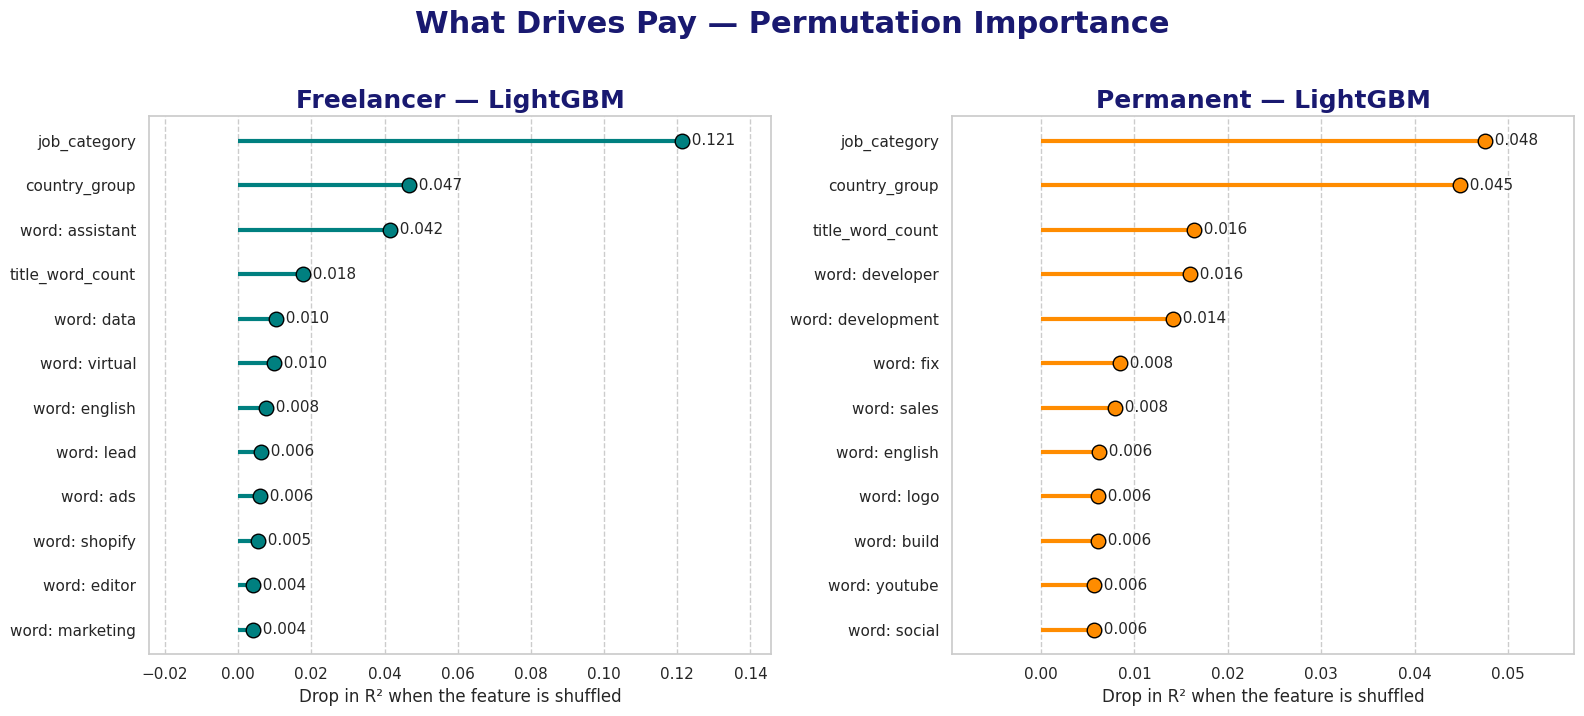

2026-11-23 16:54:02,668 - job_market_analysis - INFO - Pay driver models fitted and importance plotted — {'Freelancer': 'LightGBM', 'Permanent': 'LightGBM'}


In [62]:
subsection_header("Task 1: Modelling — Feature Importance")

importance_rows = []
for contract, (features, target) in model_data.items():
    best_name = comparison_table[comparison_table["Contract"] == contract].set_index("Model")[CV_COLUMN].idxmax()
    train_x, test_x, train_y, test_y = train_test_split(features, target, test_size=0.2, random_state=42)
    final_model = build_pipeline(CANDIDATES[best_name]()).fit(train_x, train_y)
    sample = test_x.sample(min(8000, len(test_x)), random_state=42)
    result = permutation_importance(final_model, sample, test_y.loc[sample.index], n_repeats=3, random_state=42, n_jobs=-1)
    importance_rows.append(pd.DataFrame({"Contract": contract, "Model": best_name, "Feature": features.columns, "Importance": result.importances_mean}))
pay_importance = pd.concat(importance_rows).sort_values(["Contract", "Importance"], ascending=[True, False])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle("What Drives Pay — Permutation Importance", fontsize=22, color=PLOT_COLOR, fontweight="bold", y=1.02)
fig.subplots_adjust(wspace=0.6)
for ax, contract, color in zip(axes, ["Freelancer", "Permanent"], ["teal", "darkorange"]):
    top = pay_importance[pay_importance["Contract"] == contract].head(12).iloc[::-1]
    ax.hlines(y=top["Feature"], xmin=0, xmax=top["Importance"], color=color, linewidth=3)
    ax.scatter(top["Importance"], top["Feature"], color=color, s=110, zorder=3, edgecolor="black")
    for feature, value in zip(top["Feature"], top["Importance"]):
        ax.text(value, feature, f"  {value:.3f}", va="center", fontsize=11)
    ax.set_title(f"{contract} — {top['Model'].iloc[0]}", fontweight="bold", fontsize=18)
    ax.set_xlabel("Drop in R² when the feature is shuffled")
    ax.set_ylabel("")
    ax.margins(x=0.2)
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig("Assets/task1_modelling_pay_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

leaders = pay_importance.groupby("Contract").head(1).set_index("Contract")
info_box("Most important feature — " + "; ".join(f"{contract}: {row['Feature']} ({row['Importance']:.3f})" for contract, row in leaders.iterrows()) + ".")
logger.info(f"Pay driver models fitted and importance plotted — {dict(zip(best_models['Contract'], best_models['Model']))}")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — What Drives Pay (Feature Importance):**

- **Job category leads in both contract types:** shuffling it drops R² by 0.121 for Freelancer, a large part of that model's test R² of 0.192, and by 0.048 for Permanent, whose test R² is 0.122.
- **Country group is second for both:** 0.047 for Freelancer and 0.045 for Permanent. For salary it is almost as important as category, so where the client is based matters as much as what the job is.
- **Freelancer words:** "assistant" is third (0.042), well above title length (0.018). "Data", "virtual" and "english" follow at 0.010, 0.010 and 0.008. This agrees with assistant-type titles paying less per hour in the earlier exploration.
- **Permanent words:** title length (0.016), "developer" (0.016) and "development" (0.014) lead, so salary is tied to developer-type titles and to how detailed the title is.
- **Single words add little beyond category:** after the top few, no word is worth more than 0.010 in either model.
- **Remote flag:** it does not appear among the top 12 features for either contract type, so remote postings do not pay differently once category and country are known.
- **Importance is not additive:** features overlap, so these drops should be compared, not summed.

</div>

<hr style="width:60%; margin:auto;">

In [63]:
best_by_cv = comparison_table.loc[comparison_table.groupby("Contract")[CV_COLUMN].idxmax()]
top_drivers = pay_importance.groupby("Contract").head(1).set_index("Contract")["Feature"]
display(HTML(f"""
<div style="text-align:center;margin-top:40px;margin-bottom:30px;">
    <h3 style="color:{SUCCESS_TEXT};"><b>✅ Checkpoint: Feature Encoding & Pay Modelling Complete</b></h3>
    <p style="font-style:italic;font-size:1.05em;opacity:0.85;">
        Title words, job category, country group and remote flag were encoded for <b>{len(model_data):,} contract types</b>, and three models were compared on identical train and test postings.
        Best by cross-validated R²: {"; ".join(f"<b>{row['Contract']}</b> — {row['Model']} ({row[CV_COLUMN]:.3f})" for _, row in best_by_cv.iterrows())}.
        Top driver of pay: {"; ".join(f"<b>{contract}</b> — {feature}" for contract, feature in top_drivers.items())}.<br>
        Market demand trends ahead: which job categories are growing and how remote work is changing.
    </p>
    <hr style="width:45%;">
</div>"""))

## 06. Trend Analysis & Theme Discovery

<div style="margin-left: 20px; max-width: 90%">

Having looked at where and what pays, this section looks at what employers are asking for and how that demand is shifting, first by job category and then by the themes hidden in the titles themselves.

</div>

### 📌 Task 2: Trend Analysis — Job Category Share Over Time

<div style="margin-left: 20px; max-width: 90%">

An emerging category is one whose share of all postings is growing. The share of each category is tracked day by day, and the first half of the window is tested against the second half (Mann-Whitney U, Benjamini-Hochberg corrected). A category counts as rising or falling only when that difference is statistically significant.

</div>

In [64]:
section_header("Trend Analysis & Theme Discovery")
subsection_header("Task 2: Trend Analysis — Job Category Share Over Time")

def trend_table(first, second, names):
    """Share in the first half against the second half of the window, with a corrected significance test."""
    rows = [{"Name": name, "First Half (%)": first[name].mean(), "Second Half (%)": second[name].mean(),
             "p_value": mannwhitneyu(first[name], second[name], alternative="two-sided").pvalue} for name in names]
    table = pd.DataFrame(rows)
    table["Change (pp)"] = table["Second Half (%)"] - table["First Half (%)"]
    table["Relative Change (%)"] = table["Change (pp)"] / table["First Half (%)"] * 100
    table["q_value"] = multipletests(table["p_value"], method="fdr_bh")[1]
    table["Trend"] = np.where(table["q_value"] < 0.05, np.where(table["Change (pp)"] > 0, "Rising", "Falling"), "Stable")
    return table.sort_values("Change (pp)", ascending=False).reset_index(drop=True)

in_window = df_refined.loc[~df_refined["backdated_posting"]]
daily_counts = pd.crosstab(in_window["posted_date"], in_window["job_category"])
daily_total = daily_counts.sum(axis=1)
full_days = daily_total >= 0.5 * daily_total.median()                  # skip the part-collected edge days
daily_share = daily_counts.loc[full_days].div(daily_total[full_days], axis=0) * 100
daily_share.index = pd.to_datetime(daily_share.index)
half = len(daily_share) // 2
first_half, second_half = daily_share.iloc[:half], daily_share.iloc[half:]
category_trend = trend_table(first_half, second_half, daily_share.columns)

display_table = category_trend[["Name", "First Half (%)", "Second Half (%)", "Change (pp)", "Relative Change (%)", "q_value", "Trend"]].rename(columns={"Name": "Category", "q_value": "q-value"})
display_table["q-value"] = display_table["q-value"].map("{:.2g}".format)
centered_table(display_table, float_format="{:,.2f}")

trend_counts = category_trend["Trend"].value_counts()
info_box(f"Share of daily postings compared between {first_half.index.min():%d %b} to {first_half.index.max():%d %b} and {second_half.index.min():%d %b} to {second_half.index.max():%d %b} "
         f"({len(daily_share)} full days). Rising: {trend_counts.get('Rising', 0)}, falling: {trend_counts.get('Falling', 0)}, stable: {trend_counts.get('Stable', 0)}. "
         "The window is short, so rising means rising within it, not a long-term trend.")
logger.info(f"Category trends tested — {trend_counts.to_dict()}")

Category,First Half (%),Second Half (%),Change (pp),Relative Change (%),q-value,Trend
Marketing & Sales,14.05,14.77,0.71,5.07,0.014,Rising
Web & Software Development,26.55,27.25,0.70,2.65,0.26,Stable
Video & Audio,10.87,11.19,0.32,2.96,0.37,Stable
Design & Creative,12.80,12.95,0.16,1.21,0.45,Stable
Finance & Accounting,1.92,1.99,0.07,3.76,0.37,Stable
HR & Recruiting,0.50,0.55,0.05,10.77,0.37,Stable
Customer Support,0.84,0.89,0.05,6.25,0.41,Stable
Legal & Consulting,1.10,1.14,0.04,3.69,0.43,Stable
Engineering & Architecture,1.32,1.34,0.02,1.54,0.42,Stable
Education & Coaching,0.63,0.63,-0.00,-0.45,0.73,Stable


2026-11-23 16:54:02,869 - job_market_analysis - INFO - Category trends tested — {'Stable': 13, 'Rising': 1, 'Falling': 1}


### 📌 Task 2: Trend Analysis — Share Change and Significant Movers

<div style="margin-left: 20px; max-width: 90%">

The table shows which categories moved. This view makes it visible: bars show how many percentage points each category's share changed between the two halves of the window, and the lines show the day-by-day share of the categories whose shift is statistically significant.

</div>

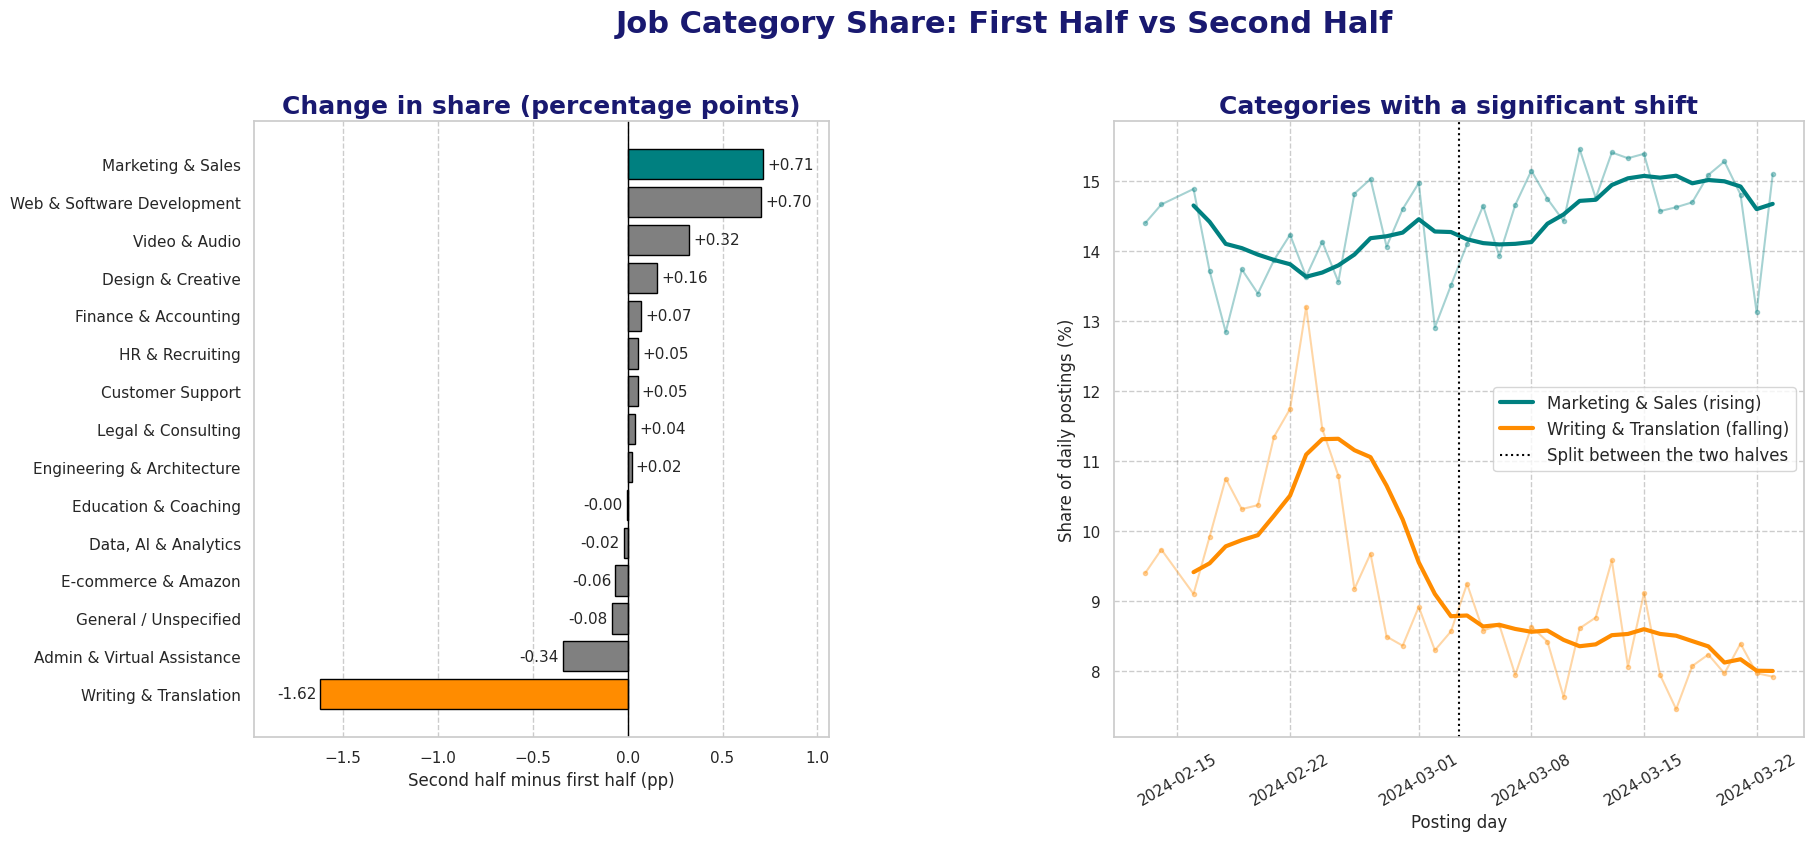

2026-11-23 16:54:04,600 - job_market_analysis - INFO - Category share change plotted — movers=['Marketing & Sales', 'Writing & Translation']


In [65]:
subsection_header("Task 2: Trend Analysis — Share Change and Significant Movers")

TREND_COLORS = {"Rising": "teal", "Falling": "darkorange", "Stable": "grey"}
smoothed_share = daily_share.rolling(7, min_periods=3).mean()

fig, (bar_ax, line_ax) = plt.subplots(1, 2, figsize=(20, 8), gridspec_kw={"width_ratios": [1, 1.2]})
fig.suptitle("Job Category Share: First Half vs Second Half", fontsize=22, color=PLOT_COLOR, fontweight="bold", y=1.02)
fig.subplots_adjust(wspace=0.45)

ordered = category_trend.iloc[::-1]
bar_ax.barh(ordered["Name"], ordered["Change (pp)"], color=[TREND_COLORS[trend] for trend in ordered["Trend"]], edgecolor="black")
bar_ax.bar_label(bar_ax.containers[0], fmt="%+.2f", padding=3, fontsize=11)
bar_ax.axvline(0, color="black", linewidth=1)
bar_ax.set_title("Change in share (percentage points)", fontweight="bold", fontsize=18)
bar_ax.set_xlabel("Second half minus first half (pp)")
bar_ax.margins(x=0.15)
bar_ax.grid(axis="x", linestyle="--", alpha=0.4)
bar_ax.grid(axis="y", visible=False)

movers = category_trend[category_trend["Trend"] != "Stable"]
for _, row in movers.iterrows():
    color = TREND_COLORS[row["Trend"]]
    line_ax.plot(daily_share.index, daily_share[row["Name"]], color=color, alpha=0.35, linewidth=1.5, marker="o", markersize=3)
    line_ax.plot(smoothed_share.index, smoothed_share[row["Name"]], color=color, linewidth=3, label=f"{row['Name']} ({row['Trend'].lower()})")
line_ax.axvline(first_half.index.max() + pd.Timedelta(hours=12), color="black", linestyle=":", linewidth=1.5, label="Split between the two halves")
line_ax.set_title("Categories with a significant shift", fontweight="bold", fontsize=18)
line_ax.set_xlabel("Posting day")
line_ax.set_ylabel("Share of daily postings (%)")
line_ax.legend(fontsize=12)
line_ax.grid(True, linestyle="--", alpha=0.4)
line_ax.tick_params(axis="x", rotation=30)
plt.savefig("Assets/task2_trend_category_share_change.png", dpi=150, bbox_inches="tight")
plt.show()
logger.info(f"Category share change plotted — movers={movers['Name'].tolist()}")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Job Category Trend:**

- **One rising category:** Marketing & Sales grew from 14.05% to 14.77% of daily postings, +0.71 percentage points (+5.07%), and the shift is significant (q = 0.014).
- **One falling category:** Writing & Translation fell from 9.98% to 8.36%, −1.62 points (−16.22%), the largest and most significant move (q = 0.00074).
- **The other 13 categories are stable:** their shifts are not distinguishable from normal day-to-day variation (q between 0.26 and 0.73).
- **Large but not significant:** Web & Software Development moved +0.70 points, almost the same as Marketing & Sales, but its share varies more day to day (q = 0.26). Admin & Virtual Assistance moved −0.34 points (q = 0.37).
- **Percentages mislead for small categories:** HR & Recruiting is up 10.77% in relative terms, but that is only 0.05 points of the total and is not significant.
- **Window caution:** the daily line for Writing & Translation peaks around late February and then settles lower. Part of the fall is a high first-half average, so it should be read as a fall within this window, not a lasting decline.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 7: Trend Analysis — Remote Share by Half of the Window

<div style="margin-left: 20px; max-width: 90%">

Is remote work becoming more common? The share of postings that state remote work is calculated for each full day, and the first half of the window is tested against the second half (Mann-Whitney U, Benjamini-Hochberg corrected). It is done for all postings and for each contract type, so a shift in one contract type is not hidden by the other.

</div>

In [66]:
subsection_header("Task 7: Trend Analysis — Remote Share by Half of the Window")

window_postings = df_refined.loc[~df_refined["backdated_posting"]].copy()
window_postings["posted_day"] = pd.to_datetime(window_postings["posted_date"])
day_totals = window_postings.groupby("posted_day").size()
remote_days = day_totals[day_totals >= 0.5 * day_totals.median()].index              # skip the part-collected edge days
remote_split = remote_days[len(remote_days) // 2]                                    # first day of the second half
window_postings = window_postings[window_postings["posted_day"].isin(remote_days)].copy()
window_postings["window_half"] = np.where(window_postings["posted_day"] < remote_split, "First Half", "Second Half")

remote_groups = {"All postings": window_postings,
                 "Freelancer": window_postings[window_postings["worker_type"] == "Freelancer"],
                 "Permanent": window_postings[window_postings["worker_type"] == "Permanent"]}
remote_rows = []
for group_name, part in remote_groups.items():
    daily_remote_share = part.groupby(["window_half", "posted_day"])["remote_posting"].mean().mul(100)
    first, second = daily_remote_share["First Half"], daily_remote_share["Second Half"]
    remote_rows.append({"Group": group_name, "Postings": len(part), "Remote Postings": int(part["remote_posting"].sum()),
                        "First Half (%)": first.mean(), "Second Half (%)": second.mean(),
                        "p_value": mannwhitneyu(first, second, alternative="two-sided").pvalue})

remote_trend = pd.DataFrame(remote_rows)
remote_trend["Change (pp)"] = remote_trend["Second Half (%)"] - remote_trend["First Half (%)"]
remote_trend["Relative Change (%)"] = remote_trend["Change (pp)"] / remote_trend["First Half (%)"] * 100
remote_trend["q_value"] = multipletests(remote_trend["p_value"], method="fdr_bh")[1]
remote_trend["Trend"] = np.where(remote_trend["q_value"] < 0.05, np.where(remote_trend["Change (pp)"] > 0, "Rising", "Falling"), "Stable")

remote_display = remote_trend[["Group", "Postings", "Remote Postings", "First Half (%)", "Second Half (%)", "Change (pp)", "Relative Change (%)", "q_value", "Trend"]].rename(columns={"q_value": "q-value"})
remote_display["Postings"] = remote_display["Postings"].map("{:,}".format)
remote_display["Remote Postings"] = remote_display["Remote Postings"].map("{:,}".format)
remote_display["q-value"] = remote_display["q-value"].map("{:.2g}".format)
centered_table(remote_display, float_format="{:,.2f}")

info_box(f"Share of postings flagged remote, compared between {remote_days.min():%d %b} to {(remote_split - pd.Timedelta(days=1)):%d %b} and {remote_split:%d %b} to {remote_days.max():%d %b} "
         f"({len(remote_days)} full days). The window is short, so rising or falling describes this window only.")
logger.info(f"Remote share trend tested — {dict(zip(remote_trend['Group'], remote_trend['Trend']))}")

Group,Postings,Remote Postings,First Half (%),Second Half (%),Change (pp),Relative Change (%),q-value,Trend
All postings,"240,548","1,334",0.55,0.55,0.01,1.00,0.9,Stable
Freelancer,"138,451","1,010",0.71,0.73,0.02,2.84,0.9,Stable
Permanent,"102,097",324,0.32,0.31,-0.01,-3.01,0.9,Stable


2026-11-23 16:54:05,289 - job_market_analysis - INFO - Remote share trend tested — {'All postings': 'Stable', 'Freelancer': 'Stable', 'Permanent': 'Stable'}


### 📌 Task 7: Trend Analysis — Daily Remote Share

<div style="margin-left: 20px; max-width: 90%">

The table gives one number per half; this view shows the day-by-day path behind it. The left panel shows the daily remote share of all postings with a 95% confidence band, and the right panel compares the two contract types.

</div>

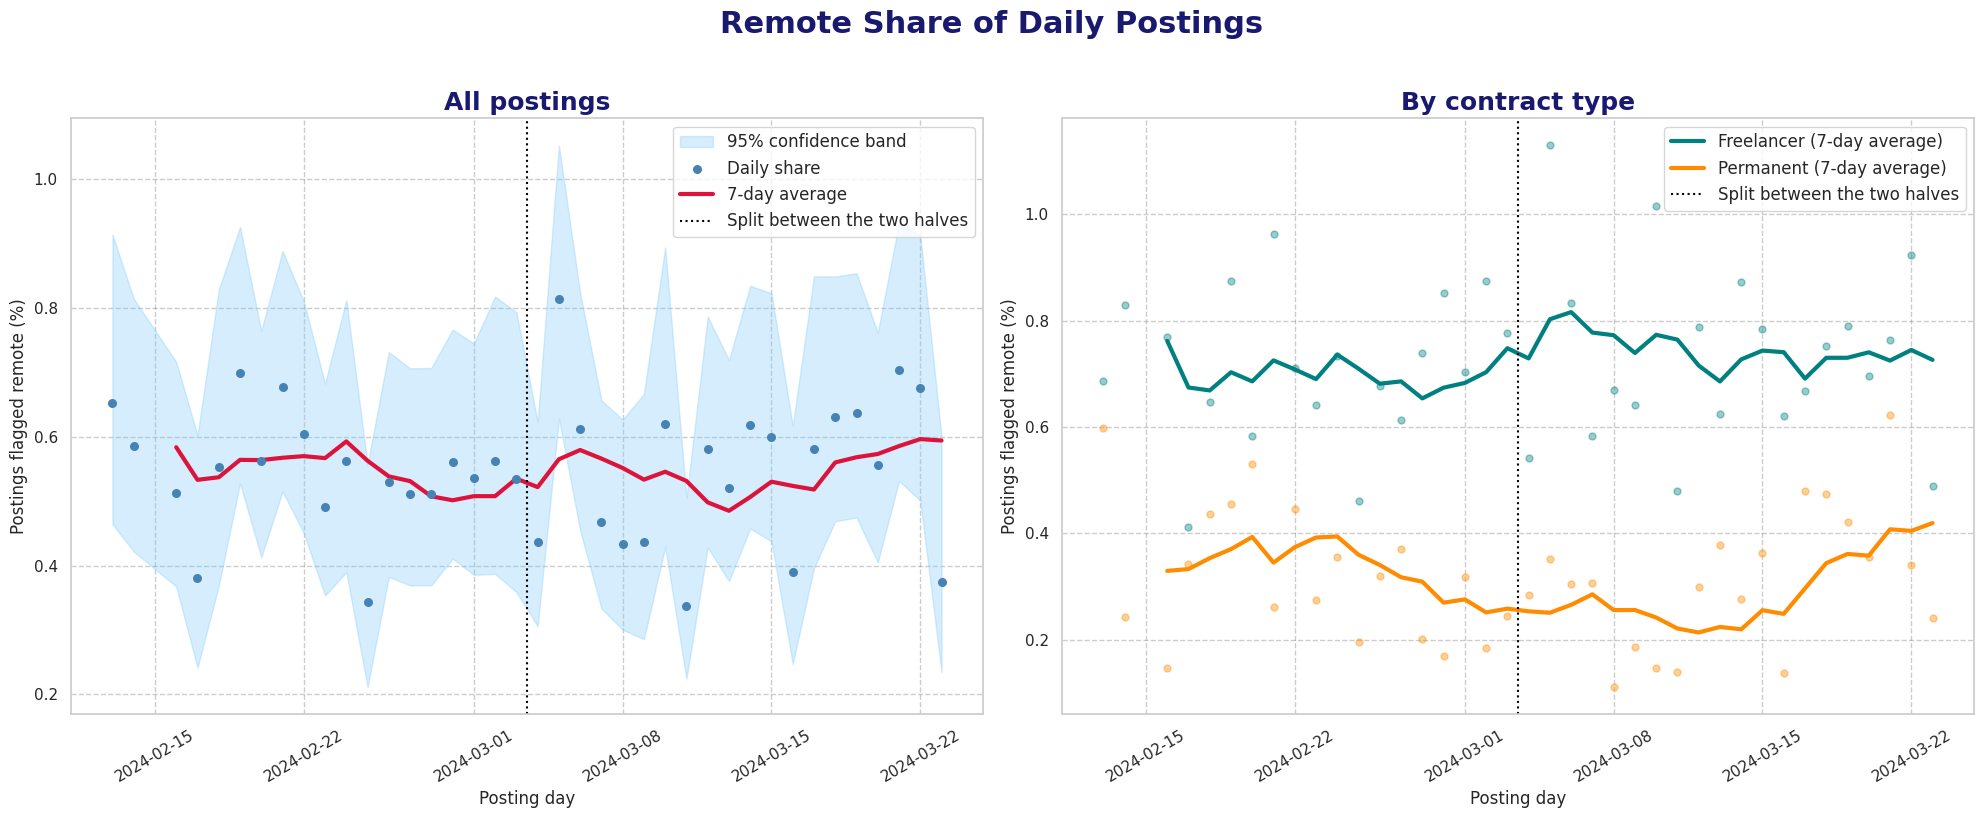

2026-11-23 16:54:07,205 - job_market_analysis - INFO - Daily remote share plotted for all postings and by contract type


In [67]:
subsection_header("Task 7: Trend Analysis — Daily Remote Share")

daily_remote = window_postings.groupby("posted_day")["remote_posting"].agg(remote="sum", total="size")
daily_remote["share"] = daily_remote["remote"] / daily_remote["total"] * 100
band_low, band_high = proportion_confint(daily_remote["remote"].to_numpy(), daily_remote["total"].to_numpy(), alpha=0.05, method="wilson")
smoothed_remote = daily_remote["share"].rolling(7, min_periods=3).mean()
contract_remote = window_postings.groupby(["posted_day", "worker_type"])["remote_posting"].mean().unstack().mul(100)
split_line = remote_split - pd.Timedelta(hours=12)

fig, (all_ax, contract_ax) = plt.subplots(1, 2, figsize=(20, 8))
fig.suptitle("Remote Share of Daily Postings", fontsize=22, color=PLOT_COLOR, fontweight="bold", y=1.02)
fig.subplots_adjust(wspace=0.25)

all_ax.fill_between(daily_remote.index, band_low * 100, band_high * 100, color="lightskyblue", alpha=0.35, label="95% confidence band")
all_ax.scatter(daily_remote.index, daily_remote["share"], color="steelblue", s=30, zorder=3, label="Daily share")
all_ax.plot(smoothed_remote.index, smoothed_remote, color="crimson", linewidth=3, label="7-day average")
all_ax.axvline(split_line, color="black", linestyle=":", linewidth=1.5, label="Split between the two halves")
all_ax.set_title("All postings", fontweight="bold", fontsize=18)
all_ax.set_xlabel("Posting day")
all_ax.set_ylabel("Postings flagged remote (%)")
all_ax.legend(fontsize=12)
all_ax.grid(True, linestyle="--", alpha=0.4)
all_ax.tick_params(axis="x", rotation=30)

for contract, color in zip(["Freelancer", "Permanent"], ["teal", "darkorange"]):
    contract_ax.scatter(contract_remote.index, contract_remote[contract], color=color, alpha=0.4, s=25)
    contract_ax.plot(contract_remote.index, contract_remote[contract].rolling(7, min_periods=3).mean(), color=color, linewidth=3, label=f"{contract} (7-day average)")
contract_ax.axvline(split_line, color="black", linestyle=":", linewidth=1.5, label="Split between the two halves")
contract_ax.set_title("By contract type", fontweight="bold", fontsize=18)
contract_ax.set_xlabel("Posting day")
contract_ax.set_ylabel("Postings flagged remote (%)")
contract_ax.legend(fontsize=12)
contract_ax.grid(True, linestyle="--", alpha=0.4)
contract_ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("Assets/task7_trend_remote_share.png", dpi=150, bbox_inches="tight")
plt.show()

info_box("The band is the 95% Wilson confidence interval of each day's remote share, so days with fewer postings have wider bands. Lines are 7-day averages.")
logger.info("Daily remote share plotted for all postings and by contract type")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Remote Work Trend:**

- **Remote work is rare in titles:** 1,334 of 240,548 postings (0.55%) say remote in the title. Postings without the word are not necessarily on-site, so this is a lower bound on remote work.
- **No trend in the window:** the share is 0.55% in both halves for all postings, and Freelancer (0.71% to 0.73%) and Permanent (0.32% to 0.31%) are also flat. All three are stable (q = 0.9), so remote work was neither growing nor shrinking over these 39 days.
- **Freelancer postings are more than twice as remote as Permanent ones:** about 0.7% against about 0.3%, and the gap holds on every day of the window. This is the one clear pattern here.
- **Day-to-day noise is large:** there are about 6,000 postings a day but only about 34 of them are remote, so a single day's share swings between roughly 0.4% and 0.8%. The confidence bands show this, and it is why the 7-day line is used.
- **A late rise for Permanent to watch:** its 7-day average climbs from about 0.25% to about 0.4% in the final week. The half-against-half test finds no shift, so this is a pattern to watch, not a finding.
- **What this means for the forecast:** with no trend, the honest forecast for remote share is a flat level with a wide interval, and it will be built that way in the forecasting section.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 2: Theme Discovery — Choosing the Number of Themes

<div style="margin-left: 20px; max-width: 90%">

The number of themes is chosen from the silhouette score, which measures how well separated the groups are: among the theme counts whose score is within 0.02 of the best, the smallest is used, because extra themes that add almost nothing are harder to interpret.

Each compressed title is scaled to unit length so that themes follow which words a title uses and not how many.

</div>

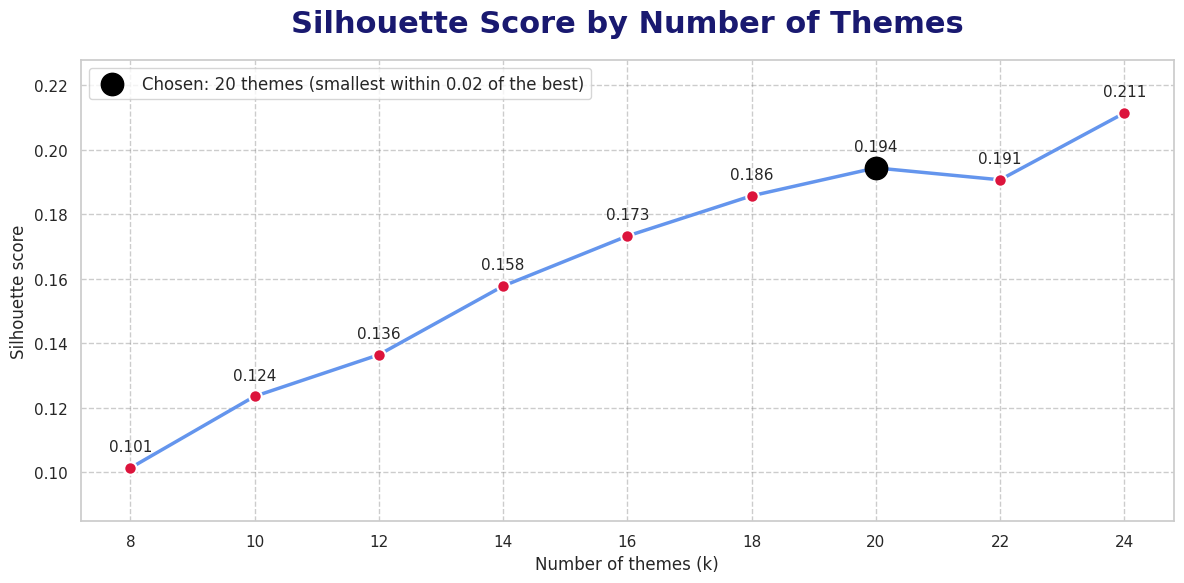

2026-11-23 16:54:34,111 - job_market_analysis - INFO - Theme count sweep done — best k=20, silhouette=0.194


In [68]:
subsection_header("Task 2: Theme Discovery — Choosing the Number of Themes")

THEME_SAMPLE = 30000
K_RANGE = range(8, 25, 2)

theme_titles = df_refined["title_clean"].fillna("").sample(THEME_SAMPLE, random_state=42)
theme_vectorizer = TfidfVectorizer(stop_words=list(ENGLISH_STOP_WORDS.union(FILLER_WORDS)), min_df=20, max_df=0.5, ngram_range=(1, 2), token_pattern=r"[a-z][a-z0-9+#]+")
theme_tfidf = theme_vectorizer.fit_transform(theme_titles)
theme_svd = TruncatedSVD(n_components=50, random_state=42)
theme_matrix = theme_svd.fit_transform(theme_tfidf)
theme_matrix = Normalizer().fit_transform(theme_matrix)            # unit length, so groups follow word choice and not title length

sweep_rows = []
for k in K_RANGE:
    theme_labels = KMeans(n_clusters=k, n_init=3, random_state=42).fit_predict(theme_matrix)
    sweep_rows.append({"Themes": k, "Silhouette": silhouette_score(theme_matrix, theme_labels, sample_size=10000, random_state=42)})
theme_sweep = pd.DataFrame(sweep_rows)
SILHOUETTE_TOLERANCE = 0.02                       # a smaller theme count is preferred when its score is within this distance of the best
best_score = theme_sweep["Silhouette"].max()
theme_k = int(theme_sweep.loc[theme_sweep["Silhouette"] >= best_score - SILHOUETTE_TOLERANCE, "Themes"].min())
chosen_row = theme_sweep[theme_sweep["Themes"] == theme_k].iloc[0]

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(theme_sweep["Themes"], theme_sweep["Silhouette"], color="cornflowerblue", linewidth=2.5, marker="o", markersize=9, markerfacecolor="crimson", markeredgecolor="white", markeredgewidth=1.5)
ax.scatter([theme_k], [chosen_row["Silhouette"]], s=260, color="black", zorder=4, label=f"Chosen: {theme_k} themes (smallest within {SILHOUETTE_TOLERANCE} of the best)")
for themes, score in zip(theme_sweep["Themes"], theme_sweep["Silhouette"]):
    ax.annotate(f"{score:.3f}", (themes, score), textcoords="offset points", xytext=(0, 12), ha="center", fontsize=11)
ax.set_title("Silhouette Score by Number of Themes", fontsize=22, color=PLOT_COLOR, fontweight="bold", pad=20)
ax.set_xlabel("Number of themes (k)")
ax.set_ylabel("Silhouette score")
ax.set_xticks(list(K_RANGE))
ax.margins(y=0.15)
ax.legend(fontsize=12)
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("Assets/task2_theme_discovery_silhouette.png", dpi=150, bbox_inches="tight")
plt.show()

info_box(f"Titles in the sample: {THEME_SAMPLE:,}; vocabulary: {theme_tfidf.shape[1]:,} words and word pairs; variance kept by the 50 dimensions: {theme_svd.explained_variance_ratio_.sum():.1%}. "
         f"The highest silhouette is {best_score:.3f}; the smallest theme count within {SILHOUETTE_TOLERANCE} of it is {theme_k} ({chosen_row['Silhouette']:.3f}). The sample is only used to choose the count; the final themes use all postings.")
logger.info(f"Theme count sweep done — best k={theme_k}, silhouette={chosen_row['Silhouette']:.3f}")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Number of Themes:**

- **Silhouette rises with every extra theme:** from 0.101 at 8 themes to 0.211 at 24, with no clear peak, so the titles do not fall into a natural number of groups. More themes just separate smaller topics.
- **20 themes are used:** it is the smallest count within 0.02 of the best score (0.194 against 0.211), which keeps the themes few enough to read and name.
- **Dip at 22:** the score falls slightly to 0.191 before rising again, a sign that differences of this size are noise.
- **Low absolute scores:** short titles share words across topics, so the themes overlap at their edges.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 2: Theme Discovery — What Each Theme Contains

<div style="margin-left: 20px; max-width: 90%">

The themes are now fitted on all postings. Each theme is described by its most characteristic title words and by the existing job category most of its postings belong to. A theme that matches a known category confirms the rules; a theme whose postings are spread across several categories may be a topic the rules did not capture. The sweep is repeated with three different random starts to check that the grouping is stable.

</div>

In [69]:
subsection_header("Task 2: Theme Discovery — What Each Theme Contains")

all_titles = df_refined["title_clean"].fillna("")
theme_vectorizer = TfidfVectorizer(stop_words=list(ENGLISH_STOP_WORDS.union(FILLER_WORDS)), min_df=20, max_df=0.5, ngram_range=(1, 2), token_pattern=r"[a-z][a-z0-9+#]+")
theme_tfidf_all = theme_vectorizer.fit_transform(all_titles)
theme_svd_all = TruncatedSVD(n_components=50, random_state=42)
theme_matrix_all = theme_svd_all.fit_transform(theme_tfidf_all)
theme_matrix_all = Normalizer().fit_transform(theme_matrix_all)
theme_model = KMeans(n_clusters=theme_k, n_init=5, random_state=42).fit(theme_matrix_all)
theme_labels = pd.Series(theme_model.labels_, index=df_refined.index, name="theme")

vocabulary = theme_vectorizer.get_feature_names_out()
centroid_weights = theme_svd_all.inverse_transform(theme_model.cluster_centers_)           # back to word weights
category_by_theme = pd.crosstab(theme_labels, df_refined["job_category"])

profile_rows = []
for theme in range(theme_k):
    size = int((theme_labels == theme).sum())
    main_category = category_by_theme.loc[theme].idxmax()
    profile_rows.append({"Theme": f"Theme {theme + 1}", "_id": theme, "Postings": size, "Share (%)": size / len(theme_labels) * 100,
                         "Top Words": ", ".join(vocabulary[centroid_weights[theme].argsort()[::-1][:8]]),
                         "Main Category": main_category, "Category Match (%)": category_by_theme.loc[theme, main_category] / size * 100})

theme_profile = pd.DataFrame(profile_rows).sort_values("Postings", ascending=False).reset_index(drop=True)
theme_profile["Theme"] = [f"Theme {rank}" for rank in range(1, len(theme_profile) + 1)]          # numbered by size, Theme 1 is the largest

profile_display = theme_profile.drop(columns="_id").copy()
profile_display["Postings"] = profile_display["Postings"].map("{:,}".format)
centered_table(profile_display, float_format="{:,.1f}")

seed_labels = [KMeans(n_clusters=theme_k, n_init=3, random_state=seed).fit_predict(theme_matrix) for seed in (1, 2, 3)]
stability = np.mean([adjusted_rand_score(first, second) for first, second in combinations(seed_labels, 2)])
info_box(f"{theme_k} themes fitted on {len(theme_labels):,} postings; the largest theme holds {theme_profile['Share (%)'].max():.1f}% of them. "
         f"Stability across three random starts (adjusted Rand index, 1 means identical groups): {stability:.2f}. Category Match is the share of the theme's postings that belong to its main category.")
logger.info(f"Themes profiled — k={theme_k}, stability={stability:.2f}")

Theme,Postings,Share (%),Top Words,Main Category,Category Match (%)
Theme 1,"49,143",20.1,"project, marketing, product, brand, ai, seo, research, engineer",Web & Software Development,22.7
Theme 2,"30,636",12.5,"build, book, python, integration, api, engineer, data, script",Web & Software Development,29.0
Theme 3,"17,542",7.2,"business, company, online, engineer, research, management, integration, software",General / Unspecified,23.0
Theme 4,"15,837",6.5,"google, amazon, management, account, instagram, ad, book, setup",Marketing & Sales,24.5
Theme 5,"12,618",5.2,"developer, stack, react, web developer, stack developer, website developer, wordpress developer, python",Web & Software Development,97.0
Theme 6,"11,806",4.8,"video, video editor, editor, editing, video editing, youtube video, youtube, animation",Video & Audio,90.3
Theme 7,"11,213",4.6,"design, logo design, website design, logo, graphic design, website, graphic, brand",Design & Creative,74.6
Theme 8,"10,609",4.3,"designer, graphic designer, graphic, ux, ui, logo designer, logo, web designer",Design & Creative,86.2
Theme 9,"10,222",4.2,"website, website development, build, website design, wordpress website, website developer, seo, shopify",Web & Software Development,91.6
Theme 10,"8,962",3.7,"email, lead, generation, lead generation, email marketing, cold, company, list",Marketing & Sales,67.2


2026-11-23 16:55:00,420 - job_market_analysis - INFO - Themes profiled — k=20, stability=0.38


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Theme Contents:**

- **The keyword rules are confirmed:** the clean themes line up with one category each: developer and stack titles (97.0% Web & Software Development), WordPress (95.0%), mobile apps (93.1%), video editing (90.3%), graphic design (86.2%), Facebook and Google ads (85.1%) and writing (82.5%).
- **Web development has internal structure:** its postings split into separate themes for developer and stack roles, WordPress, mobile apps and website builds. The biggest category is therefore several kinds of work.
- **Four broad themes are mixed bags:** Themes 1 to 4 hold 46% of postings, but only 23–29% of each belongs to one category. Their top words (project, marketing, product, build, business, company) are general, so they are read as general postings, not as topics.
- **Some themes overlap categories:** data entry matches Data, AI & Analytics at 55.0% and virtual assistant matches Admin at 62.0%, the rest being spread over other categories, as data entry is also admin work.
- **Themes are not exact labels:** stability across random starts is 0.38, so boundaries shift between runs. The themes show topics and their direction of change, and the category match shows how far each can be trusted.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 2: Theme Discovery — Which Themes Are Growing

<div style="margin-left: 20px; max-width: 90%">

Each theme's share of daily postings is compared between the first and second half of the window, exactly as for the job categories. The main category and category match from the previous table are shown beside each result, so a rising theme with a low match can be recognised as something the category rules do not capture.

</div>

In [70]:
subsection_header("Task 2: Theme Discovery — Which Themes Are Growing")

theme_names = {row["_id"]: f"{row['Theme']} ({', '.join(row['Top Words'].split(', ')[:2])})" for _, row in theme_profile.iterrows()}
daily_theme = pd.crosstab(window_postings["posted_day"], theme_labels.loc[window_postings.index].map(theme_names))
theme_share = daily_theme.div(daily_theme.sum(axis=1), axis=0) * 100
theme_trend = trend_table(theme_share[theme_share.index < remote_split], theme_share[theme_share.index >= remote_split], theme_share.columns)

theme_lookup = theme_profile.set_index("Theme")
theme_key = theme_trend["Name"].str.extract(r"^(Theme \d+)")[0]
theme_display = pd.DataFrame({"Theme": theme_trend["Name"], "First Half (%)": theme_trend["First Half (%)"], "Second Half (%)": theme_trend["Second Half (%)"],
                              "Change (pp)": theme_trend["Change (pp)"], "Relative Change (%)": theme_trend["Relative Change (%)"],
                              "q-value": theme_trend["q_value"].map("{:.2g}".format), "Trend": theme_trend["Trend"],
                              "Main Category": theme_key.map(theme_lookup["Main Category"]).values, "Category Match (%)": theme_key.map(theme_lookup["Category Match (%)"]).values})
centered_table(theme_display, float_format="{:,.2f}")

theme_counts = theme_trend["Trend"].value_counts()
info_box(f"Share of daily postings compared between the same two halves as the category trend ({len(theme_share)} full days). Rising: {theme_counts.get('Rising', 0)}, falling: {theme_counts.get('Falling', 0)}, stable: {theme_counts.get('Stable', 0)}. "
         "The window is short and theme boundaries are not exact, so a rising theme describes this window only.")
logger.info(f"Theme trends tested — {theme_counts.to_dict()}")

Theme,First Half (%),Second Half (%),Change (pp),Relative Change (%),q-value,Trend,Main Category,Category Match (%)
"Theme 1 (project, marketing)",19.71,20.32,0.61,3.08,0.032,Rising,Web & Software Development,22.66
"Theme 6 (video, video editor)",4.67,4.99,0.32,6.76,0.012,Rising,Video & Audio,90.30
"Theme 4 (google, amazon)",6.37,6.60,0.23,3.64,0.13,Stable,Marketing & Sales,24.50
"Theme 3 (business, company)",7.04,7.21,0.17,2.47,0.43,Stable,General / Unspecified,22.99
"Theme 20 (facebook, ads)",1.84,1.98,0.15,7.92,0.3,Stable,Marketing & Sales,85.12
"Theme 7 (design, logo design)",4.56,4.67,0.12,2.53,0.6,Stable,Design & Creative,74.62
"Theme 14 (media, social)",3.03,3.14,0.11,3.55,0.36,Stable,Marketing & Sales,65.11
"Theme 5 (developer, stack)",5.09,5.19,0.11,2.07,0.42,Stable,Web & Software Development,97.04
"Theme 13 (wordpress, wordpress website)",3.04,3.12,0.08,2.62,0.7,Stable,Web & Software Development,95.03
"Theme 10 (email, lead)",3.60,3.66,0.06,1.79,0.88,Stable,Marketing & Sales,67.24


2026-11-23 16:55:00,666 - job_market_analysis - INFO - Theme trends tested — {'Stable': 15, 'Falling': 3, 'Rising': 2}


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Theme Growth:**

- **Two themes are rising:** the video-editor theme grew from 4.67% to 4.99% of daily postings (+0.32 points, q = 0.012), and the broad project and marketing theme grew from 19.71% to 20.32% (+0.61 points, q = 0.032).
- **The video result is new:** the category test found Video & Audio stable, but this narrower slice shows a significant rise, so the category total hides it.
- **The broad theme is not a topic:** only 22.66% of its postings belong to one category, so its rise reflects general marketing wording and fits the rise of Marketing & Sales, not a new type of work.
- **Three themes are falling, each by about 18%:** translation (3.98% to 3.23%, −0.75 points), data entry (2.82% to 2.31%, −0.52) and writing (2.40% to 1.96%, −0.43).
- **The writing result agrees with the category test:** the two writing themes lose 1.18 points together, most of the 1.62-point fall of Writing & Translation. Data entry is a finer slice that the Data category test did not flag.
- **The clean technical and design themes are stable:** developer and stack (97.0% category match), WordPress (95.0%), mobile apps (93.1%) and graphic design (86.2%) show no significant move.
- **Limits:** the changes are small (at most 0.75 points), theme boundaries shift between runs (stability 0.38), and the window is 39 days, so these are directions inside this window.

</div>

<hr style="width:60%; margin:auto;">

In [71]:
rising_categories = ", ".join(category_trend.loc[category_trend["Trend"] == "Rising", "Name"]) or "none"
falling_categories = ", ".join(category_trend.loc[category_trend["Trend"] == "Falling", "Name"]) or "none"
theme_counts = theme_trend["Trend"].value_counts()
remote_text = "; ".join(f"{row['Group']} {row['Trend'].lower()}" for _, row in remote_trend.iterrows())
display(HTML(f"""
<div style="text-align:center;margin-top:40px;margin-bottom:30px;">
    <h3 style="color:{SUCCESS_TEXT};"><b>✅ Checkpoint: Trend Analysis & Theme Discovery Complete</b></h3>
    <p style="font-style:italic;font-size:1.05em;opacity:0.85;">
        Category trend: rising — <b>{rising_categories}</b>; falling — <b>{falling_categories}</b>.
        Title themes: <b>{theme_k}</b> themes found from title text, <b>{theme_counts.get('Rising', 0)}</b> rising and <b>{theme_counts.get('Falling', 0)}</b> falling.
        Remote share: <b>{remote_text}</b>.<br>
        Market change over time ahead: how postings, pay and category mix move from week to week.
    </p>
    <hr style="width:45%;">
</div>"""))

## 07. Period Aggregation & Dashboard Metrics

<div style="margin-left: 20px; max-width: 90%">

### 📌 Task 6: Market Dynamics — Weekly Market Summary

<div style="margin-left: 20px; max-width: 90%">

The market is summarised one period at a time so change can be tracked: postings, posting type mix, remote share, average hourly rate, median salary and the largest job category. The period depends on how much data exists: weeks while fewer than three calendar months are covered, months after that. The same function is called again whenever new postings arrive, which is how the dashboard refreshes. Weeks with fewer full days are compared through postings per day.

</div>
</div>

In [72]:
section_header("Period Aggregation & Dashboard Metrics")
subsection_header("Task 6: Market Dynamics — Weekly Market Summary")

def market_summary(frame, period):
    """Headline market measures per period (W = week, M = month); the dashboard calls this again whenever new postings arrive."""
    frame = frame.assign(period_start=frame["posted_day"].dt.to_period(period).dt.start_time)
    grouped = frame.groupby("period_start")
    hourly = frame[(frame["worker_type"] == "Freelancer") & (frame["pay_status"] == "Stated")].groupby("period_start")["hourly_rate_mid_capped"].mean()
    salary = frame[(frame["worker_type"] == "Permanent") & (frame["budget_capped"] > 0)].groupby("period_start")["budget_capped"].agg(["median", "mean"])
    summary = pd.DataFrame({"Full Days": grouped["posted_day"].nunique(), "Postings": grouped.size(),
                            "Freelancer Share (%)": grouped["worker_type"].apply(lambda values: (values == "Freelancer").mean() * 100),
                            "Remote Share (%)": grouped["remote_posting"].mean() * 100,
                            "Average Hourly Rate (units)": hourly, "Median Salary (units)": salary["median"], "Average Salary (units)": salary["mean"],
                            "Largest Category": grouped["job_category"].agg(lambda values: values[values != "General / Unspecified"].value_counts().index[0])})
    summary.insert(2, "Postings per Day", summary["Postings"] / summary["Full Days"])
    return summary

months_covered = window_postings["posted_day"].dt.to_period("M").nunique()
DASHBOARD_PERIOD = "M" if months_covered >= 3 else "W"
period_label = {"W": "Week", "M": "Month"}[DASHBOARD_PERIOD]
period_summary = market_summary(window_postings, DASHBOARD_PERIOD)

summary_display = period_summary.reset_index().rename(columns={"period_start": f"{period_label} Starting"})
summary_display[f"{period_label} Starting"] = summary_display[f"{period_label} Starting"].dt.strftime("%Y-%m-%d")
summary_display["Postings"] = summary_display["Postings"].map("{:,}".format)
centered_table(summary_display, float_format="{:,.2f}")

info_box(f"Grain: {period_label.lower()} ({months_covered} calendar months of data; months are used once three are covered). Only full days are counted, "
         "and postings per day makes periods with fewer full days comparable. Hourly rate and salary are never pooled.")
logger.info(f"Market summary built — grain={period_label}, periods={len(period_summary)}")

Week Starting,Full Days,Postings,Postings per Day,Freelancer Share (%),Remote Share (%),Average Hourly Rate (units),Median Salary (units),Average Salary (units),Largest Category
2024-02-12,5,"26,525","5,305.00",58.24,0.54,28.54,100.00,450.43,Web & Software Development
2024-02-19,7,"45,543","6,506.14",58.54,0.58,28.73,100.00,494.41,Web & Software Development
2024-02-26,7,"43,644","6,234.86",57.01,0.53,29.35,100.00,468.38,Web & Software Development
2024-03-04,7,"43,719","6,245.57",57.79,0.55,29.07,100.00,456.77,Web & Software Development
2024-03-11,7,"43,008","6,144.00",56.53,0.52,28.44,100.00,475.37,Web & Software Development
2024-03-18,6,"38,109","6,351.50",57.42,0.61,28.67,100.00,461.12,Web & Software Development


2026-11-23 16:55:01,562 - job_market_analysis - INFO - Market summary built — grain=Week, periods=6


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Weekly Market Summary:**

- **Posting volume is steady:** after the first week, postings per day stay between 6,144 and 6,506, and the last week (6,352) is 2.4% below the second week (6,506). The first week has only 5 full days and the lowest rate (5,305), so it likely still reflects the start of collection.
- **The contract mix barely moves:** Freelancer share stays between 56.5% and 58.5%, with no clear direction.
- **Remote share is flat:** it stays between 0.52% and 0.61%. The last week is the highest (0.61%), in line with the late rise seen in the daily chart, but the weekly gap is under 0.1 points.
- **The average hourly rate is stable:** it stays within 28.4 and 29.4 units, a range of about one unit.
- **The median salary does not move:** it is exactly 100.00 in all six weeks. Salaries are posted as round figures, so the median stays put even when other salaries shift, and it cannot show change by itself. An average salary column is added beside it.
- **The largest category never changes:** Web & Software Development leads in every week, at 26.8% to 27.5% outside its low week.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 6: Market Dynamics — Category Mix by Week

<div style="margin-left: 20px; max-width: 90%">

The table shows headline measures; this view shows which job categories gain or lose ground from period to period. Colour shows how far a category's share is above (teal) or below (brown) its own average across the periods, and the numbers inside the cells are the actual shares.

</div>

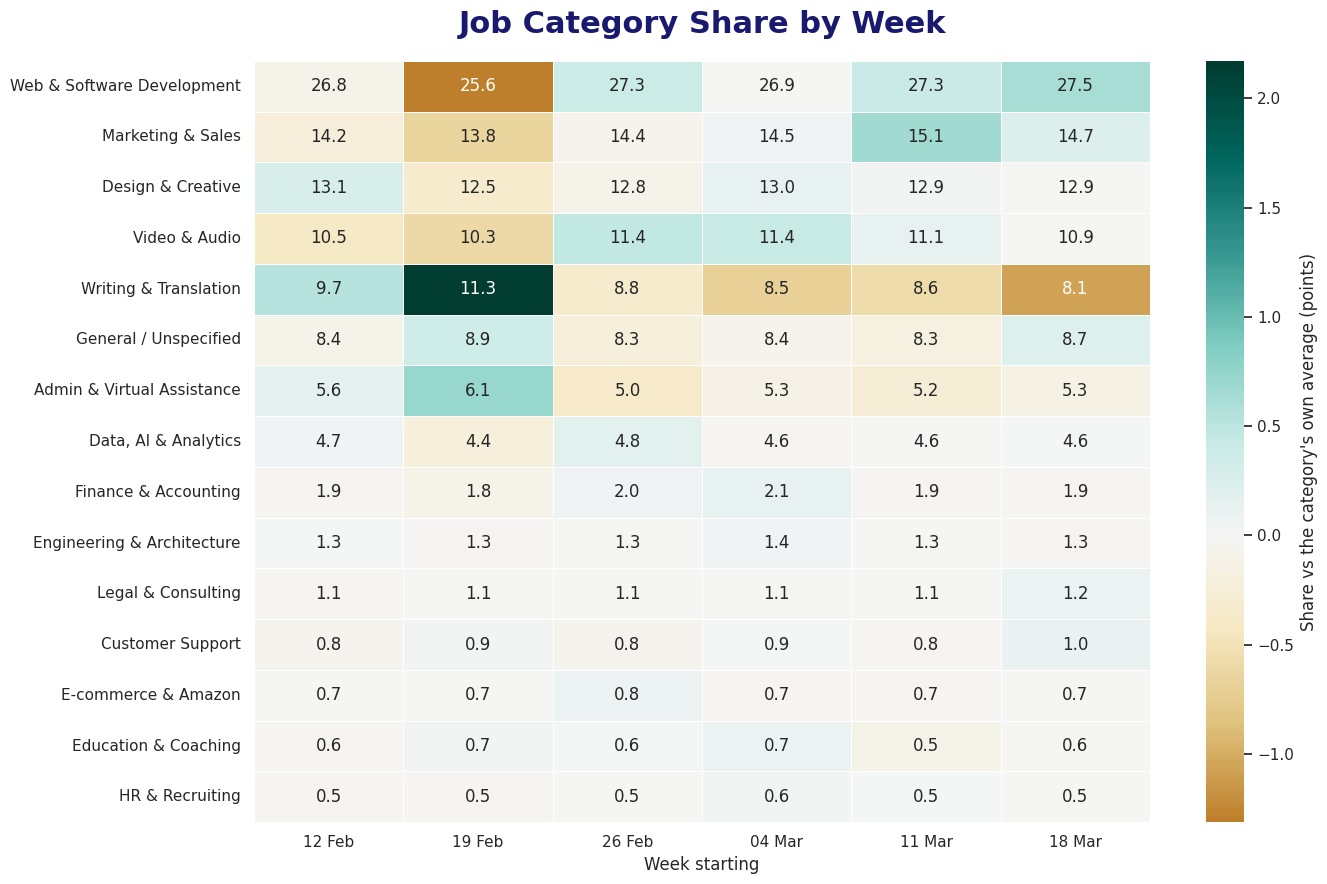

2026-11-23 16:55:03,335 - job_market_analysis - INFO - Category mix plotted — 15 categories across 6 periods


In [73]:
subsection_header("Task 6: Market Dynamics — Category Mix by Week")

period_start = window_postings["posted_day"].dt.to_period(DASHBOARD_PERIOD).dt.start_time
category_mix = pd.crosstab(period_start, window_postings["job_category"], normalize="index").mul(100).T
category_mix = category_mix.loc[category_mix.mean(axis=1).sort_values(ascending=False).index]
category_vs_average = category_mix.sub(category_mix.mean(axis=1), axis=0)
category_mix.columns = category_vs_average.columns = [f"{start:%d %b}" for start in category_mix.columns]

fig, ax = plt.subplots(figsize=(14, 9))
sns.heatmap(category_vs_average, annot=category_mix, fmt=".1f", cmap="BrBG", center=0, linewidths=0.5, linecolor="white",
            annot_kws={"fontsize": 12}, cbar_kws={"label": "Share vs the category's own average (points)"}, ax=ax)
ax.set_title(f"Job Category Share by {period_label}", fontsize=22, color=PLOT_COLOR, fontweight="bold", pad=20)
ax.set_xlabel(f"{period_label} starting")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("Assets/task6_dynamics_category_mix.png", dpi=150, bbox_inches="tight")
plt.show()

info_box(f"Cells show each category's share of postings in the {period_label.lower()}; colour shows the difference from that category's average across all {len(category_mix.columns)} periods. "
         "Periods with fewer full days have fewer postings behind them, so their shares are less certain.")
logger.info(f"Category mix plotted — {len(category_mix)} categories across {len(category_mix.columns)} periods")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Category Mix by Week:**

- **Web & Software Development leads every week:** its share ranges from 25.6% (week of 19 Feb) to 27.5% (week of 18 Mar), the largest category by a wide margin.
- **One week stands out:** in the week of 19 Feb, Writing & Translation reaches 11.3% against 8.1% to 9.7% in the other weeks, the biggest deviation in the chart. Admin & Virtual Assistance is also above its average that week (6.1%). Shares add up to 100%, so Web, Marketing and Design all dip below their averages in the same week.
- **Writing & Translation falls afterwards:** 8.8%, 8.5%, 8.6% and 8.1% in the last four weeks. This agrees with the falling trend found earlier, but the 19 Feb spike also raises the first-half average, so part of the fall comes from that one week.
- **Marketing & Sales rises:** its share averages 14.1% over the first three weeks and 14.8% over the last three, matching the rising trend.
- **Video & Audio steps up:** it moves from about 10.4% to 11.4% in the week of 26 Feb and slips back to 10.9%.
- **Small categories barely move:** the eight categories below 2% each stay within about 0.3 points all period, so their colours are pale.
- **Colours compare each category with itself:** a strong colour on a small category and on a large one mean different amounts of postings, so compare the numbers across categories.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 6: Dashboard Metrics — Latest Period vs Previous

<div style="margin-left: 20px; max-width: 90%">

A monthly dashboard is useful when it says what changed. The newest period is compared with the one before it and with the range of all earlier periods. A measure outside that earlier range is flagged, which is how new trends are surfaced each time new postings are added.

</div>

In [74]:
subsection_header("Task 6: Dashboard Metrics — Latest Period vs Previous")

def latest_vs_history(summary, measures):
    """Compares the newest period with the one before and with the range of all earlier periods; the dashboard shows this as its 'what is new' panel."""
    latest, previous, history = summary.iloc[-1], summary.iloc[-2], summary.iloc[:-1]
    rows = []
    for measure in measures:
        low, high = history[measure].min(), history[measure].max()
        status = "Above earlier range" if latest[measure] > high else "Below earlier range" if latest[measure] < low else "Within earlier range"
        rows.append({"Measure": measure, "Latest": latest[measure], "Previous": previous[measure], "Change (%)": (latest[measure] / previous[measure] - 1) * 100,
                     "Earlier Low": low, "Earlier High": high, "Status": status})
    return pd.DataFrame(rows)

DASHBOARD_MEASURES = ["Postings per Day", "Freelancer Share (%)", "Remote Share (%)", "Average Hourly Rate (units)", "Average Salary (units)"]
latest_view = latest_vs_history(period_summary, DASHBOARD_MEASURES)
centered_table(latest_view, float_format="{:,.2f}")

info_box(f"The latest {period_label.lower()} starts {period_summary.index[-1]:%d %b %Y} ({int(period_summary['Full Days'].iloc[-1])} full days) and is compared with the previous {period_label.lower()} "
         f"and with the range of the {len(period_summary) - 1} earlier ones. Flagged measures: {int((latest_view['Status'] != 'Within earlier range').sum())} of {len(latest_view)}.")
logger.info(f"Latest period compared — {dict(zip(latest_view['Measure'], latest_view['Status']))}")

Measure,Latest,Previous,Change (%),Earlier Low,Earlier High,Status
Postings per Day,"6,351.50","6,144.00",3.38,"5,305.00","6,506.14",Within earlier range
Freelancer Share (%),57.42,56.53,1.57,56.53,58.54,Within earlier range
Remote Share (%),0.61,0.52,16.89,0.52,0.58,Above earlier range
Average Hourly Rate (units),28.67,28.44,0.81,28.44,29.35,Within earlier range
Average Salary (units),461.12,475.37,-3.00,450.43,494.41,Within earlier range


2026-11-23 16:55:03,358 - job_market_analysis - INFO - Latest period compared — {'Postings per Day': 'Within earlier range', 'Freelancer Share (%)': 'Within earlier range', 'Remote Share (%)': 'Above earlier range', 'Average Hourly Rate (units)': 'Within earlier range', 'Average Salary (units)': 'Within earlier range'}


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Latest Period vs Previous:**

- **One measure is flagged:** remote share is 0.61% in the latest week, above the earlier range of 0.52% to 0.58% and 16.9% higher than the previous week (0.52%). In points that is only 0.09.
- **Read the flag as a prompt to watch, not a trend:** about 34 postings a day are remote, so weekly shares move easily, and the half-against-half test found no significant remote shift. It does match the late rise seen in the daily chart.
- **Everything else is within the earlier range:** postings per day are up 3.4% (6,352 against 6,144), Freelancer share up 1.6% (57.42% against 56.53%), average hourly rate up 0.8% (28.67 against 28.44) and average salary down 3.0% (461 against 475).
- **The latest week has 6 full days:** per-day and share measures are still comparable, but they rest on fewer days.
- **The flag rule is strict early on:** it compares the newest period with the minimum and maximum of the earlier ones. With only 5 earlier weeks the range is narrow (0.06 points for remote share), so flags are easy to trigger. The range widens as more periods are collected.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 6: Dashboard Metrics — Dashboard Preview

<div style="margin-left: 20px; max-width: 90%">

This is a preview of the monthly dashboard: the same measures that feed the app, one panel each, for every period. Each panel starts at zero, so small movements are not made to look large.

</div>

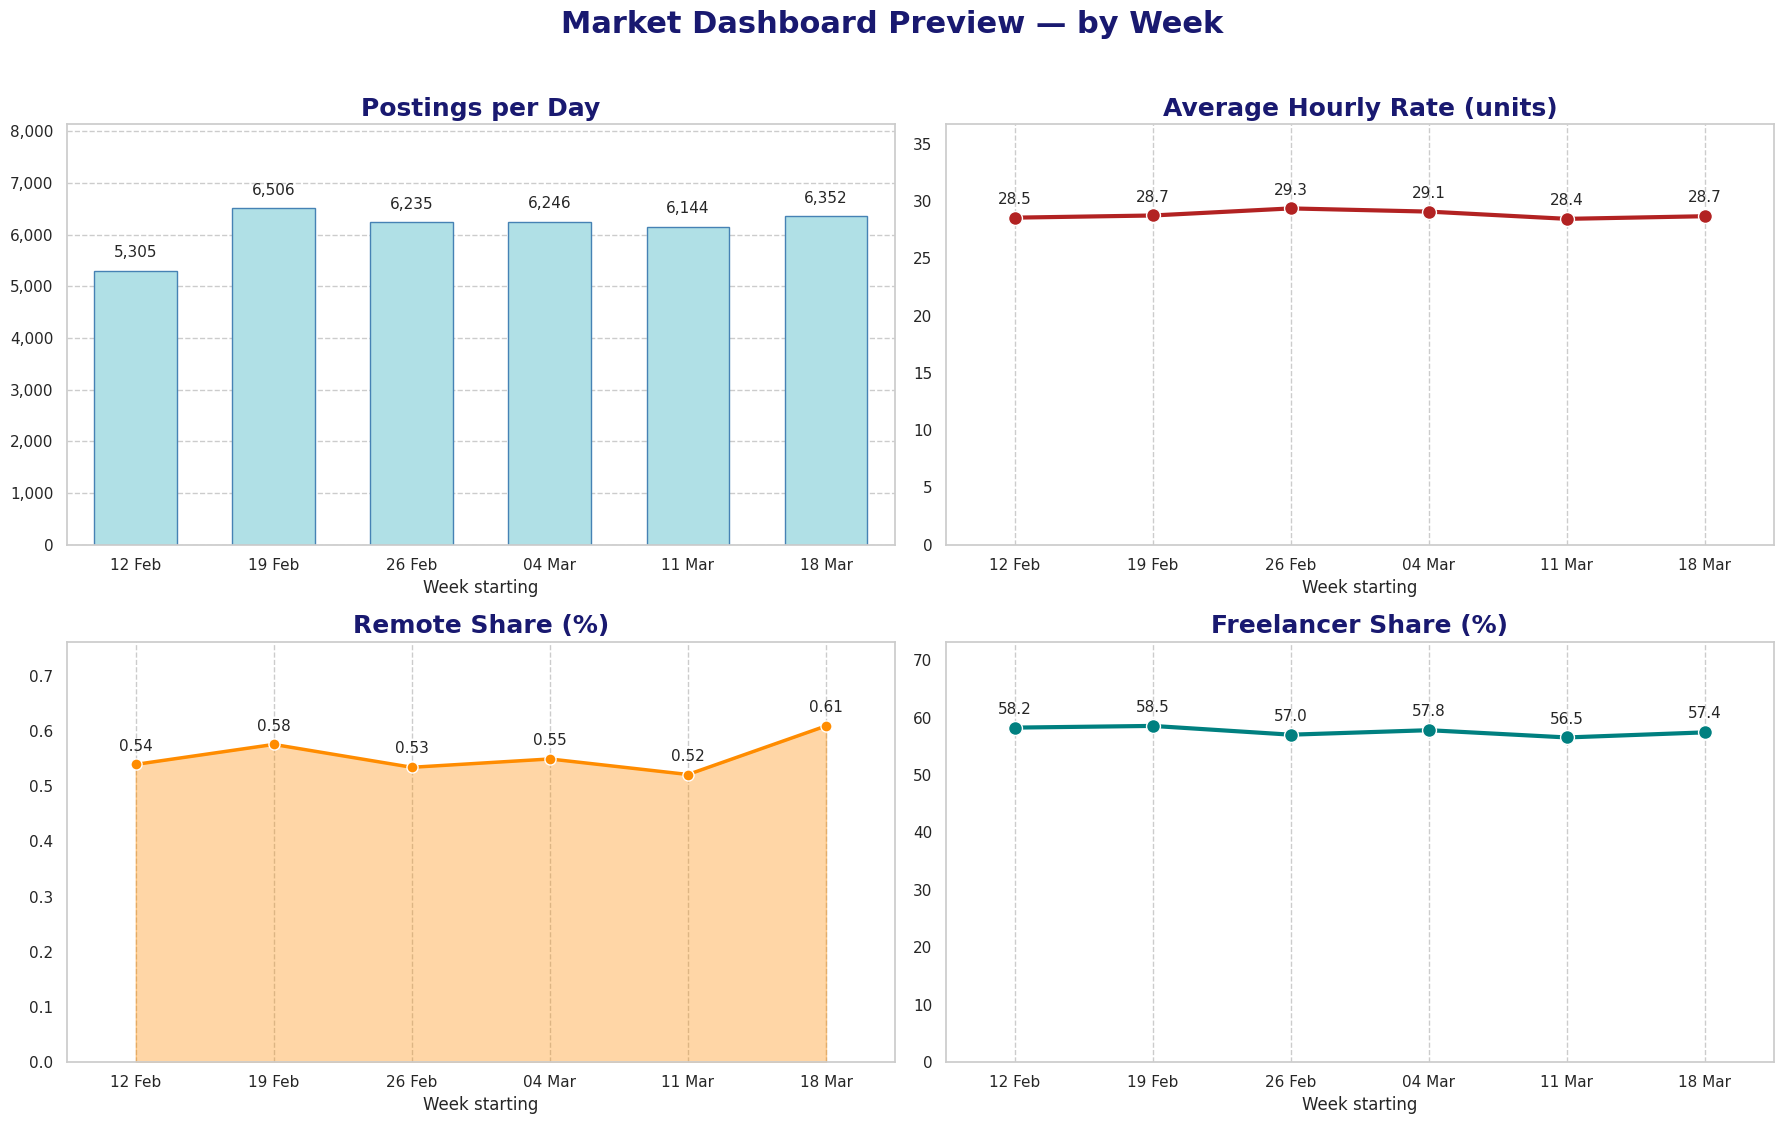

2026-11-23 16:55:04,873 - job_market_analysis - INFO - Dashboard preview saved — 6 periods


In [75]:
subsection_header("Task 6: Dashboard Metrics — Dashboard Preview")

labels = period_summary.index.strftime("%d %b")
positions = np.arange(len(labels))
panels = [("Postings per Day", "bar", "powderblue", "{:,.0f}"), ("Average Hourly Rate (units)", "line", "firebrick", "{:.1f}"),
          ("Remote Share (%)", "area", "darkorange", "{:.2f}"), ("Freelancer Share (%)", "line", "teal", "{:.1f}")]

fig, axes = plt.subplots(2, 2, figsize=(18, 11))
fig.suptitle(f"Market Dashboard Preview — by {period_label}", fontsize=22, color=PLOT_COLOR, fontweight="bold", y=1.02)
fig.subplots_adjust(hspace=0.45, wspace=0.25)
for ax, (measure, kind, color, number_format) in zip(axes.ravel(), panels):
    values = period_summary[measure].to_numpy()
    if kind == "bar":
        ax.bar(positions, values, color=color, edgecolor="steelblue", width=0.6)
    elif kind == "area":
        ax.fill_between(positions, values, color=color, alpha=0.35)
        ax.plot(positions, values, color=color, linewidth=2.5, marker="o", markersize=8, markeredgecolor="white")
    else:
        ax.plot(positions, values, color=color, linewidth=3, marker="o", markersize=10, markeredgecolor="white")
    for position, value in zip(positions, values):
        ax.annotate(number_format.format(value), (position, value), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=11)
    ax.set_xticks(positions)
    ax.set_xticklabels(labels)
    ax.set_ylim(0, values.max() * 1.25)
    ax.set_xlim(-0.5, len(positions) - 0.5)
    if measure == "Postings per Day":
        ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
    ax.set_title(measure, fontweight="bold", fontsize=18)
    ax.set_xlabel(f"{period_label} starting")
    ax.grid(axis='x', linestyle="--", alpha=0.4,visible=True)
    ax.grid(axis='y',visible=False)
    if kind == "bar":
        ax.grid(axis="x", visible=False)
        ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("Assets/task6_dashboard_preview.png", dpi=150, bbox_inches="tight")
plt.show()

info_box(f"Each panel is one dashboard tile. The first {period_label.lower()} has {int(period_summary['Full Days'].iloc[0])} full days, so volume is shown per day. When three calendar months are covered the same code switches to months.")
logger.info(f"Dashboard preview saved — {len(period_summary)} periods")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Dashboard Preview:**

- **Volume is steady:** after the first week (5,305 per day, with 5 full days), postings stay between 6,144 and 6,506 per day.
- **The hourly rate is flat:** 28.4 to 29.3 units across the six weeks. On a zero-based axis the line sits near the top, which shows how small the movement is.
- **Remote share is the only visible movement:** it stays between 0.52% and 0.58% and rises to 0.61% in the last week.
- **The contract mix is stable:** Freelancer share stays between 56.5% and 58.5%.
- **What this means:** over these six weeks the market is stable, so the dashboard mainly shows a steady baseline. Its value is the refresh: once three calendar months are collected the same code switches to months and starts showing real month-to-month change.

</div>

<hr style="width:60%; margin:auto;">

In [76]:
flagged_measures = ", ".join(latest_view.loc[latest_view["Status"] != "Within earlier range", "Measure"]) or "none"
display(HTML(f"""
<div style="text-align:center;margin-top:40px;margin-bottom:30px;">
    <h3 style="color:{SUCCESS_TEXT};"><b>✅ Checkpoint: Period Aggregation & Dashboard Metrics Complete</b></h3>
    <p style="font-style:italic;font-size:1.05em;opacity:0.85;">
        The market is summarised by <b>{period_label.lower()}</b> across <b>{len(period_summary)} {period_label.lower()}s</b> of full days, with a category mix, a latest-versus-history comparison and a dashboard preview.
        Measures outside their earlier range in the latest {period_label.lower()}: <b>{flagged_measures}</b>.<br>
        Forecasting ahead: which job categories will be in demand, and how remote work may move.
    </p>
    <hr style="width:45%;">
</div>"""))

## 08. Time Series Forecasting

<div style="margin-left: 20px; max-width: 90%">

### 📌 Task 3: Demand Forecasting — Daily Demand Panel

<div style="margin-left: 20px; max-width: 90%">

Demand for a job role is measured as the number of postings its category receives each day. The daily counts form a panel, one column per category and one row per full day, which every forecasting model uses. "General / Unspecified" is left out because it is not a role. For each category the table shows the average daily postings, how much the daily count varies, and the busiest and quietest weekdays.

</div>
</div>

In [77]:
section_header("Time Series Forecasting")
subsection_header("Task 3: Demand Forecasting — Daily Demand Panel")

demand_panel = pd.crosstab(window_postings["posted_day"], window_postings["job_category"]).drop(columns="General / Unspecified")
weekday_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_average = demand_panel.groupby(demand_panel.index.dayofweek).mean()

panel_summary = pd.DataFrame({"Category": demand_panel.columns, "Average per Day": demand_panel.mean().to_numpy(),
                              "Variation (%)": (demand_panel.std() / demand_panel.mean() * 100).to_numpy(),
                              "Busiest Weekday": [weekday_names[day] for day in weekday_average.idxmax()],
                              "Quietest Weekday": [weekday_names[day] for day in weekday_average.idxmin()]}).sort_values("Average per Day", ascending=False).reset_index(drop=True)
centered_table(panel_summary, float_format="{:,.1f}")

info_box(f"{len(demand_panel)} full days and {demand_panel.shape[1]} categories. Variation is the day-to-day standard deviation as a percentage of the average; "
         "small categories vary more because their daily counts are small.")
logger.info(f"Demand panel built — {demand_panel.shape[0]} days x {demand_panel.shape[1]} categories")

Category,Average per Day,Variation (%),Busiest Weekday,Quietest Weekday
Web & Software Development,"1,658.8",17.3,Thursday,Sunday
Marketing & Sales,891.6,19.0,Thursday,Sunday
Design & Creative,791.2,15.8,Monday,Sunday
Video & Audio,676.1,15.1,Thursday,Sunday
Writing & Translation,566.4,24.2,Wednesday,Sunday
Admin & Virtual Assistance,333.3,22.5,Wednesday,Sunday
"Data, AI & Analytics",283.2,18.5,Thursday,Sunday
Finance & Accounting,121.0,21.4,Monday,Sunday
Engineering & Architecture,82.1,20.0,Wednesday,Sunday
Legal & Consulting,69.5,24.0,Tuesday,Sunday


2026-11-23 16:55:04,979 - job_market_analysis - INFO - Demand panel built — 39 days x 14 categories


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Daily Demand Panel:**

- **Demand is concentrated:** Web & Software Development receives about 1,659 postings a day, nearly double Marketing & Sales (892), and the next five (Design, Video, Writing, Admin, Data) range from 791 down to 283. HR & Recruiting is smallest at about 33 a day.
- **Small categories are noisier:** day-to-day variation is 15% to 24% for the large roles but 30.1% for Customer Support and 31.5% for HR & Recruiting, so forecasts for small categories will be less reliable.
- **Weekends are quiet:** Sunday is the quietest day for 12 of the 14 categories and Saturday for the other two (Customer Support and HR & Recruiting).
- **The busiest day varies:** Thursday leads for 7 categories, Wednesday for 3, Monday for 2 and Tuesday for 2, so the weekday peak differs by role, though all peak early in the week.
- **What this means for forecasting:** even a good model should expect errors of roughly this variation size for each category, and the ranking of high-demand roles is stable because the gaps between the large categories are wide.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 3: Demand Forecasting — Weekly Pattern

<div style="margin-left: 20px; max-width: 90%">

Before choosing forecasting models it is worth knowing whether demand repeats over the week. Each weekday's average postings are shown as an index where 100 is the average day, for all postings and for the five largest roles. A clear weekly pattern means models that use the day of the week have an advantage.

</div>

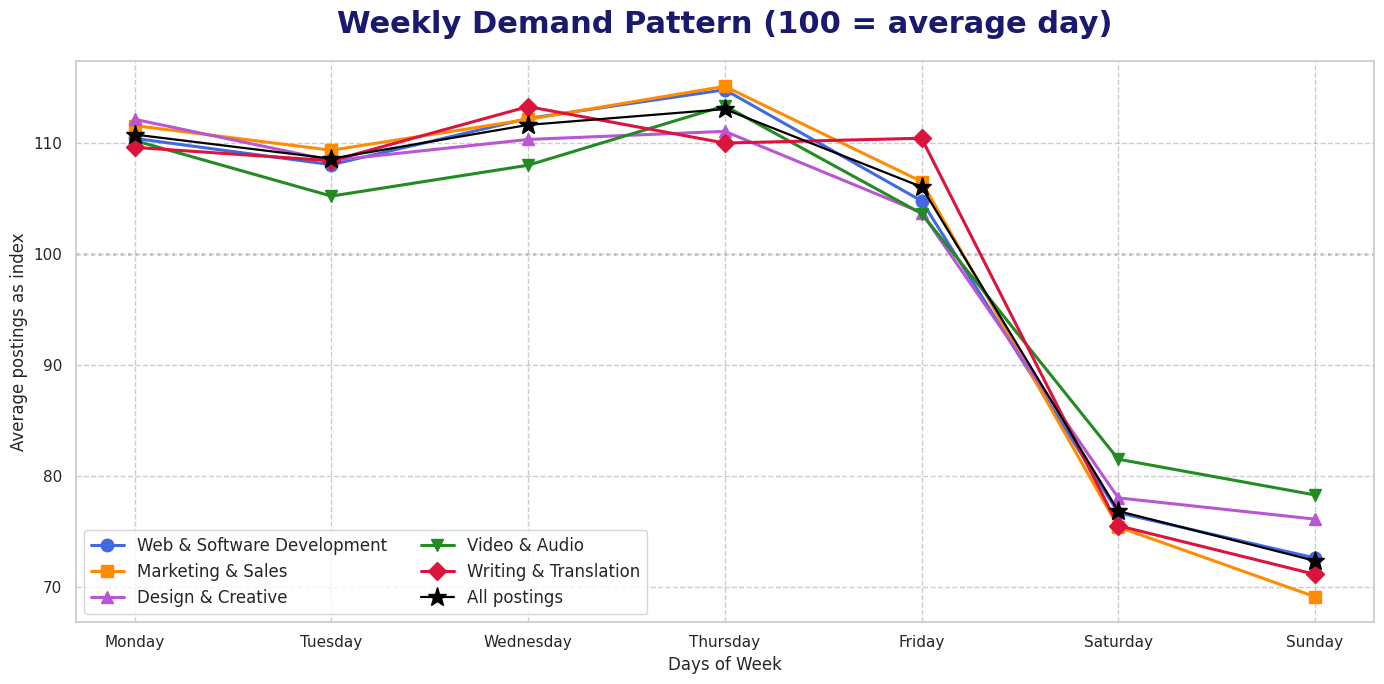

2026-11-23 16:55:05,631 - job_market_analysis - INFO - Weekly pattern plotted — busiest Thursday, quietest Sunday


In [78]:
subsection_header("Task 3: Demand Forecasting — Weekly Pattern")

daily_total = window_postings.groupby("posted_day").size()
largest_roles = panel_summary["Category"].head(5)
weekday_index = pd.DataFrame({"All postings": daily_total.groupby(daily_total.index.dayofweek).mean() / daily_total.mean() * 100,
                              **{role: weekday_average[role] / demand_panel[role].mean() * 100 for role in largest_roles}})

fig, ax = plt.subplots(figsize=(14, 7))
role_styles = [("royalblue", "o"), ("darkorange", "s"), ("mediumorchid", "^"), ("forestgreen", "v"), ("crimson", "D")]
for role, (color, marker) in zip(largest_roles, role_styles):
    ax.plot(weekday_names, weekday_index[role], color=color, linewidth=2.2, marker=marker, markersize=9, label=role, zorder=3)
ax.plot(weekday_names, weekday_index["All postings"], color="black", linewidth=1.6, marker="*", markersize=14, label="All postings", zorder=4)
ax.axhline(100, color="silver", linestyle=":", linewidth=2, zorder=1)
ax.set_title("Weekly Demand Pattern (100 = average day)", fontsize=22, color=PLOT_COLOR, fontweight="bold", pad=20)
ax.set_xlabel("Days of Week")
ax.set_ylabel("Average postings as index")
ax.legend(fontsize=12, ncol=2)
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("Assets/task3_forecasting_weekly_pattern.png", dpi=150, bbox_inches="tight")
plt.show()

overall = weekday_index["All postings"]
info_box(f"Across all postings the busiest weekday is {weekday_names[overall.idxmax()]} ({overall.max():.0f}) and the quietest is {weekday_names[overall.idxmin()]} ({overall.min():.0f}). "
         f"The index is built from {len(daily_total)} full days, about {len(daily_total) / 7:.1f} of each weekday, so single-weekday values are rough.")
logger.info(f"Weekly pattern plotted — busiest {weekday_names[overall.idxmax()]}, quietest {weekday_names[overall.idxmin()]}")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Weekly Demand Pattern:**

- **A strong weekly cycle:** postings run 5% to 15% above the average day from Monday to Friday and drop to about 70% to 80% of it on Saturday and Sunday, so the weekend is roughly a quarter below an average day.
- **Thursday peaks overall:** the all-postings index is highest on Thursday, at about 113, and lowest on Sunday, at about 72.
- **The five largest roles share one shape:** their lines move together, which shows the weekly cycle belongs to the whole market and not to one category.
- **Differences between roles:** Video & Audio has the mildest weekend dip (about 81 on Saturday and 78 on Sunday), Marketing & Sales has the deepest on Sunday (about 69), and Writing & Translation peaks on Wednesday and stays high on Friday.
- **What this means for forecasting:** with a repeating 7-day pattern, methods that use the day of the week should beat a method that ignores it. The 39 days cover more than five full weeks, enough to learn this pattern.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 3: Demand Forecasting — Rolling-Origin Validation

<div style="margin-left: 20px; max-width: 90%">

Which method forecasts daily demand best? Five classical methods are compared with rolling-origin validation: each is fitted on the earlier days and asked to forecast the next 7 days, then the window moves forward a week, three times in all. Time order is never mixed, because a random split would let the model see the future. Seasonal Naive repeats the same weekday of the previous week and is the baseline. Weekday Average uses the average of that weekday over all earlier weeks. Linear Regression (calendar) predicts postings from a straight-line trend and the day of the week. Holt-Winters tracks the current level and a repeating weekly pattern and gives recent days more weight than older ones. SARIMA predicts each day from the previous day and from the same weekday of the previous week.

</div>

In [79]:
subsection_header("Task 3: Demand Forecasting — Rolling-Origin Validation")

HORIZON, FOLDS = 7, 3
day_count = len(demand_panel)
weekday_of_day = demand_panel.index.dayofweek.to_numpy()
origins = [day_count - HORIZON * step for step in range(FOLDS, 0, -1)]            # the first day of each 7-day test window

def calendar_features(positions):
    weekday = pd.get_dummies(pd.Categorical(weekday_of_day[positions], categories=range(7)), drop_first=True, dtype=float).to_numpy()
    return np.column_stack([positions, weekday])

def seasonal_naive(train, train_pos, test_pos):
    lookup = dict(zip(train_pos, train))
    return np.array([lookup[pos - 7] for pos in test_pos], dtype=float)

def weekday_mean(train, train_pos, test_pos):
    weekdays = weekday_of_day[train_pos]
    return np.array([train[weekdays == weekday_of_day[pos]].mean() for pos in test_pos])

def holt_winters(train, train_pos, test_pos):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fitted = ExponentialSmoothing(train, trend="add", damped_trend=True, seasonal="add", seasonal_periods=7, initialization_method="estimated").fit()
    return fitted.forecast(len(test_pos))

def sarima(train, train_pos, test_pos):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fitted = SARIMAX(train, order=(1, 0, 0), seasonal_order=(1, 0, 0, 7), trend="c").fit(disp=False)
    return fitted.forecast(len(test_pos))

def weekday_trend_regression(train, train_pos, test_pos):
    return LinearRegression().fit(calendar_features(train_pos), train).predict(calendar_features(test_pos))

FORECASTERS = {"Seasonal Naive (baseline)": seasonal_naive, "Weekday Average": weekday_mean, "Holt-Winters": holt_winters,"SARIMA": sarima, "Linear Regression (calendar)": weekday_trend_regression}

records = []
for model_name, forecaster in FORECASTERS.items():
    for fold, origin in enumerate(origins, start=1):
        train_pos, test_pos = np.arange(origin), np.arange(origin, origin + HORIZON)
        for category in demand_panel.columns:
            values = demand_panel[category].to_numpy(dtype=float)
            predicted = np.clip(forecaster(values[train_pos], train_pos, test_pos), 0, None)
            records.append(pd.DataFrame({"Model": model_name, "Fold": fold, "Category": category, "Position": test_pos, "Actual": values[test_pos], "Predicted": predicted}))
forecast_errors = pd.concat(records, ignore_index=True)
forecast_errors["Absolute Error"] = (forecast_errors["Predicted"] - forecast_errors["Actual"]).abs()
forecast_errors["Squared Error"] = (forecast_errors["Predicted"] - forecast_errors["Actual"]) ** 2

info_box(f"{len(FORECASTERS)} classical models forecast {FOLDS} rolling windows of {HORIZON} days for {demand_panel.shape[1]} categories; the earliest window trains on {origins[0]} days. "
         "Errors are compared in the next table together with the neural network.")
logger.info(f"Rolling-origin forecasts built — {len(FORECASTERS)} models, {FOLDS} folds")

2026-11-23 16:55:23,709 - job_market_analysis - INFO - Rolling-origin forecasts built — 5 models, 3 folds


### 📌 Task 3: Demand Forecasting — Model Comparison

<div style="margin-left: 20px; max-width: 90%">

A GRU is a small neural network that reads a sequence, here the last 7 days of postings, and learns patterns in it. One network is trained on all categories together, each scaled by its own average so large and small categories are comparable, and it predicts the next 7 days. It is tested on the same three rolling folds as the other methods, so the comparison is fair.

Errors are shown as MAE and RMSE in postings per category per day, and as WAPE, the total absolute error as a percentage of total actual postings, which compares fairly across large and small categories. The table compares all six models.

Neural networks need many examples, so the number of training windows in each fold is shown below the table.

</div>

In [80]:
subsection_header("Task 3: Demand Forecasting — Model Comparison")

LOOKBACK = 7

def gru_forecast(origin):
    """Trains a small GRU on every category's earlier days (scaled by that category's average) and forecasts the next HORIZON days for all categories."""
    keras.utils.set_random_seed(42)
    levels = demand_panel.iloc[:origin].mean()
    scaled = (demand_panel / levels).to_numpy(dtype="float32")
    windows, first_weekdays, targets = [], [], []
    for column in range(scaled.shape[1]):
        for start in range(LOOKBACK, origin - HORIZON + 1):
            windows.append(scaled[start - LOOKBACK:start, column])
            first_weekdays.append(np.eye(7, dtype="float32")[weekday_of_day[start]])
            targets.append(scaled[start:start + HORIZON, column])
    windows, first_weekdays, targets = np.array(windows)[..., None], np.array(first_weekdays), np.array(targets)

    sequence_input, weekday_input = keras.Input(shape=(LOOKBACK, 1)), keras.Input(shape=(7,))
    hidden = keras.layers.concatenate([keras.layers.GRU(16)(sequence_input), weekday_input])
    output = keras.layers.Dense(HORIZON)(keras.layers.Dense(16, activation="relu")(hidden))
    network = keras.Model([sequence_input, weekday_input], output)
    network.compile(optimizer=keras.optimizers.Adam(0.01), loss="mae")
    network.fit([windows, first_weekdays], targets, epochs=150, batch_size=32, verbose=0)

    last_windows = scaled[origin - LOOKBACK:origin].T[..., None]
    next_weekday = np.tile(np.eye(7, dtype="float32")[weekday_of_day[origin]], (scaled.shape[1], 1))
    return np.clip(network([last_windows, next_weekday], training=False).numpy(), 0, None) * levels.to_numpy()[:, None], len(targets)

gru_records, training_windows = [], []
for fold, origin in enumerate(origins, start=1):
    forecast, window_count = gru_forecast(origin)
    training_windows.append(window_count)
    for position, category in enumerate(demand_panel.columns):
        gru_records.append(pd.DataFrame({"Model": "GRU", "Fold": fold, "Category": category,
                                         "Actual": demand_panel[category].to_numpy(dtype=float)[origin:origin + HORIZON], "Predicted": forecast[position]}))
gru_errors = pd.concat(gru_records, ignore_index=True)
all_errors = pd.concat([forecast_errors, gru_errors], ignore_index=True)
all_errors["Absolute Error"] = (all_errors["Predicted"] - all_errors["Actual"]).abs()
all_errors["Squared Error"] = (all_errors["Predicted"] - all_errors["Actual"]) ** 2

by_fold = all_errors.groupby(["Model", "Fold"]).agg(absolute_sum=("Absolute Error", "sum"), actual_sum=("Actual", "sum"))
by_fold["WAPE"] = by_fold["absolute_sum"] / by_fold["actual_sum"] * 100
forecast_comparison = pd.DataFrame({"MAE (postings/day)": all_errors.groupby("Model")["Absolute Error"].mean(),
                                    "RMSE (postings/day)": np.sqrt(all_errors.groupby("Model")["Squared Error"].mean()),
                                    "WAPE (%)": by_fold["WAPE"].groupby("Model").mean(),
                                    "Worst Fold WAPE (%)": by_fold["WAPE"].groupby("Model").max()}).reindex(list(FORECASTERS) + ["GRU"])
baseline_wape = forecast_comparison.loc["Seasonal Naive (baseline)", "WAPE (%)"]
forecast_comparison["Improvement vs Baseline (%)"] = (baseline_wape - forecast_comparison["WAPE (%)"]) / baseline_wape * 100
forecast_best = forecast_comparison["WAPE (%)"].idxmin()

centered_table(forecast_comparison.reset_index().rename(columns={"Model": "Forecasting Model"}), float_format="{:,.2f}")
info_box(f"The GRU was trained on {', '.join(f'{count:,}' for count in training_windows)} windows in folds 1 to 3 (7 days of history each). All six models use the same folds and error measures. "
         f"Lowest WAPE: {forecast_best} ({forecast_comparison.loc[forecast_best, 'WAPE (%)']:.2f}%).")
logger.info(f"Forecast comparison with neural tier — best={forecast_best}")

Forecasting Model,MAE (postings/day),RMSE (postings/day),WAPE (%),Worst Fold WAPE (%),Improvement vs Baseline (%)
Seasonal Naive (baseline),22.63,34.79,5.62,6.11,0.00
Weekday Average,25.47,41.96,6.32,6.49,-12.44
Holt-Winters,21.61,33.89,5.36,5.70,4.67
SARIMA,32.29,55.54,8.00,9.44,-42.32
Linear Regression (calendar),31.51,52.31,7.81,8.95,-38.92
GRU,25.48,41.46,6.33,6.70,-12.47


2026-11-23 16:56:02,698 - job_market_analysis - INFO - Forecast comparison with neural tier — best=Holt-Winters


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Forecasting Model Comparison:**

- **Holt-Winters is the only model that beats the baseline:** its WAPE is 5.36% against 5.62% for Seasonal Naive (4.7% better), and it also has the lowest MAE (21.61) and RMSE (33.89). Its worst fold (5.70%) is better than the baseline's worst fold (6.11%).
- **The gain is small:** the difference is about 0.26 points of WAPE over only three folds, so the baseline is a strong reference and the forecast will be shown with intervals.
- **The neural network does not help:** the GRU reaches a WAPE of 6.33%, 12.5% worse than the baseline and level with the simple Weekday Average (6.32%). With 70 to 266 training windows per fold it has too few examples to learn more than the weekly pattern.
- **Models that follow a trend do worst:** SARIMA (8.00%) and Linear Regression (calendar) (7.81%) are about 40% worse than the baseline, with worst folds of 9.44% and 8.95%. A trend fitted on 18 to 32 days overshoots.
- **Models that use the latest level win:** Seasonal Naive and Holt-Winters both stay close to the most recent week, which suits a market whose level shifts from week to week.
- **Decision:** Holt-Winters is used for the forecasts that follow. It is not tuned further, since its gain over the baseline is small and the settings were fixed in advance.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 3: Demand Forecasting — Model Comparison Chart

<div style="margin-left: 20px; max-width: 90%">

The table is easier to judge as a picture. Bars show each model's WAPE, where lower is better, and the line shows its RMSE. Models are sorted from best to worst, the best is highlighted with a star, and the dashed line marks the Seasonal Naive baseline.

</div>

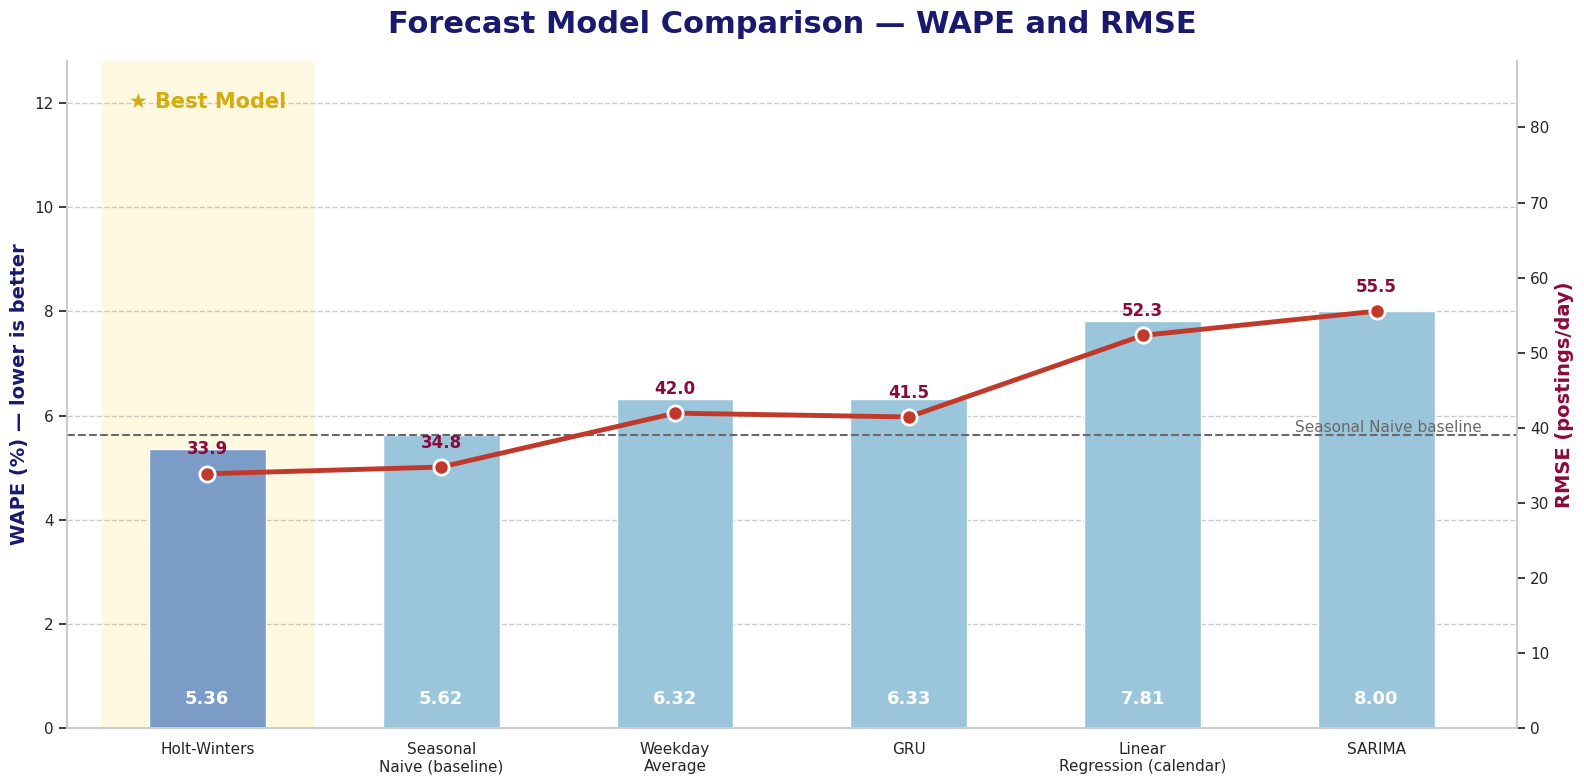

2026-11-23 16:56:03,472 - job_market_analysis - INFO - Forecast comparison chart saved — best=Holt-Winters


In [81]:
subsection_header("Task 3: Demand Forecasting — Model Comparison Chart")

BAR_COLOR, BEST_BAR_COLOR, LINE_COLOR, LABEL_COLOR = "#9AC5DB", "#7A9CC6", "#C0392B", "#8B0A3E"
ranked = forecast_comparison.sort_values("WAPE (%)").reset_index()
positions = np.arange(len(ranked))
labels = [name.replace(" ", "\n", 1) for name in ranked["Model"]]

fig, ax = plt.subplots(figsize=(16, 8))
ax.axvspan(-0.45, 0.45, color="#FFF8E1", zorder=0)                                              # the best model is always first after sorting
bars = ax.bar(positions, ranked["WAPE (%)"], width=0.5, color=[BEST_BAR_COLOR] + [BAR_COLOR] * (len(ranked) - 1), zorder=2)
for bar, value in zip(bars, ranked["WAPE (%)"]):
    ax.text(bar.get_x() + bar.get_width() / 2, 0.03, f"{value:.2f}", transform=ax.get_xaxis_transform(), ha="center", va="bottom", color="white", fontweight="bold", fontsize=13, zorder=3)
ax.axhline(baseline_wape, color="dimgray", linestyle="--", linewidth=1.5, zorder=3)
ax.text(len(ranked) - 0.55, baseline_wape, "Seasonal Naive baseline", ha="right", va="bottom", fontsize=11, color="dimgray")
ax.text(0, 0.93, "★ Best Model", transform=ax.get_xaxis_transform(), ha="center", color="#D4AC0D", fontweight="bold", fontsize=15)
ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_xlim(-0.6, len(ranked) - 0.4)
ax.set_ylim(0, ranked["WAPE (%)"].max() * 1.6)
ax.set_ylabel("WAPE (%) — lower is better", color=PLOT_COLOR, fontweight="bold", fontsize=14)
ax.set_title("Forecast Model Comparison — WAPE and RMSE", fontsize=22, color=PLOT_COLOR, fontweight="bold", pad=20)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.grid(axis="x", visible=False)
ax.spines["top"].set_visible(False)

error_ax = ax.twinx()
error_ax.plot(positions, ranked["RMSE (postings/day)"], color=LINE_COLOR, linewidth=3.5, marker="o", markersize=11, markeredgecolor="white", markeredgewidth=2, zorder=5)
for position, value in zip(positions, ranked["RMSE (postings/day)"]):
    error_ax.annotate(f"{value:,.1f}", (position, value), textcoords="offset points", xytext=(0, 14), ha="center", fontsize=12, color=LABEL_COLOR, fontweight="bold")
error_ax.set_ylim(0, ranked["RMSE (postings/day)"].max() * 1.6)
error_ax.set_ylabel("RMSE (postings/day)", color=LABEL_COLOR, fontweight="bold", fontsize=14)
error_ax.grid(False)
error_ax.spines["top"].set_visible(False)
plt.tight_layout()
plt.savefig("Assets/task3_forecasting_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

info_box(f"Best model by WAPE: {ranked.loc[0, 'Model']} ({ranked.loc[0, 'WAPE (%)']:.2f}%). The dashed line is the Seasonal Naive baseline ({baseline_wape:.2f}%); bars above it are worse than simply repeating last week.")
logger.info(f"Forecast comparison chart saved — best={ranked.loc[0, 'Model']}")

### 📌 Task 3: Demand Forecasting — High-Demand Roles

<div style="margin-left: 20px; max-width: 90%">

Holt-Winters, the best model in the comparison, is fitted on all full days of each category and forecasts the next 14 days. Uncertainty is shown as an 80% interval from 500 simulated futures built from the model's own errors. A role is called high-demand when it is among the five with the highest forecast postings per day. The table also shows how each forecast compares with the last 7 days.

</div>

In [82]:
subsection_header("Task 3: Demand Forecasting — High-Demand Roles")

FORECAST_DAYS, HIGH_DEMAND_TOP = 14, 5
future_days = pd.date_range(demand_panel.index[-1] + pd.Timedelta(days=1), periods=FORECAST_DAYS)

forecast_parts, average_interval = {}, {}
for category in demand_panel.columns:
    values = demand_panel[category].to_numpy(dtype=float)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fitted = ExponentialSmoothing(values, trend="add", damped_trend=True, seasonal="add", seasonal_periods=7, initialization_method="estimated").fit()
        paths = np.clip(np.asarray(fitted.simulate(FORECAST_DAYS, repetitions=500, error="add", random_state=42)), 0, None)
    forecast_parts[category] = pd.DataFrame({"forecast": np.clip(fitted.forecast(FORECAST_DAYS), 0, None),
                                             "low": np.percentile(paths, 10, axis=1), "high": np.percentile(paths, 90, axis=1)}, index=future_days)
    average_interval[category] = np.percentile(paths.mean(axis=0), [10, 90])
demand_forecast = pd.concat(forecast_parts, axis=1)

high_demand = pd.DataFrame({"Category": demand_panel.columns, "Last 7 Days (avg/day)": demand_panel.iloc[-7:].mean().to_numpy(),
                            "Forecast (avg/day)": [demand_forecast[category]["forecast"].mean() for category in demand_panel.columns],
                            "80% Interval (avg/day)": [f"{average_interval[category][0]:,.0f} – {average_interval[category][1]:,.0f}" for category in demand_panel.columns]})
high_demand["Change (%)"] = (high_demand["Forecast (avg/day)"] / high_demand["Last 7 Days (avg/day)"] - 1) * 100
high_demand = high_demand.sort_values("Forecast (avg/day)", ascending=False).reset_index(drop=True)
high_demand.insert(0, "Rank", range(1, len(high_demand) + 1))
high_demand["Demand Level"] = np.where(high_demand["Rank"] <= HIGH_DEMAND_TOP, "High demand", "Other")
centered_table(high_demand, float_format="{:,.1f}")

info_box(f"Forecast for {future_days[0]:%d %b} to {future_days[-1]:%d %b}, fitted on {len(demand_panel)} full days. The model was validated on 7-day windows, so the second week of the forecast is less certain than the first. "
         "The intervals come from the model's own errors and may be narrower than real errors.")
logger.info(f"High-demand roles forecast — top {HIGH_DEMAND_TOP}: {high_demand['Category'].head(HIGH_DEMAND_TOP).tolist()}")

Rank,Category,Last 7 Days (avg/day),Forecast (avg/day),80% Interval (avg/day),Change (%),Demand Level
1,Web & Software Development,"1,676.9","1,697.2","1,672 – 1,725",1.2,High demand
2,Marketing & Sales,893.0,913.5,896 – 932,2.3,High demand
3,Design & Creative,787.6,804.0,790 – 819,2.1,High demand
4,Video & Audio,667.9,665.7,609 – 730,-0.3,High demand
5,Writing & Translation,489.1,482.7,335 – 647,-1.3,High demand
6,Admin & Virtual Assistance,316.6,306.2,228 – 392,-3.3,Other
7,"Data, AI & Analytics",277.7,288.5,281 – 296,3.9,Other
8,Finance & Accounting,118.0,117.1,107 – 127,-0.8,Other
9,Engineering & Architecture,80.1,83.5,80 – 87,4.2,Other
10,Legal & Consulting,75.4,72.1,69 – 76,-4.4,Other


2026-11-23 16:56:05,714 - job_market_analysis - INFO - High-demand roles forecast — top 5: ['Web & Software Development', 'Marketing & Sales', 'Design & Creative', 'Video & Audio', 'Writing & Translation']


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — High-Demand Roles:**

- **The top five are stable:** Web & Software Development (1,697 postings a day), Marketing & Sales (914), Design & Creative (804), Video & Audio (666) and Writing & Translation (483) lead the forecast, in the same order as the last 7 days.
- **Large roles are forecast to hold steady:** their changes from the last 7 days are between −3.3% and +2.3%. The bigger percentages (E-commerce +7.0%, Customer Support −6.0%) are in small categories, where a few postings move the figure.
- **Certainty differs by role:** the interval is tight for Web & Software Development (1,672 to 1,725) and Data, AI & Analytics (281 to 296) but wide for Writing & Translation (335 to 647), Admin & Virtual Assistance (228 to 392) and Education & Coaching (30 to 45). The wide ones are also the roles with the most day-to-day variation.
- **Writing & Translation stays low:** its forecast (483 a day) sits near its last 7 days (489) and well below its average over the window (566), which fits the falling trend found earlier. The model does not predict the fall continuing.
- **The intervals are optimistic:** the Web & Software Development interval is about ±1.6%, narrower than the model's validated error of about 5%, so treat the intervals as the minimum uncertainty.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 3: Demand Forecasting — High-Demand Detection Accuracy

<div style="margin-left: 20px; max-width: 90%">

For each validation fold, the five roles with the highest forecast postings are compared with the five roles that actually received the most postings. The hit rate is the share of the real top five that the model also placed in its top five. Accuracy treats every role as high demand or not and counts the share classified correctly.

</div>

In [83]:
subsection_header("Task 3: Demand Forecasting — High-Demand Detection Accuracy")

fold_totals = all_errors.groupby(["Model", "Fold", "Category"])[["Actual", "Predicted"]].sum()
role_count = all_errors["Category"].nunique()
detection_rows = []
for model_name in forecast_comparison.index:
    matches = []
    for fold, part in fold_totals.loc[model_name].groupby(level="Fold"):
        actual_top = set(part["Actual"].nlargest(HIGH_DEMAND_TOP).index.get_level_values("Category"))
        predicted_top = set(part["Predicted"].nlargest(HIGH_DEMAND_TOP).index.get_level_values("Category"))
        matches.append(len(actual_top & predicted_top))
    missed = HIGH_DEMAND_TOP - np.mean(matches)
    detection_rows.append({"Forecasting Model": model_name, "Roles Matched (of 5)": np.mean(matches),
                           "Top-5 Hit Rate (%)": np.mean(matches) / HIGH_DEMAND_TOP * 100,
                           "High-Demand Accuracy (%)": (role_count - 2 * missed) / role_count * 100})
centered_table(pd.DataFrame(detection_rows), float_format="{:,.1f}")

info_box(f"Each of the {all_errors['Fold'].nunique()} validation folds covers 7 days. A role counts as high demand when it is in the top {HIGH_DEMAND_TOP} by total postings.")
logger.info("High-demand detection accuracy computed for every forecasting model")

Forecasting Model,Roles Matched (of 5),Top-5 Hit Rate (%),High-Demand Accuracy (%)
Seasonal Naive (baseline),5.0,100.0,100.0
Weekday Average,5.0,100.0,100.0
Holt-Winters,5.0,100.0,100.0
SARIMA,5.0,100.0,100.0
Linear Regression (calendar),5.0,100.0,100.0
GRU,5.0,100.0,100.0


2026-11-23 16:56:05,819 - job_market_analysis - INFO - High-demand detection accuracy computed for every forecasting model


### 📌 Task 3: Demand Forecasting — Demand Trends and Forecast

<div style="margin-left: 20px; max-width: 90%">

The brief asks for a visual representation of demand over time. Each panel shows one of the six roles with the highest forecast: the daily postings so far (blue), the forecast for the next 14 days (dashed red) and its 80% interval (shaded). The dotted line marks where the history ends. Panels start at zero so the size of the movement is not exaggerated.

</div>

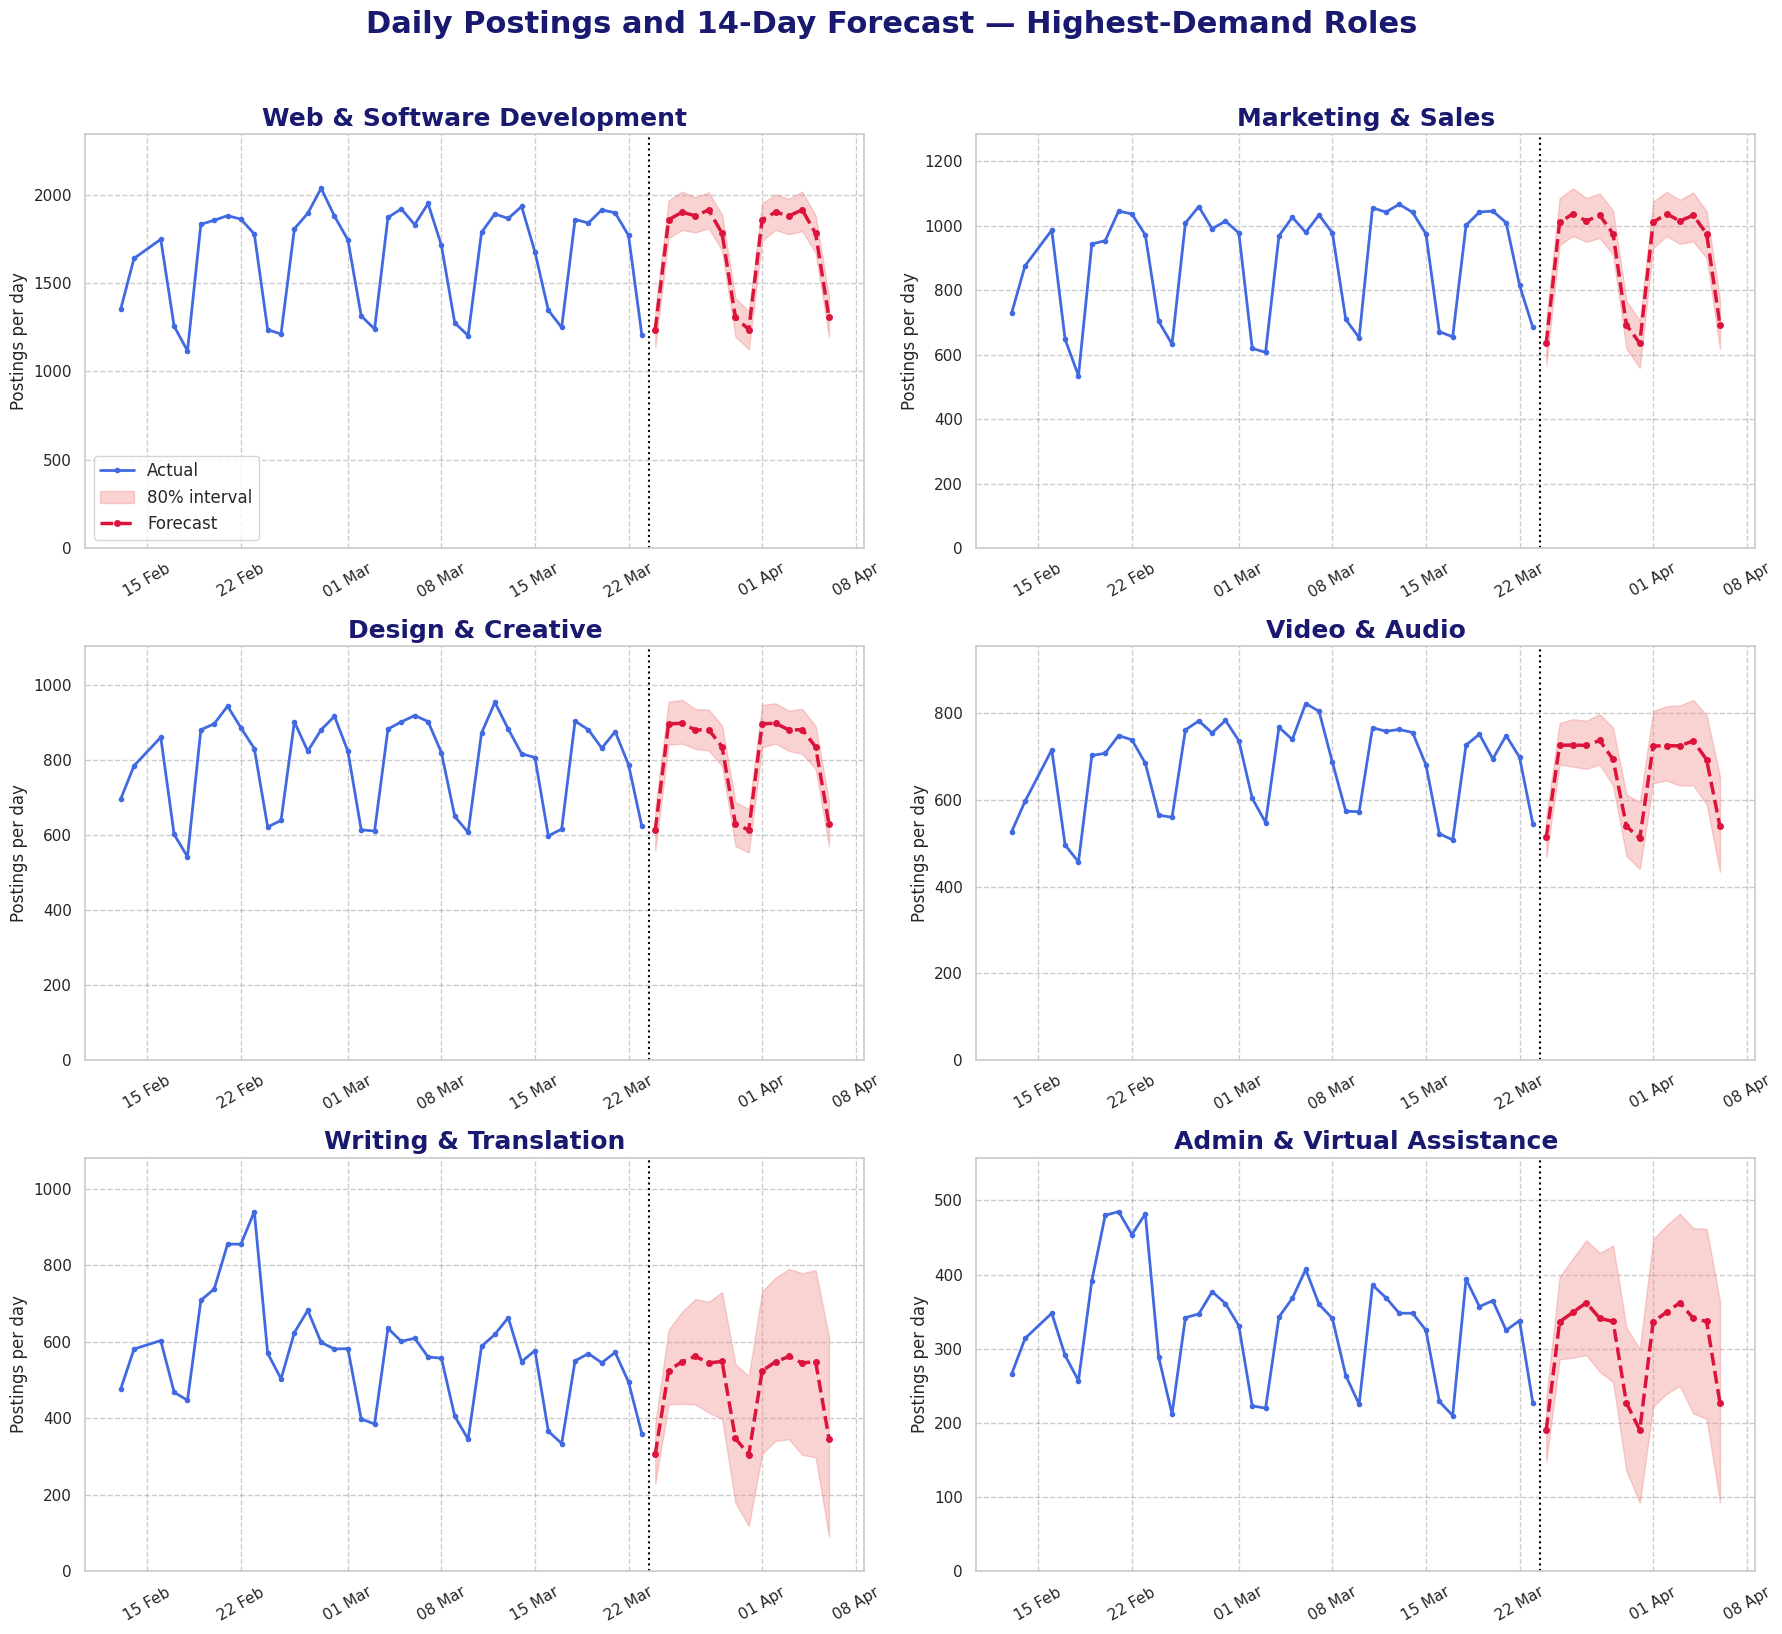

2026-11-23 16:56:09,497 - job_market_analysis - INFO - Demand forecast plotted for ['Web & Software Development', 'Marketing & Sales', 'Design & Creative', 'Video & Audio', 'Writing & Translation', 'Admin & Virtual Assistance']


In [84]:
subsection_header("Task 3: Demand Forecasting — Demand Trends and Forecast")

top_roles = list(high_demand["Category"].head(6))
fig, axes = plt.subplots(3, 2, figsize=(18, 16))
fig.suptitle("Daily Postings and 14-Day Forecast — Highest-Demand Roles", fontsize=22, color=PLOT_COLOR, fontweight="bold", y=1.02)
fig.subplots_adjust(hspace=0.5, wspace=0.2)
for ax, role in zip(axes.ravel(), top_roles):
    history, forecast = demand_panel[role], demand_forecast[role]
    ax.plot(history.index, history, color="royalblue", linewidth=2, marker="o", markersize=3, label="Actual")
    ax.fill_between(forecast.index, forecast["low"], forecast["high"], color="lightcoral", alpha=0.35, label="80% interval")
    ax.plot(forecast.index, forecast["forecast"], color="crimson", linewidth=2.5, linestyle="--", marker="o", markersize=4, label="Forecast")
    ax.axvline(history.index[-1] + pd.Timedelta(hours=12), color="black", linestyle=":", linewidth=1.5)
    ax.set_ylim(0, max(history.max(), forecast["high"].max()) * 1.15)
    ax.set_title(role, fontweight="bold", fontsize=18)
    ax.set_ylabel("Postings per day")
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b"))
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.tick_params(axis="x", rotation=30)
axes[0, 0].legend(fontsize=12)
plt.tight_layout()
plt.savefig("Assets/task3_forecasting_demand_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

info_box(f"The six roles with the highest forecast postings per day. History: {len(demand_panel)} full days; forecast: {FORECAST_DAYS} days. The weekend dips in the forecast come from the weekly pattern found earlier.")
logger.info(f"Demand forecast plotted for {top_roles}")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Demand Trends and Forecast:**

- **The weekly rhythm continues:** every forecast repeats the weekday peaks and weekend troughs seen in the history, as the weekly pattern predicted.
- **The three largest roles show no break in level:** Web & Software Development, Marketing & Sales and Design & Creative are forecast to move along the same range as the last few weeks.
- **Writing & Translation and Admin & Virtual Assistance are less certain:** their bands are wide and widen further in the second week, as expected since the model was only validated on 7-day windows.
- **Early peaks do not repeat:** the mid-February highs for Writing & Translation and Admin & Virtual Assistance are not extended, and their forecasts follow the lower recent level.
- **Reading the forecast:** it tells a job seeker which roles will stay in demand over the next two weeks, not how far postings could move beyond them.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 7: Remote Work Forecasting — Model Comparison

<div style="margin-left: 20px; max-width: 90%">

The daily share of postings flagged remote is forecast with four methods, tested on the same three rolling 7-day windows as the demand forecast. Seasonal Naive (the same weekday last week) is the baseline.

Overall Average assumes the level never changes and Last 7 Days Average assumes it drifts toward recent days; neither is a trained model, and both are standard simple benchmarks. Holt-Winters tracks the level and weekly pattern with recent days weighted more. Errors are in percentage points of remote share.



</div>

In [85]:
subsection_header("Task 7: Remote Work Forecasting — Model Comparison")

remote_share_daily = window_postings.groupby("posted_day")["remote_posting"].mean().mul(100).reindex(demand_panel.index)
remote_values = remote_share_daily.to_numpy(dtype=float)

def overall_average(train, train_pos, test_pos):
    return np.full(len(test_pos), train.mean())

def last_week_average(train, train_pos, test_pos):
    return np.full(len(test_pos), train[-7:].mean())

REMOTE_FORECASTERS = {"Seasonal Naive (baseline)": seasonal_naive, "Overall Average": overall_average,
                      "Last 7 Days Average": last_week_average, "Holt-Winters": holt_winters}

remote_records = []
for model_name, forecaster in REMOTE_FORECASTERS.items():
    for fold, origin in enumerate(origins, start=1):
        train_pos, test_pos = np.arange(origin), np.arange(origin, origin + HORIZON)
        predicted = np.clip(forecaster(remote_values[train_pos], train_pos, test_pos), 0, None)
        remote_records.append(pd.DataFrame({"Model": model_name, "Fold": fold, "Actual": remote_values[test_pos], "Predicted": predicted}))
remote_errors = pd.concat(remote_records, ignore_index=True)
remote_errors["Absolute Error"] = (remote_errors["Predicted"] - remote_errors["Actual"]).abs()
remote_errors["Squared Error"] = (remote_errors["Predicted"] - remote_errors["Actual"]) ** 2

remote_comparison = pd.DataFrame({"MAE (points)": remote_errors.groupby("Model")["Absolute Error"].mean(),
                                  "RMSE (points)": np.sqrt(remote_errors.groupby("Model")["Squared Error"].mean()),
                                  "WAPE (%)": remote_errors.groupby("Model")["Absolute Error"].sum() / remote_errors.groupby("Model")["Actual"].sum() * 100}).reindex(list(REMOTE_FORECASTERS))
baseline_mae = remote_comparison.loc["Seasonal Naive (baseline)", "MAE (points)"]
remote_comparison["Improvement vs Baseline (%)"] = (baseline_mae - remote_comparison["MAE (points)"]) / baseline_mae * 100
remote_best = remote_comparison["MAE (points)"].idxmin()

centered_table(remote_comparison.reset_index().rename(columns={"Model": "Forecasting Model"}), float_format="{:,.3f}")
info_box(f"{FOLDS} rolling folds of {HORIZON} days ({FOLDS * HORIZON} test days); WAPE is pooled over those days and the improvement is measured on MAE. Lowest MAE: {remote_best} ({remote_comparison.loc[remote_best, 'MAE (points)']:.3f} points).")
logger.info(f"Remote share forecast comparison done — best={remote_best}")

Forecasting Model,MAE (points),RMSE (points),WAPE (%),Improvement vs Baseline (%)
Seasonal Naive (baseline),0.118,0.141,21.475,0.000
Overall Average,0.100,0.118,18.154,15.465
Last 7 Days Average,0.101,0.121,18.330,14.645
Holt-Winters,0.106,0.126,19.181,10.685


2026-11-23 16:56:10,054 - job_market_analysis - INFO - Remote share forecast comparison done — best=Overall Average


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Remote Share Forecasting Models:**

- **The simplest method wins:** Overall Average has the lowest error (MAE 0.100 points, RMSE 0.118, WAPE 18.2%), 15.5% better than the Seasonal Naive baseline (0.118 points).
- **Recent days add nothing:** Last 7 Days Average is almost the same (0.101 points), so weighting recent days does not help. The remote share has a stable level, as the earlier trend test found.
- **Holt-Winters is worse than a plain average:** 0.106 points, because its weekly pattern and trend chase noise in a series with no clear pattern.
- **Seasonal Naive is the weakest:** copying a single day from a week ago repeats that day's noise, and only about 34 postings a day are remote.
- **Daily forecasts are rough:** the typical daily miss is about 0.10 points on a level of about 0.55%, so the forecast is reliable as a level, not day by day.
- **Decision:** the forecast is the overall average share.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 7: Remote Work Forecasting — Remote Share Forecast

<div style="margin-left: 20px; max-width: 90%">

The best method from the comparison forecasts the remote share for the next 14 days, one week at a time, with the second week built on the first. The 80% interval is the forecast plus the 10th and 90th percentile of that method's errors on the test days, so it shows how far real days have strayed from the forecast before.

</div>

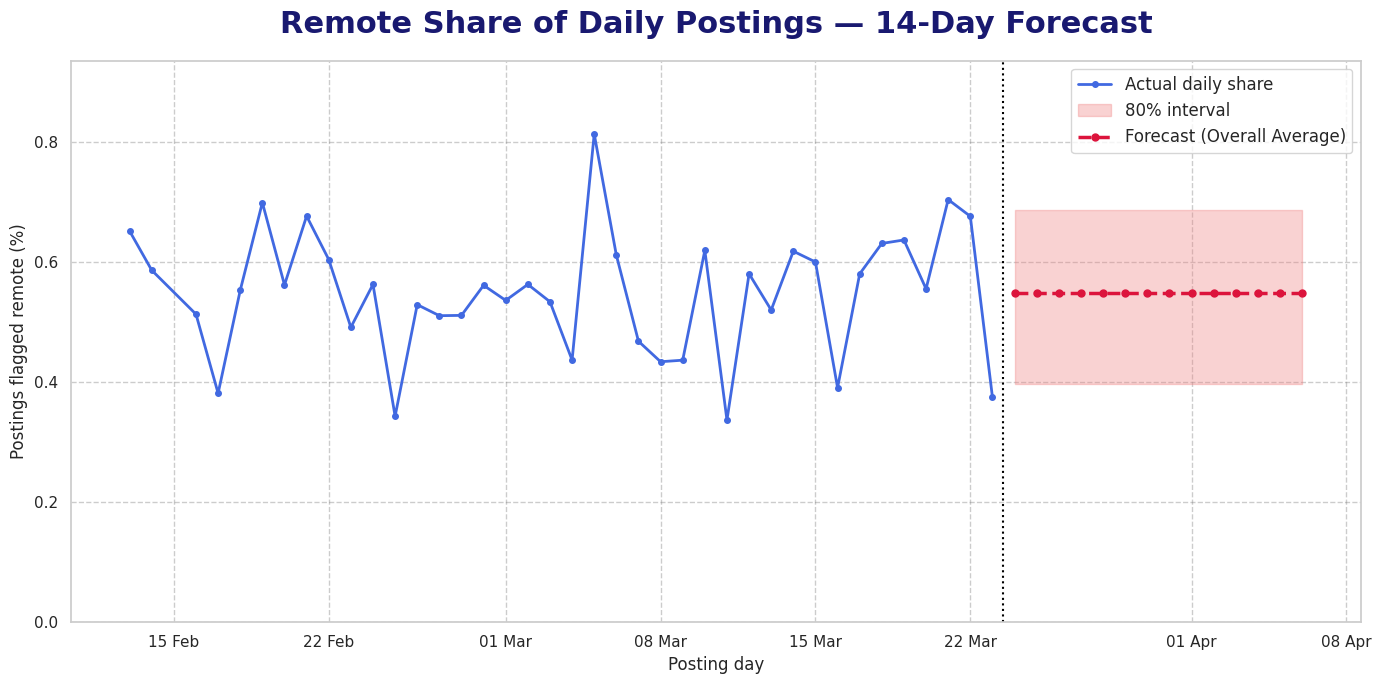

2026-11-23 16:56:10,696 - job_market_analysis - INFO - Remote share forecast made — method=Overall Average, level=0.55%


In [86]:
subsection_header("Task 7: Remote Work Forecasting — Remote Share Forecast")

best_remote_forecaster = REMOTE_FORECASTERS[remote_best]
extended = remote_values.copy()
for week in range(2):
    start = len(extended)
    extended = np.concatenate([extended, np.clip(best_remote_forecaster(extended, np.arange(start), np.arange(start, start + HORIZON)), 0, None)])
remote_forecast = extended[len(remote_values):]
remote_future_days = pd.date_range(demand_panel.index[-1] + pd.Timedelta(days=1), periods=len(remote_forecast))

best_errors = remote_errors.loc[remote_errors["Model"] == remote_best]
low_shift, high_shift = np.percentile(best_errors["Actual"] - best_errors["Predicted"], [10, 90])
band_low, band_high = np.clip(remote_forecast + low_shift, 0, None), remote_forecast + high_shift

fig, ax = plt.subplots(figsize=(14, 7))
ax.plot(remote_share_daily.index, remote_share_daily, color="royalblue", linewidth=2, marker="o", markersize=4, label="Actual daily share")
ax.fill_between(remote_future_days, band_low, band_high, color="lightcoral", alpha=0.35, label="80% interval")
ax.plot(remote_future_days, remote_forecast, color="crimson", linewidth=2.5, linestyle="--", marker="o", markersize=5, label=f"Forecast ({remote_best})")
ax.axvline(remote_share_daily.index[-1] + pd.Timedelta(hours=12), color="black", linestyle=":", linewidth=1.5)
ax.set_ylim(0, max(remote_share_daily.max(), band_high.max()) * 1.15)
ax.set_title("Remote Share of Daily Postings — 14-Day Forecast", fontsize=22, color=PLOT_COLOR, fontweight="bold", pad=20)
ax.set_xlabel("Posting day")
ax.set_ylabel("Postings flagged remote (%)")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b"))
ax.legend(fontsize=12)
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("Assets/task7_forecasting_remote_share.png", dpi=150, bbox_inches="tight")
plt.show()

info_box(f"Forecast level: {remote_forecast.mean():.2f}% of postings (80% interval {band_low.mean():.2f}% to {band_high.mean():.2f}% on a typical day). The interval is built from {len(best_errors)} test days, so it is rough. "
         "The earlier trend test found no significant shift, so a flat forecast is expected.")
logger.info(f"Remote share forecast made — method={remote_best}, level={remote_forecast.mean():.2f}%")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Remote Share Forecast:**

- **A flat forecast of about 0.55%:** the remote share of postings is expected to stay at its recent level for the next 14 days, with an 80% interval of about 0.40% to 0.69% on a typical day.
- **The history explains why:** daily shares swing between about 0.34% and 0.81%, with no upward or downward drift, and the earlier test found no significant change between the two halves of the window.
- **The interval is rough:** it is built from 21 test days, so it shows the typical spread and not a guarantee.
- **What this means:** remote work stays a very small part of titles, about one posting in 180, over the next two weeks. A change in this share would need a shift that the 39 days of data have not shown, and the scenario section tests how much it could move.

</div>

<hr style="width:60%; margin:auto;">

In [87]:
high_demand_roles = ", ".join(high_demand.loc[high_demand["Demand Level"] == "High demand", "Category"])
display(HTML(f"""
<div style="text-align:center;margin-top:40px;margin-bottom:30px;">
    <h3 style="color:{SUCCESS_TEXT};"><b>✅ Checkpoint: Time Series Forecasting Complete</b></h3>
    <p style="font-style:italic;font-size:1.05em;opacity:0.85;">
        Daily demand was forecast with six methods on rolling 7-day windows; best: <b>{forecast_best}</b> (WAPE <b>{forecast_comparison.loc[forecast_best, 'WAPE (%)']:.2f}%</b> against <b>{baseline_wape:.2f}%</b> for the baseline).
        High-demand roles for the next {FORECAST_DAYS} days: <b>{high_demand_roles}</b>.
        Remote share: best method <b>{remote_best}</b>, forecast level <b>{remote_forecast.mean():.2f}%</b>.<br>
        Scenario analysis ahead: how far these forecasts could move if current trends continue.
    </p>
    <hr style="width:45%;">
</div>"""))

## 09. Scenario Analysis

<div style="margin-left: 20px; max-width: 90%">

### 📌 Task 8: Scenario Analysis — Demand Scenarios

<div style="margin-left: 20px; max-width: 90%">

A forecast gives one expected path; a scenario asks what if. Four views of the next 14 days are built for every job category from what the data already showed. Low and High are the 10th and 90th percentile of simulated futures. Steady is the Holt-Winters forecast. Trend Continues takes the categories whose share rose or fell significantly in the trend test and lets them keep changing at the same pace, while categories without a significant trend stay at their Steady value. Total posting volume is assumed flat, as the weekly summary showed. The scenarios are ranges to plan with and are not probabilities.

</div>
</div>

In [88]:
section_header("Scenario Analysis")
subsection_header("Task 8: Scenario Analysis — Demand Scenarios")

half_days = len(remote_days) // 2                                   # days between the middle of the first and second half of the window
days_ahead = np.arange(1, FORECAST_DAYS + 1)
trend_lookup = category_trend.set_index("Name")

scenario_rows = []
for category in demand_panel.columns:
    steady = demand_forecast[category]["forecast"].to_numpy()
    relative_change = trend_lookup.loc[category, "Relative Change (%)"] / 100 if trend_lookup.loc[category, "Trend"] != "Stable" else 0.0
    continuing = steady * (1 + relative_change) ** (days_ahead / half_days)
    scenario_rows.append({"Category": category, "Last 7 Days (avg/day)": demand_panel[category].iloc[-7:].mean(), "Low (avg/day)": average_interval[category][0],
                          "Steady (avg/day)": steady.mean(), "Trend Continues (avg/day)": continuing.mean(), "High (avg/day)": average_interval[category][1],
                          "Task 2 Trend": trend_lookup.loc[category, "Trend"]})
scenario_table = pd.DataFrame(scenario_rows).sort_values("Steady (avg/day)", ascending=False).reset_index(drop=True)
scenario_table["Trend Effect (%)"] = (scenario_table["Trend Continues (avg/day)"] / scenario_table["Steady (avg/day)"] - 1) * 100
centered_table(scenario_table, float_format="{:,.1f}")

moving = scenario_table.loc[scenario_table["Task 2 Trend"] != "Stable", "Category"].tolist()
info_box(f"Averages per day over the next {FORECAST_DAYS} days. Trend Continues applies the half-against-half change from the category trend test over {half_days} days to {', '.join(moving) or 'no category'}; all other categories equal Steady. "
         "Low and High come from 500 simulated futures per category.")
logger.info(f"Demand scenarios built for {len(scenario_table)} categories; trending: {moving}")

Category,Last 7 Days (avg/day),Low (avg/day),Steady (avg/day),Trend Continues (avg/day),High (avg/day),Task 2 Trend,Trend Effect (%)
Web & Software Development,"1,676.9","1,671.6","1,697.2","1,697.2","1,724.6",Stable,0.0
Marketing & Sales,893.0,896.1,913.5,931.6,932.1,Rising,2.0
Design & Creative,787.6,790.3,804.0,804.0,818.7,Stable,0.0
Video & Audio,667.9,608.8,665.7,665.7,730.3,Stable,0.0
Writing & Translation,489.1,335.0,482.7,450.2,647.0,Falling,-6.7
Admin & Virtual Assistance,316.6,228.1,306.2,306.2,391.8,Stable,0.0
"Data, AI & Analytics",277.7,281.2,288.5,288.5,296.4,Stable,0.0
Finance & Accounting,118.0,107.4,117.1,117.1,126.7,Stable,0.0
Engineering & Architecture,80.1,79.9,83.5,83.5,87.3,Stable,0.0
Legal & Consulting,75.4,68.8,72.1,72.1,75.7,Stable,0.0


2026-11-23 16:56:10,763 - job_market_analysis - INFO - Demand scenarios built for 14 categories; trending: ['Marketing & Sales', 'Writing & Translation']


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Demand Scenarios:**

- **Only two categories change under Trend Continues:** Marketing & Sales rises 2.0% (913.5 to 931.6 postings a day), which lands almost exactly on the top of its range (932.1), and Writing & Translation falls 6.7% (482.7 to 450.2), still inside its wide range of 335 to 647.
- **Ranges differ widely in width:** Web & Software Development stays within about ±1.6% of its forecast and Data, AI & Analytics within about ±2.6%, while Writing & Translation ranges from −31% to +34% and Admin & Virtual Assistance from −26% to +28%.
- **The top four roles are secure:** Web, Marketing, Design and Video & Audio have ranges that do not reach the role above or below them, so their order holds in every scenario shown, except that Video & Audio and Writing & Translation overlap slightly (609 to 647).
- **Fifth place is the only open one:** the highest Admin & Virtual Assistance scenario (392) is above the lowest Writing & Translation scenario (335), so Admin could take fifth place only if Writing sits at the bottom of its range and Admin at the top of its own.
- **Writing & Translation is likely overstated:** part of its earlier fall came from a high mid-February week, so Trend Continues is the harshest reasonable view of that role, not the likeliest.
- **Scenarios are planning ranges:** they show how far demand could move, not how likely each outcome is.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 8: Scenario Analysis — Scenario Ranges

<div style="margin-left: 20px; max-width: 90%">

The demand scenarios are shown on one scale so categories of very different size can be compared. Each bar spans the Low to High range as a percentage difference from the Steady forecast, with the last 7 days and the Trend Continues scenario marked on it.

</div>

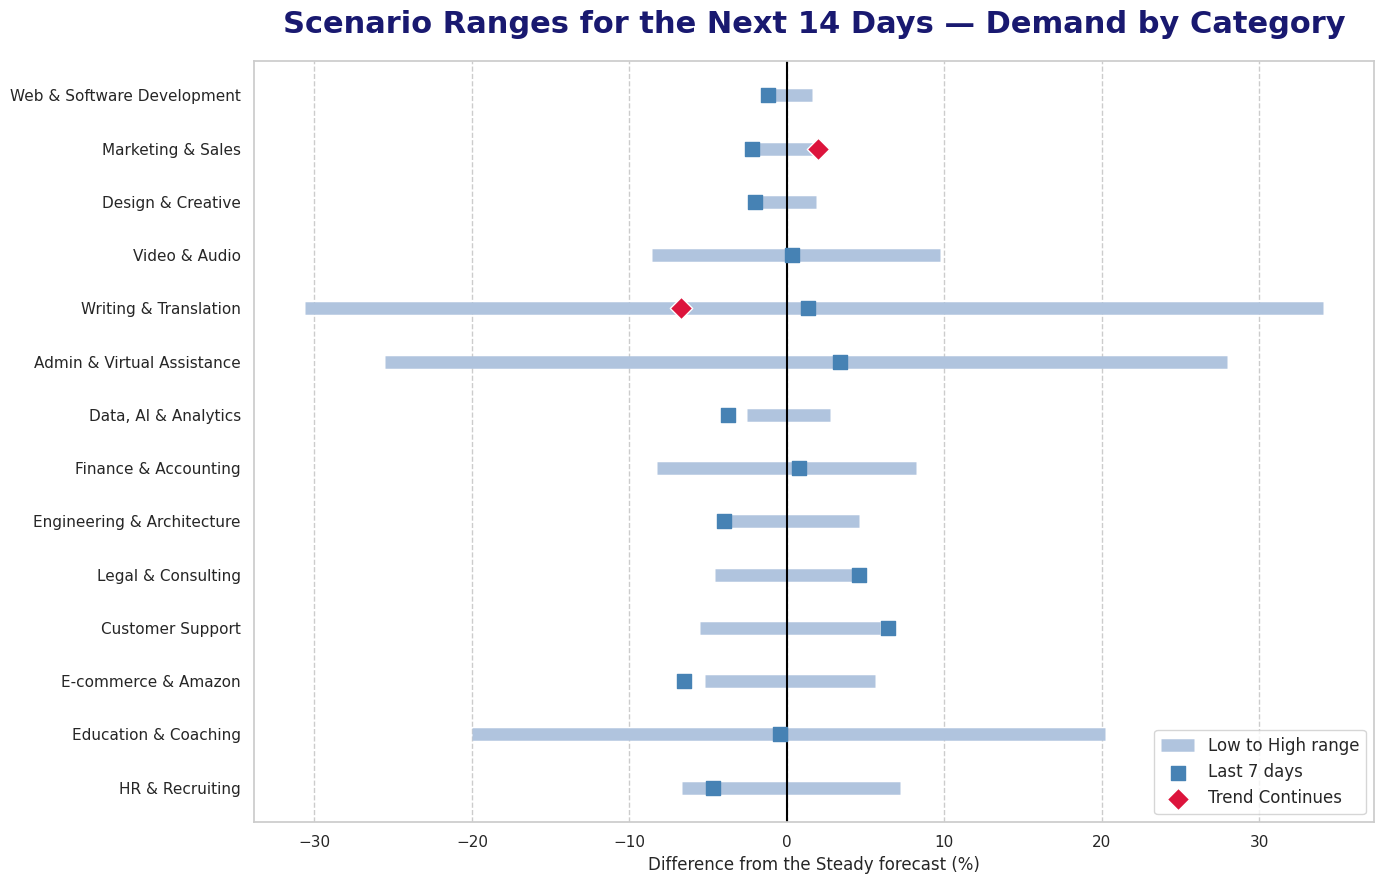

2026-11-23 16:56:11,417 - job_market_analysis - INFO - Scenario ranges plotted for demand


In [89]:
subsection_header("Task 8: Scenario Analysis — Scenario Ranges")

def difference_from_steady(column):
    return (scenario_table[column] / scenario_table["Steady (avg/day)"] - 1) * 100

range_view = pd.DataFrame({"Category": scenario_table["Category"], "Low": difference_from_steady("Low (avg/day)"), "High": difference_from_steady("High (avg/day)"),
                           "Last Week": difference_from_steady("Last 7 Days (avg/day)"), "Trend Continues": difference_from_steady("Trend Continues (avg/day)")}).iloc[::-1].reset_index(drop=True)

fig, range_ax = plt.subplots(figsize=(14, 9))
range_ax.set_title("Scenario Ranges for the Next 14 Days — Demand by Category", fontsize=22, color=PLOT_COLOR, fontweight="bold", pad=20)

range_ax.hlines(range_view.index, range_view["Low"], range_view["High"], color="lightsteelblue", linewidth=9, zorder=1, label="Low to High range")
range_ax.axvline(0, color="black", linewidth=1.5, zorder=2)
range_ax.scatter(range_view["Last Week"], range_view.index, marker="s", s=90, color="steelblue", zorder=3, label="Last 7 days")
trending = range_view[range_view["Trend Continues"].abs() > 0]
range_ax.scatter(trending["Trend Continues"], trending.index, marker="D", s=130, color="crimson", edgecolor="white", zorder=4, label="Trend Continues")
range_ax.set_yticks(range_view.index)
range_ax.set_yticklabels(range_view["Category"])
range_ax.set_xlabel("Difference from the Steady forecast (%)")
range_ax.legend(fontsize=12, loc="lower right")
range_ax.grid(axis="x", linestyle="--", alpha=0.4)
range_ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.savefig("Assets/task8_scenarios_ranges.png", dpi=150, bbox_inches="tight")
plt.show()

info_box("The black line is the Steady forecast. A square to the left of the bar means the last week was below the forecast range; a bar that does not reach the square means the range is tight against recent demand. ")
logger.info("Scenario ranges plotted for demand")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Scenario Ranges:**

- **Widths differ a lot:** Web & Software Development, Marketing & Sales and Design & Creative stay within about ±2% of their forecast, while Writing & Translation ranges from −31% to +34%, Admin & Virtual Assistance from −26% to +28% and Education & Coaching from −20% to +20%.
- **Trend Continues moves only two roles:** Marketing & Sales rises to the top of its range, and Writing & Translation falls to −6.7%, well inside its wide range.
- **The last week sits outside the range for four roles:** Marketing & Sales, Data, AI & Analytics, E-commerce & Amazon and Customer Support were slightly below or above their own range last week, so for these the range is tight against recent demand and likely too narrow.
- **Small roles are not riskier than large ones:** the narrowest and widest ranges are mixed across sizes, so width depends on how steady each role's daily postings are and not on its volume.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 8: Scenario Analysis — Scenario Summary

<div style="margin-left: 20px; max-width: 90%">

The four views are brought together as the scenario report: what each one assumes and what it means for demand and for the remote share. These are planning views for job seekers and recruiters, not predictions with probabilities.

</div>

In [90]:
subsection_header("Task 8: Scenario Analysis — Scenario Summary")

scenario_index = scenario_table.set_index("Category")
relative_low = scenario_index["Low (avg/day)"] / scenario_index["Steady (avg/day)"] - 1
relative_high = scenario_index["High (avg/day)"] / scenario_index["Steady (avg/day)"] - 1
moving_rows = scenario_table[scenario_table["Task 2 Trend"] != "Stable"]
remote_low, remote_high = period_summary["Remote Share (%)"].min(), period_summary["Remote Share (%)"].max()

scenario_summary = pd.DataFrame([
    {"Scenario": "Steady Market", "What It Assumes": "Recent levels and the weekly rhythm continue",
     "Demand Outcome": f"Largest roles: {', '.join(scenario_table['Category'].head(3))}", "Remote Share": f"{remote_forecast.mean():.2f}%"},
    {"Scenario": "Trend Continues", "What It Assumes": "Categories with a significant trend keep changing at the same pace",
     "Demand Outcome": ", ".join(f"{row['Category']} {row['Trend Effect (%)']:+.1f}%" for _, row in moving_rows.iterrows()) or "no category has a significant trend",
     "Remote Share": f"{remote_forecast.mean():.2f}% (no significant trend to extend)"},
    {"Scenario": "Downside Range", "What It Assumes": "Demand lands at the 10th percentile of simulated futures",
     "Demand Outcome": f"Largest fall: {relative_low.idxmin()} ({relative_low.min() * 100:+.1f}%)", "Remote Share": f"{remote_low:.2f}% (lowest week)"},
    {"Scenario": "Upside Range", "What It Assumes": "Demand lands at the 90th percentile of simulated futures",
     "Demand Outcome": f"Largest rise: {relative_high.idxmax()} ({relative_high.max() * 100:+.1f}%)", "Remote Share": f"{remote_high:.2f}% (highest week)"}])
centered_table(scenario_summary, float_format="{:,.2f}")

info_box("Each row is a planning view against the Steady forecast. Demand outcomes are changes for the next 14 days; the remote share range is the lowest and highest weekly share seen so far.")
logger.info("Scenario summary built — 4 scenarios")

Scenario,What It Assumes,Demand Outcome,Remote Share
Steady Market,Recent levels and the weekly rhythm continue,"Largest roles: Web & Software Development, Marketing & Sales, Design & Creative",0.55%
Trend Continues,Categories with a significant trend keep changing at the same pace,"Marketing & Sales +2.0%, Writing & Translation -6.7%",0.55% (no significant trend to extend)
Downside Range,Demand lands at the 10th percentile of simulated futures,Largest fall: Writing & Translation (-30.6%),0.52% (lowest week)
Upside Range,Demand lands at the 90th percentile of simulated futures,Largest rise: Writing & Translation (+34.0%),0.61% (highest week)


2026-11-23 16:56:11,449 - job_market_analysis - INFO - Scenario summary built — 4 scenarios


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Scenario Summary:**

- **The largest roles do not change:** in every scenario Web & Software Development, Marketing & Sales and Design & Creative stay the three biggest roles.
- **Trend Continues matters for two roles only:** Marketing & Sales gains 2.0% and Writing & Translation loses 6.7%. No other category had a significant trend to extend.
- **Writing & Translation carries the most risk in both directions:** it has both the largest fall (−30.6%) and the largest rise (+34.0%) of any role, so anyone targeting writing work faces the widest spread of outcomes.
- **Remote share barely moves in any scenario:** the lowest and highest weekly shares are 0.52% and 0.61%, less than 0.1 points apart, so remote work stays a very small part of titles whatever the scenario.
- **Use these as planning ranges:** each row shows how far the next two weeks could move, not how likely that is.

</div>

<hr style="width:60%; margin:auto;">

In [91]:
range_spread = relative_high - relative_low
display(HTML(f"""
<div style="text-align:center;margin-top:40px;margin-bottom:30px;">
    <h3 style="color:{SUCCESS_TEXT};"><b>✅ Checkpoint: Scenario Analysis Complete</b></h3>
    <p style="font-style:italic;font-size:1.05em;opacity:0.85;">
        <b>{len(scenario_summary)}</b> scenarios were built for the next {FORECAST_DAYS} days: steady, trend continues, downside and upside.
        Roles with a significant trend: <b>{', '.join(moving_rows['Category']) or 'none'}</b>; widest uncertainty: <b>{range_spread.idxmax()}</b> ({relative_low[range_spread.idxmax()] * 100:+.1f}% to {relative_high[range_spread.idxmax()] * 100:+.1f}%).
        Remote share range: <b>{remote_low:.2f}% to {remote_high:.2f}%</b>.<br>
        Recommendation engine ahead: matching a job seeker to current postings, filtered by country.
    </p>
    <hr style="width:45%;">
</div>"""))

## 10. Recommendation Engine

<div style="margin-left: 20px; max-width: 90%">

### 📌 Task 5: Recommendation Engine — Current Postings Index

<div style="margin-left: 20px; max-width: 90%">

The recommender searches current postings, defined as the most recent 14 full days. Postings that repeat the same title, country and contract type are merged into one listing, with the number of repeats kept, so a list of recommendations is not ten copies of the same title. Each listing keeps its category, remote flag, stated pay and link, so the results can show them.

</div>
</div>

In [92]:
section_header("Recommendation Engine")
subsection_header("Task 5: Recommendation Engine — Current Postings Index")

CURRENT_DAYS = 14
latest_day = window_postings["posted_day"].max()
current_postings = window_postings[(window_postings["posted_day"] > latest_day - pd.Timedelta(days=CURRENT_DAYS)) & (window_postings["title_clean"].fillna("").str.len() > 0)].copy()
current_postings["pay"] = np.where((current_postings["worker_type"] == "Freelancer") & (current_postings["pay_status"] == "Stated"), current_postings["hourly_rate_mid"],
                          np.where((current_postings["worker_type"] == "Permanent") & (current_postings["budget"] > 0), current_postings["budget"], np.nan))
listing_key = ["title_clean", "country", "worker_type"]
current_postings["similar_postings"] = current_postings.groupby(listing_key)["title_clean"].transform("size")
index_postings = (current_postings.sort_values("posted_day", ascending=False).drop_duplicates(listing_key)
                  [["title", "title_clean", "country", "worker_type", "job_category", "remote_posting", "pay", "link", "posted_day", "similar_postings"]].reset_index(drop=True))

by_contract = index_postings.groupby("worker_type")
index_summary = pd.DataFrame({"Current Postings": current_postings.groupby("worker_type").size(), "Unique Listings": by_contract.size(),
                              "Countries": by_contract["country"].nunique(), "Listings With Stated Pay (%)": by_contract["pay"].apply(lambda values: values.notna().mean() * 100)})
index_summary.loc["All"] = [len(current_postings), len(index_postings), index_postings["country"].nunique(), index_postings["pay"].notna().mean() * 100]
for column in ["Current Postings", "Unique Listings", "Countries"]:
    index_summary[column] = index_summary[column].map("{:,.0f}".format)
centered_table(index_summary.reset_index().rename(columns={"worker_type": "Contract Type"}), float_format="{:,.1f}")

info_box(f"Current postings: {latest_day - pd.Timedelta(days=CURRENT_DAYS - 1):%d %b} to {latest_day:%d %b %Y}. Pay is shown only when it was stated: an hourly rate for Freelancer listings and a salary for Permanent listings, never mixed.")
logger.info(f"Recommendation index built — {len(index_postings):,} listings from {len(current_postings):,} postings")

Contract Type,Current Postings,Unique Listings,Countries,Listings With Stated Pay (%)
Freelancer,"48,655","44,749",176,69.0
Permanent,"36,980","33,724",175,100.0
All,"85,635","78,473",191,82.3


2026-11-23 16:56:12,044 - job_market_analysis - INFO - Recommendation index built — 78,473 listings from 85,635 postings


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Current Postings Index:**

- **The index is large:** 85,635 postings from the last 14 days (10 to 23 March 2024) become 78,473 unique listings, so the recommender searches a pool of about 78 thousand titles.
- **Merging removes about 8% of postings:** 7,162 postings repeated a title, country and contract type that was already listed. The share is similar for Freelancer (8.0%) and Permanent (8.8%), so repeats are not concentrated in one contract type.
- **Coverage is wide:** 176 countries have Freelancer listings and 175 have Permanent ones, 191 in total. Small countries will have few listings, which is why the retriever test below uses only countries with at least 20.
- **Every Permanent listing shows a salary:** 100.0% of Permanent listings state one, as they must, since the salary is the posting's budget.
- **Freelancer pay is shown for about seven in ten:** 69.0% of Freelancer listings state an hourly rate, and the rest will appear without pay. This brings the overall share to 82.3%.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 5: Recommendation Engine — Retriever Comparison

<div style="margin-left: 20px; max-width: 90%">

A retriever turns the job seeker's text and every listing title into numbers and ranks listings by cosine similarity. Two kinds are compared: Word TF-IDF, which matches words and word pairs, and Character TF-IDF, which matches runs of 3 to 5 letters and so tolerates spelling variants and word forms. A third averages the two. There are no true answers to check against, so each retriever is tested on self-retrieval: 2,000 listings are picked, one random word is deleted from each title, and the retriever must still find the original among its top 10 within the same country, as the app will do. Recall@10 is the share found in the top 10, MRR is the average of 1 divided by the rank of the original (1 if it is first, 0.5 if second), and Category Match@10 is the share of the other top 10 results that belong to the same job category.

</div>

In [93]:
subsection_header("Task 5: Recommendation Engine — Retriever Comparison")

TOP_N, EVAL_QUERIES, BATCH = 10, 2000, 250
index_titles = index_postings["title_clean"].to_numpy()
country_codes = pd.factorize(index_postings["country"])[0]
category_codes = pd.factorize(index_postings["job_category"])[0]

fitted_vectorizers = {"Word TF-IDF": TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, stop_words=list(ENGLISH_STOP_WORDS)),
                      "Character TF-IDF": TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, sublinear_tf=True)}
retriever_matrices = {name: vectorizer.fit_transform(index_titles) for name, vectorizer in fitted_vectorizers.items()}
RETRIEVERS = {"Word TF-IDF": ["Word TF-IDF"], "Character TF-IDF": ["Character TF-IDF"], "Word + Character": ["Word TF-IDF", "Character TF-IDF"]}

eval_rng = np.random.default_rng(42)
country_sizes = index_postings["country"].map(index_postings["country"].value_counts()).to_numpy()
eligible = np.flatnonzero((pd.Series(index_titles).str.split().str.len().to_numpy() >= 3) & (country_sizes >= 20))          # enough words to drop one, enough listings in the country
sample = eval_rng.choice(eligible, size=min(EVAL_QUERIES, len(eligible)), replace=False)

def drop_one_word(title):
    words = title.split()
    drop = eval_rng.integers(len(words))
    return " ".join(words[:drop] + words[drop + 1:])

queries = [drop_one_word(index_titles[position]) for position in sample]
query_matrices = {name: vectorizer.transform(queries) for name, vectorizer in fitted_vectorizers.items()}

evaluation_rows = []
for retriever_name, parts in RETRIEVERS.items():
    ranks, category_matches = [], []
    for start in range(0, len(sample), BATCH):
        batch = slice(start, start + BATCH)
        source = sample[batch]
        scores = sum((query_matrices[part][batch] @ retriever_matrices[part].T).toarray() for part in parts) / len(parts)
        scores[country_codes[None, :] != country_codes[source][:, None]] = -1                       # same-country filter, as in the app
        batch_rows = np.arange(len(source))
        own_score = scores[batch_rows, source]
        ranks.append((scores > own_score[:, None]).sum(axis=1) + 1)
        scores[batch_rows, source] = -1                                                             # leave the original out when judging the other results
        top = np.argpartition(-scores, TOP_N, axis=1)[:, :TOP_N]
        category_matches.append((category_codes[top] == category_codes[source][:, None]).mean(axis=1))
    ranks = np.concatenate(ranks)
    evaluation_rows.append({"Retriever": retriever_name, "Recall@10": (ranks <= TOP_N).mean(), "MRR": (1 / ranks).mean(), "Category Match@10": np.concatenate(category_matches).mean()})

retriever_comparison = pd.DataFrame(evaluation_rows)
retriever_best = retriever_comparison.loc[retriever_comparison["MRR"].idxmax(), "Retriever"]
centered_table(retriever_comparison, float_format="{:,.3f}")

info_box(f"{len(sample):,} test listings from countries with at least 20 listings; the top {TOP_N} results are drawn from the same country. Highest MRR: {retriever_best}.")
logger.info(f"Retrievers compared — best by MRR: {retriever_best}")

Retriever,Recall@10,MRR,Category Match@10
Word TF-IDF,0.987,0.934,0.537
Character TF-IDF,0.990,0.947,0.543
Word + Character,0.993,0.953,0.556


2026-11-23 16:56:47,256 - job_market_analysis - INFO - Retrievers compared — best by MRR: Word + Character


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Retriever Comparison:**

- **All three find almost every listing:** Recall@10 is between 0.987 and 0.993, so the original is in the top 10 for 1,974 to 1,986 of 2,000 tests. The gap between best and worst is only 12 listings.
- **Word + Character ranks the original highest:** its MRR is 0.953 against 0.934 for Word TF-IDF and 0.947 for Character TF-IDF, so in most tests the original is the first result.
- **Character matching beats word matching alone:** Character TF-IDF is better than Word TF-IDF on all three measures (MRR 0.947 against 0.934). Matching letter runs copes with spelling variants and word forms that whole-word matching misses.
- **Combining the two is best on every measure:** Word + Character leads Recall@10 (0.993), MRR (0.953) and Category Match@10 (0.556), so it is the retriever used in the function that follows.
- **Category match is the lower and more telling number:** only 0.537 to 0.556 of the other results share the original's category, about 5 or 6 in 10. Titles are short and categories are broad, so many close matches belong to a neighbouring category, and the recommender should be read as a title matcher, not a category classifier.
- **The test is easier than real use:** the search text is a near copy of a listing title, so Recall and MRR are close to their ceiling. They show that the retrievers work, not how well they handle a job seeker's free wording.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 5: Recommendation Engine — Recommendation Function

<div style="margin-left: 20px; max-width: 90%">

The recommender is one function, `recommend()`. It takes the job seeker's text, a country and, optionally, a contract type, and returns the best-matching current listings. Only listings from the chosen country are searched, so a job seeker never sees listings from other countries. The fitted vectorizers, their listing matrices and the listing table are kept together in one dictionary, so the same function runs here and in the Streamlit app once that dictionary is saved. Each result shows its title, job category, contract type, remote flag, stated pay, number of similar postings, match score and link.

</div>

In [94]:
subsection_header("Task 5: Recommendation Engine — Recommendation Function")

RESULT_COLUMNS = ["Rank", "Title", "Job Category", "Contract Type", "Country", "Remote", "Pay Type", "Pay (units)", "Similar Postings", "Match (%)", "Link"]
recommender = {"retriever": retriever_best, "parts": RETRIEVERS[retriever_best],
               "vectorizers": {part: fitted_vectorizers[part] for part in RETRIEVERS[retriever_best]},
               "matrices": {part: retriever_matrices[part] for part in RETRIEVERS[retriever_best]},
               "listings": index_postings}

def recommend(query, country, contract_type=None, top_n=5, model=recommender):
    """Best-matching current listings for a job seeker's text, from one country and, optionally, one contract type."""
    listings = model["listings"]
    allowed = (listings["country"] == country).to_numpy()
    if contract_type:
        allowed = allowed & (listings["worker_type"] == contract_type).to_numpy()
    candidates = np.flatnonzero(allowed)
    if len(candidates) == 0 or not query.strip():
        return pd.DataFrame(columns=RESULT_COLUMNS)

    scores = sum((model["vectorizers"][part].transform([query]) @ model["matrices"][part][candidates].T).toarray()[0] for part in model["parts"]) / len(model["parts"])
    # TF-IDF vectors have unit length, so this dot product is the cosine similarity
    order = np.argsort(-scores)[:top_n]
    order = order[scores[order] > 0]                                                  # drop listings with nothing in common with the text
    found = listings.iloc[candidates[order]]
    return pd.DataFrame({"Rank": np.arange(1, len(found) + 1), "Title": found["title"].to_numpy(), "Job Category": found["job_category"].to_numpy(),
                         "Contract Type": found["worker_type"].to_numpy(), "Country": found["country"].to_numpy(), "Remote": np.where(found["remote_posting"], "Yes", "No"),
                         "Pay Type": np.where(found["worker_type"] == "Freelancer", "Hourly rate", "Salary"), "Pay (units)": found["pay"].to_numpy(),
                         "Similar Postings": found["similar_postings"].to_numpy(),"Match (%)": scores[order] * 100, "Link": found["link"].to_numpy()})

info_box(f"recommend(query, country, contract_type=None, top_n=5) uses the {recommender['retriever']} retriever over {len(index_postings):,} listings. "
         "It returns an empty table when the country or contract type has no listings or the text matches nothing.")
logger.info(f"Recommendation function ready — retriever={recommender['retriever']}, listings={len(index_postings):,}")

2026-11-23 16:56:47,293 - job_market_analysis - INFO - Recommendation function ready — retriever=Word + Character, listings=78,473


### 📌 Task 5: Recommendation Engine — Example Recommendations

<div style="margin-left: 20px; max-width: 90%">

To check that the function behaves as a job seeker would expect, it is called with a short piece of text, deliberately misspelt, for the country with the most current listings. The table shows the ten best matches with their category, contract type, remote flag, stated pay and match score. The links are left out here because they are long, and the app shows them.

</div>

In [95]:
subsection_header("Task 5: Recommendation Engine — Example Recommendations")

DEMO_QUERY = "wordpres website developer"
demo_country = index_postings["country"].value_counts().index[0]
demo_results = recommend(DEMO_QUERY, demo_country, top_n=10)

demo_view = demo_results.drop(columns=["Link", "Country"])
demo_view["Pay (units)"] = demo_view["Pay (units)"].map(lambda value: "Not stated" if pd.isna(value) else f"{value:,.2f}")
centered_table(demo_view, float_format="{:,.1f}")

info_box(f"Search text: \"{DEMO_QUERY}\" in {demo_country}, all contract types. Pay is an hourly rate for Freelancer listings and a salary for Permanent listings.")
logger.info(f"Example recommendations shown — country={demo_country}, results={len(demo_results)}")

Rank,Title,Job Category,Contract Type,Remote,Pay Type,Pay (units),Similar Postings,Match (%)
1,Website developer,Web & Software Development,Freelancer,No,Hourly rate,Not stated,10,87.4
2,Website developer and,Web & Software Development,Freelancer,No,Hourly rate,20.00,1,85.7
3,Wordpress website Developer,Web & Software Development,Permanent,No,Salary,250.00,1,83.3
4,Wordpress Website Developer,Web & Software Development,Freelancer,No,Hourly rate,40.00,1,83.3
5,Website Developer (WordPress),Web & Software Development,Freelancer,No,Hourly rate,11.00,1,78.6
6,Website developer for wordpress,Web & Software Development,Freelancer,No,Hourly rate,30.00,1,77.9
7,Web 3 Website Developer,Web & Software Development,Freelancer,No,Hourly rate,Not stated,2,77.8
8,website developer Needed,Web & Software Development,Freelancer,No,Hourly rate,Not stated,2,71.9
9,Expert Website Developer,Web & Software Development,Freelancer,No,Hourly rate,30.00,1,66.1
10,App and Website Developer,Web & Software Development,Freelancer,No,Hourly rate,Not stated,1,65.5


2026-11-23 16:56:47,459 - job_market_analysis - INFO - Example recommendations shown — country=United States, results=10


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Example Recommendations:**

- **The results are on topic:** all ten listings are Web & Software Development, and every title contains "website developer", so the recommender returned the right kind of work for the search.
- **A misspelling does not break it:** "wordpres" still brought in the four WordPress titles (ranks 3 to 6), because the character matching links it to "wordpress".
- **Exact words still score highest:** plain "Website developer" ranks first (87.4%) and the WordPress titles follow at 83.3% and below, since the typo costs a few points.
- **Scores fall steadily with rank:** from 87.4% to 65.5%. The lower results ("Expert Website Developer", "App and Website Developer") are looser matches, so the first five or so are the most useful.
- **Repeats are collapsed:** the first listing stands for 10 postings with the same title, and ranks 7 and 8 for 2 each, so the list shows ten different titles and not one title ten times.
- **Pay is missing for four of the ten:** their pay was not stated, so the app shows "Not stated" and never fills in a guess. The stated pay mixes hourly rates for Freelancer listings with a salary for the Permanent listing, which is why each result carries a pay type.
- **Titles are shown as posted:** "Website developer and" is a cut-off title, and the recommender cannot repair it.

</div>

<hr style="width:60%; margin:auto;">

In [96]:
display(HTML(f"""
<div style="text-align:center;margin-top:40px;margin-bottom:30px;">
    <h3 style="color:{SUCCESS_TEXT};"><b>✅ Checkpoint: Recommendation Engine Complete</b></h3>
    <p style="font-style:italic;font-size:1.05em;opacity:0.85;">
        <b>{len(index_postings):,}</b> unique current listings from <b>{index_postings['country'].nunique()}</b> countries were indexed.
        The <b>{retriever_best}</b> retriever was chosen: Recall@10 <b>{retriever_comparison.set_index('Retriever').loc[retriever_best, 'Recall@10']:.3f}</b>,
        MRR <b>{retriever_comparison.set_index('Retriever').loc[retriever_best, 'MRR']:.3f}</b>.
        <code>recommend()</code> returns the best matches for a text and country, with an optional contract type.<br>
        Saved outputs ahead: storing the recommender and dashboard tables so the Streamlit app can load them.
    </p>
    <hr style="width:45%;">
</div>"""))

## 11. Saved Outputs

<div style="margin-left: 20px; max-width: 90%">

### 📌 Task 6: Saved Outputs — Dashboard Tables

<div style="margin-left: 20px; max-width: 90%">

The Streamlit app does not repeat the analysis. It loads finished tables, so this cell gathers every table the dashboard shows into one bundle: pay by country, keyword pay, pay model results, category and theme trends, the period summary, demand forecasts, remote share results, scenarios and the retriever comparison. The table below lists what the bundle holds and which task each table serves.

</div>
</div>

In [97]:
section_header("Saved Outputs")
subsection_header("Task 6: Saved Outputs — Dashboard Tables")

remote_forecast_table = pd.DataFrame({"Date": remote_future_days, "Forecast (%)": remote_forecast, "Low (%)": band_low, "High (%)": band_high})
dashboard_tables = {
    "country_rates": country_rates.loc[(country_rates["Postings"] >= MIN_POSTINGS) & country_rates["iso3"].notna()],
    "keyword_pay": keyword_pay, "pay_model_comparison": comparison_table, "pay_importance": pay_importance,
    "category_trend": category_trend, "theme_trend": theme_trend, "theme_profile": theme_profile,
    "period_summary": period_summary, "latest_view": latest_view,
    "demand_panel": demand_panel, "demand_forecast": demand_forecast, "high_demand": high_demand, "forecast_comparison": forecast_comparison,
    "remote_trend": remote_trend, "remote_forecast": remote_forecast_table,
    "scenario_table": scenario_table, "scenario_summary": scenario_summary, "retriever_comparison": retriever_comparison}
TABLE_USES = {"country_rates": "Task 4 — average hourly rate map", "keyword_pay": "Task 1 — title keywords vs pay", "pay_model_comparison": "Task 1 — pay model results",
              "pay_importance": "Task 1 — what drives pay", "category_trend": "Task 2 — category share change", "theme_trend": "Task 2 — title theme growth",
              "theme_profile": "Task 2 — theme contents", "period_summary": "Task 6 — weekly or monthly metrics", "latest_view": "Task 6 — latest period vs history",
              "demand_panel": "Task 3 — daily demand by category", "demand_forecast": "Task 3 — 14-day demand forecast", "high_demand": "Task 3 — high-demand roles",
              "forecast_comparison": "Task 3 — forecasting model comparison", "remote_trend": "Task 7 — remote share trend",
              "remote_forecast": "Task 7 — remote share forecast", "scenario_table": "Task 8 — scenario values", "scenario_summary": "Task 8 — scenario summary",
              "retriever_comparison": "Task 5 — retriever comparison"}
dashboard_bundle = {"tables": dashboard_tables, "meta": {"data_through": str(window_postings["posted_day"].max().date()), "period": period_label,
                                                        "listings": len(index_postings), "retriever": retriever_best}}

bundle_overview = pd.DataFrame([{"Table": name, "Used For": TABLE_USES[name], "Rows": f"{len(table):,}", "Columns": table.shape[1]} for name, table in dashboard_tables.items()])
centered_table(bundle_overview)

info_box(f"{len(dashboard_tables)} tables built from postings up to {dashboard_bundle['meta']['data_through']}. The dashboard period is the {period_label.lower()}.")
logger.info(f"Dashboard bundle assembled — {len(dashboard_tables)} tables, data through {dashboard_bundle['meta']['data_through']}")

Table,Used For,Rows,Columns
country_rates,Task 4 — average hourly rate map,91,5
keyword_pay,Task 1 — title keywords vs pay,779,9
pay_model_comparison,Task 1 — pay model results,6,7
pay_importance,Task 1 — what drives pay,135,4
category_trend,Task 2 — category share change,15,8
theme_trend,Task 2 — title theme growth,20,8
theme_profile,Task 2 — theme contents,20,7
period_summary,Task 6 — weekly or monthly metrics,6,9
latest_view,Task 6 — latest period vs history,5,7
demand_panel,Task 3 — daily demand by category,39,14


2026-11-23 16:56:47,541 - job_market_analysis - INFO - Dashboard bundle assembled — 18 tables, data through 2024-03-23


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Dashboard Tables:**

- **Every task has its tables in the bundle:** 18 tables cover Tasks 1 to 8, so the app can show each task without recomputing anything.
- **The tables are small:** the largest, keyword pay, has 779 rows, and most have fewer than 40. The whole bundle is about 0.1 MB, so it loads instantly.
- **The forecast table is wide by design:** the demand forecast has 14 days and 42 columns, which is the forecast plus the low and high bounds for each of the 14 categories.
- **The data is current to one date:** the bundle covers postings up to 23 March 2024 with weekly periods, and this date is stored with the tables so the app can show how fresh the data is.

</div>

<hr style="width:60%; margin:auto;">

### 📌 Task 5: Saved Outputs — Recommender and Dashboard Files

<div style="margin-left: 20px; max-width: 90%">

The recommender and the dashboard bundle are saved as two `.pkl` files, each stamped with the save time. An existing file is kept and reused, so rerunning the notebook does not rebuild them, and Local, Drive and GitHub are searched in that order. When new postings arrive, set `REFRESH_SAVED_OUTPUTS` to True and rerun the notebook: both files are rebuilt from the new data and saved as newer files, and the app always loads the newest. The listing matrices are stored at half precision to keep the file small. Files in `Assets/models` are uploaded to GitHub by hand so the app can find them.

</div>

In [98]:
subsection_header("Task 5: Saved Outputs — Recommender and Dashboard Files")

REFRESH_SAVED_OUTPUTS = False          # True after loading newer postings: rebuilds and overwrites the saved files

saved_recommender = {**recommender, "matrices": {part: matrix.astype(np.float32) for part, matrix in recommender["matrices"].items()}}      # half the size, same results
SAVE_ITEMS = {"recommender": (saved_recommender, "Task 5 — vectorizers, listing matrices and listing table behind recommend()"),
              "dashboard_tables": (dashboard_bundle, "Tasks 1 to 8 — the tables the dashboard displays")}

def latest_saved_file(name):
    files = sorted(f for f in os.listdir(LOCAL_MODELS_DIR) if f.startswith(f"{name}_") and f.endswith(".pkl")) if os.path.isdir(LOCAL_MODELS_DIR) else []
    return os.path.join(LOCAL_MODELS_DIR, files[-1]) if files else None

saved_rows = []
for name, (item, contents) in SAVE_ITEMS.items():
    existing = None if REFRESH_SAVED_OUTPUTS else load_latest_model_artifact(name)
    if existing is None:
        save_model_artifact(item, name)
        status = "Saved"
    else:
        status = "Existing file kept"
    path = latest_saved_file(name)
    saved_rows.append({"File": os.path.basename(path) if path else "Not found locally", "Contents": contents, "Status": status,
                       "Size (MB)": os.path.getsize(path) / 1e6 if path else np.nan})
saved_files = pd.DataFrame(saved_rows)
centered_table(saved_files, float_format="{:,.1f}")

largest = saved_files["Size (MB)"].max()
info_box(f"Saved to {LOCAL_MODELS_DIR}/" + (f" and mirrored to Drive ({DRIVE_PATH})" if DRIVE_PATH else " only, because Drive is not mounted") + ". "
         + (f"The largest file is {largest:,.1f} MB, above GitHub's 100 MB limit, so it cannot be uploaded as it is." if largest > 100 else
            f"The largest file is {largest:,.1f} MB, within GitHub's 100 MB limit. Upload both files to Assets/models in the repository."))
logger.info(f"Saved outputs ready — {dict(zip(saved_files['File'], saved_files['Status']))}")

2026-11-23 16:56:47,927 - job_market_analysis - INFO - [recommender] Local folder not available: Assets/models
2026-11-23 16:56:47,928 - job_market_analysis - INFO - [recommender] Drive folder not available: /content/drive/MyDrive/NHIS_Project/Project 8/Assets/models
2026-11-23 16:56:48,191 - job_market_analysis - INFO - Found GitHub artifact: https://raw.githubusercontent.com/S-Yousuf-S/NHIS_Project8/main/Assets/models/recommender_20261122_181817.pkl
2026-11-23 16:56:50,191 - job_market_analysis - INFO - Cached GitHub artifact locally: Assets/models/recommender_20261122_181817.pkl
2026-11-23 16:56:51,042 - job_market_analysis - INFO - [dashboard_tables] Local folder reachable but holds no 'dashboard_tables_*.pkl'
2026-11-23 16:56:51,042 - job_market_analysis - INFO - [dashboard_tables] Drive folder not available: /content/drive/MyDrive/NHIS_Project/Project 8/Assets/models
2026-11-23 16:56:51,085 - job_market_analysis - INFO - Found GitHub artifact: https://raw.githubusercontent.com/S-

File,Contents,Status,Size (MB)
recommender_20261122_181817.pkl,"Task 5 — vectorizers, listing matrices and listing table behind recommend()",Existing file kept,82.6
dashboard_tables_20261122_181820.pkl,Tasks 1 to 8 — the tables the dashboard displays,Existing file kept,0.1


2026-11-23 16:56:51,319 - job_market_analysis - INFO - Saved outputs ready — {'recommender_20261122_181817.pkl': 'Existing file kept', 'dashboard_tables_20261122_181820.pkl': 'Existing file kept'}


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Saved Files:**

- **The recommender holds almost all the weight:** it is 82.6 MB against 0.1 MB for the dashboard tables, because it stores the word and character matrices for about 78 thousand listings.
- **The size is within GitHub's limit but needs care:** 82.6 MB is below the 100 MB limit but above the 50 MB warning level, so it must be pushed with git and not uploaded through the browser.
- **Both files are on this runtime only:** Drive was not mounted, so there is no backup copy yet and a runtime reset would remove them.
- **Warnings are first-run messages:** the missing folders and the GitHub 404 only mean no earlier file existed. They stop once the files are on Drive and in the repository.
- **Reruns reuse the files:** an existing file is kept, so the notebook does not rebuild them unless `REFRESH_SAVED_OUTPUTS` is set to True.

</div>

<hr style="width:60%; margin:auto;">

In [99]:
display(HTML(f"""
<div style="text-align:center;margin-top:40px;margin-bottom:30px;">
    <h3 style="color:{SUCCESS_TEXT};"><b>✅ Checkpoint: Saved Outputs Complete</b></h3>
    <p style="font-style:italic;font-size:1.05em;opacity:0.85;">
        <b>{len(dashboard_tables)}</b> dashboard tables and the recommender were saved as <b>{len(saved_files)}</b> files
        (<b>{saved_files['Size (MB)'].sum():,.1f} MB</b> in total), built from postings up to <b>{dashboard_bundle['meta']['data_through']}</b>.
        Setting <code>REFRESH_SAVED_OUTPUTS</code> to True and rerunning rebuilds them when new postings arrive.<br>
        Executive summary ahead: what the analysis found and where each task was answered.
    </p>
    <hr style="width:45%;">
</div>"""))

## 12. Summary

### 📊 Executive Summary — Job Market Analysis and Recommendation System

<div style="margin-left: 40px; max-width: 90%">

- **Data:** 244,827 Upwork postings after cleaning, 57.57% Freelancer and 42.43% Permanent. Hourly rates and salaries are analysed separately, pay is in units, and the trend and forecast work uses the 39 full days of the main collection window (mid-February to late March 2024).
- **Task 1 — Title keywords and pay:** 303 of 379 Freelancer words and 306 of 400 Permanent words differ significantly in pay, and the size of the gap matters more than the significance. "Lawyer" carries the largest hourly premium (+308.89%) and "ghostwriter" the largest salary premium (+650.00%), while "va" (−71.11%) and "science" (−95%) carry the largest discounts. Pay is hard to predict from titles: the best model, LightGBM, reaches a cross-validated R² of 0.178 for hourly rates and 0.111 for salaries, and job category is the leading driver in both, followed by client country.
- **Task 2 — Emerging categories:** Marketing & Sales is rising (14.05% to 14.77% of daily postings, q = 0.014) and Writing & Translation is falling (9.98% to 8.36%, q = 0.00074), while the other 13 categories are stable. Among 20 title themes, the video-editor and broad marketing themes are rising, and the translation, data-entry and writing themes are falling by about 18% each.
- **Task 3 — High-demand roles:** Holt-Winters is the best forecaster of daily demand (WAPE 5.36% against 5.62% for the seasonal baseline), and the GRU does not improve on it (6.33%). The five highest-demand roles for the next 14 days are Web & Software Development (about 1,697 postings a day), Marketing & Sales (914), Design & Creative (804), Video & Audio (666) and Writing & Translation (483).
- **Task 4 — Hourly rate by country:** Malaysia (42.77 units) and Thailand (42.01) pay the highest averages and South Korea (15.40) and Taiwan (15.97) the lowest, among 91 countries with enough stated postings. The United States, by far the largest market (46,620 postings), averages 31.55, and the link between market size and rate is weak (rank correlation 0.19).
- **Task 5 — Recommendation engine:** `recommend()` searches 78,473 unique current listings from 191 countries and always filters by country. The Word + Character TF-IDF retriever finds the original listing in the top 10 for 99.3% of test searches (MRR 0.953).
- **Task 6 — Market dynamics:** after the first week, postings stay between 6,144 and 6,506 a day and the contract mix stays between 56.5% and 58.5% Freelancer. Remote share (0.61%) is the only measure flagged in the latest week, and the same code switches from weeks to months once three calendar months are collected.
- **Task 7 — Remote work:** remote postings are 0.55% of titles with no significant trend (q = 0.9). Freelancer postings are about twice as likely to be remote as Permanent ones (about 0.7% against 0.3%), and the 14-day forecast is a flat 0.55% (80% interval 0.40% to 0.69%).
- **Task 8 — Future scenarios:** across steady, trend-continues, low and high views of the next 14 days, the three largest roles never change. Only Marketing & Sales (+2.0%) and Writing & Translation (−6.7%) move under Trend Continues, and Writing & Translation has the widest range (−30.6% to +34.0%). Remote share stays between 0.52% and 0.61% in every scenario.

</div>

<hr style="width:60%; margin:auto;">

In [100]:
display(HTML(f"""
<div style="text-align:center;margin-top:40px;margin-bottom:30px;">
    <h3 style="color:{SUCCESS_TEXT};"><b>✅ Checkpoint: Notebook Complete</b></h3>
    <p style="font-style:italic;font-size:1.05em;opacity:0.85;">
        <b>{len(df_refined):,}</b> postings were cleaned, explored, modelled and forecast for all eight project tasks.
        <b>{len(dashboard_tables)}</b> dashboard tables and the <b>{recommender['retriever']}</b> recommender are saved for the Streamlit app.<br>
        Streamlit app ahead: the dashboard and the job recommender, loading the saved files.
    </p>
    <hr style="width:45%;">
</div>"""))